# Stage 3 — U-Net temporal evolution from TFRecords

**Vamsi Gudipati**

The same U-Net as Stage 1, now asked to advance the field by one snapshot, u(t) → u(t + 1), trained by streaming the TFRecords of Stage 2 with `tf.data`. At one step it beats persistence (next field = current field), and I ran the notebook's five experiments (snapshot stride, network width, residual learning, longer rollouts, shuffle buffer and shard count), added a training animation and repeated every training with three seeds. The 30-step rollouts leave the data for every seed; Stage 4 measures why, against persistence and against the mean velocity profile.

Portfolio page: https://vamsigudipati.github.io/unet-turbulent-fields.html

In [1]:
# Where this notebook reads its data and writes its outputs (paths relative to notebooks/)
from pathlib import Path
STAGE = "03_unet_temporal_evolution"
DATA_DIR = Path("../release_assets")          # the planes from the first release, and the TFRecords Stage 2 writes
RESULTS_DIR = Path("../results") / STAGE
EXERCISES_DIR = RESULTS_DIR / "exercises"
MODELS_DIR = Path("../models") / STAGE
ANIM_DIR = Path("../animations")
ANIM_PREFIX = "03_"
for _d in (RESULTS_DIR, EXERCISES_DIR, MODELS_DIR, ANIM_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# U-Net for Turbulent Field Temporal Evolution (Streaming from TFRecords)

This notebook trains a U-Net to advance a turbulent field forward in time:

```text
u(y, x, t) -> U-Net -> u(y, x, t + dt)
```

It is the companion to **Stage 2 (Prepare Temporal Pairs as TFRecords)**, which must
be run first. This notebook does **not** load the dataset into memory: it streams
batches directly from the sharded TFRecord files produced by Stage 2 using
`tf.data`. This is slower per-sample than reading everything into RAM (as Stage 1
does), but it scales to databases far larger than available memory.

The U-Net architecture itself is **identical** to the one used in Stage 1: only the
meaning of the input and output changes. In Stage 1, input/output were coarse/fine
versions of the field at the *same* time. Here, input/output are the field at *two
different, consecutive* times.


In [2]:
# Device report: which devices this kernel sees
import tensorflow as tf, platform
print("TensorFlow", tf.__version__, "| Python", platform.python_version())
print("Physical devices:", tf.config.list_physical_devices())
print("GPU (Metal) visible:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow 2.18.1 | Python 3.12.14
Physical devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU (Metal) visible: True


# 1. Environment

Required packages:

```bash
pip install numpy tensorflow matplotlib pydot graphviz
```

This notebook expects the TFRecord shards and metadata produced by Stage 2 to
already exist on disk.


In [3]:
# =========================================================
# Import libraries
# =========================================================

from pathlib import Path
import json
import shutil

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

np.random.seed(0)
tf.random.set_seed(0)

print("TensorFlow version:", tf.__version__)
print("Current working directory:", Path.cwd())


TensorFlow version: 2.18.1
Current working directory: <repo>/notebooks


# 2. Optional: Google Colab Setup

As in Stage 1: mounts Google Drive if running in Colab, does nothing otherwise.


In [4]:
# =========================================================
# Check whether we are running in Google Colab
# =========================================================

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Running in Google Colab:", IN_COLAB)

if IN_COLAB:
    from google.colab import drive
    pass  # Google Drive is not mounted here: the data come from release_assets/ (see the data-path cell)
    print("Google Drive mounted.")
else:
    print("This is not Google Colab.")
    print("Current working directory:")
    print(Path.cwd())


Running in Google Colab: False
This is not Google Colab.
Current working directory:
<repo>/notebooks


# 3. Define Data Paths

We point to the `temporal_pairs_tfrecords/` directory produced by Stage 2. This
directory must already contain:

```text
train-*.tfrecord
val-*.tfrecord
temporal_dataset_metadata.json
temporal_normalization.npz
```


In [5]:
# =========================================================
# Define data paths (must match Stage 2)
# =========================================================

data_dir = DATA_DIR  # release_assets/, where Stage 2 writes the TFRecords

tfrecords_dir = data_dir / "temporal_pairs_tfrecords"

metadata_file = tfrecords_dir / "temporal_dataset_metadata.json"
normalization_file = tfrecords_dir / "temporal_normalization.npz"

print("TFRecords directory:")
print(tfrecords_dir)
print("Directory exists:", tfrecords_dir.exists())

if not tfrecords_dir.exists():
    raise FileNotFoundError(
        "TFRecords directory not found. Run Stage 2 first."
    )


TFRecords directory:
../release_assets/temporal_pairs_tfrecords
Directory exists: True


# 4. Load Dataset Metadata and Normalization Statistics

Everything needed to build the `tf.data` pipeline (padded field shape, number of
pairs, shard file patterns, normalization mean/std) was already computed once in
Stage 2 and saved to disk. We simply load it here instead of recomputing it.


In [6]:
# =========================================================
# Load dataset metadata and normalization statistics
# =========================================================

with open(metadata_file, "r") as f:
    dataset_metadata = json.load(f)

print("Dataset metadata:")
for key, value in dataset_metadata.items():
    print(f"{key}: {value}")

padded_height = dataset_metadata["padded_height"]
padded_width = dataset_metadata["padded_width"]
channels = dataset_metadata["channels"]

n_train_pairs = dataset_metadata["n_train_pairs"]
n_val_pairs = dataset_metadata["n_val_pairs"]

train_file_pattern = dataset_metadata["train_file_pattern"]
val_file_pattern = dataset_metadata["val_file_pattern"]

norm_data = np.load(normalization_file)
channel_mean = float(norm_data["channel_mean"])
channel_std = float(norm_data["channel_std"])

print("\nChannel mean (u):", channel_mean)
print("Channel std  (u):", channel_std)


Dataset metadata:
base_name: P125_83pi
padding_multiple: 16
snapshot_stride: 1
padded_height: 208
padded_width: 384
channels: 1
train_fraction: 0.85
n_train_pairs: 4810
n_val_pairs: 857
train_num_shards: 8
val_num_shards: 2
train_file_pattern: ../release_assets/temporal_pairs_tfrecords/train-*.tfrecord
val_file_pattern: ../release_assets/temporal_pairs_tfrecords/val-*.tfrecord

Channel mean (u): 0.7847065935393341
Channel std  (u): 0.34105365636854196


# 5. TFRecord Parsing and Normalization Pipeline

We define a lean parsing function with `height`/`width`/`channels` **baked in as
Python constants** (via a closure), so the resulting tensors have a fully static
shape that Keras can use to build the model. This is different from the parser used
in Stage 2's sanity check, which read the shape dynamically from each record and
also carried metadata (`snapshot_t`, `z_label`, ...) that we do not need at training
time.

Normalization is applied as a second `tf.data` mapping step, using the mean/std
computed in Stage 2 (training data only).


In [7]:
# =========================================================
# Lean TFRecord parser (shape baked in, no metadata)
# =========================================================

def make_parse_fn(height, width, channels=1):
    """
    Return a parsing function with height/width/channels baked in as Python
    constants, so tf.reshape() below produces a fully static output shape.
    """

    feature_description = {
        "input_field": tf.io.FixedLenFeature([], tf.string),
        "target_field": tf.io.FixedLenFeature([], tf.string),
    }

    def _parse(serialized_example):
        parsed = tf.io.parse_single_example(serialized_example, feature_description)

        input_field = tf.io.decode_raw(parsed["input_field"], tf.float32)
        input_field = tf.reshape(input_field, (height, width, channels))

        target_field = tf.io.decode_raw(parsed["target_field"], tf.float32)
        target_field = tf.reshape(target_field, (height, width, channels))

        return input_field, target_field

    return _parse


def normalize_pair(input_field, target_field, mean, std):
    """Normalize both fields with the SAME training-set statistics."""
    input_norm = (input_field - mean) / std
    target_norm = (target_field - mean) / std
    return input_norm, target_norm


# 6. Build tf.data Datasets for Train and Validation

`build_temporal_dataset()` never materializes the full dataset: it lists the shard
files matching `file_pattern`, interleaves them for parallel reads, parses one record
at a time, normalizes it, and only then batches and prefetches.

The dataset is set to `repeat()` indefinitely. This is deliberate: since we are
streaming from an unknown number of interleaved shards, `tf.data` cannot always infer
the dataset's cardinality up front. Instead of relying on it, we make the dataset
infinite and tell `model.fit()` explicitly how many batches make up one epoch, via
`steps_per_epoch` / `validation_steps` (Section 11), computed from `n_train_pairs` and
`n_val_pairs` in the metadata.


In [8]:
# =========================================================
# Build a streaming tf.data.Dataset from sharded TFRecord files
# =========================================================

def build_temporal_dataset(
    file_pattern,
    height,
    width,
    channels,
    channel_mean,
    channel_std,
    batch_size=8,
    shuffle=False,
    shuffle_buffer=200
):
    """
    Build a streaming tf.data.Dataset directly from sharded TFRecord files.
    """

    file_paths = tf.data.Dataset.list_files(file_pattern, shuffle=shuffle, seed=0)

    dataset = file_paths.interleave(
        tf.data.TFRecordDataset,
        cycle_length=tf.data.AUTOTUNE,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    parse_fn = make_parse_fn(height=height, width=width, channels=channels)
    dataset = dataset.map(parse_fn, num_parallel_calls=tf.data.AUTOTUNE)

    dataset = dataset.map(
        lambda x, y: normalize_pair(x, y, channel_mean, channel_std),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(buffer_size=shuffle_buffer, seed=0)

    # Infinite dataset: epoch length is controlled by steps_per_epoch instead.
    dataset = dataset.repeat()

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


batch_size = 8

train_ds = build_temporal_dataset(
    train_file_pattern,
    height=padded_height,
    width=padded_width,
    channels=channels,
    channel_mean=channel_mean,
    channel_std=channel_std,
    batch_size=batch_size,
    shuffle=True,
    shuffle_buffer=200
)

val_ds = build_temporal_dataset(
    val_file_pattern,
    height=padded_height,
    width=padded_width,
    channels=channels,
    channel_mean=channel_mean,
    channel_std=channel_std,
    batch_size=batch_size,
    shuffle=False
)

steps_per_epoch = max(1, n_train_pairs // batch_size)
validation_steps = max(1, n_val_pairs // batch_size)

print("Batch size:", batch_size)
print("steps_per_epoch:  ", steps_per_epoch, f"({n_train_pairs} training pairs)")
print("validation_steps: ", validation_steps, f"({n_val_pairs} validation pairs)")


Batch size: 8
steps_per_epoch:   601 (4810 training pairs)
validation_steps:  107 (857 validation pairs)


2026-10-13 04:58:04.647053: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3 Max
2026-10-13 04:58:04.647077: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 48.00 GB
2026-10-13 04:58:04.647081: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 18.72 GB
I0000 00:00:1791881884.647092 46287921 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1791881884.647113 46287921 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


# 7. Inspect One Batch

A quick sanity check: pull one batch from `train_ds`, check its shape, and visualize
the first sample in the batch (denormalized back to physical units) to confirm the
pipeline produces sensible `(t, t+1)` pairs.


Batch input shape:  (8, 208, 384, 1)
Batch target shape: (8, 208, 384, 1)


2026-10-13 04:58:04.794548: I tensorflow/core/kernels/data/tf_record_dataset_op.cc:370] TFRecordDataset `buffer_size` is unspecified, default to 262144


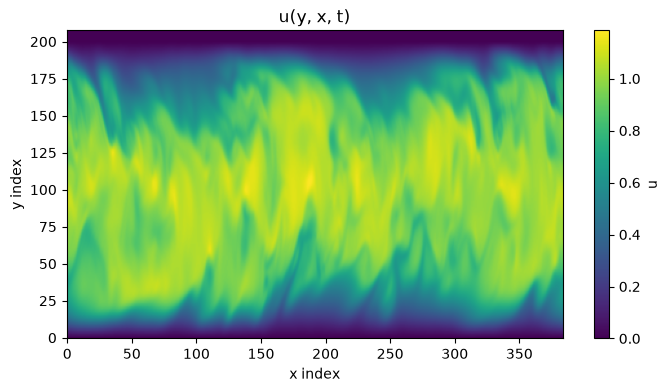

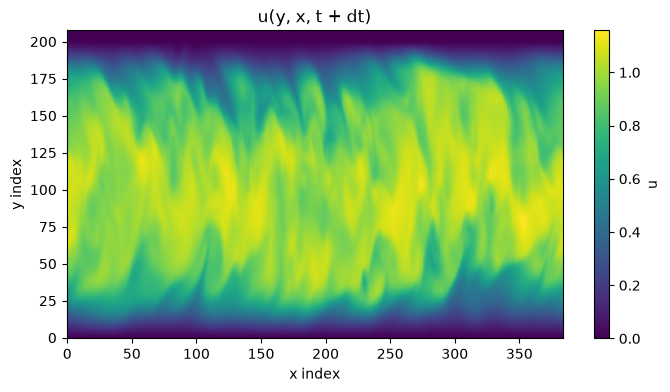

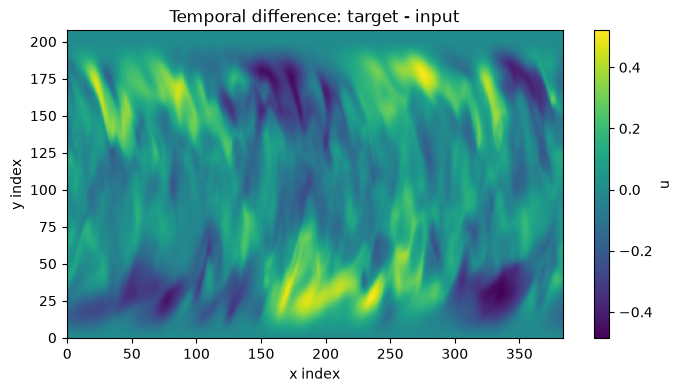

2026-10-13 04:58:05.114315: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [9]:
# =========================================================
# Inspect one training batch
# =========================================================

for batch_x, batch_y in train_ds.take(1):
    print("Batch input shape: ", batch_x.shape)
    print("Batch target shape:", batch_y.shape)

    x_sample = (batch_x[0].numpy() * channel_std + channel_mean)[:, :, 0]
    y_sample = (batch_y[0].numpy() * channel_std + channel_mean)[:, :, 0]
    diff_sample = y_sample - x_sample

    for field, title in [
        (x_sample, "u(y, x, t)"),
        (y_sample, "u(y, x, t + dt)"),
        (diff_sample, "Temporal difference: target - input")
    ]:
        plt.figure(figsize=(8, 4))
        plt.imshow(field, origin="lower", aspect="auto")
        plt.colorbar(label="u")
        plt.xlabel("x index")
        plt.ylabel("y index")
        plt.title(title)
        plt.show()


# 8. Baseline: Persistence Error

Before training a U-Net, we evaluate the simplest possible forecast: **persistence**,
i.e. predicting that the field does not change:

```text
prediction = u(y, x, t)   (instead of the true u(y, x, t + dt))
```

For small enough `dt`, turbulence evolves smoothly, so persistence can be a
surprisingly strong baseline. The U-Net should improve on it.

We compute this by streaming through the validation set batch by batch (using
`validation_steps` from Section 6, since `val_ds` is infinite) and accumulating the
error, instead of materializing the whole validation set in memory.


In [10]:
# =========================================================
# Persistence baseline, computed by streaming over the validation set
# =========================================================

sum_abs_error = 0.0
sum_sq_error = 0.0
n_elements = 0

for batch_x, batch_y in val_ds.take(validation_steps):
    diff = batch_y - batch_x
    sum_abs_error += tf.reduce_sum(tf.abs(diff)).numpy()
    sum_sq_error += tf.reduce_sum(tf.square(diff)).numpy()
    n_elements += tf.size(diff).numpy()

baseline_mae = float(sum_abs_error / n_elements)
baseline_mse = float(sum_sq_error / n_elements)

print("Persistence baseline MAE (normalized units):", baseline_mae)
print("Persistence baseline MSE (normalized units):", baseline_mse)


Persistence baseline MAE (normalized units): 0.2895675136292835
Persistence baseline MSE (normalized units): 0.16119435957344835


2026-10-13 04:58:05.412679: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


# 9. U-Net Architecture: Building Blocks

These are **exactly the same building blocks** as Stage 1, Section 14
(`conv_block`, `encoder_block`, `decoder_block`): a U-Net is a U-Net regardless of what
the input and output physically represent. Only the *meaning* of input/output changes:

```text
Stage 1: input = coarse field(t),      output = fine field(t)        (same time)
Stage 3: input = field(t),             output = field(t + dt)        (same resolution)
```


In [11]:
# =========================================================
# U-Net building blocks (identical to Stage 1, Section 14)
# =========================================================
#
#   conv_block()     -> two 3x3 convolutions (feature extraction at a fixed resolution)
#   encoder_block()   -> conv_block() + downsampling (halves H and W)
#   decoder_block()   -> upsampling + skip connection + conv_block() (doubles H and W)


def conv_block(
    x,
    filters,
    kernel_size=3,
    activation="relu",
    padding="same",
    dropout_rate=0.0
):
    """
    Basic convolutional block used in the U-Net.

    Two stacked 3x3 convolutions, padding="same" so the spatial size (H, W)
    is unchanged -- only encoder_block/decoder_block change resolution.
    """

    x = tf.keras.layers.Conv2D(
        filters=filters,
        kernel_size=kernel_size,
        activation=activation,
        padding=padding,
        kernel_initializer="he_normal"
    )(x)

    x = tf.keras.layers.Conv2D(
        filters=filters,
        kernel_size=kernel_size,
        activation=activation,
        padding=padding,
        kernel_initializer="he_normal"
    )(x)

    if dropout_rate > 0.0:
        x = tf.keras.layers.Dropout(dropout_rate)(x)

    return x


def encoder_block(
    x,
    filters,
    dropout_rate=0.0
):
    """
    One level of the encoder (downsampling path).

    Returns:
        skip -> features BEFORE pooling, later concatenated into the
                matching decoder_block() (the skip connection).
        down -> pooled tensor feeding the next (deeper) level.
    """

    skip = conv_block(
        x,
        filters=filters,
        dropout_rate=dropout_rate
    )

    down = tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    )(skip)

    return skip, down


def decoder_block(
    x,
    skip,
    filters,
    dropout_rate=0.0
):
    """
    One level of the decoder (upsampling path). Mirrors encoder_block(): it
    upsamples with Conv2DTranspose, concatenates the matching skip connection
    from the encoder, then mixes everything with conv_block().
    """

    x = tf.keras.layers.Conv2DTranspose(
        filters=filters,
        kernel_size=2,
        strides=2,
        padding="same"
    )(x)

    x = tf.keras.layers.Concatenate()([x, skip])

    x = conv_block(
        x,
        filters=filters,
        dropout_rate=dropout_rate
    )

    return x


# 10. Assemble the U-Net Model for Temporal Advancement

Same encoder / bottleneck / decoder structure as Stage 1:

```text
4 encoder_block()  (downsampling, filters double each level: base, 2x, 4x, 8x)
1 conv_block()     (bottleneck, filters = 16x base)
4 decoder_block()  (upsampling, filters halve each level: 8x, 4x, 2x, base)
1 Conv2D(1x1)      (output projection back to the u field)
```

The only functional difference from Stage 1 is that there is no artificial
coarsening step here: the input is already a full-resolution field, at time `t`, and
the network's job is purely temporal — predict the same field at time `t + dt`.


In [12]:
# =========================================================
# Create U-Net model for temporal advancement
# =========================================================

def create_unet_temporal_model(
    input_shape,
    output_channels=1,
    base_filters=32,
    dropout_rate=0.0,
    learning_rate=1e-4
):
    """
    Create a U-Net that maps u(y, x, t) to u(y, x, t + dt).

    Architecture is identical to Stage 1's super-resolution U-Net.
    """

    inputs = tf.keras.layers.Input(shape=input_shape)

    # Encoder: filters double at each of the 4 levels.
    skip1, x = encoder_block(inputs, filters=base_filters, dropout_rate=dropout_rate)
    skip2, x = encoder_block(x, filters=base_filters * 2, dropout_rate=dropout_rate)
    skip3, x = encoder_block(x, filters=base_filters * 4, dropout_rate=dropout_rate)
    skip4, x = encoder_block(x, filters=base_filters * 8, dropout_rate=dropout_rate)

    # Bottleneck: deepest, most compressed representation.
    x = conv_block(x, filters=base_filters * 16, dropout_rate=dropout_rate)

    # Decoder: filters halve at each of the 4 levels, mirroring the encoder.
    x = decoder_block(x, skip4, filters=base_filters * 8, dropout_rate=dropout_rate)
    x = decoder_block(x, skip3, filters=base_filters * 4, dropout_rate=dropout_rate)
    x = decoder_block(x, skip2, filters=base_filters * 2, dropout_rate=dropout_rate)
    x = decoder_block(x, skip1, filters=base_filters, dropout_rate=dropout_rate)

    # Output: linear activation, this is a regression problem. Only one
    # channel (u), so output_channels = 1.
    outputs = tf.keras.layers.Conv2D(
        filters=output_channels,
        kernel_size=1,
        activation="linear",
        padding="same"
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="UNet_Turbulent_Field_TemporalEvolution"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate,
            clipnorm=1.0
        ),
        loss="mse",
        metrics=["mae"]
    )

    return model


input_shape = (padded_height, padded_width, channels)

unet_model = create_unet_temporal_model(
    input_shape=input_shape,
    output_channels=channels,
    base_filters=16,
    dropout_rate=0.0,
    learning_rate=1e-4
)

unet_model.summary()


Model: "UNet_Turbulent_Field_TemporalEvolution"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 208, 384,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 208, 384,  │        160 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 208, 384,  │      2,320 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 104, 192,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 104, 192,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 104, 192,  │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 52, 96,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 52, 96,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 52, 96,    │     36,928 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 26, 48,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 26, 48,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 26, 48,    │    147,584 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 13, 24,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 13, 24,    │    295,168 │ max_pooling2d_3[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 13, 24,    │    590,080 │ conv2d_8[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 26, 48,    │    131,200 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 26, 48,    │          0 │ conv2d_transpose

 Total params: 1,940,817 (7.40 MB)

 Trainable params: 1,940,817 (7.40 MB)

 Non-trainable params: 0 (0.00 B)



Architecture figure saved to: ../results/03_unet_temporal_evolution/figures/unet_temporal_architecture.png


In [13]:
# =========================================================
# Visualize U-Net architecture (safe: works even without graphviz)
# =========================================================

figure_dir = RESULTS_DIR / "figures"
figure_dir.mkdir(exist_ok=True)

architecture_file = figure_dir / "unet_temporal_architecture.png"

dot_path = shutil.which("dot")
if dot_path is None:
    print("Graphviz 'dot' executable not found in PATH.")
    print("Install graphviz (https://graphviz.org/download/) and pydot to plot the model.")
else:
    try:
        tf.keras.utils.plot_model(
            unet_model,
            to_file=str(architecture_file),
            show_shapes=True,
            show_layer_names=True,
            show_layer_activations=True,
            show_trainable=True,
            rankdir="LR",
            dpi=90
        )
        from IPython.display import Image, display
        display(Image(filename=str(architecture_file)))
        print("Architecture figure saved to:", architecture_file)
    except Exception as error:
        print("Could not plot the model. Error:", error)


In [14]:
# =========================================================
# Manual U-Net schematic for teaching
# =========================================================

from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

def draw_unet_schematic(
    input_shape=None,
    output_shape=None,
    base_filters=16,
    save_file=RESULTS_DIR / "figures" / "unet_schematic.png"
):
    """
    Draw a clean didactic U-Net schematic.

    This is not an automatic layer-by-layer Keras plot.
    It is a readable U-shaped diagram for teaching.
    """

    save_file = Path(save_file)
    save_file.parent.mkdir(parents=True, exist_ok=True)

    fig, ax = plt.subplots(figsize=(14, 7))

    ax.set_xlim(-1.5, 13.5)
    ax.set_ylim(-0.5, 7)
    ax.axis("off")

    def add_block(x, y, text, width=1.9, height=0.8):
        rect = Rectangle(
            (x - width / 2, y - height / 2),
            width,
            height,
            fill=False,
            linewidth=2
        )
        ax.add_patch(rect)

        ax.text(
            x,
            y,
            text,
            ha="center",
            va="center",
            fontsize=10
        )

    def add_arrow(x1, y1, x2, y2, text=None):
        arrow = FancyArrowPatch(
            (x1, y1),
            (x2, y2),
            arrowstyle="-|>",
            mutation_scale=15,
            linewidth=1.5
        )
        ax.add_patch(arrow)

        if text is not None:
            ax.text(
                (x1 + x2) / 2,
                (y1 + y2) / 2 + 0.2,
                text,
                ha="center",
                va="center",
                fontsize=9
            )

    # -----------------------------------------------------
    # Titles
    # -----------------------------------------------------

    ax.text(2.4, 6.5, "Encoder", ha="center", fontsize=14, fontweight="bold")
    ax.text(6.0, 0.15, "Bottleneck", ha="center", fontsize=14, fontweight="bold")
    ax.text(9.8, 6.5, "Decoder", ha="center", fontsize=14, fontweight="bold")

    # -----------------------------------------------------
    # Input and output
    # -----------------------------------------------------

    input_text = "Input\ncoarse u(y,x)"
    if input_shape is not None:
        input_text += f"\n{input_shape}"

    output_text = "Output\nrefined u(y,x)"
    if output_shape is not None:
        output_text += f"\n{output_shape}"

    add_block(-0.1, 5.5, input_text, width=2.2)
    add_block(12.3, 5.5, output_text, width=2.2)

    # -----------------------------------------------------
    # Coordinates of blocks
    # -----------------------------------------------------

    encoder = [
        (1.5, 5.5, base_filters),
        (2.8, 4.2, base_filters * 2),
        (4.1, 2.9, base_filters * 4),
        (5.4, 1.6, base_filters * 8),
    ]

    bottleneck = (6.7, 0.8, base_filters * 16)

    decoder = [
        (8.0, 1.6, base_filters * 8),
        (9.3, 2.9, base_filters * 4),
        (10.6, 4.2, base_filters * 2),
        (11.9, 5.5, base_filters),
    ]

    # -----------------------------------------------------
    # Draw encoder
    # -----------------------------------------------------

    for x, y, filters in encoder:
        add_block(
            x,
            y,
            f"Conv block\n{filters} filters"
        )

    # -----------------------------------------------------
    # Draw bottleneck
    # -----------------------------------------------------

    add_block(
        bottleneck[0],
        bottleneck[1],
        f"Conv block\n{bottleneck[2]} filters",
        width=2.0
    )

    # -----------------------------------------------------
    # Draw decoder
    # -----------------------------------------------------

    for x, y, filters in decoder:
        add_block(
            x,
            y,
            f"Up + Conv\n{filters} filters"
        )

    # -----------------------------------------------------
    # Main path arrows
    # -----------------------------------------------------

    add_arrow(0.95, 5.5, 0.55, 5.5)

    add_arrow(0.95, 5.5, 1.0, 5.5)
    add_arrow(2.0, 5.2, 2.4, 4.5, "MaxPool")
    add_arrow(3.3, 3.9, 3.7, 3.2, "MaxPool")
    add_arrow(4.6, 2.6, 5.0, 1.9, "MaxPool")
    add_arrow(5.9, 1.3, 6.3, 1.0, "MaxPool")

    add_arrow(7.1, 1.0, 7.6, 1.3, "Up")
    add_arrow(8.5, 1.9, 8.9, 2.6, "Up")
    add_arrow(9.8, 3.2, 10.2, 3.9, "Up")
    add_arrow(11.1, 4.5, 11.5, 5.2, "Up")

    add_arrow(12.4, 5.5, 11.95, 5.5)

    # Correct final output arrow
    add_arrow(12.35, 5.5, 13.0, 5.5)

    # -----------------------------------------------------
    # Skip connections
    # -----------------------------------------------------

    skip_pairs = [
        (encoder[0], decoder[3]),
        (encoder[1], decoder[2]),
        (encoder[2], decoder[1]),
        (encoder[3], decoder[0]),
    ]

    for (x1, y1, _), (x2, y2, _) in skip_pairs:
        add_arrow(
            x1 + 0.95,
            y1,
            x2 - 0.95,
            y2,
            "skip"
        )

    # -----------------------------------------------------
    # Bottom explanatory note
    # -----------------------------------------------------

    ax.text(
        6.0,
        -0.25,
        "The encoder compresses spatial information. "
        "The decoder reconstructs the field. "
        "Skip connections transfer fine-scale spatial details.",
        ha="center",
        va="center",
        fontsize=10
    )

    plt.tight_layout()
    plt.savefig(save_file, dpi=200, bbox_inches="tight")
    plt.show()

    print("U-Net schematic saved to:")
    print(save_file)

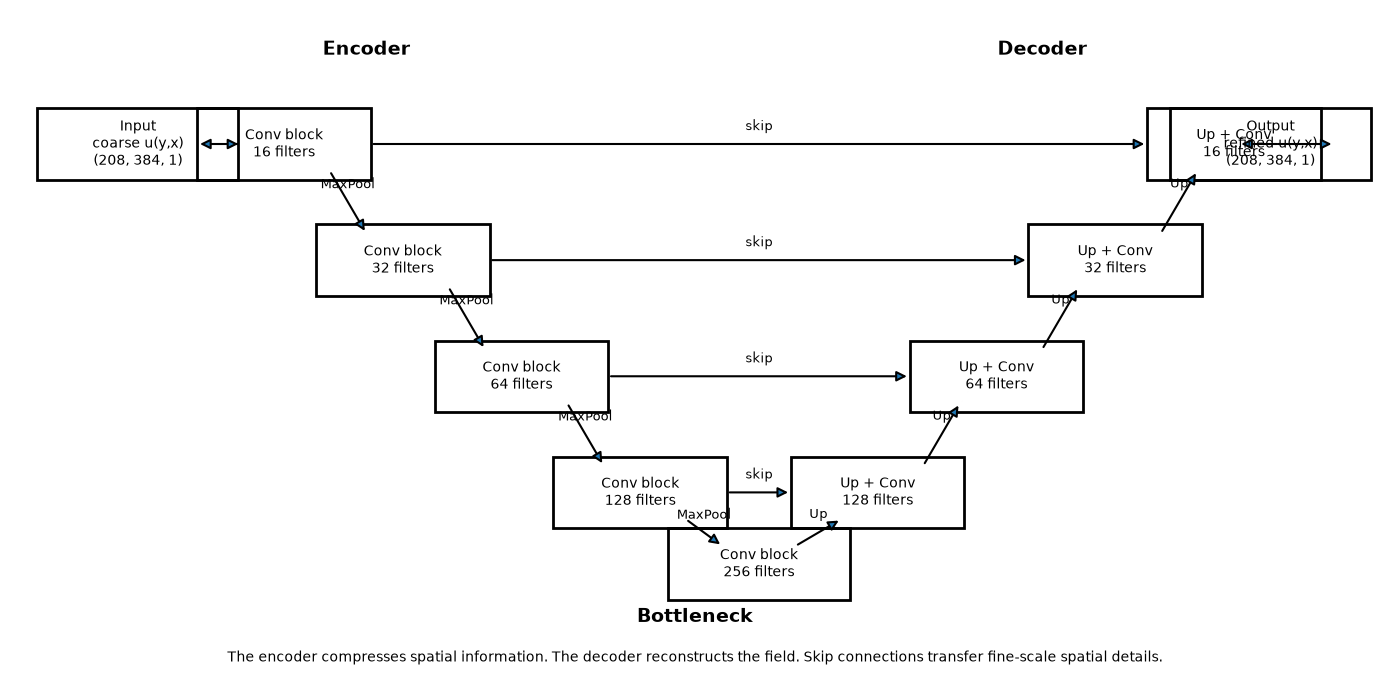

U-Net schematic saved to:
../results/03_unet_temporal_evolution/figures/unet_schematic.png


In [15]:
# =========================================================
# Draw schematic of the trained U-Net
# =========================================================

draw_unet_schematic(
    input_shape=unet_model.input_shape[1:],
    output_shape=unet_model.output_shape[1:],
    base_filters=16,
    save_file=RESULTS_DIR / "figures" / "unet_schematic.png"
)

# 11. Train the U-Net

Because `train_ds` and `val_ds` are infinite (`repeat()`, Section 6), we must pass
`steps_per_epoch` and `validation_steps` explicitly so `model.fit()` knows when one
epoch ends.


**Checkpoints and animation hook.** Before the training cell I add checkpoints for the main training (the best model by validation loss and a periodic checkpoint every 5 epochs, in the models folder) and a snapshot collector for the training animation: after every epoch it keeps the predicted next field of one fixed validation pair and the losses. The training cell adds these callbacks to the notebook's own early stopping and learning-rate schedule; nothing else changes.

In [16]:
import os
from pathlib import Path
EX_CKPT = MODELS_DIR / "checkpoints"; EX_CKPT.mkdir(parents=True, exist_ok=True)
class ExPeriodicCheckpoint(tf.keras.callbacks.Callback):
    def __init__(self, path, every): super().__init__(); self.path, self.every = path, max(1, int(every))
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every == 0: self.model.save_weights(str(self.path))
def ex_ckpt_callbacks(name, epochs, monitor="val_loss"):
    return [tf.keras.callbacks.ModelCheckpoint(str(EX_CKPT / f"{name}_best.weights.h5"), monitor=monitor, save_best_only=True, save_weights_only=True),
            ExPeriodicCheckpoint(EX_CKPT / f"{name}_periodic.weights.h5", epochs // 10)]
for _bx, _by in val_ds.take(1):
    anim_x, anim_y = _bx[0:1], _by[0:1].numpy()
class ExAnimSnapshots(tf.keras.callbacks.Callback):
    def __init__(self): super().__init__(); self.snaps = []; self.loss = []; self.val = []
    def _snap(self, e): self.snaps.append(dict(epoch=e, pred=self.model(anim_x, training=False).numpy()[0, :, :, 0], loss=list(self.loss), val=list(self.val)))
    def on_train_begin(self, logs=None): self._snap(0)
    def on_epoch_end(self, epoch, logs=None): self.loss.append(logs["loss"]); self.val.append(logs["val_loss"]); self._snap(epoch + 1)
ANIM_CB = ExAnimSnapshots()
def ex_main_callbacks(name): return ex_ckpt_callbacks(name, 50) + [ANIM_CB]

In [17]:
# =========================================================
# Train the U-Net
# =========================================================

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6
)

history = unet_model.fit(
    train_ds,
    steps_per_epoch=steps_per_epoch,
    validation_data=val_ds,
    validation_steps=validation_steps,
    epochs=50,
    callbacks=[early_stopping, reduce_lr] + ex_main_callbacks("unet_temporal"),  # checkpoints and animation snapshots
)


Epoch 1/50


2026-10-13 04:58:07.570028: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


  1/601 ━━━━━━━━━━━━━━━━━━━━ 43:44 4s/step - loss: 4.2207 - mae: 1.2504

  2/601 ━━━━━━━━━━━━━━━━━━━━ 1:11 119ms/step - loss: 4.0724 - mae: 1.2189

  3/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 112ms/step - loss: 3.9546 - mae: 1.1969

  4/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 3.8501 - mae: 1.1787

  5/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 3.7534 - mae: 1.1622

  6/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 3.6654 - mae: 1.1474

  7/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 3.5793 - mae: 1.1325

  8/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 3.4972 - mae: 1.1182

  9/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 3.4183 - mae: 1.1044

 10/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 3.3423 - mae: 1.0908

 11/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 3.2693 - mae: 1.0777

 12/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 3.1987 - mae: 1.0647

 13/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 3.1307 - mae: 1.0522

 14/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 3.0650 - mae: 1.0399

 15/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 3.0017 - mae: 1.0278

 16/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 2.9406 - mae: 1.0160

 17/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 2.8816 - mae: 1.0045

 18/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 110ms/step - loss: 2.8247 - mae: 0.9931

 19/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 2.7698 - mae: 0.9821

 20/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 2.7169 - mae: 0.9712

 21/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 2.6660 - mae: 0.9607

 22/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 2.6170 - mae: 0.9504

 23/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 2.5699 - mae: 0.9404

 24/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 109ms/step - loss: 2.5246 - mae: 0.9307

 25/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 2.4810 - mae: 0.9213

 26/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 2.4391 - mae: 0.9122

 27/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 2.3987 - mae: 0.9033

 28/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 2.3599 - mae: 0.8947

 29/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 2.3224 - mae: 0.8863

 30/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 2.2864 - mae: 0.8782

 31/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 2.2516 - mae: 0.8704

 32/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 106ms/step - loss: 2.2180 - mae: 0.8627

 33/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 106ms/step - loss: 2.1857 - mae: 0.8553

 34/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 106ms/step - loss: 2.1544 - mae: 0.8481

 35/601 ━━━━━━━━━━━━━━━━━━━━ 59s 106ms/step - loss: 2.1241 - mae: 0.8410 

 36/601 ━━━━━━━━━━━━━━━━━━━━ 59s 106ms/step - loss: 2.0949 - mae: 0.8342

 37/601 ━━━━━━━━━━━━━━━━━━━━ 59s 106ms/step - loss: 2.0666 - mae: 0.8275

 38/601 ━━━━━━━━━━━━━━━━━━━━ 59s 106ms/step - loss: 2.0392 - mae: 0.8211

 39/601 ━━━━━━━━━━━━━━━━━━━━ 59s 106ms/step - loss: 2.0127 - mae: 0.8147

 40/601 ━━━━━━━━━━━━━━━━━━━━ 59s 106ms/step - loss: 1.9870 - mae: 0.8086

 41/601 ━━━━━━━━━━━━━━━━━━━━ 59s 106ms/step - loss: 1.9621 - mae: 0.8026

 42/601 ━━━━━━━━━━━━━━━━━━━━ 59s 106ms/step - loss: 1.9379 - mae: 0.7968

 43/601 ━━━━━━━━━━━━━━━━━━━━ 59s 106ms/step - loss: 1.9145 - mae: 0.7911

 44/601 ━━━━━━━━━━━━━━━━━━━━ 59s 106ms/step - loss: 1.8917 - mae: 0.7856

 45/601 ━━━━━━━━━━━━━━━━━━━━ 59s 106ms/step - loss: 1.8696 - mae: 0.7802

 46/601 ━━━━━━━━━━━━━━━━━━━━ 59s 106ms/step - loss: 1.8481 - mae: 0.7749

 47/601 ━━━━━━━━━━━━━━━━━━━━ 58s 106ms/step - loss: 1.8273 - mae: 0.7698

 48/601 ━━━━━━━━━━━━━━━━━━━━ 58s 106ms/step - loss: 1.8070 - mae: 0.7647

 49/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 1.7872 - mae: 0.7599

 50/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 1.7680 - mae: 0.7551

 51/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 1.7493 - mae: 0.7504

 52/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 1.7310 - mae: 0.7459

 53/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 1.7132 - mae: 0.7414

 54/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 1.6959 - mae: 0.7370

 55/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 1.6790 - mae: 0.7328

 56/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 1.6626 - mae: 0.7286

 57/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 1.6465 - mae: 0.7245

 58/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 1.6308 - mae: 0.7205

 59/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 1.6155 - mae: 0.7166

 60/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 1.6005 - mae: 0.7128

 61/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 1.5859 - mae: 0.7091

 62/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 1.5716 - mae: 0.7054

 63/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 1.5576 - mae: 0.7018

 64/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 1.5440 - mae: 0.6983

 65/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 1.5306 - mae: 0.6948

 66/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 1.5175 - mae: 0.6914

 67/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 1.5047 - mae: 0.6881

 68/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 1.4922 - mae: 0.6848

 69/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 1.4799 - mae: 0.6816

 70/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 1.4679 - mae: 0.6785

 71/601 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - loss: 1.4561 - mae: 0.6754

 72/601 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - loss: 1.4446 - mae: 0.6723

 73/601 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - loss: 1.4333 - mae: 0.6694

 74/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 1.4222 - mae: 0.6664

 75/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 1.4113 - mae: 0.6635

 76/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 1.4006 - mae: 0.6607

 77/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 1.3901 - mae: 0.6579

 78/601 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - loss: 1.3799 - mae: 0.6552

 79/601 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - loss: 1.3698 - mae: 0.6525

 80/601 ━━━━━━━━━━━━━━━━━━━━ 55s 107ms/step - loss: 1.3599 - mae: 0.6498

 81/601 ━━━━━━━━━━━━━━━━━━━━ 55s 107ms/step - loss: 1.3502 - mae: 0.6472

 82/601 ━━━━━━━━━━━━━━━━━━━━ 55s 107ms/step - loss: 1.3406 - mae: 0.6447

 83/601 ━━━━━━━━━━━━━━━━━━━━ 55s 107ms/step - loss: 1.3313 - mae: 0.6421

 84/601 ━━━━━━━━━━━━━━━━━━━━ 55s 107ms/step - loss: 1.3220 - mae: 0.6397

 85/601 ━━━━━━━━━━━━━━━━━━━━ 55s 107ms/step - loss: 1.3130 - mae: 0.6372

 86/601 ━━━━━━━━━━━━━━━━━━━━ 54s 107ms/step - loss: 1.3041 - mae: 0.6348

 87/601 ━━━━━━━━━━━━━━━━━━━━ 54s 107ms/step - loss: 1.2954 - mae: 0.6324

 88/601 ━━━━━━━━━━━━━━━━━━━━ 54s 107ms/step - loss: 1.2868 - mae: 0.6301

 89/601 ━━━━━━━━━━━━━━━━━━━━ 54s 107ms/step - loss: 1.2783 - mae: 0.6278

 90/601 ━━━━━━━━━━━━━━━━━━━━ 54s 107ms/step - loss: 1.2700 - mae: 0.6255

 91/601 ━━━━━━━━━━━━━━━━━━━━ 54s 107ms/step - loss: 1.2618 - mae: 0.6233

 92/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 1.2538 - mae: 0.6211

 93/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 1.2458 - mae: 0.6189

 94/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 1.2381 - mae: 0.6168

 95/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 1.2304 - mae: 0.6147

 96/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 1.2228 - mae: 0.6126

 97/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 1.2154 - mae: 0.6105

 98/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 1.2081 - mae: 0.6085

 99/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 1.2009 - mae: 0.6065

100/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 1.1938 - mae: 0.6045

101/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 1.1868 - mae: 0.6026

102/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 1.1799 - mae: 0.6007

103/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 1.1731 - mae: 0.5988

104/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 1.1664 - mae: 0.5969

105/601 ━━━━━━━━━━━━━━━━━━━━ 53s 107ms/step - loss: 1.1599 - mae: 0.5951

106/601 ━━━━━━━━━━━━━━━━━━━━ 53s 107ms/step - loss: 1.1534 - mae: 0.5933

107/601 ━━━━━━━━━━━━━━━━━━━━ 53s 107ms/step - loss: 1.1470 - mae: 0.5915

108/601 ━━━━━━━━━━━━━━━━━━━━ 52s 107ms/step - loss: 1.1406 - mae: 0.5897

109/601 ━━━━━━━━━━━━━━━━━━━━ 52s 107ms/step - loss: 1.1344 - mae: 0.5879

110/601 ━━━━━━━━━━━━━━━━━━━━ 52s 107ms/step - loss: 1.1283 - mae: 0.5862

111/601 ━━━━━━━━━━━━━━━━━━━━ 52s 107ms/step - loss: 1.1222 - mae: 0.5845

112/601 ━━━━━━━━━━━━━━━━━━━━ 52s 107ms/step - loss: 1.1162 - mae: 0.5828

113/601 ━━━━━━━━━━━━━━━━━━━━ 52s 107ms/step - loss: 1.1103 - mae: 0.5811

114/601 ━━━━━━━━━━━━━━━━━━━━ 52s 107ms/step - loss: 1.1045 - mae: 0.5795

115/601 ━━━━━━━━━━━━━━━━━━━━ 51s 107ms/step - loss: 1.0988 - mae: 0.5779

116/601 ━━━━━━━━━━━━━━━━━━━━ 51s 107ms/step - loss: 1.0931 - mae: 0.5762

117/601 ━━━━━━━━━━━━━━━━━━━━ 51s 107ms/step - loss: 1.0875 - mae: 0.5746

118/601 ━━━━━━━━━━━━━━━━━━━━ 51s 107ms/step - loss: 1.0820 - mae: 0.5731

119/601 ━━━━━━━━━━━━━━━━━━━━ 51s 107ms/step - loss: 1.0766 - mae: 0.5715

120/601 ━━━━━━━━━━━━━━━━━━━━ 51s 107ms/step - loss: 1.0712 - mae: 0.5700

121/601 ━━━━━━━━━━━━━━━━━━━━ 51s 107ms/step - loss: 1.0659 - mae: 0.5684

122/601 ━━━━━━━━━━━━━━━━━━━━ 51s 107ms/step - loss: 1.0606 - mae: 0.5669

123/601 ━━━━━━━━━━━━━━━━━━━━ 51s 107ms/step - loss: 1.0555 - mae: 0.5654

124/601 ━━━━━━━━━━━━━━━━━━━━ 51s 107ms/step - loss: 1.0503 - mae: 0.5640

125/601 ━━━━━━━━━━━━━━━━━━━━ 51s 107ms/step - loss: 1.0453 - mae: 0.5625

126/601 ━━━━━━━━━━━━━━━━━━━━ 50s 107ms/step - loss: 1.0403 - mae: 0.5611

127/601 ━━━━━━━━━━━━━━━━━━━━ 50s 107ms/step - loss: 1.0354 - mae: 0.5596

128/601 ━━━━━━━━━━━━━━━━━━━━ 50s 107ms/step - loss: 1.0305 - mae: 0.5582

129/601 ━━━━━━━━━━━━━━━━━━━━ 50s 107ms/step - loss: 1.0257 - mae: 0.5568

130/601 ━━━━━━━━━━━━━━━━━━━━ 50s 107ms/step - loss: 1.0209 - mae: 0.5554

131/601 ━━━━━━━━━━━━━━━━━━━━ 50s 107ms/step - loss: 1.0162 - mae: 0.5540

132/601 ━━━━━━━━━━━━━━━━━━━━ 50s 107ms/step - loss: 1.0116 - mae: 0.5527

133/601 ━━━━━━━━━━━━━━━━━━━━ 50s 107ms/step - loss: 1.0070 - mae: 0.5513

134/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 1.0024 - mae: 0.5500

135/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 0.9979 - mae: 0.5487

136/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 0.9935 - mae: 0.5474

137/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 0.9891 - mae: 0.5461

138/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 0.9848 - mae: 0.5448

139/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 0.9805 - mae: 0.5435

140/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 0.9762 - mae: 0.5423

141/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 0.9720 - mae: 0.5410

142/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.9679 - mae: 0.5398

143/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.9638 - mae: 0.5386

144/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.9597 - mae: 0.5374

145/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.9557 - mae: 0.5362

146/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.9517 - mae: 0.5350

147/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.9478 - mae: 0.5338

148/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.9439 - mae: 0.5327

149/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.9400 - mae: 0.5315

150/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.9362 - mae: 0.5304

151/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.9324 - mae: 0.5292

152/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.9287 - mae: 0.5281

153/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.9250 - mae: 0.5270

154/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.9214 - mae: 0.5259

155/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.9177 - mae: 0.5248

156/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.9141 - mae: 0.5237

157/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.9106 - mae: 0.5226

158/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.9071 - mae: 0.5216

159/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.9036 - mae: 0.5205

160/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.9001 - mae: 0.5195

161/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.8967 - mae: 0.5184

162/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.8933 - mae: 0.5174

163/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.8900 - mae: 0.5164

164/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.8867 - mae: 0.5153

165/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.8834 - mae: 0.5143

166/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.8801 - mae: 0.5133

167/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.8769 - mae: 0.5124

168/601 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - loss: 0.8737 - mae: 0.5114

169/601 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - loss: 0.8705 - mae: 0.5104

170/601 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - loss: 0.8674 - mae: 0.5094

171/601 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - loss: 0.8643 - mae: 0.5085

172/601 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - loss: 0.8612 - mae: 0.5075

173/601 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - loss: 0.8582 - mae: 0.5066

174/601 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - loss: 0.8551 - mae: 0.5056

175/601 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - loss: 0.8521 - mae: 0.5047

176/601 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - loss: 0.8492 - mae: 0.5038

177/601 ━━━━━━━━━━━━━━━━━━━━ 44s 106ms/step - loss: 0.8462 - mae: 0.5029

178/601 ━━━━━━━━━━━━━━━━━━━━ 44s 106ms/step - loss: 0.8433 - mae: 0.5020

179/601 ━━━━━━━━━━━━━━━━━━━━ 44s 106ms/step - loss: 0.8404 - mae: 0.5011

180/601 ━━━━━━━━━━━━━━━━━━━━ 44s 106ms/step - loss: 0.8375 - mae: 0.5002

181/601 ━━━━━━━━━━━━━━━━━━━━ 44s 106ms/step - loss: 0.8347 - mae: 0.4993

182/601 ━━━━━━━━━━━━━━━━━━━━ 44s 106ms/step - loss: 0.8319 - mae: 0.4984

183/601 ━━━━━━━━━━━━━━━━━━━━ 44s 106ms/step - loss: 0.8291 - mae: 0.4975

184/601 ━━━━━━━━━━━━━━━━━━━━ 44s 106ms/step - loss: 0.8263 - mae: 0.4967

185/601 ━━━━━━━━━━━━━━━━━━━━ 44s 106ms/step - loss: 0.8236 - mae: 0.4958

186/601 ━━━━━━━━━━━━━━━━━━━━ 44s 106ms/step - loss: 0.8208 - mae: 0.4949

187/601 ━━━━━━━━━━━━━━━━━━━━ 44s 106ms/step - loss: 0.8181 - mae: 0.4941

188/601 ━━━━━━━━━━━━━━━━━━━━ 43s 106ms/step - loss: 0.8155 - mae: 0.4933

189/601 ━━━━━━━━━━━━━━━━━━━━ 43s 106ms/step - loss: 0.8128 - mae: 0.4924

190/601 ━━━━━━━━━━━━━━━━━━━━ 43s 106ms/step - loss: 0.8102 - mae: 0.4916

191/601 ━━━━━━━━━━━━━━━━━━━━ 43s 106ms/step - loss: 0.8076 - mae: 0.4908

192/601 ━━━━━━━━━━━━━━━━━━━━ 43s 106ms/step - loss: 0.8050 - mae: 0.4899

193/601 ━━━━━━━━━━━━━━━━━━━━ 43s 106ms/step - loss: 0.8024 - mae: 0.4891

194/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.7999 - mae: 0.4883

195/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.7973 - mae: 0.4875

196/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.7948 - mae: 0.4867

197/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.7923 - mae: 0.4859

198/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.7899 - mae: 0.4851

199/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.7874 - mae: 0.4844

200/601 ━━━━━━━━━━━━━━━━━━━━ 42s 106ms/step - loss: 0.7850 - mae: 0.4836

201/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.7826 - mae: 0.4828

202/601 ━━━━━━━━━━━━━━━━━━━━ 42s 106ms/step - loss: 0.7802 - mae: 0.4821

203/601 ━━━━━━━━━━━━━━━━━━━━ 42s 106ms/step - loss: 0.7778 - mae: 0.4813

204/601 ━━━━━━━━━━━━━━━━━━━━ 42s 106ms/step - loss: 0.7755 - mae: 0.4805

205/601 ━━━━━━━━━━━━━━━━━━━━ 42s 106ms/step - loss: 0.7731 - mae: 0.4798

206/601 ━━━━━━━━━━━━━━━━━━━━ 42s 106ms/step - loss: 0.7708 - mae: 0.4791

207/601 ━━━━━━━━━━━━━━━━━━━━ 41s 106ms/step - loss: 0.7685 - mae: 0.4783

208/601 ━━━━━━━━━━━━━━━━━━━━ 41s 106ms/step - loss: 0.7662 - mae: 0.4776

209/601 ━━━━━━━━━━━━━━━━━━━━ 41s 106ms/step - loss: 0.7640 - mae: 0.4769

210/601 ━━━━━━━━━━━━━━━━━━━━ 41s 106ms/step - loss: 0.7617 - mae: 0.4761

211/601 ━━━━━━━━━━━━━━━━━━━━ 41s 106ms/step - loss: 0.7595 - mae: 0.4754

212/601 ━━━━━━━━━━━━━━━━━━━━ 41s 106ms/step - loss: 0.7573 - mae: 0.4747

213/601 ━━━━━━━━━━━━━━━━━━━━ 41s 106ms/step - loss: 0.7551 - mae: 0.4740

214/601 ━━━━━━━━━━━━━━━━━━━━ 41s 106ms/step - loss: 0.7529 - mae: 0.4733

215/601 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - loss: 0.7507 - mae: 0.4726

216/601 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - loss: 0.7486 - mae: 0.4719

217/601 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - loss: 0.7464 - mae: 0.4712

218/601 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - loss: 0.7443 - mae: 0.4705

219/601 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - loss: 0.7422 - mae: 0.4698

220/601 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - loss: 0.7401 - mae: 0.4691

221/601 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - loss: 0.7381 - mae: 0.4685

222/601 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - loss: 0.7360 - mae: 0.4678

223/601 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - loss: 0.7340 - mae: 0.4671

224/601 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - loss: 0.7319 - mae: 0.4665

225/601 ━━━━━━━━━━━━━━━━━━━━ 39s 106ms/step - loss: 0.7299 - mae: 0.4658

226/601 ━━━━━━━━━━━━━━━━━━━━ 39s 106ms/step - loss: 0.7279 - mae: 0.4652

227/601 ━━━━━━━━━━━━━━━━━━━━ 39s 106ms/step - loss: 0.7259 - mae: 0.4645

228/601 ━━━━━━━━━━━━━━━━━━━━ 39s 106ms/step - loss: 0.7240 - mae: 0.4639

229/601 ━━━━━━━━━━━━━━━━━━━━ 39s 106ms/step - loss: 0.7220 - mae: 0.4632

230/601 ━━━━━━━━━━━━━━━━━━━━ 39s 106ms/step - loss: 0.7201 - mae: 0.4626

231/601 ━━━━━━━━━━━━━━━━━━━━ 39s 106ms/step - loss: 0.7181 - mae: 0.4620

232/601 ━━━━━━━━━━━━━━━━━━━━ 39s 106ms/step - loss: 0.7162 - mae: 0.4613

233/601 ━━━━━━━━━━━━━━━━━━━━ 39s 106ms/step - loss: 0.7143 - mae: 0.4607

234/601 ━━━━━━━━━━━━━━━━━━━━ 38s 106ms/step - loss: 0.7124 - mae: 0.4601

235/601 ━━━━━━━━━━━━━━━━━━━━ 38s 106ms/step - loss: 0.7106 - mae: 0.4595

236/601 ━━━━━━━━━━━━━━━━━━━━ 38s 106ms/step - loss: 0.7087 - mae: 0.4589

237/601 ━━━━━━━━━━━━━━━━━━━━ 38s 106ms/step - loss: 0.7068 - mae: 0.4582

238/601 ━━━━━━━━━━━━━━━━━━━━ 38s 106ms/step - loss: 0.7050 - mae: 0.4576

239/601 ━━━━━━━━━━━━━━━━━━━━ 38s 106ms/step - loss: 0.7032 - mae: 0.4570

240/601 ━━━━━━━━━━━━━━━━━━━━ 38s 106ms/step - loss: 0.7014 - mae: 0.4564

241/601 ━━━━━━━━━━━━━━━━━━━━ 38s 106ms/step - loss: 0.6996 - mae: 0.4558

242/601 ━━━━━━━━━━━━━━━━━━━━ 38s 106ms/step - loss: 0.6978 - mae: 0.4552

243/601 ━━━━━━━━━━━━━━━━━━━━ 38s 106ms/step - loss: 0.6960 - mae: 0.4547

244/601 ━━━━━━━━━━━━━━━━━━━━ 37s 106ms/step - loss: 0.6942 - mae: 0.4541

245/601 ━━━━━━━━━━━━━━━━━━━━ 37s 106ms/step - loss: 0.6925 - mae: 0.4535

246/601 ━━━━━━━━━━━━━━━━━━━━ 37s 106ms/step - loss: 0.6907 - mae: 0.4529

247/601 ━━━━━━━━━━━━━━━━━━━━ 37s 106ms/step - loss: 0.6890 - mae: 0.4523

248/601 ━━━━━━━━━━━━━━━━━━━━ 37s 106ms/step - loss: 0.6873 - mae: 0.4518

249/601 ━━━━━━━━━━━━━━━━━━━━ 37s 106ms/step - loss: 0.6856 - mae: 0.4512

250/601 ━━━━━━━━━━━━━━━━━━━━ 37s 106ms/step - loss: 0.6839 - mae: 0.4506

251/601 ━━━━━━━━━━━━━━━━━━━━ 37s 106ms/step - loss: 0.6822 - mae: 0.4501

252/601 ━━━━━━━━━━━━━━━━━━━━ 37s 106ms/step - loss: 0.6805 - mae: 0.4495

253/601 ━━━━━━━━━━━━━━━━━━━━ 36s 106ms/step - loss: 0.6788 - mae: 0.4489

254/601 ━━━━━━━━━━━━━━━━━━━━ 36s 106ms/step - loss: 0.6772 - mae: 0.4484

255/601 ━━━━━━━━━━━━━━━━━━━━ 36s 106ms/step - loss: 0.6755 - mae: 0.4478

256/601 ━━━━━━━━━━━━━━━━━━━━ 36s 106ms/step - loss: 0.6739 - mae: 0.4473

257/601 ━━━━━━━━━━━━━━━━━━━━ 36s 106ms/step - loss: 0.6723 - mae: 0.4468

258/601 ━━━━━━━━━━━━━━━━━━━━ 36s 106ms/step - loss: 0.6706 - mae: 0.4462

259/601 ━━━━━━━━━━━━━━━━━━━━ 36s 106ms/step - loss: 0.6690 - mae: 0.4457

260/601 ━━━━━━━━━━━━━━━━━━━━ 36s 106ms/step - loss: 0.6674 - mae: 0.4451

261/601 ━━━━━━━━━━━━━━━━━━━━ 36s 106ms/step - loss: 0.6659 - mae: 0.4446

262/601 ━━━━━━━━━━━━━━━━━━━━ 35s 106ms/step - loss: 0.6643 - mae: 0.4441

263/601 ━━━━━━━━━━━━━━━━━━━━ 35s 106ms/step - loss: 0.6627 - mae: 0.4436

264/601 ━━━━━━━━━━━━━━━━━━━━ 35s 106ms/step - loss: 0.6612 - mae: 0.4430

265/601 ━━━━━━━━━━━━━━━━━━━━ 35s 106ms/step - loss: 0.6596 - mae: 0.4425

266/601 ━━━━━━━━━━━━━━━━━━━━ 35s 106ms/step - loss: 0.6581 - mae: 0.4420

267/601 ━━━━━━━━━━━━━━━━━━━━ 35s 106ms/step - loss: 0.6565 - mae: 0.4415

268/601 ━━━━━━━━━━━━━━━━━━━━ 35s 106ms/step - loss: 0.6550 - mae: 0.4410

269/601 ━━━━━━━━━━━━━━━━━━━━ 35s 106ms/step - loss: 0.6535 - mae: 0.4405

270/601 ━━━━━━━━━━━━━━━━━━━━ 35s 106ms/step - loss: 0.6520 - mae: 0.4400

271/601 ━━━━━━━━━━━━━━━━━━━━ 35s 106ms/step - loss: 0.6505 - mae: 0.4394

272/601 ━━━━━━━━━━━━━━━━━━━━ 34s 106ms/step - loss: 0.6490 - mae: 0.4389

273/601 ━━━━━━━━━━━━━━━━━━━━ 34s 106ms/step - loss: 0.6476 - mae: 0.4384

274/601 ━━━━━━━━━━━━━━━━━━━━ 34s 106ms/step - loss: 0.6461 - mae: 0.4380

275/601 ━━━━━━━━━━━━━━━━━━━━ 34s 106ms/step - loss: 0.6447 - mae: 0.4375

276/601 ━━━━━━━━━━━━━━━━━━━━ 34s 106ms/step - loss: 0.6432 - mae: 0.4370

277/601 ━━━━━━━━━━━━━━━━━━━━ 34s 106ms/step - loss: 0.6418 - mae: 0.4365

278/601 ━━━━━━━━━━━━━━━━━━━━ 34s 106ms/step - loss: 0.6403 - mae: 0.4360

279/601 ━━━━━━━━━━━━━━━━━━━━ 34s 106ms/step - loss: 0.6389 - mae: 0.4355

280/601 ━━━━━━━━━━━━━━━━━━━━ 34s 106ms/step - loss: 0.6375 - mae: 0.4350

281/601 ━━━━━━━━━━━━━━━━━━━━ 34s 106ms/step - loss: 0.6361 - mae: 0.4346

282/601 ━━━━━━━━━━━━━━━━━━━━ 33s 106ms/step - loss: 0.6347 - mae: 0.4341

283/601 ━━━━━━━━━━━━━━━━━━━━ 33s 106ms/step - loss: 0.6333 - mae: 0.4336

284/601 ━━━━━━━━━━━━━━━━━━━━ 33s 106ms/step - loss: 0.6319 - mae: 0.4331

285/601 ━━━━━━━━━━━━━━━━━━━━ 33s 106ms/step - loss: 0.6305 - mae: 0.4327

286/601 ━━━━━━━━━━━━━━━━━━━━ 33s 106ms/step - loss: 0.6292 - mae: 0.4322

287/601 ━━━━━━━━━━━━━━━━━━━━ 33s 106ms/step - loss: 0.6278 - mae: 0.4317

288/601 ━━━━━━━━━━━━━━━━━━━━ 33s 106ms/step - loss: 0.6265 - mae: 0.4313

289/601 ━━━━━━━━━━━━━━━━━━━━ 33s 106ms/step - loss: 0.6251 - mae: 0.4308

290/601 ━━━━━━━━━━━━━━━━━━━━ 33s 106ms/step - loss: 0.6238 - mae: 0.4304

291/601 ━━━━━━━━━━━━━━━━━━━━ 32s 106ms/step - loss: 0.6225 - mae: 0.4299

292/601 ━━━━━━━━━━━━━━━━━━━━ 32s 106ms/step - loss: 0.6211 - mae: 0.4295

293/601 ━━━━━━━━━━━━━━━━━━━━ 32s 106ms/step - loss: 0.6198 - mae: 0.4290

294/601 ━━━━━━━━━━━━━━━━━━━━ 32s 106ms/step - loss: 0.6185 - mae: 0.4286

295/601 ━━━━━━━━━━━━━━━━━━━━ 32s 106ms/step - loss: 0.6172 - mae: 0.4281

296/601 ━━━━━━━━━━━━━━━━━━━━ 32s 106ms/step - loss: 0.6159 - mae: 0.4277

297/601 ━━━━━━━━━━━━━━━━━━━━ 32s 106ms/step - loss: 0.6146 - mae: 0.4272

298/601 ━━━━━━━━━━━━━━━━━━━━ 32s 106ms/step - loss: 0.6134 - mae: 0.4268

299/601 ━━━━━━━━━━━━━━━━━━━━ 32s 106ms/step - loss: 0.6121 - mae: 0.4264

300/601 ━━━━━━━━━━━━━━━━━━━━ 31s 106ms/step - loss: 0.6108 - mae: 0.4259

301/601 ━━━━━━━━━━━━━━━━━━━━ 31s 106ms/step - loss: 0.6096 - mae: 0.4255

302/601 ━━━━━━━━━━━━━━━━━━━━ 31s 106ms/step - loss: 0.6083 - mae: 0.4251

303/601 ━━━━━━━━━━━━━━━━━━━━ 31s 106ms/step - loss: 0.6071 - mae: 0.4247

304/601 ━━━━━━━━━━━━━━━━━━━━ 31s 106ms/step - loss: 0.6059 - mae: 0.4242

305/601 ━━━━━━━━━━━━━━━━━━━━ 31s 106ms/step - loss: 0.6046 - mae: 0.4238

306/601 ━━━━━━━━━━━━━━━━━━━━ 31s 106ms/step - loss: 0.6034 - mae: 0.4234

307/601 ━━━━━━━━━━━━━━━━━━━━ 31s 106ms/step - loss: 0.6022 - mae: 0.4230

308/601 ━━━━━━━━━━━━━━━━━━━━ 31s 106ms/step - loss: 0.6010 - mae: 0.4226

309/601 ━━━━━━━━━━━━━━━━━━━━ 31s 106ms/step - loss: 0.5998 - mae: 0.4221

310/601 ━━━━━━━━━━━━━━━━━━━━ 30s 106ms/step - loss: 0.5986 - mae: 0.4217

311/601 ━━━━━━━━━━━━━━━━━━━━ 30s 106ms/step - loss: 0.5974 - mae: 0.4213

312/601 ━━━━━━━━━━━━━━━━━━━━ 30s 106ms/step - loss: 0.5962 - mae: 0.4209

313/601 ━━━━━━━━━━━━━━━━━━━━ 30s 106ms/step - loss: 0.5950 - mae: 0.4205

314/601 ━━━━━━━━━━━━━━━━━━━━ 30s 106ms/step - loss: 0.5938 - mae: 0.4201

315/601 ━━━━━━━━━━━━━━━━━━━━ 30s 106ms/step - loss: 0.5927 - mae: 0.4197

316/601 ━━━━━━━━━━━━━━━━━━━━ 30s 106ms/step - loss: 0.5915 - mae: 0.4193

317/601 ━━━━━━━━━━━━━━━━━━━━ 30s 106ms/step - loss: 0.5904 - mae: 0.4189

318/601 ━━━━━━━━━━━━━━━━━━━━ 30s 106ms/step - loss: 0.5892 - mae: 0.4185

319/601 ━━━━━━━━━━━━━━━━━━━━ 29s 106ms/step - loss: 0.5881 - mae: 0.4181

320/601 ━━━━━━━━━━━━━━━━━━━━ 29s 106ms/step - loss: 0.5869 - mae: 0.4177

321/601 ━━━━━━━━━━━━━━━━━━━━ 29s 106ms/step - loss: 0.5858 - mae: 0.4173

322/601 ━━━━━━━━━━━━━━━━━━━━ 29s 106ms/step - loss: 0.5847 - mae: 0.4169

323/601 ━━━━━━━━━━━━━━━━━━━━ 29s 106ms/step - loss: 0.5836 - mae: 0.4165

324/601 ━━━━━━━━━━━━━━━━━━━━ 29s 106ms/step - loss: 0.5825 - mae: 0.4162

325/601 ━━━━━━━━━━━━━━━━━━━━ 29s 106ms/step - loss: 0.5813 - mae: 0.4158

326/601 ━━━━━━━━━━━━━━━━━━━━ 29s 106ms/step - loss: 0.5802 - mae: 0.4154

327/601 ━━━━━━━━━━━━━━━━━━━━ 29s 106ms/step - loss: 0.5791 - mae: 0.4150

328/601 ━━━━━━━━━━━━━━━━━━━━ 29s 106ms/step - loss: 0.5781 - mae: 0.4146

329/601 ━━━━━━━━━━━━━━━━━━━━ 28s 106ms/step - loss: 0.5770 - mae: 0.4143

330/601 ━━━━━━━━━━━━━━━━━━━━ 28s 106ms/step - loss: 0.5759 - mae: 0.4139

331/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.5748 - mae: 0.4135

332/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.5737 - mae: 0.4131

333/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.5727 - mae: 0.4128

334/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.5716 - mae: 0.4124

335/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.5706 - mae: 0.4120

336/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.5695 - mae: 0.4117

337/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.5685 - mae: 0.4113

338/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.5674 - mae: 0.4109

339/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.5664 - mae: 0.4106

340/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.5654 - mae: 0.4102

341/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.5643 - mae: 0.4098

342/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.5633 - mae: 0.4095

343/601 ━━━━━━━━━━━━━━━━━━━━ 28s 110ms/step - loss: 0.5623 - mae: 0.4091

344/601 ━━━━━━━━━━━━━━━━━━━━ 28s 110ms/step - loss: 0.5613 - mae: 0.4088

345/601 ━━━━━━━━━━━━━━━━━━━━ 28s 110ms/step - loss: 0.5603 - mae: 0.4084

346/601 ━━━━━━━━━━━━━━━━━━━━ 27s 110ms/step - loss: 0.5593 - mae: 0.4081

347/601 ━━━━━━━━━━━━━━━━━━━━ 28s 111ms/step - loss: 0.5583 - mae: 0.4077

348/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.5573 - mae: 0.4074

349/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.5563 - mae: 0.4070

350/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.5553 - mae: 0.4067

351/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.5544 - mae: 0.4064

352/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.5534 - mae: 0.4060

353/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.5524 - mae: 0.4057

354/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.5515 - mae: 0.4053

355/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.5505 - mae: 0.4050

356/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.5496 - mae: 0.4047

357/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.5486 - mae: 0.4043

358/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.5477 - mae: 0.4040

359/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.5467 - mae: 0.4037

360/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.5458 - mae: 0.4033

361/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.5448 - mae: 0.4030

362/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.5439 - mae: 0.4027

363/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.5430 - mae: 0.4023

364/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.5421 - mae: 0.4020

365/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.5412 - mae: 0.4017

366/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.5402 - mae: 0.4014

367/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.5393 - mae: 0.4011

368/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.5384 - mae: 0.4007

369/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.5375 - mae: 0.4004

370/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.5366 - mae: 0.4001

371/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.5358 - mae: 0.3998

372/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.5349 - mae: 0.3995

373/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.5340 - mae: 0.3992

374/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.5331 - mae: 0.3988

375/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.5322 - mae: 0.3985

376/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.5314 - mae: 0.3982

377/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.5305 - mae: 0.3979

378/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.5296 - mae: 0.3976

379/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.5288 - mae: 0.3973

380/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.5279 - mae: 0.3970

381/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.5271 - mae: 0.3967

382/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.5262 - mae: 0.3964

383/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.5254 - mae: 0.3961

384/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.5245 - mae: 0.3958

385/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.5237 - mae: 0.3955

386/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.5228 - mae: 0.3952

387/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.5220 - mae: 0.3949

388/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.5212 - mae: 0.3946

389/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.5204 - mae: 0.3943

390/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.5195 - mae: 0.3940

391/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.5187 - mae: 0.3937

392/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.5179 - mae: 0.3934

393/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.5171 - mae: 0.3931

394/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.5163 - mae: 0.3929

395/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.5155 - mae: 0.3926

396/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.5147 - mae: 0.3923

397/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.5139 - mae: 0.3920

398/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.5131 - mae: 0.3917

399/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.5123 - mae: 0.3914

400/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.5115 - mae: 0.3912

401/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.5107 - mae: 0.3909

402/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.5100 - mae: 0.3906

403/601 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.5092 - mae: 0.3903

404/601 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.5084 - mae: 0.3900

405/601 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.5076 - mae: 0.3898

406/601 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.5069 - mae: 0.3895

407/601 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.5061 - mae: 0.3892

408/601 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.5054 - mae: 0.3889

409/601 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.5046 - mae: 0.3887

410/601 ━━━━━━━━━━━━━━━━━━━━ 21s 110ms/step - loss: 0.5038 - mae: 0.3884

411/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.5031 - mae: 0.3881

412/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.5023 - mae: 0.3878

413/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.5016 - mae: 0.3876

414/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.5008 - mae: 0.3873

415/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.5001 - mae: 0.3870

416/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.4994 - mae: 0.3868

417/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.4986 - mae: 0.3865

418/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.4979 - mae: 0.3862

419/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.4972 - mae: 0.3860

420/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.4965 - mae: 0.3857

421/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.4957 - mae: 0.3855

422/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.4950 - mae: 0.3852

423/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.4943 - mae: 0.3849

424/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.4936 - mae: 0.3847

425/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.4929 - mae: 0.3844

426/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.4922 - mae: 0.3842

427/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.4915 - mae: 0.3839

428/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.4907 - mae: 0.3837

429/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.4900 - mae: 0.3834

430/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.4894 - mae: 0.3832

431/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.4887 - mae: 0.3829

432/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.4880 - mae: 0.3826

433/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.4873 - mae: 0.3824

434/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.4866 - mae: 0.3821

435/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.4859 - mae: 0.3819

436/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.4852 - mae: 0.3816

437/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.4845 - mae: 0.3814

438/601 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - loss: 0.4839 - mae: 0.3812

439/601 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - loss: 0.4832 - mae: 0.3809

440/601 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - loss: 0.4825 - mae: 0.3807

441/601 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - loss: 0.4818 - mae: 0.3804

442/601 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - loss: 0.4812 - mae: 0.3802

443/601 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - loss: 0.4805 - mae: 0.3799

444/601 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - loss: 0.4799 - mae: 0.3797

445/601 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - loss: 0.4792 - mae: 0.3795

446/601 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - loss: 0.4785 - mae: 0.3792

447/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.4779 - mae: 0.3790

448/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.4772 - mae: 0.3787

449/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.4766 - mae: 0.3785

450/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.4759 - mae: 0.3783

451/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.4753 - mae: 0.3780

452/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.4747 - mae: 0.3778

453/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.4740 - mae: 0.3776

454/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.4734 - mae: 0.3773

455/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.4727 - mae: 0.3771

456/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.4721 - mae: 0.3769

457/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.4715 - mae: 0.3766

458/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.4709 - mae: 0.3764

459/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.4702 - mae: 0.3762

460/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.4696 - mae: 0.3759

461/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.4690 - mae: 0.3757

462/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.4684 - mae: 0.3755

463/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.4677 - mae: 0.3753

464/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.4671 - mae: 0.3750

465/601 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - loss: 0.4665 - mae: 0.3748

466/601 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - loss: 0.4659 - mae: 0.3746

467/601 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - loss: 0.4653 - mae: 0.3744

468/601 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - loss: 0.4647 - mae: 0.3741

469/601 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - loss: 0.4641 - mae: 0.3739

470/601 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - loss: 0.4635 - mae: 0.3737

471/601 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - loss: 0.4629 - mae: 0.3735

472/601 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - loss: 0.4623 - mae: 0.3733

473/601 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - loss: 0.4617 - mae: 0.3730

474/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.4611 - mae: 0.3728

475/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.4605 - mae: 0.3726

476/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.4599 - mae: 0.3724

477/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.4593 - mae: 0.3722

478/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.4588 - mae: 0.3720

479/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.4582 - mae: 0.3717

480/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.4576 - mae: 0.3715

481/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.4570 - mae: 0.3713

482/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.4564 - mae: 0.3711

483/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.4559 - mae: 0.3709

484/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.4553 - mae: 0.3707

485/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.4547 - mae: 0.3705

486/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.4542 - mae: 0.3703

487/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.4536 - mae: 0.3700

488/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.4530 - mae: 0.3698

489/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.4525 - mae: 0.3696

490/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.4519 - mae: 0.3694

491/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.4513 - mae: 0.3692

492/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.4508 - mae: 0.3690

493/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.4502 - mae: 0.3688

494/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.4497 - mae: 0.3686

495/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.4491 - mae: 0.3684

496/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.4486 - mae: 0.3682

497/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.4480 - mae: 0.3680

498/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.4475 - mae: 0.3678

499/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.4469 - mae: 0.3676

500/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.4464 - mae: 0.3674

501/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.4459 - mae: 0.3672

502/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.4453 - mae: 0.3670

503/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.4448 - mae: 0.3668

504/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.4442 - mae: 0.3666

505/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.4437 - mae: 0.3664

506/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.4432 - mae: 0.3662

507/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.4426 - mae: 0.3660

508/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.4421 - mae: 0.3658

509/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.4416 - mae: 0.3656

510/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.4411 - mae: 0.3654

511/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.4405 - mae: 0.3652 

512/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.4400 - mae: 0.3650

513/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.4395 - mae: 0.3648

514/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.4390 - mae: 0.3646

515/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.4385 - mae: 0.3644

516/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.4380 - mae: 0.3642

517/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.4374 - mae: 0.3641

518/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.4369 - mae: 0.3639

519/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.4364 - mae: 0.3637

520/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.4359 - mae: 0.3635

521/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.4354 - mae: 0.3633

522/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.4349 - mae: 0.3631

523/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.4344 - mae: 0.3629

524/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.4339 - mae: 0.3627

525/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.4334 - mae: 0.3625

526/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.4329 - mae: 0.3624

527/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.4324 - mae: 0.3622

528/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.4319 - mae: 0.3620

529/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.4314 - mae: 0.3618

530/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.4309 - mae: 0.3616

531/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.4304 - mae: 0.3614

532/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.4299 - mae: 0.3613

533/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.4295 - mae: 0.3611

534/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.4290 - mae: 0.3609

535/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.4285 - mae: 0.3607

536/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.4280 - mae: 0.3605

537/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.4275 - mae: 0.3603

538/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.4270 - mae: 0.3602

539/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.4266 - mae: 0.3600

540/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.4261 - mae: 0.3598

541/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.4256 - mae: 0.3596

542/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.4251 - mae: 0.3595

543/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.4247 - mae: 0.3593

544/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.4242 - mae: 0.3591

545/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.4237 - mae: 0.3589

546/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.4233 - mae: 0.3587

547/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.4228 - mae: 0.3586

548/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.4223 - mae: 0.3584

549/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.4219 - mae: 0.3582

550/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.4214 - mae: 0.3580

551/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.4210 - mae: 0.3579

552/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.4205 - mae: 0.3577

553/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.4200 - mae: 0.3575

554/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.4196 - mae: 0.3574

555/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.4191 - mae: 0.3572

556/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.4187 - mae: 0.3570

557/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.4182 - mae: 0.3568

558/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.4178 - mae: 0.3567

559/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.4173 - mae: 0.3565

560/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.4169 - mae: 0.3563

561/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.4164 - mae: 0.3562

562/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.4160 - mae: 0.3560

563/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.4155 - mae: 0.3558

564/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.4151 - mae: 0.3557

565/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.4146 - mae: 0.3555

566/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.4142 - mae: 0.3553

567/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.4138 - mae: 0.3552

568/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.4133 - mae: 0.3550

569/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.4129 - mae: 0.3548

570/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.4125 - mae: 0.3547

571/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.4120 - mae: 0.3545

572/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.4116 - mae: 0.3543

573/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.4112 - mae: 0.3542

574/601 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - loss: 0.4107 - mae: 0.3540

575/601 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - loss: 0.4103 - mae: 0.3539

576/601 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - loss: 0.4099 - mae: 0.3537

577/601 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - loss: 0.4095 - mae: 0.3535

578/601 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - loss: 0.4090 - mae: 0.3534

579/601 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - loss: 0.4086 - mae: 0.3532

580/601 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - loss: 0.4082 - mae: 0.3531

581/601 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - loss: 0.4078 - mae: 0.3529

582/601 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - loss: 0.4073 - mae: 0.3527

583/601 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - loss: 0.4069 - mae: 0.3526

584/601 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - loss: 0.4065 - mae: 0.3524

585/601 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - loss: 0.4061 - mae: 0.3523

586/601 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - loss: 0.4057 - mae: 0.3521

587/601 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - loss: 0.4053 - mae: 0.3519

588/601 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - loss: 0.4048 - mae: 0.3518

589/601 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - loss: 0.4044 - mae: 0.3516

590/601 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - loss: 0.4040 - mae: 0.3515

591/601 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - loss: 0.4036 - mae: 0.3513

592/601 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - loss: 0.4032 - mae: 0.3512

593/601 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - loss: 0.4028 - mae: 0.3510

594/601 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - loss: 0.4024 - mae: 0.3509

595/601 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - loss: 0.4020 - mae: 0.3507

596/601 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - loss: 0.4016 - mae: 0.3505

597/601 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - loss: 0.4012 - mae: 0.3504

598/601 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - loss: 0.4008 - mae: 0.3502

599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - loss: 0.4004 - mae: 0.3501

600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - loss: 0.4000 - mae: 0.3499

601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - loss: 0.3996 - mae: 0.3498

601/601 ━━━━━━━━━━━━━━━━━━━━ 72s 113ms/step - loss: 0.3992 - mae: 0.3496 - val_loss: 0.0856 - val_mae: 0.2203 - learning_rate: 1.0000e-04


Epoch 2/50


  1/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 118ms/step - loss: 0.0872 - mae: 0.2213

  2/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 108ms/step - loss: 0.0895 - mae: 0.2252

  3/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 106ms/step - loss: 0.0888 - mae: 0.2249

  4/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 107ms/step - loss: 0.0886 - mae: 0.2245

  5/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 105ms/step - loss: 0.0889 - mae: 0.2246

  6/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 108ms/step - loss: 0.0892 - mae: 0.2247

  7/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 107ms/step - loss: 0.0895 - mae: 0.2250

  8/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 108ms/step - loss: 0.0897 - mae: 0.2251

  9/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 111ms/step - loss: 0.0898 - mae: 0.2252

 10/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0900 - mae: 0.2254

 11/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 0.0902 - mae: 0.2256

 12/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 0.0903 - mae: 0.2258

 13/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 0.0904 - mae: 0.2259

 14/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0905 - mae: 0.2259

 15/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0905 - mae: 0.2259

 16/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0905 - mae: 0.2259

 17/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0905 - mae: 0.2259

 18/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0905 - mae: 0.2258

 19/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0904 - mae: 0.2258

 20/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0904 - mae: 0.2257

 21/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0904 - mae: 0.2257

 22/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0904 - mae: 0.2256

 23/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0903 - mae: 0.2255

 24/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 109ms/step - loss: 0.0903 - mae: 0.2255

 25/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 109ms/step - loss: 0.0903 - mae: 0.2254

 26/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0902 - mae: 0.2253

 27/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0902 - mae: 0.2252

 28/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0902 - mae: 0.2251

 29/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0901 - mae: 0.2251

 30/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0901 - mae: 0.2250

 31/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0901 - mae: 0.2250

 32/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0901 - mae: 0.2249

 33/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0901 - mae: 0.2249

 34/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0900 - mae: 0.2249

 35/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0900 - mae: 0.2248

 36/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0900 - mae: 0.2248

 37/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0900 - mae: 0.2248

 38/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0900 - mae: 0.2247

 39/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0900 - mae: 0.2247

 40/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0900 - mae: 0.2247

 41/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0900 - mae: 0.2247

 42/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0900 - mae: 0.2247

 43/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0900 - mae: 0.2247

 44/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0900 - mae: 0.2246 

 45/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0900 - mae: 0.2246

 46/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0899 - mae: 0.2246

 47/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0899 - mae: 0.2246

 48/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0899 - mae: 0.2245

 49/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0899 - mae: 0.2245

 50/601 ━━━━━━━━━━━━━━━━━━━━ 59s 109ms/step - loss: 0.0899 - mae: 0.2245

 51/601 ━━━━━━━━━━━━━━━━━━━━ 59s 109ms/step - loss: 0.0899 - mae: 0.2245

 52/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0899 - mae: 0.2244

 53/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0899 - mae: 0.2244

 54/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0899 - mae: 0.2244

 55/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0898 - mae: 0.2244

 56/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0898 - mae: 0.2243

 57/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0898 - mae: 0.2243

 58/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0898 - mae: 0.2243

 59/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0898 - mae: 0.2243

 60/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0898 - mae: 0.2242

 61/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0898 - mae: 0.2242

 62/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0897 - mae: 0.2242

 63/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0897 - mae: 0.2241

 64/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0897 - mae: 0.2241

 65/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0897 - mae: 0.2241

 66/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0897 - mae: 0.2241

 67/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0897 - mae: 0.2240

 68/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0897 - mae: 0.2240

 69/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0897 - mae: 0.2240

 70/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0897 - mae: 0.2240

 71/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0896 - mae: 0.2239

 72/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0896 - mae: 0.2239

 73/601 ━━━━━━━━━━━━━━━━━━━━ 57s 109ms/step - loss: 0.0896 - mae: 0.2239

 74/601 ━━━━━━━━━━━━━━━━━━━━ 57s 109ms/step - loss: 0.0896 - mae: 0.2239

 75/601 ━━━━━━━━━━━━━━━━━━━━ 57s 109ms/step - loss: 0.0896 - mae: 0.2238

 76/601 ━━━━━━━━━━━━━━━━━━━━ 57s 109ms/step - loss: 0.0896 - mae: 0.2238

 77/601 ━━━━━━━━━━━━━━━━━━━━ 56s 109ms/step - loss: 0.0896 - mae: 0.2238

 78/601 ━━━━━━━━━━━━━━━━━━━━ 56s 109ms/step - loss: 0.0896 - mae: 0.2238

 79/601 ━━━━━━━━━━━━━━━━━━━━ 56s 109ms/step - loss: 0.0896 - mae: 0.2238

 80/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0896 - mae: 0.2237

 81/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0895 - mae: 0.2237

 82/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0895 - mae: 0.2237

 83/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0895 - mae: 0.2237

 84/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0895 - mae: 0.2237

 85/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0895 - mae: 0.2236

 86/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0895 - mae: 0.2236

 87/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0895 - mae: 0.2236

 88/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0895 - mae: 0.2236

 89/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0895 - mae: 0.2236

 90/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0894 - mae: 0.2235

 91/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0894 - mae: 0.2235

 92/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0894 - mae: 0.2235

 93/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0894 - mae: 0.2235

 94/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0894 - mae: 0.2234

 95/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0894 - mae: 0.2234

 96/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0894 - mae: 0.2234

 97/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0894 - mae: 0.2234

 98/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0893 - mae: 0.2233

 99/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0893 - mae: 0.2233

100/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0893 - mae: 0.2233

101/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0893 - mae: 0.2233

102/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0893 - mae: 0.2233

103/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0893 - mae: 0.2232

104/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0893 - mae: 0.2232

105/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0893 - mae: 0.2232

106/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0893 - mae: 0.2232

107/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0892 - mae: 0.2232

108/601 ━━━━━━━━━━━━━━━━━━━━ 53s 109ms/step - loss: 0.0892 - mae: 0.2231

109/601 ━━━━━━━━━━━━━━━━━━━━ 53s 109ms/step - loss: 0.0892 - mae: 0.2231

110/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0892 - mae: 0.2231

111/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0892 - mae: 0.2231

112/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0892 - mae: 0.2231

113/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0892 - mae: 0.2230

114/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0892 - mae: 0.2230

115/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0891 - mae: 0.2230

116/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0891 - mae: 0.2230

117/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0891 - mae: 0.2230

118/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0891 - mae: 0.2229

119/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0891 - mae: 0.2229

120/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0891 - mae: 0.2229

121/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0891 - mae: 0.2229

122/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0891 - mae: 0.2229

123/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0891 - mae: 0.2229

124/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0891 - mae: 0.2228

125/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0890 - mae: 0.2228

126/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0890 - mae: 0.2228

127/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0890 - mae: 0.2228

128/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0890 - mae: 0.2228

129/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0890 - mae: 0.2227

130/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0890 - mae: 0.2227

131/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0890 - mae: 0.2227

132/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0890 - mae: 0.2227

133/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0890 - mae: 0.2227

134/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0890 - mae: 0.2227

135/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0889 - mae: 0.2226

136/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0889 - mae: 0.2226

137/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0889 - mae: 0.2226

138/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0889 - mae: 0.2226

139/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0889 - mae: 0.2226

140/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0889 - mae: 0.2226

141/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0889 - mae: 0.2225

142/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0889 - mae: 0.2225

143/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0889 - mae: 0.2225

144/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0889 - mae: 0.2225

145/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0889 - mae: 0.2225

146/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0888 - mae: 0.2225

147/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0888 - mae: 0.2224

148/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0888 - mae: 0.2224

149/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0888 - mae: 0.2224

150/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0888 - mae: 0.2224

151/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0888 - mae: 0.2224

152/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0888 - mae: 0.2224

153/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0888 - mae: 0.2223

154/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0888 - mae: 0.2223

155/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0888 - mae: 0.2223

156/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0888 - mae: 0.2223

157/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0888 - mae: 0.2223

158/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0887 - mae: 0.2223

159/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0887 - mae: 0.2223

160/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0887 - mae: 0.2222

161/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0887 - mae: 0.2222

162/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0887 - mae: 0.2222

163/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0887 - mae: 0.2222

164/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0887 - mae: 0.2222

165/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0887 - mae: 0.2222

166/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0887 - mae: 0.2221

167/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0887 - mae: 0.2221

168/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0887 - mae: 0.2221

169/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0887 - mae: 0.2221

170/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0886 - mae: 0.2221

171/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0886 - mae: 0.2221

172/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0886 - mae: 0.2221

173/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0886 - mae: 0.2220

174/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0886 - mae: 0.2220

175/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0886 - mae: 0.2220

176/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0886 - mae: 0.2220

177/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0886 - mae: 0.2220

178/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0886 - mae: 0.2220

179/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0886 - mae: 0.2219

180/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0886 - mae: 0.2219

181/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0885 - mae: 0.2219

182/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0885 - mae: 0.2219

183/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0885 - mae: 0.2219

184/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0885 - mae: 0.2219

185/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0885 - mae: 0.2219

186/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0885 - mae: 0.2218

187/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0885 - mae: 0.2218

188/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0885 - mae: 0.2218

189/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0885 - mae: 0.2218

190/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0885 - mae: 0.2218

191/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0885 - mae: 0.2218

192/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0884 - mae: 0.2217

193/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0884 - mae: 0.2217

194/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0884 - mae: 0.2217

195/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0884 - mae: 0.2217

196/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0884 - mae: 0.2217

197/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0884 - mae: 0.2217

198/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0884 - mae: 0.2216

199/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0884 - mae: 0.2216

200/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0884 - mae: 0.2216

201/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0884 - mae: 0.2216

202/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0883 - mae: 0.2216

203/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0883 - mae: 0.2216

204/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0883 - mae: 0.2216

205/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0883 - mae: 0.2215

206/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0883 - mae: 0.2215

207/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0883 - mae: 0.2215

208/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0883 - mae: 0.2215

209/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0883 - mae: 0.2215

210/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0883 - mae: 0.2215

211/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0883 - mae: 0.2214

212/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0882 - mae: 0.2214

213/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0882 - mae: 0.2214

214/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0882 - mae: 0.2214

215/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0882 - mae: 0.2214

216/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0882 - mae: 0.2214

217/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0882 - mae: 0.2213

218/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0882 - mae: 0.2213

219/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0882 - mae: 0.2213

220/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0882 - mae: 0.2213

221/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0882 - mae: 0.2213

222/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0882 - mae: 0.2213

223/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0881 - mae: 0.2212

224/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0881 - mae: 0.2212

225/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0881 - mae: 0.2212

226/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0881 - mae: 0.2212

227/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0881 - mae: 0.2212

228/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0881 - mae: 0.2212

229/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0881 - mae: 0.2211

230/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0881 - mae: 0.2211

231/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0881 - mae: 0.2211

232/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0881 - mae: 0.2211

233/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0880 - mae: 0.2211

234/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0880 - mae: 0.2211

235/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0880 - mae: 0.2211

236/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0880 - mae: 0.2210

237/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0880 - mae: 0.2210

238/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0880 - mae: 0.2210

239/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0880 - mae: 0.2210

240/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0880 - mae: 0.2210

241/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0880 - mae: 0.2210

242/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0880 - mae: 0.2210

243/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0880 - mae: 0.2209

244/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0879 - mae: 0.2209

245/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0879 - mae: 0.2209

246/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0879 - mae: 0.2209

247/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0879 - mae: 0.2209

248/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0879 - mae: 0.2209

249/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0879 - mae: 0.2208

250/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0879 - mae: 0.2208

251/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0879 - mae: 0.2208

252/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0879 - mae: 0.2208

253/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0879 - mae: 0.2208

254/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0879 - mae: 0.2208

255/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0878 - mae: 0.2208

256/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0878 - mae: 0.2207

257/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0878 - mae: 0.2207

258/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0878 - mae: 0.2207

259/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0878 - mae: 0.2207

260/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0878 - mae: 0.2207

261/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0878 - mae: 0.2207

262/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0878 - mae: 0.2207

263/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0878 - mae: 0.2206

264/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0878 - mae: 0.2206

265/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0878 - mae: 0.2206

266/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0877 - mae: 0.2206

267/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0877 - mae: 0.2206

268/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0877 - mae: 0.2206

269/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0877 - mae: 0.2206

270/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0877 - mae: 0.2205

271/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0877 - mae: 0.2205

272/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0877 - mae: 0.2205

273/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0877 - mae: 0.2205

274/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0877 - mae: 0.2205

275/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0877 - mae: 0.2205

276/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0877 - mae: 0.2205

277/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0877 - mae: 0.2204

278/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0876 - mae: 0.2204

279/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0876 - mae: 0.2204

280/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0876 - mae: 0.2204

281/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0876 - mae: 0.2204

282/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0876 - mae: 0.2204

283/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0876 - mae: 0.2204

284/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0876 - mae: 0.2204

285/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0876 - mae: 0.2203

286/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0876 - mae: 0.2203

287/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0876 - mae: 0.2203

288/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0876 - mae: 0.2203

289/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0875 - mae: 0.2203

290/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0875 - mae: 0.2203

291/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0875 - mae: 0.2203

292/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0875 - mae: 0.2202

293/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0875 - mae: 0.2202

294/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0875 - mae: 0.2202

295/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0875 - mae: 0.2202

296/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0875 - mae: 0.2202

297/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0875 - mae: 0.2202

298/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0875 - mae: 0.2202

299/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0875 - mae: 0.2202

300/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0875 - mae: 0.2201

301/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0874 - mae: 0.2201

302/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0874 - mae: 0.2201

303/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0874 - mae: 0.2201

304/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0874 - mae: 0.2201

305/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0874 - mae: 0.2201

306/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0874 - mae: 0.2201

307/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0874 - mae: 0.2201

308/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0874 - mae: 0.2200

309/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0874 - mae: 0.2200

310/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0874 - mae: 0.2200

311/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0874 - mae: 0.2200

312/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0874 - mae: 0.2200

313/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0874 - mae: 0.2200

314/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0873 - mae: 0.2200

315/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0873 - mae: 0.2200

316/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0873 - mae: 0.2199

317/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0873 - mae: 0.2199

318/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0873 - mae: 0.2199

319/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0873 - mae: 0.2199

320/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0873 - mae: 0.2199

321/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0873 - mae: 0.2199

322/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0873 - mae: 0.2199

323/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0873 - mae: 0.2199

324/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0873 - mae: 0.2199

325/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0873 - mae: 0.2198

326/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0873 - mae: 0.2198

327/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0873 - mae: 0.2198

328/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0872 - mae: 0.2198

329/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0872 - mae: 0.2198

330/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0872 - mae: 0.2198

331/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0872 - mae: 0.2198

332/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0872 - mae: 0.2198

333/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0872 - mae: 0.2197

334/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0872 - mae: 0.2197

335/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0872 - mae: 0.2197

336/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.0872 - mae: 0.2197

337/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.0872 - mae: 0.2197

338/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.0872 - mae: 0.2197

339/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.0872 - mae: 0.2197

340/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.0872 - mae: 0.2197

341/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.0872 - mae: 0.2197

342/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.0871 - mae: 0.2197

343/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.0871 - mae: 0.2196

344/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.0871 - mae: 0.2196

345/601 ━━━━━━━━━━━━━━━━━━━━ 27s 109ms/step - loss: 0.0871 - mae: 0.2196

346/601 ━━━━━━━━━━━━━━━━━━━━ 27s 109ms/step - loss: 0.0871 - mae: 0.2196

347/601 ━━━━━━━━━━━━━━━━━━━━ 27s 109ms/step - loss: 0.0871 - mae: 0.2196

348/601 ━━━━━━━━━━━━━━━━━━━━ 27s 109ms/step - loss: 0.0871 - mae: 0.2196

349/601 ━━━━━━━━━━━━━━━━━━━━ 27s 109ms/step - loss: 0.0871 - mae: 0.2196

350/601 ━━━━━━━━━━━━━━━━━━━━ 27s 109ms/step - loss: 0.0871 - mae: 0.2196

351/601 ━━━━━━━━━━━━━━━━━━━━ 27s 109ms/step - loss: 0.0871 - mae: 0.2196

352/601 ━━━━━━━━━━━━━━━━━━━━ 27s 109ms/step - loss: 0.0871 - mae: 0.2195

353/601 ━━━━━━━━━━━━━━━━━━━━ 27s 109ms/step - loss: 0.0871 - mae: 0.2195

354/601 ━━━━━━━━━━━━━━━━━━━━ 26s 109ms/step - loss: 0.0871 - mae: 0.2195

355/601 ━━━━━━━━━━━━━━━━━━━━ 26s 109ms/step - loss: 0.0871 - mae: 0.2195

356/601 ━━━━━━━━━━━━━━━━━━━━ 26s 109ms/step - loss: 0.0871 - mae: 0.2195

357/601 ━━━━━━━━━━━━━━━━━━━━ 26s 109ms/step - loss: 0.0870 - mae: 0.2195

358/601 ━━━━━━━━━━━━━━━━━━━━ 26s 109ms/step - loss: 0.0870 - mae: 0.2195

359/601 ━━━━━━━━━━━━━━━━━━━━ 26s 109ms/step - loss: 0.0870 - mae: 0.2195

360/601 ━━━━━━━━━━━━━━━━━━━━ 26s 109ms/step - loss: 0.0870 - mae: 0.2195

361/601 ━━━━━━━━━━━━━━━━━━━━ 26s 109ms/step - loss: 0.0870 - mae: 0.2195

362/601 ━━━━━━━━━━━━━━━━━━━━ 26s 109ms/step - loss: 0.0870 - mae: 0.2194

363/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0870 - mae: 0.2194

364/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0870 - mae: 0.2194

365/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0870 - mae: 0.2194

366/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0870 - mae: 0.2194

367/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0870 - mae: 0.2194

368/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0870 - mae: 0.2194

369/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0870 - mae: 0.2194

370/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0870 - mae: 0.2194

371/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0870 - mae: 0.2194

372/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0870 - mae: 0.2194

373/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0869 - mae: 0.2193

374/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0869 - mae: 0.2193

375/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0869 - mae: 0.2193

376/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0869 - mae: 0.2193

377/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0869 - mae: 0.2193

378/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0869 - mae: 0.2193

379/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0869 - mae: 0.2193

380/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0869 - mae: 0.2193

381/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0869 - mae: 0.2193

382/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0869 - mae: 0.2193

383/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0869 - mae: 0.2193

384/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0869 - mae: 0.2192

385/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0869 - mae: 0.2192

386/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0869 - mae: 0.2192

387/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0869 - mae: 0.2192

388/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0869 - mae: 0.2192

389/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0869 - mae: 0.2192

390/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0868 - mae: 0.2192

391/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0868 - mae: 0.2192

392/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0868 - mae: 0.2192

393/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0868 - mae: 0.2192

394/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0868 - mae: 0.2192

395/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0868 - mae: 0.2192

396/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0868 - mae: 0.2191

397/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0868 - mae: 0.2191

398/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0868 - mae: 0.2191

399/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0868 - mae: 0.2191

400/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0868 - mae: 0.2191

401/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0868 - mae: 0.2191

402/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0868 - mae: 0.2191

403/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0868 - mae: 0.2191

404/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0868 - mae: 0.2191

405/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0868 - mae: 0.2191

406/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0868 - mae: 0.2191

407/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0868 - mae: 0.2191

408/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0868 - mae: 0.2190

409/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0867 - mae: 0.2190

410/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0867 - mae: 0.2190

411/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0867 - mae: 0.2190

412/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0867 - mae: 0.2190

413/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0867 - mae: 0.2190

414/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0867 - mae: 0.2190

415/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0867 - mae: 0.2190

416/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0867 - mae: 0.2190

417/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0867 - mae: 0.2190

418/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0867 - mae: 0.2190

419/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0867 - mae: 0.2190

420/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0867 - mae: 0.2190

421/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0867 - mae: 0.2189

422/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0867 - mae: 0.2189

423/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0867 - mae: 0.2189

424/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0867 - mae: 0.2189

425/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0867 - mae: 0.2189

426/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0867 - mae: 0.2189

427/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0867 - mae: 0.2189

428/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0866 - mae: 0.2189

429/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0866 - mae: 0.2189

430/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0866 - mae: 0.2189

431/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0866 - mae: 0.2189

432/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0866 - mae: 0.2189

433/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0866 - mae: 0.2189

434/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0866 - mae: 0.2188

435/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0866 - mae: 0.2188

436/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0866 - mae: 0.2188

437/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0866 - mae: 0.2188

438/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0866 - mae: 0.2188

439/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0866 - mae: 0.2188

440/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0866 - mae: 0.2188

441/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0866 - mae: 0.2188

442/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0866 - mae: 0.2188

443/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0866 - mae: 0.2188

444/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0866 - mae: 0.2188

445/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0866 - mae: 0.2188

446/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0866 - mae: 0.2188

447/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0866 - mae: 0.2188

448/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0866 - mae: 0.2187

449/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0865 - mae: 0.2187

450/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0865 - mae: 0.2187

451/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0865 - mae: 0.2187

452/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0865 - mae: 0.2187

453/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0865 - mae: 0.2187

454/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0865 - mae: 0.2187

455/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0865 - mae: 0.2187

456/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0865 - mae: 0.2187

457/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0865 - mae: 0.2187

458/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0865 - mae: 0.2187

459/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0865 - mae: 0.2187

460/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0865 - mae: 0.2187

461/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0865 - mae: 0.2187

462/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0865 - mae: 0.2186

463/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0865 - mae: 0.2186

464/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0865 - mae: 0.2186

465/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0865 - mae: 0.2186

466/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0865 - mae: 0.2186

467/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0865 - mae: 0.2186

468/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0865 - mae: 0.2186

469/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0865 - mae: 0.2186

470/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0865 - mae: 0.2186

471/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0864 - mae: 0.2186

472/601 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - loss: 0.0864 - mae: 0.2186

473/601 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - loss: 0.0864 - mae: 0.2186

474/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.0864 - mae: 0.2186

475/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.0864 - mae: 0.2186

476/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.0864 - mae: 0.2186

477/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.0864 - mae: 0.2185

478/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.0864 - mae: 0.2185

479/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.0864 - mae: 0.2185

480/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.0864 - mae: 0.2185

481/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.0864 - mae: 0.2185

482/601 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: 0.0864 - mae: 0.2185

483/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.0864 - mae: 0.2185

484/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.0864 - mae: 0.2185

485/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.0864 - mae: 0.2185

486/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.0864 - mae: 0.2185

487/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.0864 - mae: 0.2185

488/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.0864 - mae: 0.2185

489/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.0864 - mae: 0.2185

490/601 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.0864 - mae: 0.2185

491/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0864 - mae: 0.2185

492/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.0864 - mae: 0.2185

493/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.0864 - mae: 0.2184

494/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.0864 - mae: 0.2184

495/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.0863 - mae: 0.2184

496/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.0863 - mae: 0.2184

497/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.0863 - mae: 0.2184

498/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.0863 - mae: 0.2184

499/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.0863 - mae: 0.2184

500/601 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.0863 - mae: 0.2184

501/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0863 - mae: 0.2184

502/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0863 - mae: 0.2184

503/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0863 - mae: 0.2184

504/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0863 - mae: 0.2184

505/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0863 - mae: 0.2184

506/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0863 - mae: 0.2184

507/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0863 - mae: 0.2184

508/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0863 - mae: 0.2184

509/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0863 - mae: 0.2184

510/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0863 - mae: 0.2183 

511/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0863 - mae: 0.2183

512/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0863 - mae: 0.2183

513/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0863 - mae: 0.2183

514/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0863 - mae: 0.2183

515/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0863 - mae: 0.2183

516/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0863 - mae: 0.2183

517/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0863 - mae: 0.2183

518/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0863 - mae: 0.2183

519/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0863 - mae: 0.2183

520/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0862 - mae: 0.2183

521/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0862 - mae: 0.2183

522/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0862 - mae: 0.2183

523/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0862 - mae: 0.2183

524/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0862 - mae: 0.2183

525/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0862 - mae: 0.2183

526/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0862 - mae: 0.2182

527/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0862 - mae: 0.2182

528/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0862 - mae: 0.2182

529/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0862 - mae: 0.2182

530/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0862 - mae: 0.2182

531/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0862 - mae: 0.2182

532/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0862 - mae: 0.2182

533/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0862 - mae: 0.2182

534/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0862 - mae: 0.2182

535/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0862 - mae: 0.2182

536/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0862 - mae: 0.2182

537/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0862 - mae: 0.2182

538/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0862 - mae: 0.2182

539/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0862 - mae: 0.2182

540/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0862 - mae: 0.2182

541/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0862 - mae: 0.2182

542/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0862 - mae: 0.2182

543/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0862 - mae: 0.2181

544/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0862 - mae: 0.2181

545/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0862 - mae: 0.2181

546/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0861 - mae: 0.2181

547/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0861 - mae: 0.2181

548/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0861 - mae: 0.2181

549/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0861 - mae: 0.2181

550/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0861 - mae: 0.2181

551/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0861 - mae: 0.2181

552/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0861 - mae: 0.2181

553/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0861 - mae: 0.2181

554/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0861 - mae: 0.2181

555/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0861 - mae: 0.2181

556/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.0861 - mae: 0.2181

557/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.0861 - mae: 0.2181

558/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.0861 - mae: 0.2181

559/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.0861 - mae: 0.2181

560/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.0861 - mae: 0.2181

561/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.0861 - mae: 0.2180

562/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.0861 - mae: 0.2180

563/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.0861 - mae: 0.2180

564/601 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.0861 - mae: 0.2180

565/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.0861 - mae: 0.2180

566/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.0861 - mae: 0.2180

567/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.0861 - mae: 0.2180

568/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.0861 - mae: 0.2180

569/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.0861 - mae: 0.2180

570/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.0861 - mae: 0.2180

571/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.0861 - mae: 0.2180

572/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0860 - mae: 0.2180

573/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0860 - mae: 0.2180

574/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0860 - mae: 0.2180

575/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0860 - mae: 0.2180

576/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0860 - mae: 0.2180

577/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0860 - mae: 0.2180

578/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0860 - mae: 0.2180

579/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0860 - mae: 0.2180

580/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0860 - mae: 0.2179

581/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0860 - mae: 0.2179

582/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0860 - mae: 0.2179

583/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0860 - mae: 0.2179

584/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0860 - mae: 0.2179

585/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0860 - mae: 0.2179

586/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0860 - mae: 0.2179

587/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0860 - mae: 0.2179

588/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0860 - mae: 0.2179

589/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0860 - mae: 0.2179

590/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0860 - mae: 0.2179

591/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0860 - mae: 0.2179

592/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0860 - mae: 0.2179

593/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0860 - mae: 0.2179

594/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0860 - mae: 0.2179

595/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0860 - mae: 0.2179

596/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0860 - mae: 0.2179

597/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0860 - mae: 0.2179

598/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0860 - mae: 0.2179

599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0860 - mae: 0.2178

600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0860 - mae: 0.2178

601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0859 - mae: 0.2178

601/601 ━━━━━━━━━━━━━━━━━━━━ 67s 112ms/step - loss: 0.0859 - mae: 0.2178 - val_loss: 0.0789 - val_mae: 0.2055 - learning_rate: 1.0000e-04


Epoch 3/50


  1/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 0.0812 - mae: 0.2079

  2/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 0.0817 - mae: 0.2086

  3/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 0.0824 - mae: 0.2096

  4/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 111ms/step - loss: 0.0823 - mae: 0.2101

  5/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 108ms/step - loss: 0.0823 - mae: 0.2103

  6/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 108ms/step - loss: 0.0824 - mae: 0.2107

  7/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 107ms/step - loss: 0.0824 - mae: 0.2111

  8/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 105ms/step - loss: 0.0825 - mae: 0.2113

  9/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 105ms/step - loss: 0.0826 - mae: 0.2116

 10/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 104ms/step - loss: 0.0827 - mae: 0.2118

 11/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 104ms/step - loss: 0.0828 - mae: 0.2120

 12/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 104ms/step - loss: 0.0829 - mae: 0.2122

 13/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 103ms/step - loss: 0.0830 - mae: 0.2124

 14/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 103ms/step - loss: 0.0830 - mae: 0.2125

 15/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 104ms/step - loss: 0.0830 - mae: 0.2126

 16/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 104ms/step - loss: 0.0831 - mae: 0.2127

 17/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 105ms/step - loss: 0.0831 - mae: 0.2128

 18/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 105ms/step - loss: 0.0831 - mae: 0.2129

 19/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 106ms/step - loss: 0.0832 - mae: 0.2130

 20/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 106ms/step - loss: 0.0832 - mae: 0.2131

 21/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 106ms/step - loss: 0.0832 - mae: 0.2132

 22/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 106ms/step - loss: 0.0832 - mae: 0.2133

 23/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 106ms/step - loss: 0.0833 - mae: 0.2133

 24/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0833 - mae: 0.2134

 25/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0833 - mae: 0.2135

 26/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0833 - mae: 0.2136

 27/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0833 - mae: 0.2137

 28/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0833 - mae: 0.2137

 29/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0834 - mae: 0.2138

 30/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 109ms/step - loss: 0.0834 - mae: 0.2139

 31/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0834 - mae: 0.2140

 32/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0834 - mae: 0.2140

 33/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0834 - mae: 0.2141

 34/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0834 - mae: 0.2142

 35/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0834 - mae: 0.2142

 36/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0834 - mae: 0.2142

 37/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0834 - mae: 0.2142

 38/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0834 - mae: 0.2143

 39/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0834 - mae: 0.2143

 40/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0834 - mae: 0.2143

 41/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0834 - mae: 0.2143

 42/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0834 - mae: 0.2143

 43/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0834 - mae: 0.2143

 44/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0834 - mae: 0.2143 

 45/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0834 - mae: 0.2143

 46/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0834 - mae: 0.2143

 47/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0834 - mae: 0.2143

 48/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0834 - mae: 0.2143

 49/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0833 - mae: 0.2143

 50/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0833 - mae: 0.2143

 51/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0833 - mae: 0.2143

 52/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0833 - mae: 0.2143

 53/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0833 - mae: 0.2143

 54/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0833 - mae: 0.2143

 55/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0833 - mae: 0.2143

 56/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0833 - mae: 0.2143

 57/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0833 - mae: 0.2143

 58/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0833 - mae: 0.2143

 59/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0833 - mae: 0.2143

 60/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0833 - mae: 0.2143

 61/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0833 - mae: 0.2143

 62/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0833 - mae: 0.2143

 63/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0833 - mae: 0.2143

 64/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0833 - mae: 0.2143

 65/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0833 - mae: 0.2143

 66/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0833 - mae: 0.2143

 67/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0833 - mae: 0.2143

 68/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0833 - mae: 0.2143

 69/601 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - loss: 0.0833 - mae: 0.2143

 70/601 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - loss: 0.0833 - mae: 0.2143

 71/601 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - loss: 0.0833 - mae: 0.2143

 72/601 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - loss: 0.0833 - mae: 0.2143

 73/601 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - loss: 0.0833 - mae: 0.2143

 74/601 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - loss: 0.0833 - mae: 0.2143

 75/601 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - loss: 0.0833 - mae: 0.2143

 76/601 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - loss: 0.0833 - mae: 0.2143

 77/601 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - loss: 0.0833 - mae: 0.2143

 78/601 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - loss: 0.0833 - mae: 0.2143

 79/601 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - loss: 0.0832 - mae: 0.2143

 80/601 ━━━━━━━━━━━━━━━━━━━━ 55s 107ms/step - loss: 0.0832 - mae: 0.2143

 81/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0832 - mae: 0.2143

 82/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0832 - mae: 0.2143

 83/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0832 - mae: 0.2143

 84/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0832 - mae: 0.2143

 85/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0832 - mae: 0.2143

 86/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0832 - mae: 0.2143

 87/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0832 - mae: 0.2143

 88/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0832 - mae: 0.2143

 89/601 ━━━━━━━━━━━━━━━━━━━━ 55s 107ms/step - loss: 0.0832 - mae: 0.2143

 90/601 ━━━━━━━━━━━━━━━━━━━━ 54s 107ms/step - loss: 0.0832 - mae: 0.2143

 91/601 ━━━━━━━━━━━━━━━━━━━━ 54s 107ms/step - loss: 0.0832 - mae: 0.2143

 92/601 ━━━━━━━━━━━━━━━━━━━━ 54s 107ms/step - loss: 0.0832 - mae: 0.2142

 93/601 ━━━━━━━━━━━━━━━━━━━━ 54s 107ms/step - loss: 0.0832 - mae: 0.2142

 94/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0832 - mae: 0.2142

 95/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0832 - mae: 0.2142

 96/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0832 - mae: 0.2142

 97/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0832 - mae: 0.2142

 98/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0831 - mae: 0.2142

 99/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0831 - mae: 0.2142

100/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0831 - mae: 0.2142

101/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0831 - mae: 0.2142

102/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0831 - mae: 0.2142

103/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0831 - mae: 0.2142

104/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0831 - mae: 0.2142

105/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0831 - mae: 0.2142

106/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0831 - mae: 0.2142

107/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0831 - mae: 0.2142

108/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0831 - mae: 0.2142

109/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0831 - mae: 0.2141

110/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0831 - mae: 0.2141

111/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0831 - mae: 0.2141

112/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0831 - mae: 0.2141

113/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0831 - mae: 0.2141

114/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0831 - mae: 0.2141

115/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0831 - mae: 0.2141

116/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0831 - mae: 0.2141

117/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0831 - mae: 0.2141

118/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0831 - mae: 0.2141

119/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0831 - mae: 0.2141

120/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0831 - mae: 0.2141

121/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0830 - mae: 0.2141

122/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0830 - mae: 0.2141

123/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0830 - mae: 0.2140

124/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0830 - mae: 0.2140

125/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0830 - mae: 0.2140

126/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0830 - mae: 0.2140

127/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0830 - mae: 0.2140

128/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0830 - mae: 0.2140

129/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0830 - mae: 0.2140

130/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0830 - mae: 0.2140

131/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0830 - mae: 0.2140

132/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0830 - mae: 0.2140

133/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0830 - mae: 0.2140

134/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0830 - mae: 0.2140

135/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0830 - mae: 0.2140

136/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0830 - mae: 0.2140

137/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0830 - mae: 0.2140

138/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0830 - mae: 0.2139

139/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0830 - mae: 0.2139

140/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0830 - mae: 0.2139

141/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0830 - mae: 0.2139

142/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0830 - mae: 0.2139

143/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0830 - mae: 0.2139

144/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0830 - mae: 0.2139

145/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0830 - mae: 0.2139

146/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0829 - mae: 0.2139

147/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0829 - mae: 0.2139

148/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0829 - mae: 0.2139

149/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0829 - mae: 0.2139

150/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0829 - mae: 0.2139

151/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0829 - mae: 0.2139

152/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0829 - mae: 0.2138

153/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0829 - mae: 0.2138

154/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0829 - mae: 0.2138

155/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0829 - mae: 0.2138

156/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0829 - mae: 0.2138

157/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0829 - mae: 0.2138

158/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0829 - mae: 0.2138

159/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0829 - mae: 0.2138

160/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0829 - mae: 0.2138

161/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0829 - mae: 0.2138

162/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0829 - mae: 0.2138

163/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0829 - mae: 0.2138

164/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0829 - mae: 0.2138

165/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0829 - mae: 0.2138

166/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0829 - mae: 0.2138

167/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0829 - mae: 0.2137

168/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0829 - mae: 0.2137

169/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0829 - mae: 0.2137

170/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0828 - mae: 0.2137

171/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0828 - mae: 0.2137

172/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0828 - mae: 0.2137

173/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0828 - mae: 0.2137

174/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0828 - mae: 0.2137

175/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0828 - mae: 0.2137

176/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0828 - mae: 0.2137

177/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0828 - mae: 0.2137

178/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0828 - mae: 0.2137

179/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0828 - mae: 0.2137

180/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0828 - mae: 0.2136

181/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0828 - mae: 0.2136

182/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0828 - mae: 0.2136

183/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0828 - mae: 0.2136

184/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0828 - mae: 0.2136

185/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0828 - mae: 0.2136

186/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0828 - mae: 0.2136

187/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0828 - mae: 0.2136

188/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0828 - mae: 0.2136

189/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0827 - mae: 0.2136

190/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0827 - mae: 0.2136

191/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0827 - mae: 0.2135

192/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0827 - mae: 0.2135

193/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0827 - mae: 0.2135

194/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0827 - mae: 0.2135

195/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0827 - mae: 0.2135

196/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0827 - mae: 0.2135

197/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0827 - mae: 0.2135

198/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0827 - mae: 0.2135

199/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0827 - mae: 0.2135

200/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0827 - mae: 0.2135

201/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0827 - mae: 0.2134

202/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0827 - mae: 0.2134

203/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0827 - mae: 0.2134

204/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0827 - mae: 0.2134

205/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0826 - mae: 0.2134

206/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0826 - mae: 0.2134

207/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0826 - mae: 0.2134

208/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0826 - mae: 0.2134

209/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0826 - mae: 0.2134

210/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0826 - mae: 0.2134

211/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0826 - mae: 0.2133

212/601 ━━━━━━━━━━━━━━━━━━━━ 42s 110ms/step - loss: 0.0826 - mae: 0.2133

213/601 ━━━━━━━━━━━━━━━━━━━━ 42s 110ms/step - loss: 0.0826 - mae: 0.2133

214/601 ━━━━━━━━━━━━━━━━━━━━ 42s 110ms/step - loss: 0.0826 - mae: 0.2133

215/601 ━━━━━━━━━━━━━━━━━━━━ 42s 110ms/step - loss: 0.0826 - mae: 0.2133

216/601 ━━━━━━━━━━━━━━━━━━━━ 42s 110ms/step - loss: 0.0826 - mae: 0.2133

217/601 ━━━━━━━━━━━━━━━━━━━━ 42s 110ms/step - loss: 0.0826 - mae: 0.2133

218/601 ━━━━━━━━━━━━━━━━━━━━ 42s 110ms/step - loss: 0.0826 - mae: 0.2133

219/601 ━━━━━━━━━━━━━━━━━━━━ 42s 110ms/step - loss: 0.0826 - mae: 0.2133

220/601 ━━━━━━━━━━━━━━━━━━━━ 42s 110ms/step - loss: 0.0826 - mae: 0.2133

221/601 ━━━━━━━━━━━━━━━━━━━━ 41s 110ms/step - loss: 0.0825 - mae: 0.2132

222/601 ━━━━━━━━━━━━━━━━━━━━ 41s 110ms/step - loss: 0.0825 - mae: 0.2132

223/601 ━━━━━━━━━━━━━━━━━━━━ 41s 110ms/step - loss: 0.0825 - mae: 0.2132

224/601 ━━━━━━━━━━━━━━━━━━━━ 41s 110ms/step - loss: 0.0825 - mae: 0.2132

225/601 ━━━━━━━━━━━━━━━━━━━━ 41s 110ms/step - loss: 0.0825 - mae: 0.2132

226/601 ━━━━━━━━━━━━━━━━━━━━ 41s 110ms/step - loss: 0.0825 - mae: 0.2132

227/601 ━━━━━━━━━━━━━━━━━━━━ 41s 110ms/step - loss: 0.0825 - mae: 0.2132

228/601 ━━━━━━━━━━━━━━━━━━━━ 41s 110ms/step - loss: 0.0825 - mae: 0.2132

229/601 ━━━━━━━━━━━━━━━━━━━━ 40s 110ms/step - loss: 0.0825 - mae: 0.2132

230/601 ━━━━━━━━━━━━━━━━━━━━ 40s 110ms/step - loss: 0.0825 - mae: 0.2132

231/601 ━━━━━━━━━━━━━━━━━━━━ 40s 110ms/step - loss: 0.0825 - mae: 0.2131

232/601 ━━━━━━━━━━━━━━━━━━━━ 40s 110ms/step - loss: 0.0825 - mae: 0.2131

233/601 ━━━━━━━━━━━━━━━━━━━━ 40s 110ms/step - loss: 0.0825 - mae: 0.2131

234/601 ━━━━━━━━━━━━━━━━━━━━ 40s 110ms/step - loss: 0.0825 - mae: 0.2131

235/601 ━━━━━━━━━━━━━━━━━━━━ 40s 110ms/step - loss: 0.0825 - mae: 0.2131

236/601 ━━━━━━━━━━━━━━━━━━━━ 40s 110ms/step - loss: 0.0824 - mae: 0.2131

237/601 ━━━━━━━━━━━━━━━━━━━━ 40s 110ms/step - loss: 0.0824 - mae: 0.2131

238/601 ━━━━━━━━━━━━━━━━━━━━ 39s 110ms/step - loss: 0.0824 - mae: 0.2131

239/601 ━━━━━━━━━━━━━━━━━━━━ 39s 110ms/step - loss: 0.0824 - mae: 0.2131

240/601 ━━━━━━━━━━━━━━━━━━━━ 39s 110ms/step - loss: 0.0824 - mae: 0.2130

241/601 ━━━━━━━━━━━━━━━━━━━━ 39s 110ms/step - loss: 0.0824 - mae: 0.2130

242/601 ━━━━━━━━━━━━━━━━━━━━ 39s 110ms/step - loss: 0.0824 - mae: 0.2130

243/601 ━━━━━━━━━━━━━━━━━━━━ 39s 110ms/step - loss: 0.0824 - mae: 0.2130

244/601 ━━━━━━━━━━━━━━━━━━━━ 39s 110ms/step - loss: 0.0824 - mae: 0.2130

245/601 ━━━━━━━━━━━━━━━━━━━━ 39s 110ms/step - loss: 0.0824 - mae: 0.2130

246/601 ━━━━━━━━━━━━━━━━━━━━ 39s 110ms/step - loss: 0.0824 - mae: 0.2130

247/601 ━━━━━━━━━━━━━━━━━━━━ 38s 110ms/step - loss: 0.0824 - mae: 0.2130

248/601 ━━━━━━━━━━━━━━━━━━━━ 38s 110ms/step - loss: 0.0824 - mae: 0.2130

249/601 ━━━━━━━━━━━━━━━━━━━━ 38s 110ms/step - loss: 0.0824 - mae: 0.2130

250/601 ━━━━━━━━━━━━━━━━━━━━ 38s 110ms/step - loss: 0.0824 - mae: 0.2129

251/601 ━━━━━━━━━━━━━━━━━━━━ 38s 110ms/step - loss: 0.0823 - mae: 0.2129

252/601 ━━━━━━━━━━━━━━━━━━━━ 38s 110ms/step - loss: 0.0823 - mae: 0.2129

253/601 ━━━━━━━━━━━━━━━━━━━━ 38s 110ms/step - loss: 0.0823 - mae: 0.2129

254/601 ━━━━━━━━━━━━━━━━━━━━ 38s 110ms/step - loss: 0.0823 - mae: 0.2129

255/601 ━━━━━━━━━━━━━━━━━━━━ 38s 110ms/step - loss: 0.0823 - mae: 0.2129

256/601 ━━━━━━━━━━━━━━━━━━━━ 37s 110ms/step - loss: 0.0823 - mae: 0.2129

257/601 ━━━━━━━━━━━━━━━━━━━━ 37s 110ms/step - loss: 0.0823 - mae: 0.2129

258/601 ━━━━━━━━━━━━━━━━━━━━ 37s 110ms/step - loss: 0.0823 - mae: 0.2129

259/601 ━━━━━━━━━━━━━━━━━━━━ 37s 110ms/step - loss: 0.0823 - mae: 0.2129

260/601 ━━━━━━━━━━━━━━━━━━━━ 37s 110ms/step - loss: 0.0823 - mae: 0.2128

261/601 ━━━━━━━━━━━━━━━━━━━━ 37s 110ms/step - loss: 0.0823 - mae: 0.2128

262/601 ━━━━━━━━━━━━━━━━━━━━ 37s 110ms/step - loss: 0.0823 - mae: 0.2128

263/601 ━━━━━━━━━━━━━━━━━━━━ 37s 110ms/step - loss: 0.0823 - mae: 0.2128

264/601 ━━━━━━━━━━━━━━━━━━━━ 36s 110ms/step - loss: 0.0823 - mae: 0.2128

265/601 ━━━━━━━━━━━━━━━━━━━━ 36s 110ms/step - loss: 0.0823 - mae: 0.2128

266/601 ━━━━━━━━━━━━━━━━━━━━ 36s 110ms/step - loss: 0.0823 - mae: 0.2128

267/601 ━━━━━━━━━━━━━━━━━━━━ 36s 110ms/step - loss: 0.0823 - mae: 0.2128

268/601 ━━━━━━━━━━━━━━━━━━━━ 36s 110ms/step - loss: 0.0822 - mae: 0.2128

269/601 ━━━━━━━━━━━━━━━━━━━━ 36s 110ms/step - loss: 0.0822 - mae: 0.2128

270/601 ━━━━━━━━━━━━━━━━━━━━ 36s 110ms/step - loss: 0.0822 - mae: 0.2128

271/601 ━━━━━━━━━━━━━━━━━━━━ 36s 110ms/step - loss: 0.0822 - mae: 0.2127

272/601 ━━━━━━━━━━━━━━━━━━━━ 36s 110ms/step - loss: 0.0822 - mae: 0.2127

273/601 ━━━━━━━━━━━━━━━━━━━━ 36s 110ms/step - loss: 0.0822 - mae: 0.2127

274/601 ━━━━━━━━━━━━━━━━━━━━ 35s 110ms/step - loss: 0.0822 - mae: 0.2127

275/601 ━━━━━━━━━━━━━━━━━━━━ 35s 110ms/step - loss: 0.0822 - mae: 0.2127

276/601 ━━━━━━━━━━━━━━━━━━━━ 35s 110ms/step - loss: 0.0822 - mae: 0.2127

277/601 ━━━━━━━━━━━━━━━━━━━━ 35s 110ms/step - loss: 0.0822 - mae: 0.2127

278/601 ━━━━━━━━━━━━━━━━━━━━ 35s 110ms/step - loss: 0.0822 - mae: 0.2127

279/601 ━━━━━━━━━━━━━━━━━━━━ 35s 110ms/step - loss: 0.0822 - mae: 0.2127

280/601 ━━━━━━━━━━━━━━━━━━━━ 35s 110ms/step - loss: 0.0822 - mae: 0.2127

281/601 ━━━━━━━━━━━━━━━━━━━━ 35s 110ms/step - loss: 0.0822 - mae: 0.2127

282/601 ━━━━━━━━━━━━━━━━━━━━ 35s 110ms/step - loss: 0.0822 - mae: 0.2126

283/601 ━━━━━━━━━━━━━━━━━━━━ 34s 110ms/step - loss: 0.0822 - mae: 0.2126

284/601 ━━━━━━━━━━━━━━━━━━━━ 34s 110ms/step - loss: 0.0822 - mae: 0.2126

285/601 ━━━━━━━━━━━━━━━━━━━━ 34s 110ms/step - loss: 0.0821 - mae: 0.2126

286/601 ━━━━━━━━━━━━━━━━━━━━ 34s 110ms/step - loss: 0.0821 - mae: 0.2126

287/601 ━━━━━━━━━━━━━━━━━━━━ 34s 110ms/step - loss: 0.0821 - mae: 0.2126

288/601 ━━━━━━━━━━━━━━━━━━━━ 34s 110ms/step - loss: 0.0821 - mae: 0.2126

289/601 ━━━━━━━━━━━━━━━━━━━━ 34s 110ms/step - loss: 0.0821 - mae: 0.2126

290/601 ━━━━━━━━━━━━━━━━━━━━ 34s 110ms/step - loss: 0.0821 - mae: 0.2126

291/601 ━━━━━━━━━━━━━━━━━━━━ 34s 110ms/step - loss: 0.0821 - mae: 0.2126

292/601 ━━━━━━━━━━━━━━━━━━━━ 33s 110ms/step - loss: 0.0821 - mae: 0.2125

293/601 ━━━━━━━━━━━━━━━━━━━━ 33s 110ms/step - loss: 0.0821 - mae: 0.2125

294/601 ━━━━━━━━━━━━━━━━━━━━ 33s 110ms/step - loss: 0.0821 - mae: 0.2125

295/601 ━━━━━━━━━━━━━━━━━━━━ 33s 110ms/step - loss: 0.0821 - mae: 0.2125

296/601 ━━━━━━━━━━━━━━━━━━━━ 33s 110ms/step - loss: 0.0821 - mae: 0.2125

297/601 ━━━━━━━━━━━━━━━━━━━━ 33s 110ms/step - loss: 0.0821 - mae: 0.2125

298/601 ━━━━━━━━━━━━━━━━━━━━ 33s 110ms/step - loss: 0.0821 - mae: 0.2125

299/601 ━━━━━━━━━━━━━━━━━━━━ 33s 110ms/step - loss: 0.0821 - mae: 0.2125

300/601 ━━━━━━━━━━━━━━━━━━━━ 33s 110ms/step - loss: 0.0821 - mae: 0.2125

301/601 ━━━━━━━━━━━━━━━━━━━━ 32s 110ms/step - loss: 0.0821 - mae: 0.2125

302/601 ━━━━━━━━━━━━━━━━━━━━ 32s 110ms/step - loss: 0.0821 - mae: 0.2125

303/601 ━━━━━━━━━━━━━━━━━━━━ 32s 110ms/step - loss: 0.0820 - mae: 0.2125

304/601 ━━━━━━━━━━━━━━━━━━━━ 32s 110ms/step - loss: 0.0820 - mae: 0.2124

305/601 ━━━━━━━━━━━━━━━━━━━━ 32s 110ms/step - loss: 0.0820 - mae: 0.2124

306/601 ━━━━━━━━━━━━━━━━━━━━ 32s 110ms/step - loss: 0.0820 - mae: 0.2124

307/601 ━━━━━━━━━━━━━━━━━━━━ 32s 110ms/step - loss: 0.0820 - mae: 0.2124

308/601 ━━━━━━━━━━━━━━━━━━━━ 32s 110ms/step - loss: 0.0820 - mae: 0.2124

309/601 ━━━━━━━━━━━━━━━━━━━━ 32s 110ms/step - loss: 0.0820 - mae: 0.2124

310/601 ━━━━━━━━━━━━━━━━━━━━ 31s 110ms/step - loss: 0.0820 - mae: 0.2124

311/601 ━━━━━━━━━━━━━━━━━━━━ 31s 110ms/step - loss: 0.0820 - mae: 0.2124

312/601 ━━━━━━━━━━━━━━━━━━━━ 31s 110ms/step - loss: 0.0820 - mae: 0.2124

313/601 ━━━━━━━━━━━━━━━━━━━━ 31s 110ms/step - loss: 0.0820 - mae: 0.2124

314/601 ━━━━━━━━━━━━━━━━━━━━ 31s 110ms/step - loss: 0.0820 - mae: 0.2124

315/601 ━━━━━━━━━━━━━━━━━━━━ 31s 110ms/step - loss: 0.0820 - mae: 0.2123

316/601 ━━━━━━━━━━━━━━━━━━━━ 31s 110ms/step - loss: 0.0820 - mae: 0.2123

317/601 ━━━━━━━━━━━━━━━━━━━━ 31s 110ms/step - loss: 0.0820 - mae: 0.2123

318/601 ━━━━━━━━━━━━━━━━━━━━ 31s 110ms/step - loss: 0.0820 - mae: 0.2123

319/601 ━━━━━━━━━━━━━━━━━━━━ 31s 110ms/step - loss: 0.0820 - mae: 0.2123

320/601 ━━━━━━━━━━━━━━━━━━━━ 30s 110ms/step - loss: 0.0820 - mae: 0.2123

321/601 ━━━━━━━━━━━━━━━━━━━━ 30s 110ms/step - loss: 0.0820 - mae: 0.2123

322/601 ━━━━━━━━━━━━━━━━━━━━ 30s 110ms/step - loss: 0.0820 - mae: 0.2123

323/601 ━━━━━━━━━━━━━━━━━━━━ 30s 110ms/step - loss: 0.0819 - mae: 0.2123

324/601 ━━━━━━━━━━━━━━━━━━━━ 30s 110ms/step - loss: 0.0819 - mae: 0.2123

325/601 ━━━━━━━━━━━━━━━━━━━━ 30s 110ms/step - loss: 0.0819 - mae: 0.2123

326/601 ━━━━━━━━━━━━━━━━━━━━ 30s 110ms/step - loss: 0.0819 - mae: 0.2123

327/601 ━━━━━━━━━━━━━━━━━━━━ 30s 110ms/step - loss: 0.0819 - mae: 0.2123

328/601 ━━━━━━━━━━━━━━━━━━━━ 30s 110ms/step - loss: 0.0819 - mae: 0.2122

329/601 ━━━━━━━━━━━━━━━━━━━━ 29s 110ms/step - loss: 0.0819 - mae: 0.2122

330/601 ━━━━━━━━━━━━━━━━━━━━ 29s 110ms/step - loss: 0.0819 - mae: 0.2122

331/601 ━━━━━━━━━━━━━━━━━━━━ 29s 110ms/step - loss: 0.0819 - mae: 0.2122

332/601 ━━━━━━━━━━━━━━━━━━━━ 29s 110ms/step - loss: 0.0819 - mae: 0.2122

333/601 ━━━━━━━━━━━━━━━━━━━━ 29s 110ms/step - loss: 0.0819 - mae: 0.2122

334/601 ━━━━━━━━━━━━━━━━━━━━ 29s 110ms/step - loss: 0.0819 - mae: 0.2122

335/601 ━━━━━━━━━━━━━━━━━━━━ 29s 110ms/step - loss: 0.0819 - mae: 0.2122

336/601 ━━━━━━━━━━━━━━━━━━━━ 29s 110ms/step - loss: 0.0819 - mae: 0.2122

337/601 ━━━━━━━━━━━━━━━━━━━━ 29s 111ms/step - loss: 0.0819 - mae: 0.2122

338/601 ━━━━━━━━━━━━━━━━━━━━ 29s 111ms/step - loss: 0.0819 - mae: 0.2122

339/601 ━━━━━━━━━━━━━━━━━━━━ 28s 111ms/step - loss: 0.0819 - mae: 0.2122

340/601 ━━━━━━━━━━━━━━━━━━━━ 28s 111ms/step - loss: 0.0819 - mae: 0.2122

341/601 ━━━━━━━━━━━━━━━━━━━━ 28s 111ms/step - loss: 0.0819 - mae: 0.2121

342/601 ━━━━━━━━━━━━━━━━━━━━ 28s 111ms/step - loss: 0.0819 - mae: 0.2121

343/601 ━━━━━━━━━━━━━━━━━━━━ 28s 111ms/step - loss: 0.0819 - mae: 0.2121

344/601 ━━━━━━━━━━━━━━━━━━━━ 28s 111ms/step - loss: 0.0819 - mae: 0.2121

345/601 ━━━━━━━━━━━━━━━━━━━━ 28s 111ms/step - loss: 0.0818 - mae: 0.2121

346/601 ━━━━━━━━━━━━━━━━━━━━ 28s 111ms/step - loss: 0.0818 - mae: 0.2121

347/601 ━━━━━━━━━━━━━━━━━━━━ 28s 111ms/step - loss: 0.0818 - mae: 0.2121

348/601 ━━━━━━━━━━━━━━━━━━━━ 28s 111ms/step - loss: 0.0818 - mae: 0.2121

349/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.0818 - mae: 0.2121

350/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.0818 - mae: 0.2121

351/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.0818 - mae: 0.2121

352/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.0818 - mae: 0.2121

353/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.0818 - mae: 0.2121

354/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.0818 - mae: 0.2121

355/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.0818 - mae: 0.2120

356/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.0818 - mae: 0.2120

357/601 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - loss: 0.0818 - mae: 0.2120

358/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.0818 - mae: 0.2120

359/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.0818 - mae: 0.2120

360/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.0818 - mae: 0.2120

361/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.0818 - mae: 0.2120

362/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.0818 - mae: 0.2120

363/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.0818 - mae: 0.2120

364/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.0818 - mae: 0.2120

365/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.0818 - mae: 0.2120

366/601 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - loss: 0.0818 - mae: 0.2120

367/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.0818 - mae: 0.2120

368/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.0818 - mae: 0.2120

369/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.0817 - mae: 0.2120

370/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.0817 - mae: 0.2119

371/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.0817 - mae: 0.2119

372/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.0817 - mae: 0.2119

373/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.0817 - mae: 0.2119

374/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.0817 - mae: 0.2119

375/601 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - loss: 0.0817 - mae: 0.2119

376/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.0817 - mae: 0.2119

377/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.0817 - mae: 0.2119

378/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.0817 - mae: 0.2119

379/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.0817 - mae: 0.2119

380/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.0817 - mae: 0.2119

381/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.0817 - mae: 0.2119

382/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.0817 - mae: 0.2119

383/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.0817 - mae: 0.2119

384/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.0817 - mae: 0.2119

385/601 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - loss: 0.0817 - mae: 0.2118

386/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.0817 - mae: 0.2118

387/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.0817 - mae: 0.2118

388/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.0817 - mae: 0.2118

389/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.0817 - mae: 0.2118

390/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.0817 - mae: 0.2118

391/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.0817 - mae: 0.2118

392/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.0817 - mae: 0.2118

393/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.0817 - mae: 0.2118

394/601 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - loss: 0.0817 - mae: 0.2118

395/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.0817 - mae: 0.2118

396/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.0816 - mae: 0.2118

397/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.0816 - mae: 0.2118

398/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.0816 - mae: 0.2118

399/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.0816 - mae: 0.2118

400/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.0816 - mae: 0.2118

401/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.0816 - mae: 0.2118

402/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.0816 - mae: 0.2117

403/601 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - loss: 0.0816 - mae: 0.2117

404/601 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.0816 - mae: 0.2117

405/601 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.0816 - mae: 0.2117

406/601 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.0816 - mae: 0.2117

407/601 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.0816 - mae: 0.2117

408/601 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.0816 - mae: 0.2117

409/601 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.0816 - mae: 0.2117

410/601 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.0816 - mae: 0.2117

411/601 ━━━━━━━━━━━━━━━━━━━━ 21s 112ms/step - loss: 0.0816 - mae: 0.2117

412/601 ━━━━━━━━━━━━━━━━━━━━ 21s 112ms/step - loss: 0.0816 - mae: 0.2117

413/601 ━━━━━━━━━━━━━━━━━━━━ 20s 112ms/step - loss: 0.0816 - mae: 0.2117

414/601 ━━━━━━━━━━━━━━━━━━━━ 20s 112ms/step - loss: 0.0816 - mae: 0.2117

415/601 ━━━━━━━━━━━━━━━━━━━━ 20s 112ms/step - loss: 0.0816 - mae: 0.2117

416/601 ━━━━━━━━━━━━━━━━━━━━ 20s 112ms/step - loss: 0.0816 - mae: 0.2117

417/601 ━━━━━━━━━━━━━━━━━━━━ 20s 112ms/step - loss: 0.0816 - mae: 0.2117

418/601 ━━━━━━━━━━━━━━━━━━━━ 20s 112ms/step - loss: 0.0816 - mae: 0.2117

419/601 ━━━━━━━━━━━━━━━━━━━━ 20s 112ms/step - loss: 0.0816 - mae: 0.2117

420/601 ━━━━━━━━━━━━━━━━━━━━ 20s 112ms/step - loss: 0.0816 - mae: 0.2117

421/601 ━━━━━━━━━━━━━━━━━━━━ 20s 112ms/step - loss: 0.0816 - mae: 0.2116

422/601 ━━━━━━━━━━━━━━━━━━━━ 19s 112ms/step - loss: 0.0816 - mae: 0.2116

423/601 ━━━━━━━━━━━━━━━━━━━━ 19s 112ms/step - loss: 0.0816 - mae: 0.2116

424/601 ━━━━━━━━━━━━━━━━━━━━ 19s 112ms/step - loss: 0.0816 - mae: 0.2116

425/601 ━━━━━━━━━━━━━━━━━━━━ 19s 112ms/step - loss: 0.0816 - mae: 0.2116

426/601 ━━━━━━━━━━━━━━━━━━━━ 19s 112ms/step - loss: 0.0816 - mae: 0.2116

427/601 ━━━━━━━━━━━━━━━━━━━━ 19s 112ms/step - loss: 0.0815 - mae: 0.2116

428/601 ━━━━━━━━━━━━━━━━━━━━ 19s 112ms/step - loss: 0.0815 - mae: 0.2116

429/601 ━━━━━━━━━━━━━━━━━━━━ 19s 112ms/step - loss: 0.0815 - mae: 0.2116

430/601 ━━━━━━━━━━━━━━━━━━━━ 19s 112ms/step - loss: 0.0815 - mae: 0.2116

431/601 ━━━━━━━━━━━━━━━━━━━━ 18s 112ms/step - loss: 0.0815 - mae: 0.2116

432/601 ━━━━━━━━━━━━━━━━━━━━ 18s 112ms/step - loss: 0.0815 - mae: 0.2116

433/601 ━━━━━━━━━━━━━━━━━━━━ 18s 112ms/step - loss: 0.0815 - mae: 0.2116

434/601 ━━━━━━━━━━━━━━━━━━━━ 18s 112ms/step - loss: 0.0815 - mae: 0.2116

435/601 ━━━━━━━━━━━━━━━━━━━━ 18s 112ms/step - loss: 0.0815 - mae: 0.2116

436/601 ━━━━━━━━━━━━━━━━━━━━ 18s 112ms/step - loss: 0.0815 - mae: 0.2116

437/601 ━━━━━━━━━━━━━━━━━━━━ 18s 112ms/step - loss: 0.0815 - mae: 0.2116

438/601 ━━━━━━━━━━━━━━━━━━━━ 18s 112ms/step - loss: 0.0815 - mae: 0.2116

439/601 ━━━━━━━━━━━━━━━━━━━━ 18s 112ms/step - loss: 0.0815 - mae: 0.2116

440/601 ━━━━━━━━━━━━━━━━━━━━ 18s 112ms/step - loss: 0.0815 - mae: 0.2116

441/601 ━━━━━━━━━━━━━━━━━━━━ 17s 112ms/step - loss: 0.0815 - mae: 0.2116

442/601 ━━━━━━━━━━━━━━━━━━━━ 17s 112ms/step - loss: 0.0815 - mae: 0.2115

443/601 ━━━━━━━━━━━━━━━━━━━━ 17s 112ms/step - loss: 0.0815 - mae: 0.2115

444/601 ━━━━━━━━━━━━━━━━━━━━ 17s 112ms/step - loss: 0.0815 - mae: 0.2115

445/601 ━━━━━━━━━━━━━━━━━━━━ 17s 112ms/step - loss: 0.0815 - mae: 0.2115

446/601 ━━━━━━━━━━━━━━━━━━━━ 17s 112ms/step - loss: 0.0815 - mae: 0.2115

447/601 ━━━━━━━━━━━━━━━━━━━━ 17s 112ms/step - loss: 0.0815 - mae: 0.2115

448/601 ━━━━━━━━━━━━━━━━━━━━ 17s 112ms/step - loss: 0.0815 - mae: 0.2115

449/601 ━━━━━━━━━━━━━━━━━━━━ 17s 112ms/step - loss: 0.0815 - mae: 0.2115

450/601 ━━━━━━━━━━━━━━━━━━━━ 16s 112ms/step - loss: 0.0815 - mae: 0.2115

451/601 ━━━━━━━━━━━━━━━━━━━━ 16s 112ms/step - loss: 0.0815 - mae: 0.2115

452/601 ━━━━━━━━━━━━━━━━━━━━ 16s 112ms/step - loss: 0.0815 - mae: 0.2115

453/601 ━━━━━━━━━━━━━━━━━━━━ 16s 112ms/step - loss: 0.0815 - mae: 0.2115

454/601 ━━━━━━━━━━━━━━━━━━━━ 16s 112ms/step - loss: 0.0815 - mae: 0.2115

455/601 ━━━━━━━━━━━━━━━━━━━━ 16s 112ms/step - loss: 0.0815 - mae: 0.2115

456/601 ━━━━━━━━━━━━━━━━━━━━ 16s 112ms/step - loss: 0.0815 - mae: 0.2115

457/601 ━━━━━━━━━━━━━━━━━━━━ 16s 112ms/step - loss: 0.0815 - mae: 0.2115

458/601 ━━━━━━━━━━━━━━━━━━━━ 16s 112ms/step - loss: 0.0815 - mae: 0.2115

459/601 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - loss: 0.0815 - mae: 0.2115

460/601 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - loss: 0.0815 - mae: 0.2115

461/601 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - loss: 0.0815 - mae: 0.2115

462/601 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - loss: 0.0815 - mae: 0.2115

463/601 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - loss: 0.0815 - mae: 0.2115

464/601 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - loss: 0.0815 - mae: 0.2115

465/601 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - loss: 0.0814 - mae: 0.2115

466/601 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - loss: 0.0814 - mae: 0.2115

467/601 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - loss: 0.0814 - mae: 0.2115

468/601 ━━━━━━━━━━━━━━━━━━━━ 14s 112ms/step - loss: 0.0814 - mae: 0.2114

469/601 ━━━━━━━━━━━━━━━━━━━━ 14s 112ms/step - loss: 0.0814 - mae: 0.2114

470/601 ━━━━━━━━━━━━━━━━━━━━ 14s 112ms/step - loss: 0.0814 - mae: 0.2114

471/601 ━━━━━━━━━━━━━━━━━━━━ 14s 112ms/step - loss: 0.0814 - mae: 0.2114

472/601 ━━━━━━━━━━━━━━━━━━━━ 14s 112ms/step - loss: 0.0814 - mae: 0.2114

473/601 ━━━━━━━━━━━━━━━━━━━━ 14s 113ms/step - loss: 0.0814 - mae: 0.2114

474/601 ━━━━━━━━━━━━━━━━━━━━ 14s 113ms/step - loss: 0.0814 - mae: 0.2114

475/601 ━━━━━━━━━━━━━━━━━━━━ 14s 113ms/step - loss: 0.0814 - mae: 0.2114

476/601 ━━━━━━━━━━━━━━━━━━━━ 14s 113ms/step - loss: 0.0814 - mae: 0.2114

477/601 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step - loss: 0.0814 - mae: 0.2114

478/601 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step - loss: 0.0814 - mae: 0.2114

479/601 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step - loss: 0.0814 - mae: 0.2114

480/601 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step - loss: 0.0814 - mae: 0.2114

481/601 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step - loss: 0.0814 - mae: 0.2114

482/601 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step - loss: 0.0814 - mae: 0.2114

483/601 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step - loss: 0.0814 - mae: 0.2114

484/601 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step - loss: 0.0814 - mae: 0.2114

485/601 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step - loss: 0.0814 - mae: 0.2114

486/601 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - loss: 0.0814 - mae: 0.2114

487/601 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - loss: 0.0814 - mae: 0.2114

488/601 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - loss: 0.0814 - mae: 0.2114

489/601 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - loss: 0.0814 - mae: 0.2114

490/601 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - loss: 0.0814 - mae: 0.2114

491/601 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - loss: 0.0814 - mae: 0.2114

492/601 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - loss: 0.0814 - mae: 0.2114

493/601 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - loss: 0.0814 - mae: 0.2114

494/601 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - loss: 0.0814 - mae: 0.2114

495/601 ━━━━━━━━━━━━━━━━━━━━ 11s 113ms/step - loss: 0.0814 - mae: 0.2114

496/601 ━━━━━━━━━━━━━━━━━━━━ 11s 113ms/step - loss: 0.0814 - mae: 0.2114

497/601 ━━━━━━━━━━━━━━━━━━━━ 11s 113ms/step - loss: 0.0814 - mae: 0.2113

498/601 ━━━━━━━━━━━━━━━━━━━━ 11s 113ms/step - loss: 0.0814 - mae: 0.2113

499/601 ━━━━━━━━━━━━━━━━━━━━ 11s 113ms/step - loss: 0.0814 - mae: 0.2113

500/601 ━━━━━━━━━━━━━━━━━━━━ 11s 113ms/step - loss: 0.0814 - mae: 0.2113

501/601 ━━━━━━━━━━━━━━━━━━━━ 11s 113ms/step - loss: 0.0814 - mae: 0.2113

502/601 ━━━━━━━━━━━━━━━━━━━━ 11s 113ms/step - loss: 0.0814 - mae: 0.2113

503/601 ━━━━━━━━━━━━━━━━━━━━ 11s 114ms/step - loss: 0.0814 - mae: 0.2113

504/601 ━━━━━━━━━━━━━━━━━━━━ 11s 114ms/step - loss: 0.0814 - mae: 0.2113

505/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0814 - mae: 0.2113

506/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0814 - mae: 0.2113

507/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0814 - mae: 0.2113

508/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0814 - mae: 0.2113

509/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0814 - mae: 0.2113

510/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0814 - mae: 0.2113

511/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0814 - mae: 0.2113

512/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0813 - mae: 0.2113

513/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0813 - mae: 0.2113

514/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0813 - mae: 0.2113 

515/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0813 - mae: 0.2113

516/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0813 - mae: 0.2113

517/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0813 - mae: 0.2113

518/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0813 - mae: 0.2113

519/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0813 - mae: 0.2113

520/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0813 - mae: 0.2113

521/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0813 - mae: 0.2113

522/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0813 - mae: 0.2113

523/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0813 - mae: 0.2113

524/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0813 - mae: 0.2113

525/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0813 - mae: 0.2113

526/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0813 - mae: 0.2112

527/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0813 - mae: 0.2112

528/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0813 - mae: 0.2112

529/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0813 - mae: 0.2112

530/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0813 - mae: 0.2112

531/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0813 - mae: 0.2112

532/601 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0813 - mae: 0.2112

533/601 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0813 - mae: 0.2112

534/601 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0813 - mae: 0.2112

535/601 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0813 - mae: 0.2112

536/601 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0813 - mae: 0.2112

537/601 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0813 - mae: 0.2112

538/601 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0813 - mae: 0.2112

539/601 ━━━━━━━━━━━━━━━━━━━━ 7s 115ms/step - loss: 0.0813 - mae: 0.2112

540/601 ━━━━━━━━━━━━━━━━━━━━ 6s 115ms/step - loss: 0.0813 - mae: 0.2112

541/601 ━━━━━━━━━━━━━━━━━━━━ 6s 115ms/step - loss: 0.0813 - mae: 0.2112

542/601 ━━━━━━━━━━━━━━━━━━━━ 6s 115ms/step - loss: 0.0813 - mae: 0.2112

543/601 ━━━━━━━━━━━━━━━━━━━━ 6s 115ms/step - loss: 0.0813 - mae: 0.2112

544/601 ━━━━━━━━━━━━━━━━━━━━ 6s 115ms/step - loss: 0.0813 - mae: 0.2112

545/601 ━━━━━━━━━━━━━━━━━━━━ 6s 115ms/step - loss: 0.0813 - mae: 0.2112

546/601 ━━━━━━━━━━━━━━━━━━━━ 6s 115ms/step - loss: 0.0813 - mae: 0.2112

547/601 ━━━━━━━━━━━━━━━━━━━━ 6s 115ms/step - loss: 0.0813 - mae: 0.2112

548/601 ━━━━━━━━━━━━━━━━━━━━ 6s 115ms/step - loss: 0.0813 - mae: 0.2112

549/601 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - loss: 0.0813 - mae: 0.2112

550/601 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - loss: 0.0813 - mae: 0.2112

551/601 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - loss: 0.0813 - mae: 0.2112

552/601 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - loss: 0.0813 - mae: 0.2112

553/601 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - loss: 0.0813 - mae: 0.2112

554/601 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - loss: 0.0813 - mae: 0.2112

555/601 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - loss: 0.0813 - mae: 0.2112

556/601 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - loss: 0.0813 - mae: 0.2112

557/601 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - loss: 0.0813 - mae: 0.2111

558/601 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - loss: 0.0813 - mae: 0.2111

559/601 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - loss: 0.0813 - mae: 0.2111

560/601 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - loss: 0.0812 - mae: 0.2111

561/601 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - loss: 0.0812 - mae: 0.2111

562/601 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - loss: 0.0812 - mae: 0.2111

563/601 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - loss: 0.0812 - mae: 0.2111

564/601 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - loss: 0.0812 - mae: 0.2111

565/601 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - loss: 0.0812 - mae: 0.2111

566/601 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - loss: 0.0812 - mae: 0.2111

567/601 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - loss: 0.0812 - mae: 0.2111

568/601 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - loss: 0.0812 - mae: 0.2111

569/601 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - loss: 0.0812 - mae: 0.2111

570/601 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - loss: 0.0812 - mae: 0.2111

571/601 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - loss: 0.0812 - mae: 0.2111

572/601 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - loss: 0.0812 - mae: 0.2111

573/601 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - loss: 0.0812 - mae: 0.2111

574/601 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - loss: 0.0812 - mae: 0.2111

575/601 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - loss: 0.0812 - mae: 0.2111

576/601 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - loss: 0.0812 - mae: 0.2111

577/601 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - loss: 0.0812 - mae: 0.2111

578/601 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - loss: 0.0812 - mae: 0.2111

579/601 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - loss: 0.0812 - mae: 0.2111

580/601 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - loss: 0.0812 - mae: 0.2111

581/601 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - loss: 0.0812 - mae: 0.2111

582/601 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - loss: 0.0812 - mae: 0.2111

583/601 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - loss: 0.0812 - mae: 0.2111

584/601 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - loss: 0.0812 - mae: 0.2111

585/601 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - loss: 0.0812 - mae: 0.2111

586/601 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - loss: 0.0812 - mae: 0.2111

587/601 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - loss: 0.0812 - mae: 0.2111

588/601 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - loss: 0.0812 - mae: 0.2111

589/601 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - loss: 0.0812 - mae: 0.2111

590/601 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - loss: 0.0812 - mae: 0.2111

591/601 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - loss: 0.0812 - mae: 0.2111

592/601 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - loss: 0.0812 - mae: 0.2111

593/601 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - loss: 0.0812 - mae: 0.2110

594/601 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - loss: 0.0812 - mae: 0.2110

595/601 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - loss: 0.0812 - mae: 0.2110

596/601 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - loss: 0.0812 - mae: 0.2110

597/601 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - loss: 0.0812 - mae: 0.2110

598/601 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - loss: 0.0812 - mae: 0.2110

599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - loss: 0.0812 - mae: 0.2110

600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - loss: 0.0812 - mae: 0.2110

601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - loss: 0.0812 - mae: 0.2110

601/601 ━━━━━━━━━━━━━━━━━━━━ 72s 120ms/step - loss: 0.0812 - mae: 0.2110 - val_loss: 0.0782 - val_mae: 0.2051 - learning_rate: 1.0000e-04


Epoch 4/50


  1/601 ━━━━━━━━━━━━━━━━━━━━ 1:16 128ms/step - loss: 0.0757 - mae: 0.2040

  2/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 102ms/step - loss: 0.0770 - mae: 0.2058

  3/601 ━━━━━━━━━━━━━━━━━━━━ 59s 100ms/step - loss: 0.0773 - mae: 0.2061 

  4/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 102ms/step - loss: 0.0775 - mae: 0.2062

  5/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 103ms/step - loss: 0.0777 - mae: 0.2065

  6/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 104ms/step - loss: 0.0782 - mae: 0.2071

  7/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 106ms/step - loss: 0.0784 - mae: 0.2074

  8/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 0.0785 - mae: 0.2076

  9/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 114ms/step - loss: 0.0785 - mae: 0.2077

 10/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 117ms/step - loss: 0.0786 - mae: 0.2079

 11/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 118ms/step - loss: 0.0787 - mae: 0.2081

 12/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 119ms/step - loss: 0.0789 - mae: 0.2083

 13/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 118ms/step - loss: 0.0790 - mae: 0.2084

 14/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 118ms/step - loss: 0.0791 - mae: 0.2087

 15/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 118ms/step - loss: 0.0792 - mae: 0.2089

 16/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 119ms/step - loss: 0.0794 - mae: 0.2091

 17/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 120ms/step - loss: 0.0795 - mae: 0.2093

 18/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 120ms/step - loss: 0.0796 - mae: 0.2095

 19/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 121ms/step - loss: 0.0797 - mae: 0.2097

 20/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 121ms/step - loss: 0.0797 - mae: 0.2098

 21/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 121ms/step - loss: 0.0798 - mae: 0.2099

 22/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 121ms/step - loss: 0.0799 - mae: 0.2101

 23/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 121ms/step - loss: 0.0800 - mae: 0.2102

 24/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 122ms/step - loss: 0.0800 - mae: 0.2103

 25/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 122ms/step - loss: 0.0801 - mae: 0.2104

 26/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 123ms/step - loss: 0.0801 - mae: 0.2104

 27/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 123ms/step - loss: 0.0802 - mae: 0.2105

 28/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 123ms/step - loss: 0.0802 - mae: 0.2105

 29/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 123ms/step - loss: 0.0803 - mae: 0.2106

 30/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 123ms/step - loss: 0.0803 - mae: 0.2107

 31/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 123ms/step - loss: 0.0803 - mae: 0.2107

 32/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 123ms/step - loss: 0.0804 - mae: 0.2108

 33/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 124ms/step - loss: 0.0804 - mae: 0.2108

 34/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 124ms/step - loss: 0.0804 - mae: 0.2109

 35/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 124ms/step - loss: 0.0805 - mae: 0.2109

 36/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 124ms/step - loss: 0.0805 - mae: 0.2109

 37/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 124ms/step - loss: 0.0805 - mae: 0.2110

 38/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 124ms/step - loss: 0.0805 - mae: 0.2110

 39/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 124ms/step - loss: 0.0806 - mae: 0.2110

 40/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 125ms/step - loss: 0.0806 - mae: 0.2111

 41/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 125ms/step - loss: 0.0806 - mae: 0.2111

 42/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 125ms/step - loss: 0.0806 - mae: 0.2111

 43/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 125ms/step - loss: 0.0806 - mae: 0.2111

 44/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 125ms/step - loss: 0.0806 - mae: 0.2111

 45/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 125ms/step - loss: 0.0806 - mae: 0.2111

 46/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 125ms/step - loss: 0.0806 - mae: 0.2111

 47/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 125ms/step - loss: 0.0806 - mae: 0.2111

 48/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 126ms/step - loss: 0.0806 - mae: 0.2111

 49/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 126ms/step - loss: 0.0807 - mae: 0.2111

 50/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 126ms/step - loss: 0.0807 - mae: 0.2111

 51/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 126ms/step - loss: 0.0807 - mae: 0.2111

 52/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 126ms/step - loss: 0.0807 - mae: 0.2111

 53/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 126ms/step - loss: 0.0807 - mae: 0.2111

 54/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 126ms/step - loss: 0.0807 - mae: 0.2111

 55/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 126ms/step - loss: 0.0807 - mae: 0.2111

 56/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 126ms/step - loss: 0.0807 - mae: 0.2111

 57/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 126ms/step - loss: 0.0807 - mae: 0.2111

 58/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 126ms/step - loss: 0.0807 - mae: 0.2111

 59/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 126ms/step - loss: 0.0807 - mae: 0.2111

 60/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 126ms/step - loss: 0.0807 - mae: 0.2111

 61/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 126ms/step - loss: 0.0807 - mae: 0.2111

 62/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 126ms/step - loss: 0.0807 - mae: 0.2111

 63/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 126ms/step - loss: 0.0807 - mae: 0.2111

 64/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 127ms/step - loss: 0.0807 - mae: 0.2111

 65/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 127ms/step - loss: 0.0807 - mae: 0.2111

 66/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 127ms/step - loss: 0.0807 - mae: 0.2111

 67/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 127ms/step - loss: 0.0807 - mae: 0.2111

 68/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 127ms/step - loss: 0.0807 - mae: 0.2111

 69/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 127ms/step - loss: 0.0807 - mae: 0.2111

 70/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 127ms/step - loss: 0.0807 - mae: 0.2111

 71/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 127ms/step - loss: 0.0807 - mae: 0.2111

 72/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 127ms/step - loss: 0.0807 - mae: 0.2111

 73/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 127ms/step - loss: 0.0808 - mae: 0.2111

 74/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 127ms/step - loss: 0.0808 - mae: 0.2111

 75/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 127ms/step - loss: 0.0808 - mae: 0.2111

 76/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 127ms/step - loss: 0.0808 - mae: 0.2111

 77/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 128ms/step - loss: 0.0808 - mae: 0.2111

 78/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 128ms/step - loss: 0.0808 - mae: 0.2111

 79/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 127ms/step - loss: 0.0808 - mae: 0.2111

 80/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 127ms/step - loss: 0.0808 - mae: 0.2111

 81/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 127ms/step - loss: 0.0808 - mae: 0.2111

 82/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 128ms/step - loss: 0.0808 - mae: 0.2111

 83/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 128ms/step - loss: 0.0808 - mae: 0.2111

 84/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 127ms/step - loss: 0.0808 - mae: 0.2111

 85/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 128ms/step - loss: 0.0808 - mae: 0.2111

 86/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 128ms/step - loss: 0.0808 - mae: 0.2111

 87/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 127ms/step - loss: 0.0808 - mae: 0.2111

 88/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 127ms/step - loss: 0.0808 - mae: 0.2111

 89/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 127ms/step - loss: 0.0808 - mae: 0.2111

 90/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 128ms/step - loss: 0.0808 - mae: 0.2111

 91/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 128ms/step - loss: 0.0808 - mae: 0.2111

 92/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 128ms/step - loss: 0.0808 - mae: 0.2111

 93/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 128ms/step - loss: 0.0808 - mae: 0.2111

 94/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 128ms/step - loss: 0.0808 - mae: 0.2111

 95/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 128ms/step - loss: 0.0808 - mae: 0.2111

 96/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 128ms/step - loss: 0.0808 - mae: 0.2111

 97/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 128ms/step - loss: 0.0808 - mae: 0.2111

 98/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 128ms/step - loss: 0.0808 - mae: 0.2111

 99/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 128ms/step - loss: 0.0808 - mae: 0.2111

100/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 128ms/step - loss: 0.0808 - mae: 0.2111

101/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 128ms/step - loss: 0.0808 - mae: 0.2111

102/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 128ms/step - loss: 0.0808 - mae: 0.2111

103/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 128ms/step - loss: 0.0808 - mae: 0.2111

104/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 128ms/step - loss: 0.0808 - mae: 0.2111

105/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 128ms/step - loss: 0.0808 - mae: 0.2111

106/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 128ms/step - loss: 0.0808 - mae: 0.2111

107/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 129ms/step - loss: 0.0808 - mae: 0.2111

108/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 129ms/step - loss: 0.0808 - mae: 0.2111

109/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 129ms/step - loss: 0.0808 - mae: 0.2111

110/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 129ms/step - loss: 0.0808 - mae: 0.2111

111/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 129ms/step - loss: 0.0808 - mae: 0.2111

112/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 129ms/step - loss: 0.0808 - mae: 0.2111

113/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 129ms/step - loss: 0.0808 - mae: 0.2111

114/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 130ms/step - loss: 0.0808 - mae: 0.2111

115/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 130ms/step - loss: 0.0808 - mae: 0.2111

116/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 130ms/step - loss: 0.0808 - mae: 0.2110

117/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 130ms/step - loss: 0.0808 - mae: 0.2110

118/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 130ms/step - loss: 0.0808 - mae: 0.2110

119/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 131ms/step - loss: 0.0808 - mae: 0.2110

120/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 131ms/step - loss: 0.0808 - mae: 0.2110

121/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 130ms/step - loss: 0.0808 - mae: 0.2110

122/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 131ms/step - loss: 0.0808 - mae: 0.2110

123/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 131ms/step - loss: 0.0808 - mae: 0.2110

124/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 131ms/step - loss: 0.0808 - mae: 0.2110

125/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 131ms/step - loss: 0.0808 - mae: 0.2110

126/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 131ms/step - loss: 0.0808 - mae: 0.2110

127/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 131ms/step - loss: 0.0808 - mae: 0.2110

128/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 131ms/step - loss: 0.0808 - mae: 0.2110

129/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 131ms/step - loss: 0.0808 - mae: 0.2110

130/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 131ms/step - loss: 0.0808 - mae: 0.2110

131/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 131ms/step - loss: 0.0808 - mae: 0.2110

132/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 131ms/step - loss: 0.0808 - mae: 0.2110

133/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 131ms/step - loss: 0.0808 - mae: 0.2110

134/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 131ms/step - loss: 0.0808 - mae: 0.2110

135/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 131ms/step - loss: 0.0807 - mae: 0.2110

136/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 131ms/step - loss: 0.0807 - mae: 0.2110

137/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 131ms/step - loss: 0.0807 - mae: 0.2109

138/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 131ms/step - loss: 0.0807 - mae: 0.2109

139/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 131ms/step - loss: 0.0807 - mae: 0.2109

140/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 131ms/step - loss: 0.0807 - mae: 0.2109

141/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 131ms/step - loss: 0.0807 - mae: 0.2109

142/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 131ms/step - loss: 0.0807 - mae: 0.2109

143/601 ━━━━━━━━━━━━━━━━━━━━ 59s 131ms/step - loss: 0.0807 - mae: 0.2109 

144/601 ━━━━━━━━━━━━━━━━━━━━ 59s 131ms/step - loss: 0.0807 - mae: 0.2109

145/601 ━━━━━━━━━━━━━━━━━━━━ 59s 131ms/step - loss: 0.0807 - mae: 0.2109

146/601 ━━━━━━━━━━━━━━━━━━━━ 59s 131ms/step - loss: 0.0807 - mae: 0.2109

147/601 ━━━━━━━━━━━━━━━━━━━━ 59s 131ms/step - loss: 0.0807 - mae: 0.2109

148/601 ━━━━━━━━━━━━━━━━━━━━ 59s 131ms/step - loss: 0.0807 - mae: 0.2109

149/601 ━━━━━━━━━━━━━━━━━━━━ 59s 131ms/step - loss: 0.0807 - mae: 0.2109

150/601 ━━━━━━━━━━━━━━━━━━━━ 59s 131ms/step - loss: 0.0807 - mae: 0.2109

151/601 ━━━━━━━━━━━━━━━━━━━━ 58s 131ms/step - loss: 0.0807 - mae: 0.2109

152/601 ━━━━━━━━━━━━━━━━━━━━ 58s 131ms/step - loss: 0.0807 - mae: 0.2109

153/601 ━━━━━━━━━━━━━━━━━━━━ 58s 131ms/step - loss: 0.0807 - mae: 0.2108

154/601 ━━━━━━━━━━━━━━━━━━━━ 58s 131ms/step - loss: 0.0807 - mae: 0.2108

155/601 ━━━━━━━━━━━━━━━━━━━━ 58s 131ms/step - loss: 0.0807 - mae: 0.2108

156/601 ━━━━━━━━━━━━━━━━━━━━ 58s 131ms/step - loss: 0.0807 - mae: 0.2108

157/601 ━━━━━━━━━━━━━━━━━━━━ 58s 131ms/step - loss: 0.0807 - mae: 0.2108

158/601 ━━━━━━━━━━━━━━━━━━━━ 57s 131ms/step - loss: 0.0807 - mae: 0.2108

159/601 ━━━━━━━━━━━━━━━━━━━━ 57s 131ms/step - loss: 0.0807 - mae: 0.2108

160/601 ━━━━━━━━━━━━━━━━━━━━ 57s 131ms/step - loss: 0.0807 - mae: 0.2108

161/601 ━━━━━━━━━━━━━━━━━━━━ 57s 131ms/step - loss: 0.0807 - mae: 0.2108

162/601 ━━━━━━━━━━━━━━━━━━━━ 57s 131ms/step - loss: 0.0807 - mae: 0.2108

163/601 ━━━━━━━━━━━━━━━━━━━━ 57s 131ms/step - loss: 0.0807 - mae: 0.2108

164/601 ━━━━━━━━━━━━━━━━━━━━ 57s 130ms/step - loss: 0.0807 - mae: 0.2108

165/601 ━━━━━━━━━━━━━━━━━━━━ 56s 130ms/step - loss: 0.0807 - mae: 0.2108

166/601 ━━━━━━━━━━━━━━━━━━━━ 56s 130ms/step - loss: 0.0807 - mae: 0.2107

167/601 ━━━━━━━━━━━━━━━━━━━━ 56s 131ms/step - loss: 0.0807 - mae: 0.2107

168/601 ━━━━━━━━━━━━━━━━━━━━ 56s 131ms/step - loss: 0.0806 - mae: 0.2107

169/601 ━━━━━━━━━━━━━━━━━━━━ 56s 131ms/step - loss: 0.0806 - mae: 0.2107

170/601 ━━━━━━━━━━━━━━━━━━━━ 56s 131ms/step - loss: 0.0806 - mae: 0.2107

171/601 ━━━━━━━━━━━━━━━━━━━━ 56s 131ms/step - loss: 0.0806 - mae: 0.2107

172/601 ━━━━━━━━━━━━━━━━━━━━ 56s 131ms/step - loss: 0.0806 - mae: 0.2107

173/601 ━━━━━━━━━━━━━━━━━━━━ 56s 131ms/step - loss: 0.0806 - mae: 0.2107

174/601 ━━━━━━━━━━━━━━━━━━━━ 55s 131ms/step - loss: 0.0806 - mae: 0.2107

175/601 ━━━━━━━━━━━━━━━━━━━━ 55s 131ms/step - loss: 0.0806 - mae: 0.2107

176/601 ━━━━━━━━━━━━━━━━━━━━ 55s 131ms/step - loss: 0.0806 - mae: 0.2107

177/601 ━━━━━━━━━━━━━━━━━━━━ 55s 132ms/step - loss: 0.0806 - mae: 0.2107

178/601 ━━━━━━━━━━━━━━━━━━━━ 55s 132ms/step - loss: 0.0806 - mae: 0.2107

179/601 ━━━━━━━━━━━━━━━━━━━━ 55s 132ms/step - loss: 0.0806 - mae: 0.2107

180/601 ━━━━━━━━━━━━━━━━━━━━ 55s 132ms/step - loss: 0.0806 - mae: 0.2106

181/601 ━━━━━━━━━━━━━━━━━━━━ 55s 132ms/step - loss: 0.0806 - mae: 0.2106

182/601 ━━━━━━━━━━━━━━━━━━━━ 55s 132ms/step - loss: 0.0806 - mae: 0.2106

183/601 ━━━━━━━━━━━━━━━━━━━━ 55s 132ms/step - loss: 0.0806 - mae: 0.2106

184/601 ━━━━━━━━━━━━━━━━━━━━ 55s 133ms/step - loss: 0.0806 - mae: 0.2106

185/601 ━━━━━━━━━━━━━━━━━━━━ 55s 133ms/step - loss: 0.0806 - mae: 0.2106

186/601 ━━━━━━━━━━━━━━━━━━━━ 55s 133ms/step - loss: 0.0806 - mae: 0.2106

187/601 ━━━━━━━━━━━━━━━━━━━━ 54s 133ms/step - loss: 0.0806 - mae: 0.2106

188/601 ━━━━━━━━━━━━━━━━━━━━ 54s 133ms/step - loss: 0.0806 - mae: 0.2106

189/601 ━━━━━━━━━━━━━━━━━━━━ 54s 133ms/step - loss: 0.0806 - mae: 0.2106

190/601 ━━━━━━━━━━━━━━━━━━━━ 54s 133ms/step - loss: 0.0806 - mae: 0.2106

191/601 ━━━━━━━━━━━━━━━━━━━━ 54s 133ms/step - loss: 0.0806 - mae: 0.2106

192/601 ━━━━━━━━━━━━━━━━━━━━ 54s 133ms/step - loss: 0.0806 - mae: 0.2106

193/601 ━━━━━━━━━━━━━━━━━━━━ 54s 133ms/step - loss: 0.0805 - mae: 0.2106

194/601 ━━━━━━━━━━━━━━━━━━━━ 54s 133ms/step - loss: 0.0805 - mae: 0.2105

195/601 ━━━━━━━━━━━━━━━━━━━━ 53s 133ms/step - loss: 0.0805 - mae: 0.2105

196/601 ━━━━━━━━━━━━━━━━━━━━ 53s 133ms/step - loss: 0.0805 - mae: 0.2105

197/601 ━━━━━━━━━━━━━━━━━━━━ 53s 133ms/step - loss: 0.0805 - mae: 0.2105

198/601 ━━━━━━━━━━━━━━━━━━━━ 53s 133ms/step - loss: 0.0805 - mae: 0.2105

199/601 ━━━━━━━━━━━━━━━━━━━━ 53s 133ms/step - loss: 0.0805 - mae: 0.2105

200/601 ━━━━━━━━━━━━━━━━━━━━ 53s 133ms/step - loss: 0.0805 - mae: 0.2105

201/601 ━━━━━━━━━━━━━━━━━━━━ 53s 133ms/step - loss: 0.0805 - mae: 0.2105

202/601 ━━━━━━━━━━━━━━━━━━━━ 52s 133ms/step - loss: 0.0805 - mae: 0.2105

203/601 ━━━━━━━━━━━━━━━━━━━━ 52s 133ms/step - loss: 0.0805 - mae: 0.2105

204/601 ━━━━━━━━━━━━━━━━━━━━ 52s 133ms/step - loss: 0.0805 - mae: 0.2105

205/601 ━━━━━━━━━━━━━━━━━━━━ 52s 133ms/step - loss: 0.0805 - mae: 0.2104

206/601 ━━━━━━━━━━━━━━━━━━━━ 52s 133ms/step - loss: 0.0805 - mae: 0.2104

207/601 ━━━━━━━━━━━━━━━━━━━━ 52s 133ms/step - loss: 0.0805 - mae: 0.2104

208/601 ━━━━━━━━━━━━━━━━━━━━ 52s 133ms/step - loss: 0.0805 - mae: 0.2104

209/601 ━━━━━━━━━━━━━━━━━━━━ 52s 133ms/step - loss: 0.0805 - mae: 0.2104

210/601 ━━━━━━━━━━━━━━━━━━━━ 51s 133ms/step - loss: 0.0805 - mae: 0.2104

211/601 ━━━━━━━━━━━━━━━━━━━━ 51s 133ms/step - loss: 0.0805 - mae: 0.2104

212/601 ━━━━━━━━━━━━━━━━━━━━ 51s 133ms/step - loss: 0.0805 - mae: 0.2104

213/601 ━━━━━━━━━━━━━━━━━━━━ 51s 133ms/step - loss: 0.0804 - mae: 0.2104

214/601 ━━━━━━━━━━━━━━━━━━━━ 51s 133ms/step - loss: 0.0804 - mae: 0.2104

215/601 ━━━━━━━━━━━━━━━━━━━━ 51s 133ms/step - loss: 0.0804 - mae: 0.2104

216/601 ━━━━━━━━━━━━━━━━━━━━ 50s 132ms/step - loss: 0.0804 - mae: 0.2104

217/601 ━━━━━━━━━━━━━━━━━━━━ 50s 132ms/step - loss: 0.0804 - mae: 0.2103

218/601 ━━━━━━━━━━━━━━━━━━━━ 50s 132ms/step - loss: 0.0804 - mae: 0.2103

219/601 ━━━━━━━━━━━━━━━━━━━━ 50s 132ms/step - loss: 0.0804 - mae: 0.2103

220/601 ━━━━━━━━━━━━━━━━━━━━ 50s 132ms/step - loss: 0.0804 - mae: 0.2103

221/601 ━━━━━━━━━━━━━━━━━━━━ 50s 132ms/step - loss: 0.0804 - mae: 0.2103

222/601 ━━━━━━━━━━━━━━━━━━━━ 50s 132ms/step - loss: 0.0804 - mae: 0.2103

223/601 ━━━━━━━━━━━━━━━━━━━━ 50s 132ms/step - loss: 0.0804 - mae: 0.2103

224/601 ━━━━━━━━━━━━━━━━━━━━ 49s 132ms/step - loss: 0.0804 - mae: 0.2103

225/601 ━━━━━━━━━━━━━━━━━━━━ 49s 132ms/step - loss: 0.0804 - mae: 0.2103

226/601 ━━━━━━━━━━━━━━━━━━━━ 49s 132ms/step - loss: 0.0804 - mae: 0.2103

227/601 ━━━━━━━━━━━━━━━━━━━━ 49s 132ms/step - loss: 0.0804 - mae: 0.2103

228/601 ━━━━━━━━━━━━━━━━━━━━ 49s 132ms/step - loss: 0.0804 - mae: 0.2102

229/601 ━━━━━━━━━━━━━━━━━━━━ 49s 132ms/step - loss: 0.0804 - mae: 0.2102

230/601 ━━━━━━━━━━━━━━━━━━━━ 49s 132ms/step - loss: 0.0804 - mae: 0.2102

231/601 ━━━━━━━━━━━━━━━━━━━━ 48s 132ms/step - loss: 0.0804 - mae: 0.2102

232/601 ━━━━━━━━━━━━━━━━━━━━ 48s 132ms/step - loss: 0.0803 - mae: 0.2102

233/601 ━━━━━━━━━━━━━━━━━━━━ 48s 132ms/step - loss: 0.0803 - mae: 0.2102

234/601 ━━━━━━━━━━━━━━━━━━━━ 48s 132ms/step - loss: 0.0803 - mae: 0.2102

235/601 ━━━━━━━━━━━━━━━━━━━━ 48s 132ms/step - loss: 0.0803 - mae: 0.2102

236/601 ━━━━━━━━━━━━━━━━━━━━ 48s 132ms/step - loss: 0.0803 - mae: 0.2102

237/601 ━━━━━━━━━━━━━━━━━━━━ 48s 132ms/step - loss: 0.0803 - mae: 0.2102

238/601 ━━━━━━━━━━━━━━━━━━━━ 47s 132ms/step - loss: 0.0803 - mae: 0.2101

239/601 ━━━━━━━━━━━━━━━━━━━━ 47s 132ms/step - loss: 0.0803 - mae: 0.2101

240/601 ━━━━━━━━━━━━━━━━━━━━ 47s 132ms/step - loss: 0.0803 - mae: 0.2101

241/601 ━━━━━━━━━━━━━━━━━━━━ 47s 132ms/step - loss: 0.0803 - mae: 0.2101

242/601 ━━━━━━━━━━━━━━━━━━━━ 47s 132ms/step - loss: 0.0803 - mae: 0.2101

243/601 ━━━━━━━━━━━━━━━━━━━━ 47s 132ms/step - loss: 0.0803 - mae: 0.2101

244/601 ━━━━━━━━━━━━━━━━━━━━ 47s 132ms/step - loss: 0.0803 - mae: 0.2101

245/601 ━━━━━━━━━━━━━━━━━━━━ 46s 132ms/step - loss: 0.0803 - mae: 0.2101

246/601 ━━━━━━━━━━━━━━━━━━━━ 46s 132ms/step - loss: 0.0803 - mae: 0.2101

247/601 ━━━━━━━━━━━━━━━━━━━━ 46s 132ms/step - loss: 0.0803 - mae: 0.2101

248/601 ━━━━━━━━━━━━━━━━━━━━ 46s 132ms/step - loss: 0.0803 - mae: 0.2100

249/601 ━━━━━━━━━━━━━━━━━━━━ 46s 132ms/step - loss: 0.0802 - mae: 0.2100

250/601 ━━━━━━━━━━━━━━━━━━━━ 46s 132ms/step - loss: 0.0802 - mae: 0.2100

251/601 ━━━━━━━━━━━━━━━━━━━━ 46s 132ms/step - loss: 0.0802 - mae: 0.2100

252/601 ━━━━━━━━━━━━━━━━━━━━ 46s 132ms/step - loss: 0.0802 - mae: 0.2100

253/601 ━━━━━━━━━━━━━━━━━━━━ 45s 132ms/step - loss: 0.0802 - mae: 0.2100

254/601 ━━━━━━━━━━━━━━━━━━━━ 45s 132ms/step - loss: 0.0802 - mae: 0.2100

255/601 ━━━━━━━━━━━━━━━━━━━━ 45s 132ms/step - loss: 0.0802 - mae: 0.2100

256/601 ━━━━━━━━━━━━━━━━━━━━ 45s 132ms/step - loss: 0.0802 - mae: 0.2100

257/601 ━━━━━━━━━━━━━━━━━━━━ 45s 132ms/step - loss: 0.0802 - mae: 0.2100

258/601 ━━━━━━━━━━━━━━━━━━━━ 45s 132ms/step - loss: 0.0802 - mae: 0.2100

259/601 ━━━━━━━━━━━━━━━━━━━━ 45s 132ms/step - loss: 0.0802 - mae: 0.2099

260/601 ━━━━━━━━━━━━━━━━━━━━ 44s 132ms/step - loss: 0.0802 - mae: 0.2099

261/601 ━━━━━━━━━━━━━━━━━━━━ 44s 132ms/step - loss: 0.0802 - mae: 0.2099

262/601 ━━━━━━━━━━━━━━━━━━━━ 44s 132ms/step - loss: 0.0802 - mae: 0.2099

263/601 ━━━━━━━━━━━━━━━━━━━━ 44s 132ms/step - loss: 0.0802 - mae: 0.2099

264/601 ━━━━━━━━━━━━━━━━━━━━ 44s 132ms/step - loss: 0.0802 - mae: 0.2099

265/601 ━━━━━━━━━━━━━━━━━━━━ 44s 132ms/step - loss: 0.0802 - mae: 0.2099

266/601 ━━━━━━━━━━━━━━━━━━━━ 44s 132ms/step - loss: 0.0802 - mae: 0.2099

267/601 ━━━━━━━━━━━━━━━━━━━━ 43s 132ms/step - loss: 0.0801 - mae: 0.2099

268/601 ━━━━━━━━━━━━━━━━━━━━ 43s 132ms/step - loss: 0.0801 - mae: 0.2099

269/601 ━━━━━━━━━━━━━━━━━━━━ 43s 131ms/step - loss: 0.0801 - mae: 0.2099

270/601 ━━━━━━━━━━━━━━━━━━━━ 43s 131ms/step - loss: 0.0801 - mae: 0.2099

271/601 ━━━━━━━━━━━━━━━━━━━━ 43s 131ms/step - loss: 0.0801 - mae: 0.2098

272/601 ━━━━━━━━━━━━━━━━━━━━ 43s 132ms/step - loss: 0.0801 - mae: 0.2098

273/601 ━━━━━━━━━━━━━━━━━━━━ 43s 131ms/step - loss: 0.0801 - mae: 0.2098

274/601 ━━━━━━━━━━━━━━━━━━━━ 42s 131ms/step - loss: 0.0801 - mae: 0.2098

275/601 ━━━━━━━━━━━━━━━━━━━━ 42s 131ms/step - loss: 0.0801 - mae: 0.2098

276/601 ━━━━━━━━━━━━━━━━━━━━ 42s 131ms/step - loss: 0.0801 - mae: 0.2098

277/601 ━━━━━━━━━━━━━━━━━━━━ 42s 131ms/step - loss: 0.0801 - mae: 0.2098

278/601 ━━━━━━━━━━━━━━━━━━━━ 42s 131ms/step - loss: 0.0801 - mae: 0.2098

279/601 ━━━━━━━━━━━━━━━━━━━━ 42s 131ms/step - loss: 0.0801 - mae: 0.2098

280/601 ━━━━━━━━━━━━━━━━━━━━ 42s 131ms/step - loss: 0.0801 - mae: 0.2098

281/601 ━━━━━━━━━━━━━━━━━━━━ 42s 131ms/step - loss: 0.0801 - mae: 0.2098

282/601 ━━━━━━━━━━━━━━━━━━━━ 41s 131ms/step - loss: 0.0801 - mae: 0.2098

283/601 ━━━━━━━━━━━━━━━━━━━━ 41s 131ms/step - loss: 0.0801 - mae: 0.2097

284/601 ━━━━━━━━━━━━━━━━━━━━ 41s 131ms/step - loss: 0.0801 - mae: 0.2097

285/601 ━━━━━━━━━━━━━━━━━━━━ 41s 131ms/step - loss: 0.0801 - mae: 0.2097

286/601 ━━━━━━━━━━━━━━━━━━━━ 41s 131ms/step - loss: 0.0801 - mae: 0.2097

287/601 ━━━━━━━━━━━━━━━━━━━━ 41s 131ms/step - loss: 0.0801 - mae: 0.2097

288/601 ━━━━━━━━━━━━━━━━━━━━ 41s 131ms/step - loss: 0.0800 - mae: 0.2097

289/601 ━━━━━━━━━━━━━━━━━━━━ 40s 131ms/step - loss: 0.0800 - mae: 0.2097

290/601 ━━━━━━━━━━━━━━━━━━━━ 40s 131ms/step - loss: 0.0800 - mae: 0.2097

291/601 ━━━━━━━━━━━━━━━━━━━━ 40s 131ms/step - loss: 0.0800 - mae: 0.2097

292/601 ━━━━━━━━━━━━━━━━━━━━ 40s 131ms/step - loss: 0.0800 - mae: 0.2097

293/601 ━━━━━━━━━━━━━━━━━━━━ 40s 131ms/step - loss: 0.0800 - mae: 0.2097

294/601 ━━━━━━━━━━━━━━━━━━━━ 40s 131ms/step - loss: 0.0800 - mae: 0.2097

295/601 ━━━━━━━━━━━━━━━━━━━━ 40s 131ms/step - loss: 0.0800 - mae: 0.2096

296/601 ━━━━━━━━━━━━━━━━━━━━ 39s 131ms/step - loss: 0.0800 - mae: 0.2096

297/601 ━━━━━━━━━━━━━━━━━━━━ 39s 131ms/step - loss: 0.0800 - mae: 0.2096

298/601 ━━━━━━━━━━━━━━━━━━━━ 39s 131ms/step - loss: 0.0800 - mae: 0.2096

299/601 ━━━━━━━━━━━━━━━━━━━━ 39s 131ms/step - loss: 0.0800 - mae: 0.2096

300/601 ━━━━━━━━━━━━━━━━━━━━ 39s 131ms/step - loss: 0.0800 - mae: 0.2096

301/601 ━━━━━━━━━━━━━━━━━━━━ 39s 131ms/step - loss: 0.0800 - mae: 0.2096

302/601 ━━━━━━━━━━━━━━━━━━━━ 39s 131ms/step - loss: 0.0800 - mae: 0.2096

303/601 ━━━━━━━━━━━━━━━━━━━━ 38s 131ms/step - loss: 0.0800 - mae: 0.2096

304/601 ━━━━━━━━━━━━━━━━━━━━ 38s 131ms/step - loss: 0.0800 - mae: 0.2096

305/601 ━━━━━━━━━━━━━━━━━━━━ 38s 131ms/step - loss: 0.0800 - mae: 0.2096

306/601 ━━━━━━━━━━━━━━━━━━━━ 38s 131ms/step - loss: 0.0800 - mae: 0.2096

307/601 ━━━━━━━━━━━━━━━━━━━━ 38s 131ms/step - loss: 0.0800 - mae: 0.2096

308/601 ━━━━━━━━━━━━━━━━━━━━ 38s 131ms/step - loss: 0.0800 - mae: 0.2095

309/601 ━━━━━━━━━━━━━━━━━━━━ 38s 131ms/step - loss: 0.0800 - mae: 0.2095

310/601 ━━━━━━━━━━━━━━━━━━━━ 38s 131ms/step - loss: 0.0799 - mae: 0.2095

311/601 ━━━━━━━━━━━━━━━━━━━━ 37s 131ms/step - loss: 0.0799 - mae: 0.2095

312/601 ━━━━━━━━━━━━━━━━━━━━ 37s 131ms/step - loss: 0.0799 - mae: 0.2095

313/601 ━━━━━━━━━━━━━━━━━━━━ 37s 131ms/step - loss: 0.0799 - mae: 0.2095

314/601 ━━━━━━━━━━━━━━━━━━━━ 37s 131ms/step - loss: 0.0799 - mae: 0.2095

315/601 ━━━━━━━━━━━━━━━━━━━━ 37s 131ms/step - loss: 0.0799 - mae: 0.2095

316/601 ━━━━━━━━━━━━━━━━━━━━ 37s 131ms/step - loss: 0.0799 - mae: 0.2095

317/601 ━━━━━━━━━━━━━━━━━━━━ 37s 131ms/step - loss: 0.0799 - mae: 0.2095

318/601 ━━━━━━━━━━━━━━━━━━━━ 37s 131ms/step - loss: 0.0799 - mae: 0.2095

319/601 ━━━━━━━━━━━━━━━━━━━━ 37s 131ms/step - loss: 0.0799 - mae: 0.2095

320/601 ━━━━━━━━━━━━━━━━━━━━ 36s 131ms/step - loss: 0.0799 - mae: 0.2095

321/601 ━━━━━━━━━━━━━━━━━━━━ 36s 131ms/step - loss: 0.0799 - mae: 0.2095

322/601 ━━━━━━━━━━━━━━━━━━━━ 36s 131ms/step - loss: 0.0799 - mae: 0.2094

323/601 ━━━━━━━━━━━━━━━━━━━━ 36s 131ms/step - loss: 0.0799 - mae: 0.2094

324/601 ━━━━━━━━━━━━━━━━━━━━ 36s 131ms/step - loss: 0.0799 - mae: 0.2094

325/601 ━━━━━━━━━━━━━━━━━━━━ 36s 131ms/step - loss: 0.0799 - mae: 0.2094

326/601 ━━━━━━━━━━━━━━━━━━━━ 36s 131ms/step - loss: 0.0799 - mae: 0.2094

327/601 ━━━━━━━━━━━━━━━━━━━━ 35s 131ms/step - loss: 0.0799 - mae: 0.2094

328/601 ━━━━━━━━━━━━━━━━━━━━ 35s 131ms/step - loss: 0.0799 - mae: 0.2094

329/601 ━━━━━━━━━━━━━━━━━━━━ 35s 131ms/step - loss: 0.0799 - mae: 0.2094

330/601 ━━━━━━━━━━━━━━━━━━━━ 35s 131ms/step - loss: 0.0799 - mae: 0.2094

331/601 ━━━━━━━━━━━━━━━━━━━━ 35s 131ms/step - loss: 0.0799 - mae: 0.2094

332/601 ━━━━━━━━━━━━━━━━━━━━ 35s 131ms/step - loss: 0.0799 - mae: 0.2094

333/601 ━━━━━━━━━━━━━━━━━━━━ 35s 131ms/step - loss: 0.0799 - mae: 0.2094

334/601 ━━━━━━━━━━━━━━━━━━━━ 35s 131ms/step - loss: 0.0798 - mae: 0.2094

335/601 ━━━━━━━━━━━━━━━━━━━━ 34s 131ms/step - loss: 0.0798 - mae: 0.2094

336/601 ━━━━━━━━━━━━━━━━━━━━ 34s 131ms/step - loss: 0.0798 - mae: 0.2093

337/601 ━━━━━━━━━━━━━━━━━━━━ 34s 131ms/step - loss: 0.0798 - mae: 0.2093

338/601 ━━━━━━━━━━━━━━━━━━━━ 34s 131ms/step - loss: 0.0798 - mae: 0.2093

339/601 ━━━━━━━━━━━━━━━━━━━━ 34s 131ms/step - loss: 0.0798 - mae: 0.2093

340/601 ━━━━━━━━━━━━━━━━━━━━ 34s 131ms/step - loss: 0.0798 - mae: 0.2093

341/601 ━━━━━━━━━━━━━━━━━━━━ 34s 131ms/step - loss: 0.0798 - mae: 0.2093

342/601 ━━━━━━━━━━━━━━━━━━━━ 33s 131ms/step - loss: 0.0798 - mae: 0.2093

343/601 ━━━━━━━━━━━━━━━━━━━━ 33s 131ms/step - loss: 0.0798 - mae: 0.2093

344/601 ━━━━━━━━━━━━━━━━━━━━ 33s 131ms/step - loss: 0.0798 - mae: 0.2093

345/601 ━━━━━━━━━━━━━━━━━━━━ 33s 131ms/step - loss: 0.0798 - mae: 0.2093

346/601 ━━━━━━━━━━━━━━━━━━━━ 33s 131ms/step - loss: 0.0798 - mae: 0.2093

347/601 ━━━━━━━━━━━━━━━━━━━━ 33s 131ms/step - loss: 0.0798 - mae: 0.2093

348/601 ━━━━━━━━━━━━━━━━━━━━ 33s 131ms/step - loss: 0.0798 - mae: 0.2093

349/601 ━━━━━━━━━━━━━━━━━━━━ 33s 131ms/step - loss: 0.0798 - mae: 0.2093

350/601 ━━━━━━━━━━━━━━━━━━━━ 32s 131ms/step - loss: 0.0798 - mae: 0.2093

351/601 ━━━━━━━━━━━━━━━━━━━━ 32s 131ms/step - loss: 0.0798 - mae: 0.2092

352/601 ━━━━━━━━━━━━━━━━━━━━ 32s 131ms/step - loss: 0.0798 - mae: 0.2092

353/601 ━━━━━━━━━━━━━━━━━━━━ 32s 131ms/step - loss: 0.0798 - mae: 0.2092

354/601 ━━━━━━━━━━━━━━━━━━━━ 32s 131ms/step - loss: 0.0798 - mae: 0.2092

355/601 ━━━━━━━━━━━━━━━━━━━━ 32s 131ms/step - loss: 0.0798 - mae: 0.2092

356/601 ━━━━━━━━━━━━━━━━━━━━ 32s 131ms/step - loss: 0.0798 - mae: 0.2092

357/601 ━━━━━━━━━━━━━━━━━━━━ 31s 131ms/step - loss: 0.0798 - mae: 0.2092

358/601 ━━━━━━━━━━━━━━━━━━━━ 31s 131ms/step - loss: 0.0798 - mae: 0.2092

359/601 ━━━━━━━━━━━━━━━━━━━━ 31s 131ms/step - loss: 0.0798 - mae: 0.2092

360/601 ━━━━━━━━━━━━━━━━━━━━ 31s 131ms/step - loss: 0.0797 - mae: 0.2092

361/601 ━━━━━━━━━━━━━━━━━━━━ 31s 131ms/step - loss: 0.0797 - mae: 0.2092

362/601 ━━━━━━━━━━━━━━━━━━━━ 31s 131ms/step - loss: 0.0797 - mae: 0.2092

363/601 ━━━━━━━━━━━━━━━━━━━━ 31s 131ms/step - loss: 0.0797 - mae: 0.2092

364/601 ━━━━━━━━━━━━━━━━━━━━ 30s 131ms/step - loss: 0.0797 - mae: 0.2092

365/601 ━━━━━━━━━━━━━━━━━━━━ 30s 131ms/step - loss: 0.0797 - mae: 0.2092

366/601 ━━━━━━━━━━━━━━━━━━━━ 30s 131ms/step - loss: 0.0797 - mae: 0.2092

367/601 ━━━━━━━━━━━━━━━━━━━━ 30s 131ms/step - loss: 0.0797 - mae: 0.2092

368/601 ━━━━━━━━━━━━━━━━━━━━ 30s 131ms/step - loss: 0.0797 - mae: 0.2092

369/601 ━━━━━━━━━━━━━━━━━━━━ 30s 130ms/step - loss: 0.0797 - mae: 0.2091

370/601 ━━━━━━━━━━━━━━━━━━━━ 30s 130ms/step - loss: 0.0797 - mae: 0.2091

371/601 ━━━━━━━━━━━━━━━━━━━━ 29s 130ms/step - loss: 0.0797 - mae: 0.2091

372/601 ━━━━━━━━━━━━━━━━━━━━ 29s 130ms/step - loss: 0.0797 - mae: 0.2091

373/601 ━━━━━━━━━━━━━━━━━━━━ 29s 130ms/step - loss: 0.0797 - mae: 0.2091

374/601 ━━━━━━━━━━━━━━━━━━━━ 29s 130ms/step - loss: 0.0797 - mae: 0.2091

375/601 ━━━━━━━━━━━━━━━━━━━━ 29s 130ms/step - loss: 0.0797 - mae: 0.2091

376/601 ━━━━━━━━━━━━━━━━━━━━ 29s 130ms/step - loss: 0.0797 - mae: 0.2091

377/601 ━━━━━━━━━━━━━━━━━━━━ 29s 130ms/step - loss: 0.0797 - mae: 0.2091

378/601 ━━━━━━━━━━━━━━━━━━━━ 29s 130ms/step - loss: 0.0797 - mae: 0.2091

379/601 ━━━━━━━━━━━━━━━━━━━━ 28s 130ms/step - loss: 0.0797 - mae: 0.2091

380/601 ━━━━━━━━━━━━━━━━━━━━ 28s 130ms/step - loss: 0.0797 - mae: 0.2091

381/601 ━━━━━━━━━━━━━━━━━━━━ 28s 130ms/step - loss: 0.0797 - mae: 0.2091

382/601 ━━━━━━━━━━━━━━━━━━━━ 28s 130ms/step - loss: 0.0797 - mae: 0.2091

383/601 ━━━━━━━━━━━━━━━━━━━━ 28s 130ms/step - loss: 0.0797 - mae: 0.2091

384/601 ━━━━━━━━━━━━━━━━━━━━ 28s 130ms/step - loss: 0.0797 - mae: 0.2091

385/601 ━━━━━━━━━━━━━━━━━━━━ 28s 130ms/step - loss: 0.0797 - mae: 0.2091

386/601 ━━━━━━━━━━━━━━━━━━━━ 27s 130ms/step - loss: 0.0797 - mae: 0.2091

387/601 ━━━━━━━━━━━━━━━━━━━━ 27s 130ms/step - loss: 0.0797 - mae: 0.2091

388/601 ━━━━━━━━━━━━━━━━━━━━ 27s 130ms/step - loss: 0.0797 - mae: 0.2091

389/601 ━━━━━━━━━━━━━━━━━━━━ 27s 130ms/step - loss: 0.0797 - mae: 0.2091

390/601 ━━━━━━━━━━━━━━━━━━━━ 27s 130ms/step - loss: 0.0797 - mae: 0.2091

391/601 ━━━━━━━━━━━━━━━━━━━━ 27s 130ms/step - loss: 0.0797 - mae: 0.2091

392/601 ━━━━━━━━━━━━━━━━━━━━ 27s 130ms/step - loss: 0.0797 - mae: 0.2091

393/601 ━━━━━━━━━━━━━━━━━━━━ 27s 130ms/step - loss: 0.0797 - mae: 0.2091

394/601 ━━━━━━━━━━━━━━━━━━━━ 26s 130ms/step - loss: 0.0797 - mae: 0.2091

395/601 ━━━━━━━━━━━━━━━━━━━━ 26s 130ms/step - loss: 0.0797 - mae: 0.2091

396/601 ━━━━━━━━━━━━━━━━━━━━ 26s 130ms/step - loss: 0.0797 - mae: 0.2090

397/601 ━━━━━━━━━━━━━━━━━━━━ 26s 130ms/step - loss: 0.0796 - mae: 0.2090

398/601 ━━━━━━━━━━━━━━━━━━━━ 26s 130ms/step - loss: 0.0796 - mae: 0.2090

399/601 ━━━━━━━━━━━━━━━━━━━━ 26s 130ms/step - loss: 0.0796 - mae: 0.2090

400/601 ━━━━━━━━━━━━━━━━━━━━ 26s 130ms/step - loss: 0.0796 - mae: 0.2090

401/601 ━━━━━━━━━━━━━━━━━━━━ 25s 130ms/step - loss: 0.0796 - mae: 0.2090

402/601 ━━━━━━━━━━━━━━━━━━━━ 25s 130ms/step - loss: 0.0796 - mae: 0.2090

403/601 ━━━━━━━━━━━━━━━━━━━━ 25s 130ms/step - loss: 0.0796 - mae: 0.2090

404/601 ━━━━━━━━━━━━━━━━━━━━ 25s 130ms/step - loss: 0.0796 - mae: 0.2090

405/601 ━━━━━━━━━━━━━━━━━━━━ 25s 130ms/step - loss: 0.0796 - mae: 0.2090

406/601 ━━━━━━━━━━━━━━━━━━━━ 25s 130ms/step - loss: 0.0796 - mae: 0.2090

407/601 ━━━━━━━━━━━━━━━━━━━━ 25s 130ms/step - loss: 0.0796 - mae: 0.2090

408/601 ━━━━━━━━━━━━━━━━━━━━ 25s 130ms/step - loss: 0.0796 - mae: 0.2090

409/601 ━━━━━━━━━━━━━━━━━━━━ 24s 130ms/step - loss: 0.0796 - mae: 0.2090

410/601 ━━━━━━━━━━━━━━━━━━━━ 24s 130ms/step - loss: 0.0796 - mae: 0.2090

411/601 ━━━━━━━━━━━━━━━━━━━━ 24s 130ms/step - loss: 0.0796 - mae: 0.2090

412/601 ━━━━━━━━━━━━━━━━━━━━ 24s 130ms/step - loss: 0.0796 - mae: 0.2090

413/601 ━━━━━━━━━━━━━━━━━━━━ 24s 130ms/step - loss: 0.0796 - mae: 0.2090

414/601 ━━━━━━━━━━━━━━━━━━━━ 24s 130ms/step - loss: 0.0796 - mae: 0.2090

415/601 ━━━━━━━━━━━━━━━━━━━━ 24s 129ms/step - loss: 0.0796 - mae: 0.2090

416/601 ━━━━━━━━━━━━━━━━━━━━ 23s 129ms/step - loss: 0.0796 - mae: 0.2090

417/601 ━━━━━━━━━━━━━━━━━━━━ 23s 129ms/step - loss: 0.0796 - mae: 0.2090

418/601 ━━━━━━━━━━━━━━━━━━━━ 23s 129ms/step - loss: 0.0796 - mae: 0.2090

419/601 ━━━━━━━━━━━━━━━━━━━━ 23s 129ms/step - loss: 0.0796 - mae: 0.2090

420/601 ━━━━━━━━━━━━━━━━━━━━ 23s 129ms/step - loss: 0.0796 - mae: 0.2090

421/601 ━━━━━━━━━━━━━━━━━━━━ 23s 129ms/step - loss: 0.0796 - mae: 0.2090

422/601 ━━━━━━━━━━━━━━━━━━━━ 23s 129ms/step - loss: 0.0796 - mae: 0.2090

423/601 ━━━━━━━━━━━━━━━━━━━━ 23s 129ms/step - loss: 0.0796 - mae: 0.2090

424/601 ━━━━━━━━━━━━━━━━━━━━ 22s 129ms/step - loss: 0.0796 - mae: 0.2090

425/601 ━━━━━━━━━━━━━━━━━━━━ 22s 129ms/step - loss: 0.0796 - mae: 0.2090

426/601 ━━━━━━━━━━━━━━━━━━━━ 22s 129ms/step - loss: 0.0796 - mae: 0.2090

427/601 ━━━━━━━━━━━━━━━━━━━━ 22s 129ms/step - loss: 0.0796 - mae: 0.2090

428/601 ━━━━━━━━━━━━━━━━━━━━ 22s 129ms/step - loss: 0.0796 - mae: 0.2090

429/601 ━━━━━━━━━━━━━━━━━━━━ 22s 129ms/step - loss: 0.0796 - mae: 0.2090

430/601 ━━━━━━━━━━━━━━━━━━━━ 22s 129ms/step - loss: 0.0796 - mae: 0.2089

431/601 ━━━━━━━━━━━━━━━━━━━━ 21s 129ms/step - loss: 0.0796 - mae: 0.2089

432/601 ━━━━━━━━━━━━━━━━━━━━ 21s 129ms/step - loss: 0.0796 - mae: 0.2089

433/601 ━━━━━━━━━━━━━━━━━━━━ 21s 129ms/step - loss: 0.0796 - mae: 0.2089

434/601 ━━━━━━━━━━━━━━━━━━━━ 21s 129ms/step - loss: 0.0796 - mae: 0.2089

435/601 ━━━━━━━━━━━━━━━━━━━━ 21s 129ms/step - loss: 0.0796 - mae: 0.2089

436/601 ━━━━━━━━━━━━━━━━━━━━ 21s 129ms/step - loss: 0.0796 - mae: 0.2089

437/601 ━━━━━━━━━━━━━━━━━━━━ 21s 129ms/step - loss: 0.0796 - mae: 0.2089

438/601 ━━━━━━━━━━━━━━━━━━━━ 21s 129ms/step - loss: 0.0796 - mae: 0.2089

439/601 ━━━━━━━━━━━━━━━━━━━━ 20s 129ms/step - loss: 0.0796 - mae: 0.2089

440/601 ━━━━━━━━━━━━━━━━━━━━ 20s 130ms/step - loss: 0.0796 - mae: 0.2089

441/601 ━━━━━━━━━━━━━━━━━━━━ 20s 130ms/step - loss: 0.0796 - mae: 0.2089

442/601 ━━━━━━━━━━━━━━━━━━━━ 20s 130ms/step - loss: 0.0796 - mae: 0.2089

443/601 ━━━━━━━━━━━━━━━━━━━━ 20s 130ms/step - loss: 0.0796 - mae: 0.2089

444/601 ━━━━━━━━━━━━━━━━━━━━ 20s 130ms/step - loss: 0.0796 - mae: 0.2089

445/601 ━━━━━━━━━━━━━━━━━━━━ 20s 130ms/step - loss: 0.0795 - mae: 0.2089

446/601 ━━━━━━━━━━━━━━━━━━━━ 20s 129ms/step - loss: 0.0795 - mae: 0.2089

447/601 ━━━━━━━━━━━━━━━━━━━━ 19s 129ms/step - loss: 0.0795 - mae: 0.2089

448/601 ━━━━━━━━━━━━━━━━━━━━ 19s 129ms/step - loss: 0.0795 - mae: 0.2089

449/601 ━━━━━━━━━━━━━━━━━━━━ 19s 129ms/step - loss: 0.0795 - mae: 0.2089

450/601 ━━━━━━━━━━━━━━━━━━━━ 19s 129ms/step - loss: 0.0795 - mae: 0.2089

451/601 ━━━━━━━━━━━━━━━━━━━━ 19s 129ms/step - loss: 0.0795 - mae: 0.2089

452/601 ━━━━━━━━━━━━━━━━━━━━ 19s 129ms/step - loss: 0.0795 - mae: 0.2089

453/601 ━━━━━━━━━━━━━━━━━━━━ 19s 129ms/step - loss: 0.0795 - mae: 0.2089

454/601 ━━━━━━━━━━━━━━━━━━━━ 19s 129ms/step - loss: 0.0795 - mae: 0.2089

455/601 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - loss: 0.0795 - mae: 0.2089

456/601 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - loss: 0.0795 - mae: 0.2089

457/601 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - loss: 0.0795 - mae: 0.2089

458/601 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - loss: 0.0795 - mae: 0.2089

459/601 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - loss: 0.0795 - mae: 0.2089

460/601 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - loss: 0.0795 - mae: 0.2089

461/601 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - loss: 0.0795 - mae: 0.2089

462/601 ━━━━━━━━━━━━━━━━━━━━ 17s 129ms/step - loss: 0.0795 - mae: 0.2089

463/601 ━━━━━━━━━━━━━━━━━━━━ 17s 129ms/step - loss: 0.0795 - mae: 0.2089

464/601 ━━━━━━━━━━━━━━━━━━━━ 17s 129ms/step - loss: 0.0795 - mae: 0.2089

465/601 ━━━━━━━━━━━━━━━━━━━━ 17s 129ms/step - loss: 0.0795 - mae: 0.2089

466/601 ━━━━━━━━━━━━━━━━━━━━ 17s 129ms/step - loss: 0.0795 - mae: 0.2089

467/601 ━━━━━━━━━━━━━━━━━━━━ 17s 129ms/step - loss: 0.0795 - mae: 0.2088

468/601 ━━━━━━━━━━━━━━━━━━━━ 17s 129ms/step - loss: 0.0795 - mae: 0.2088

469/601 ━━━━━━━━━━━━━━━━━━━━ 17s 129ms/step - loss: 0.0795 - mae: 0.2088

470/601 ━━━━━━━━━━━━━━━━━━━━ 16s 129ms/step - loss: 0.0795 - mae: 0.2088

471/601 ━━━━━━━━━━━━━━━━━━━━ 16s 129ms/step - loss: 0.0795 - mae: 0.2088

472/601 ━━━━━━━━━━━━━━━━━━━━ 16s 129ms/step - loss: 0.0795 - mae: 0.2088

473/601 ━━━━━━━━━━━━━━━━━━━━ 16s 129ms/step - loss: 0.0795 - mae: 0.2088

474/601 ━━━━━━━━━━━━━━━━━━━━ 16s 129ms/step - loss: 0.0795 - mae: 0.2088

475/601 ━━━━━━━━━━━━━━━━━━━━ 16s 129ms/step - loss: 0.0795 - mae: 0.2088

476/601 ━━━━━━━━━━━━━━━━━━━━ 16s 129ms/step - loss: 0.0795 - mae: 0.2088

477/601 ━━━━━━━━━━━━━━━━━━━━ 16s 129ms/step - loss: 0.0795 - mae: 0.2088

478/601 ━━━━━━━━━━━━━━━━━━━━ 15s 129ms/step - loss: 0.0795 - mae: 0.2088

479/601 ━━━━━━━━━━━━━━━━━━━━ 15s 129ms/step - loss: 0.0795 - mae: 0.2088

480/601 ━━━━━━━━━━━━━━━━━━━━ 15s 129ms/step - loss: 0.0795 - mae: 0.2088

481/601 ━━━━━━━━━━━━━━━━━━━━ 15s 129ms/step - loss: 0.0795 - mae: 0.2088

482/601 ━━━━━━━━━━━━━━━━━━━━ 15s 129ms/step - loss: 0.0795 - mae: 0.2088

483/601 ━━━━━━━━━━━━━━━━━━━━ 15s 129ms/step - loss: 0.0795 - mae: 0.2088

484/601 ━━━━━━━━━━━━━━━━━━━━ 15s 129ms/step - loss: 0.0795 - mae: 0.2088

485/601 ━━━━━━━━━━━━━━━━━━━━ 14s 129ms/step - loss: 0.0795 - mae: 0.2088

486/601 ━━━━━━━━━━━━━━━━━━━━ 14s 129ms/step - loss: 0.0795 - mae: 0.2088

487/601 ━━━━━━━━━━━━━━━━━━━━ 14s 129ms/step - loss: 0.0795 - mae: 0.2088

488/601 ━━━━━━━━━━━━━━━━━━━━ 14s 129ms/step - loss: 0.0795 - mae: 0.2088

489/601 ━━━━━━━━━━━━━━━━━━━━ 14s 129ms/step - loss: 0.0795 - mae: 0.2088

490/601 ━━━━━━━━━━━━━━━━━━━━ 14s 129ms/step - loss: 0.0795 - mae: 0.2088

491/601 ━━━━━━━━━━━━━━━━━━━━ 14s 129ms/step - loss: 0.0795 - mae: 0.2088

492/601 ━━━━━━━━━━━━━━━━━━━━ 14s 129ms/step - loss: 0.0795 - mae: 0.2088

493/601 ━━━━━━━━━━━━━━━━━━━━ 13s 129ms/step - loss: 0.0795 - mae: 0.2088

494/601 ━━━━━━━━━━━━━━━━━━━━ 13s 129ms/step - loss: 0.0795 - mae: 0.2088

495/601 ━━━━━━━━━━━━━━━━━━━━ 13s 129ms/step - loss: 0.0795 - mae: 0.2088

496/601 ━━━━━━━━━━━━━━━━━━━━ 13s 129ms/step - loss: 0.0795 - mae: 0.2088

497/601 ━━━━━━━━━━━━━━━━━━━━ 13s 129ms/step - loss: 0.0795 - mae: 0.2088

498/601 ━━━━━━━━━━━━━━━━━━━━ 13s 129ms/step - loss: 0.0795 - mae: 0.2088

499/601 ━━━━━━━━━━━━━━━━━━━━ 13s 129ms/step - loss: 0.0795 - mae: 0.2088

500/601 ━━━━━━━━━━━━━━━━━━━━ 12s 129ms/step - loss: 0.0795 - mae: 0.2088

501/601 ━━━━━━━━━━━━━━━━━━━━ 12s 129ms/step - loss: 0.0795 - mae: 0.2088

502/601 ━━━━━━━━━━━━━━━━━━━━ 12s 129ms/step - loss: 0.0795 - mae: 0.2088

503/601 ━━━━━━━━━━━━━━━━━━━━ 12s 129ms/step - loss: 0.0795 - mae: 0.2088

504/601 ━━━━━━━━━━━━━━━━━━━━ 12s 129ms/step - loss: 0.0795 - mae: 0.2088

505/601 ━━━━━━━━━━━━━━━━━━━━ 12s 128ms/step - loss: 0.0795 - mae: 0.2088

506/601 ━━━━━━━━━━━━━━━━━━━━ 12s 128ms/step - loss: 0.0795 - mae: 0.2088

507/601 ━━━━━━━━━━━━━━━━━━━━ 12s 128ms/step - loss: 0.0795 - mae: 0.2088

508/601 ━━━━━━━━━━━━━━━━━━━━ 11s 128ms/step - loss: 0.0795 - mae: 0.2088

509/601 ━━━━━━━━━━━━━━━━━━━━ 11s 128ms/step - loss: 0.0795 - mae: 0.2088

510/601 ━━━━━━━━━━━━━━━━━━━━ 11s 128ms/step - loss: 0.0795 - mae: 0.2088

511/601 ━━━━━━━━━━━━━━━━━━━━ 11s 128ms/step - loss: 0.0795 - mae: 0.2088

512/601 ━━━━━━━━━━━━━━━━━━━━ 11s 128ms/step - loss: 0.0795 - mae: 0.2088

513/601 ━━━━━━━━━━━━━━━━━━━━ 11s 128ms/step - loss: 0.0795 - mae: 0.2088

514/601 ━━━━━━━━━━━━━━━━━━━━ 11s 128ms/step - loss: 0.0795 - mae: 0.2088

515/601 ━━━━━━━━━━━━━━━━━━━━ 11s 128ms/step - loss: 0.0795 - mae: 0.2088

516/601 ━━━━━━━━━━━━━━━━━━━━ 10s 128ms/step - loss: 0.0795 - mae: 0.2088

517/601 ━━━━━━━━━━━━━━━━━━━━ 10s 128ms/step - loss: 0.0794 - mae: 0.2088

518/601 ━━━━━━━━━━━━━━━━━━━━ 10s 128ms/step - loss: 0.0794 - mae: 0.2088

519/601 ━━━━━━━━━━━━━━━━━━━━ 10s 128ms/step - loss: 0.0794 - mae: 0.2088

520/601 ━━━━━━━━━━━━━━━━━━━━ 10s 128ms/step - loss: 0.0794 - mae: 0.2088

521/601 ━━━━━━━━━━━━━━━━━━━━ 10s 128ms/step - loss: 0.0794 - mae: 0.2088

522/601 ━━━━━━━━━━━━━━━━━━━━ 10s 128ms/step - loss: 0.0794 - mae: 0.2087

523/601 ━━━━━━━━━━━━━━━━━━━━ 9s 128ms/step - loss: 0.0794 - mae: 0.2087 

524/601 ━━━━━━━━━━━━━━━━━━━━ 9s 128ms/step - loss: 0.0794 - mae: 0.2087

525/601 ━━━━━━━━━━━━━━━━━━━━ 9s 128ms/step - loss: 0.0794 - mae: 0.2087

526/601 ━━━━━━━━━━━━━━━━━━━━ 9s 128ms/step - loss: 0.0794 - mae: 0.2087

527/601 ━━━━━━━━━━━━━━━━━━━━ 9s 128ms/step - loss: 0.0794 - mae: 0.2087

528/601 ━━━━━━━━━━━━━━━━━━━━ 9s 128ms/step - loss: 0.0794 - mae: 0.2087

529/601 ━━━━━━━━━━━━━━━━━━━━ 9s 128ms/step - loss: 0.0794 - mae: 0.2087

530/601 ━━━━━━━━━━━━━━━━━━━━ 9s 128ms/step - loss: 0.0794 - mae: 0.2087

531/601 ━━━━━━━━━━━━━━━━━━━━ 8s 128ms/step - loss: 0.0794 - mae: 0.2087

532/601 ━━━━━━━━━━━━━━━━━━━━ 8s 128ms/step - loss: 0.0794 - mae: 0.2087

533/601 ━━━━━━━━━━━━━━━━━━━━ 8s 128ms/step - loss: 0.0794 - mae: 0.2087

534/601 ━━━━━━━━━━━━━━━━━━━━ 8s 128ms/step - loss: 0.0794 - mae: 0.2087

535/601 ━━━━━━━━━━━━━━━━━━━━ 8s 128ms/step - loss: 0.0794 - mae: 0.2087

536/601 ━━━━━━━━━━━━━━━━━━━━ 8s 128ms/step - loss: 0.0794 - mae: 0.2087

537/601 ━━━━━━━━━━━━━━━━━━━━ 8s 128ms/step - loss: 0.0794 - mae: 0.2087

538/601 ━━━━━━━━━━━━━━━━━━━━ 8s 128ms/step - loss: 0.0794 - mae: 0.2087

539/601 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - loss: 0.0794 - mae: 0.2087

540/601 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - loss: 0.0794 - mae: 0.2087

541/601 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - loss: 0.0794 - mae: 0.2087

542/601 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - loss: 0.0794 - mae: 0.2087

543/601 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - loss: 0.0794 - mae: 0.2087

544/601 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - loss: 0.0794 - mae: 0.2087

545/601 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - loss: 0.0794 - mae: 0.2087

546/601 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - loss: 0.0794 - mae: 0.2087

547/601 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - loss: 0.0794 - mae: 0.2087

548/601 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - loss: 0.0794 - mae: 0.2087

549/601 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - loss: 0.0794 - mae: 0.2087

550/601 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - loss: 0.0794 - mae: 0.2087

551/601 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - loss: 0.0794 - mae: 0.2087

552/601 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - loss: 0.0794 - mae: 0.2087

553/601 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - loss: 0.0794 - mae: 0.2087

554/601 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - loss: 0.0794 - mae: 0.2087

555/601 ━━━━━━━━━━━━━━━━━━━━ 5s 128ms/step - loss: 0.0794 - mae: 0.2087

556/601 ━━━━━━━━━━━━━━━━━━━━ 5s 128ms/step - loss: 0.0794 - mae: 0.2087

557/601 ━━━━━━━━━━━━━━━━━━━━ 5s 128ms/step - loss: 0.0794 - mae: 0.2087

558/601 ━━━━━━━━━━━━━━━━━━━━ 5s 128ms/step - loss: 0.0794 - mae: 0.2087

559/601 ━━━━━━━━━━━━━━━━━━━━ 5s 128ms/step - loss: 0.0794 - mae: 0.2087

560/601 ━━━━━━━━━━━━━━━━━━━━ 5s 128ms/step - loss: 0.0794 - mae: 0.2087

561/601 ━━━━━━━━━━━━━━━━━━━━ 5s 128ms/step - loss: 0.0794 - mae: 0.2087

562/601 ━━━━━━━━━━━━━━━━━━━━ 4s 128ms/step - loss: 0.0794 - mae: 0.2087

563/601 ━━━━━━━━━━━━━━━━━━━━ 4s 128ms/step - loss: 0.0794 - mae: 0.2087

564/601 ━━━━━━━━━━━━━━━━━━━━ 4s 128ms/step - loss: 0.0794 - mae: 0.2087

565/601 ━━━━━━━━━━━━━━━━━━━━ 4s 128ms/step - loss: 0.0794 - mae: 0.2087

566/601 ━━━━━━━━━━━━━━━━━━━━ 4s 128ms/step - loss: 0.0794 - mae: 0.2087

567/601 ━━━━━━━━━━━━━━━━━━━━ 4s 128ms/step - loss: 0.0794 - mae: 0.2087

568/601 ━━━━━━━━━━━━━━━━━━━━ 4s 128ms/step - loss: 0.0794 - mae: 0.2087

569/601 ━━━━━━━━━━━━━━━━━━━━ 4s 128ms/step - loss: 0.0794 - mae: 0.2087

570/601 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - loss: 0.0794 - mae: 0.2087

571/601 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - loss: 0.0794 - mae: 0.2087

572/601 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - loss: 0.0794 - mae: 0.2087

573/601 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - loss: 0.0794 - mae: 0.2087

574/601 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - loss: 0.0794 - mae: 0.2086

575/601 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - loss: 0.0794 - mae: 0.2086

576/601 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - loss: 0.0794 - mae: 0.2086

577/601 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - loss: 0.0794 - mae: 0.2086

578/601 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - loss: 0.0794 - mae: 0.2086

579/601 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - loss: 0.0794 - mae: 0.2086

580/601 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - loss: 0.0794 - mae: 0.2086

581/601 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - loss: 0.0794 - mae: 0.2086

582/601 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - loss: 0.0794 - mae: 0.2086

583/601 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - loss: 0.0794 - mae: 0.2086

584/601 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - loss: 0.0794 - mae: 0.2086

585/601 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - loss: 0.0794 - mae: 0.2086

586/601 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step - loss: 0.0794 - mae: 0.2086

587/601 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step - loss: 0.0794 - mae: 0.2086

588/601 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - loss: 0.0794 - mae: 0.2086

589/601 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - loss: 0.0794 - mae: 0.2086

590/601 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - loss: 0.0794 - mae: 0.2086

591/601 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - loss: 0.0794 - mae: 0.2086

592/601 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - loss: 0.0794 - mae: 0.2086

593/601 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - loss: 0.0794 - mae: 0.2086

594/601 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - loss: 0.0794 - mae: 0.2086

595/601 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - loss: 0.0794 - mae: 0.2086

596/601 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - loss: 0.0794 - mae: 0.2086

597/601 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - loss: 0.0794 - mae: 0.2086

598/601 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - loss: 0.0793 - mae: 0.2086

599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - loss: 0.0793 - mae: 0.2086

600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - loss: 0.0793 - mae: 0.2086

601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - loss: 0.0793 - mae: 0.2086

601/601 ━━━━━━━━━━━━━━━━━━━━ 79s 132ms/step - loss: 0.0793 - mae: 0.2086 - val_loss: 0.0770 - val_mae: 0.2035 - learning_rate: 1.0000e-04


Epoch 5/50


  1/601 ━━━━━━━━━━━━━━━━━━━━ 1:29 150ms/step - loss: 0.0808 - mae: 0.2101

  2/601 ━━━━━━━━━━━━━━━━━━━━ 1:30 152ms/step - loss: 0.0817 - mae: 0.2108

  3/601 ━━━━━━━━━━━━━━━━━━━━ 1:31 153ms/step - loss: 0.0803 - mae: 0.2088

  4/601 ━━━━━━━━━━━━━━━━━━━━ 1:29 150ms/step - loss: 0.0801 - mae: 0.2081

  5/601 ━━━━━━━━━━━━━━━━━━━━ 1:25 144ms/step - loss: 0.0799 - mae: 0.2076

  6/601 ━━━━━━━━━━━━━━━━━━━━ 1:22 138ms/step - loss: 0.0799 - mae: 0.2075

  7/601 ━━━━━━━━━━━━━━━━━━━━ 1:18 132ms/step - loss: 0.0800 - mae: 0.2075

  8/601 ━━━━━━━━━━━━━━━━━━━━ 1:15 128ms/step - loss: 0.0800 - mae: 0.2076

  9/601 ━━━━━━━━━━━━━━━━━━━━ 1:13 124ms/step - loss: 0.0800 - mae: 0.2078

 10/601 ━━━━━━━━━━━━━━━━━━━━ 1:11 122ms/step - loss: 0.0801 - mae: 0.2080

 11/601 ━━━━━━━━━━━━━━━━━━━━ 1:11 121ms/step - loss: 0.0803 - mae: 0.2083

 12/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 120ms/step - loss: 0.0804 - mae: 0.2085

 13/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 120ms/step - loss: 0.0805 - mae: 0.2087

 14/601 ━━━━━━━━━━━━━━━━━━━━ 1:11 121ms/step - loss: 0.0806 - mae: 0.2089

 15/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 121ms/step - loss: 0.0807 - mae: 0.2091

 16/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 120ms/step - loss: 0.0808 - mae: 0.2092

 17/601 ━━━━━━━━━━━━━━━━━━━━ 1:10 120ms/step - loss: 0.0808 - mae: 0.2094

 18/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 120ms/step - loss: 0.0809 - mae: 0.2095

 19/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 119ms/step - loss: 0.0809 - mae: 0.2096

 20/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 119ms/step - loss: 0.0810 - mae: 0.2097

 21/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 119ms/step - loss: 0.0810 - mae: 0.2098

 22/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 118ms/step - loss: 0.0810 - mae: 0.2098

 23/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 118ms/step - loss: 0.0810 - mae: 0.2099

 24/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 118ms/step - loss: 0.0810 - mae: 0.2099

 25/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 119ms/step - loss: 0.0810 - mae: 0.2099

 26/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 118ms/step - loss: 0.0810 - mae: 0.2099

 27/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 119ms/step - loss: 0.0810 - mae: 0.2099

 28/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 119ms/step - loss: 0.0810 - mae: 0.2099

 29/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 119ms/step - loss: 0.0809 - mae: 0.2099

 30/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 119ms/step - loss: 0.0809 - mae: 0.2099

 31/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 119ms/step - loss: 0.0809 - mae: 0.2098

 32/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 119ms/step - loss: 0.0809 - mae: 0.2098

 33/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 119ms/step - loss: 0.0809 - mae: 0.2098

 34/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 118ms/step - loss: 0.0808 - mae: 0.2098

 35/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 118ms/step - loss: 0.0808 - mae: 0.2098

 36/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 118ms/step - loss: 0.0808 - mae: 0.2098

 37/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 117ms/step - loss: 0.0808 - mae: 0.2097

 38/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 118ms/step - loss: 0.0808 - mae: 0.2097

 39/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 117ms/step - loss: 0.0807 - mae: 0.2097

 40/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 117ms/step - loss: 0.0807 - mae: 0.2097

 41/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 117ms/step - loss: 0.0807 - mae: 0.2097

 42/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 117ms/step - loss: 0.0807 - mae: 0.2097

 43/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 117ms/step - loss: 0.0807 - mae: 0.2096

 44/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 117ms/step - loss: 0.0807 - mae: 0.2096

 45/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 118ms/step - loss: 0.0806 - mae: 0.2096

 46/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 118ms/step - loss: 0.0806 - mae: 0.2096

 47/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 117ms/step - loss: 0.0806 - mae: 0.2095

 48/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 117ms/step - loss: 0.0806 - mae: 0.2095

 49/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 117ms/step - loss: 0.0806 - mae: 0.2095

 50/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 117ms/step - loss: 0.0805 - mae: 0.2095

 51/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 117ms/step - loss: 0.0805 - mae: 0.2095

 52/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 117ms/step - loss: 0.0805 - mae: 0.2094

 53/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 117ms/step - loss: 0.0805 - mae: 0.2094

 54/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 117ms/step - loss: 0.0805 - mae: 0.2094

 55/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 117ms/step - loss: 0.0805 - mae: 0.2094

 56/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 117ms/step - loss: 0.0804 - mae: 0.2093

 57/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 117ms/step - loss: 0.0804 - mae: 0.2093

 58/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 117ms/step - loss: 0.0804 - mae: 0.2093

 59/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 117ms/step - loss: 0.0804 - mae: 0.2093

 60/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 117ms/step - loss: 0.0804 - mae: 0.2093

 61/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 117ms/step - loss: 0.0804 - mae: 0.2093

 62/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 117ms/step - loss: 0.0803 - mae: 0.2093

 63/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 117ms/step - loss: 0.0803 - mae: 0.2092

 64/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 117ms/step - loss: 0.0803 - mae: 0.2092

 65/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 117ms/step - loss: 0.0803 - mae: 0.2092

 66/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 117ms/step - loss: 0.0803 - mae: 0.2092

 67/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 117ms/step - loss: 0.0803 - mae: 0.2092

 68/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 118ms/step - loss: 0.0803 - mae: 0.2092

 69/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 118ms/step - loss: 0.0802 - mae: 0.2092

 70/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 118ms/step - loss: 0.0802 - mae: 0.2091

 71/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 118ms/step - loss: 0.0802 - mae: 0.2091

 72/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 118ms/step - loss: 0.0802 - mae: 0.2091

 73/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 118ms/step - loss: 0.0802 - mae: 0.2091

 74/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 118ms/step - loss: 0.0802 - mae: 0.2091

 75/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 118ms/step - loss: 0.0802 - mae: 0.2091

 76/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 119ms/step - loss: 0.0802 - mae: 0.2091

 77/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 119ms/step - loss: 0.0801 - mae: 0.2091

 78/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 119ms/step - loss: 0.0801 - mae: 0.2091

 79/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 119ms/step - loss: 0.0801 - mae: 0.2090

 80/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 119ms/step - loss: 0.0801 - mae: 0.2090

 81/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 119ms/step - loss: 0.0801 - mae: 0.2090

 82/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 119ms/step - loss: 0.0801 - mae: 0.2090

 83/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 119ms/step - loss: 0.0801 - mae: 0.2090

 84/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 119ms/step - loss: 0.0801 - mae: 0.2090

 85/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 119ms/step - loss: 0.0801 - mae: 0.2090

 86/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 119ms/step - loss: 0.0800 - mae: 0.2090

 87/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 119ms/step - loss: 0.0800 - mae: 0.2090

 88/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 119ms/step - loss: 0.0800 - mae: 0.2090

 89/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 119ms/step - loss: 0.0800 - mae: 0.2090

 90/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 120ms/step - loss: 0.0800 - mae: 0.2089

 91/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 119ms/step - loss: 0.0800 - mae: 0.2089

 92/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 120ms/step - loss: 0.0800 - mae: 0.2089

 93/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 120ms/step - loss: 0.0800 - mae: 0.2089

 94/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 120ms/step - loss: 0.0800 - mae: 0.2089

 95/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 120ms/step - loss: 0.0799 - mae: 0.2089

 96/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 120ms/step - loss: 0.0799 - mae: 0.2089

 97/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 120ms/step - loss: 0.0799 - mae: 0.2089

 98/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 120ms/step - loss: 0.0799 - mae: 0.2089

 99/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 120ms/step - loss: 0.0799 - mae: 0.2088

100/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 120ms/step - loss: 0.0799 - mae: 0.2088

101/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 120ms/step - loss: 0.0799 - mae: 0.2088

102/601 ━━━━━━━━━━━━━━━━━━━━ 59s 120ms/step - loss: 0.0799 - mae: 0.2088 

103/601 ━━━━━━━━━━━━━━━━━━━━ 59s 120ms/step - loss: 0.0799 - mae: 0.2088

104/601 ━━━━━━━━━━━━━━━━━━━━ 59s 120ms/step - loss: 0.0798 - mae: 0.2088

105/601 ━━━━━━━━━━━━━━━━━━━━ 59s 120ms/step - loss: 0.0798 - mae: 0.2088

106/601 ━━━━━━━━━━━━━━━━━━━━ 59s 120ms/step - loss: 0.0798 - mae: 0.2088

107/601 ━━━━━━━━━━━━━━━━━━━━ 59s 120ms/step - loss: 0.0798 - mae: 0.2088

108/601 ━━━━━━━━━━━━━━━━━━━━ 59s 120ms/step - loss: 0.0798 - mae: 0.2087

109/601 ━━━━━━━━━━━━━━━━━━━━ 58s 120ms/step - loss: 0.0798 - mae: 0.2087

110/601 ━━━━━━━━━━━━━━━━━━━━ 58s 120ms/step - loss: 0.0798 - mae: 0.2087

111/601 ━━━━━━━━━━━━━━━━━━━━ 58s 120ms/step - loss: 0.0798 - mae: 0.2087

112/601 ━━━━━━━━━━━━━━━━━━━━ 58s 120ms/step - loss: 0.0798 - mae: 0.2087

113/601 ━━━━━━━━━━━━━━━━━━━━ 58s 120ms/step - loss: 0.0798 - mae: 0.2087

114/601 ━━━━━━━━━━━━━━━━━━━━ 58s 120ms/step - loss: 0.0798 - mae: 0.2087

115/601 ━━━━━━━━━━━━━━━━━━━━ 58s 120ms/step - loss: 0.0797 - mae: 0.2087

116/601 ━━━━━━━━━━━━━━━━━━━━ 57s 120ms/step - loss: 0.0797 - mae: 0.2087

117/601 ━━━━━━━━━━━━━━━━━━━━ 57s 119ms/step - loss: 0.0797 - mae: 0.2087

118/601 ━━━━━━━━━━━━━━━━━━━━ 57s 119ms/step - loss: 0.0797 - mae: 0.2087

119/601 ━━━━━━━━━━━━━━━━━━━━ 57s 119ms/step - loss: 0.0797 - mae: 0.2087

120/601 ━━━━━━━━━━━━━━━━━━━━ 57s 119ms/step - loss: 0.0797 - mae: 0.2087

121/601 ━━━━━━━━━━━━━━━━━━━━ 57s 119ms/step - loss: 0.0797 - mae: 0.2087

122/601 ━━━━━━━━━━━━━━━━━━━━ 56s 119ms/step - loss: 0.0797 - mae: 0.2086

123/601 ━━━━━━━━━━━━━━━━━━━━ 56s 119ms/step - loss: 0.0797 - mae: 0.2086

124/601 ━━━━━━━━━━━━━━━━━━━━ 56s 119ms/step - loss: 0.0797 - mae: 0.2086

125/601 ━━━━━━━━━━━━━━━━━━━━ 56s 119ms/step - loss: 0.0797 - mae: 0.2086

126/601 ━━━━━━━━━━━━━━━━━━━━ 56s 119ms/step - loss: 0.0797 - mae: 0.2086

127/601 ━━━━━━━━━━━━━━━━━━━━ 56s 119ms/step - loss: 0.0797 - mae: 0.2086

128/601 ━━━━━━━━━━━━━━━━━━━━ 56s 119ms/step - loss: 0.0797 - mae: 0.2086

129/601 ━━━━━━━━━━━━━━━━━━━━ 56s 119ms/step - loss: 0.0797 - mae: 0.2086

130/601 ━━━━━━━━━━━━━━━━━━━━ 56s 119ms/step - loss: 0.0797 - mae: 0.2086

131/601 ━━━━━━━━━━━━━━━━━━━━ 55s 119ms/step - loss: 0.0796 - mae: 0.2086

132/601 ━━━━━━━━━━━━━━━━━━━━ 55s 119ms/step - loss: 0.0796 - mae: 0.2086

133/601 ━━━━━━━━━━━━━━━━━━━━ 55s 119ms/step - loss: 0.0796 - mae: 0.2086

134/601 ━━━━━━━━━━━━━━━━━━━━ 55s 119ms/step - loss: 0.0796 - mae: 0.2086

135/601 ━━━━━━━━━━━━━━━━━━━━ 55s 119ms/step - loss: 0.0796 - mae: 0.2086

136/601 ━━━━━━━━━━━━━━━━━━━━ 55s 119ms/step - loss: 0.0796 - mae: 0.2086

137/601 ━━━━━━━━━━━━━━━━━━━━ 55s 119ms/step - loss: 0.0796 - mae: 0.2086

138/601 ━━━━━━━━━━━━━━━━━━━━ 54s 119ms/step - loss: 0.0796 - mae: 0.2086

139/601 ━━━━━━━━━━━━━━━━━━━━ 54s 119ms/step - loss: 0.0796 - mae: 0.2086

140/601 ━━━━━━━━━━━━━━━━━━━━ 54s 118ms/step - loss: 0.0796 - mae: 0.2086

141/601 ━━━━━━━━━━━━━━━━━━━━ 54s 118ms/step - loss: 0.0796 - mae: 0.2086

142/601 ━━━━━━━━━━━━━━━━━━━━ 54s 118ms/step - loss: 0.0796 - mae: 0.2086

143/601 ━━━━━━━━━━━━━━━━━━━━ 54s 118ms/step - loss: 0.0796 - mae: 0.2086

144/601 ━━━━━━━━━━━━━━━━━━━━ 54s 118ms/step - loss: 0.0796 - mae: 0.2086

145/601 ━━━━━━━━━━━━━━━━━━━━ 53s 118ms/step - loss: 0.0796 - mae: 0.2086

146/601 ━━━━━━━━━━━━━━━━━━━━ 53s 118ms/step - loss: 0.0796 - mae: 0.2086

147/601 ━━━━━━━━━━━━━━━━━━━━ 53s 118ms/step - loss: 0.0796 - mae: 0.2086

148/601 ━━━━━━━━━━━━━━━━━━━━ 53s 118ms/step - loss: 0.0796 - mae: 0.2086

149/601 ━━━━━━━━━━━━━━━━━━━━ 53s 118ms/step - loss: 0.0796 - mae: 0.2086

150/601 ━━━━━━━━━━━━━━━━━━━━ 53s 118ms/step - loss: 0.0796 - mae: 0.2086

151/601 ━━━━━━━━━━━━━━━━━━━━ 53s 118ms/step - loss: 0.0796 - mae: 0.2086

152/601 ━━━━━━━━━━━━━━━━━━━━ 53s 118ms/step - loss: 0.0796 - mae: 0.2086

153/601 ━━━━━━━━━━━━━━━━━━━━ 52s 118ms/step - loss: 0.0796 - mae: 0.2086

154/601 ━━━━━━━━━━━━━━━━━━━━ 52s 118ms/step - loss: 0.0796 - mae: 0.2086

155/601 ━━━━━━━━━━━━━━━━━━━━ 52s 118ms/step - loss: 0.0795 - mae: 0.2086

156/601 ━━━━━━━━━━━━━━━━━━━━ 52s 118ms/step - loss: 0.0795 - mae: 0.2086

157/601 ━━━━━━━━━━━━━━━━━━━━ 52s 118ms/step - loss: 0.0795 - mae: 0.2086

158/601 ━━━━━━━━━━━━━━━━━━━━ 52s 118ms/step - loss: 0.0795 - mae: 0.2086

159/601 ━━━━━━━━━━━━━━━━━━━━ 52s 118ms/step - loss: 0.0795 - mae: 0.2086

160/601 ━━━━━━━━━━━━━━━━━━━━ 51s 118ms/step - loss: 0.0795 - mae: 0.2086

161/601 ━━━━━━━━━━━━━━━━━━━━ 51s 118ms/step - loss: 0.0795 - mae: 0.2086

162/601 ━━━━━━━━━━━━━━━━━━━━ 51s 118ms/step - loss: 0.0795 - mae: 0.2086

163/601 ━━━━━━━━━━━━━━━━━━━━ 51s 118ms/step - loss: 0.0795 - mae: 0.2085

164/601 ━━━━━━━━━━━━━━━━━━━━ 51s 118ms/step - loss: 0.0795 - mae: 0.2085

165/601 ━━━━━━━━━━━━━━━━━━━━ 51s 117ms/step - loss: 0.0795 - mae: 0.2085

166/601 ━━━━━━━━━━━━━━━━━━━━ 51s 117ms/step - loss: 0.0795 - mae: 0.2085

167/601 ━━━━━━━━━━━━━━━━━━━━ 50s 117ms/step - loss: 0.0795 - mae: 0.2085

168/601 ━━━━━━━━━━━━━━━━━━━━ 50s 117ms/step - loss: 0.0795 - mae: 0.2085

169/601 ━━━━━━━━━━━━━━━━━━━━ 50s 117ms/step - loss: 0.0795 - mae: 0.2085

170/601 ━━━━━━━━━━━━━━━━━━━━ 50s 117ms/step - loss: 0.0795 - mae: 0.2085

171/601 ━━━━━━━━━━━━━━━━━━━━ 50s 117ms/step - loss: 0.0795 - mae: 0.2085

172/601 ━━━━━━━━━━━━━━━━━━━━ 50s 117ms/step - loss: 0.0795 - mae: 0.2085

173/601 ━━━━━━━━━━━━━━━━━━━━ 50s 117ms/step - loss: 0.0795 - mae: 0.2085

174/601 ━━━━━━━━━━━━━━━━━━━━ 50s 117ms/step - loss: 0.0795 - mae: 0.2085

175/601 ━━━━━━━━━━━━━━━━━━━━ 50s 117ms/step - loss: 0.0795 - mae: 0.2085

176/601 ━━━━━━━━━━━━━━━━━━━━ 50s 118ms/step - loss: 0.0794 - mae: 0.2085

177/601 ━━━━━━━━━━━━━━━━━━━━ 50s 118ms/step - loss: 0.0794 - mae: 0.2085

178/601 ━━━━━━━━━━━━━━━━━━━━ 49s 118ms/step - loss: 0.0794 - mae: 0.2085

179/601 ━━━━━━━━━━━━━━━━━━━━ 49s 118ms/step - loss: 0.0794 - mae: 0.2085

180/601 ━━━━━━━━━━━━━━━━━━━━ 49s 118ms/step - loss: 0.0794 - mae: 0.2085

181/601 ━━━━━━━━━━━━━━━━━━━━ 49s 118ms/step - loss: 0.0794 - mae: 0.2085

182/601 ━━━━━━━━━━━━━━━━━━━━ 49s 118ms/step - loss: 0.0794 - mae: 0.2085

183/601 ━━━━━━━━━━━━━━━━━━━━ 49s 118ms/step - loss: 0.0794 - mae: 0.2084

184/601 ━━━━━━━━━━━━━━━━━━━━ 49s 118ms/step - loss: 0.0794 - mae: 0.2084

185/601 ━━━━━━━━━━━━━━━━━━━━ 49s 118ms/step - loss: 0.0794 - mae: 0.2084

186/601 ━━━━━━━━━━━━━━━━━━━━ 49s 118ms/step - loss: 0.0794 - mae: 0.2084

187/601 ━━━━━━━━━━━━━━━━━━━━ 48s 118ms/step - loss: 0.0794 - mae: 0.2084

188/601 ━━━━━━━━━━━━━━━━━━━━ 48s 118ms/step - loss: 0.0794 - mae: 0.2084

189/601 ━━━━━━━━━━━━━━━━━━━━ 48s 118ms/step - loss: 0.0794 - mae: 0.2084

190/601 ━━━━━━━━━━━━━━━━━━━━ 48s 118ms/step - loss: 0.0794 - mae: 0.2084

191/601 ━━━━━━━━━━━━━━━━━━━━ 48s 118ms/step - loss: 0.0794 - mae: 0.2084

192/601 ━━━━━━━━━━━━━━━━━━━━ 48s 118ms/step - loss: 0.0794 - mae: 0.2084

193/601 ━━━━━━━━━━━━━━━━━━━━ 48s 118ms/step - loss: 0.0794 - mae: 0.2084

194/601 ━━━━━━━━━━━━━━━━━━━━ 48s 118ms/step - loss: 0.0794 - mae: 0.2084

195/601 ━━━━━━━━━━━━━━━━━━━━ 47s 118ms/step - loss: 0.0794 - mae: 0.2084

196/601 ━━━━━━━━━━━━━━━━━━━━ 47s 118ms/step - loss: 0.0793 - mae: 0.2084

197/601 ━━━━━━━━━━━━━━━━━━━━ 47s 118ms/step - loss: 0.0793 - mae: 0.2084

198/601 ━━━━━━━━━━━━━━━━━━━━ 47s 118ms/step - loss: 0.0793 - mae: 0.2084

199/601 ━━━━━━━━━━━━━━━━━━━━ 47s 118ms/step - loss: 0.0793 - mae: 0.2084

200/601 ━━━━━━━━━━━━━━━━━━━━ 47s 118ms/step - loss: 0.0793 - mae: 0.2083

201/601 ━━━━━━━━━━━━━━━━━━━━ 47s 118ms/step - loss: 0.0793 - mae: 0.2083

202/601 ━━━━━━━━━━━━━━━━━━━━ 46s 118ms/step - loss: 0.0793 - mae: 0.2083

203/601 ━━━━━━━━━━━━━━━━━━━━ 46s 118ms/step - loss: 0.0793 - mae: 0.2083

204/601 ━━━━━━━━━━━━━━━━━━━━ 46s 118ms/step - loss: 0.0793 - mae: 0.2083

205/601 ━━━━━━━━━━━━━━━━━━━━ 46s 118ms/step - loss: 0.0793 - mae: 0.2083

206/601 ━━━━━━━━━━━━━━━━━━━━ 46s 118ms/step - loss: 0.0793 - mae: 0.2083

207/601 ━━━━━━━━━━━━━━━━━━━━ 46s 118ms/step - loss: 0.0793 - mae: 0.2083

208/601 ━━━━━━━━━━━━━━━━━━━━ 46s 118ms/step - loss: 0.0793 - mae: 0.2083

209/601 ━━━━━━━━━━━━━━━━━━━━ 46s 118ms/step - loss: 0.0793 - mae: 0.2083

210/601 ━━━━━━━━━━━━━━━━━━━━ 45s 118ms/step - loss: 0.0793 - mae: 0.2083

211/601 ━━━━━━━━━━━━━━━━━━━━ 45s 118ms/step - loss: 0.0793 - mae: 0.2083

212/601 ━━━━━━━━━━━━━━━━━━━━ 45s 117ms/step - loss: 0.0793 - mae: 0.2083

213/601 ━━━━━━━━━━━━━━━━━━━━ 45s 117ms/step - loss: 0.0793 - mae: 0.2083

214/601 ━━━━━━━━━━━━━━━━━━━━ 45s 117ms/step - loss: 0.0792 - mae: 0.2082

215/601 ━━━━━━━━━━━━━━━━━━━━ 45s 117ms/step - loss: 0.0792 - mae: 0.2082

216/601 ━━━━━━━━━━━━━━━━━━━━ 45s 117ms/step - loss: 0.0792 - mae: 0.2082

217/601 ━━━━━━━━━━━━━━━━━━━━ 45s 117ms/step - loss: 0.0792 - mae: 0.2082

218/601 ━━━━━━━━━━━━━━━━━━━━ 44s 117ms/step - loss: 0.0792 - mae: 0.2082

219/601 ━━━━━━━━━━━━━━━━━━━━ 44s 117ms/step - loss: 0.0792 - mae: 0.2082

220/601 ━━━━━━━━━━━━━━━━━━━━ 44s 117ms/step - loss: 0.0792 - mae: 0.2082

221/601 ━━━━━━━━━━━━━━━━━━━━ 44s 117ms/step - loss: 0.0792 - mae: 0.2082

222/601 ━━━━━━━━━━━━━━━━━━━━ 44s 117ms/step - loss: 0.0792 - mae: 0.2082

223/601 ━━━━━━━━━━━━━━━━━━━━ 44s 117ms/step - loss: 0.0792 - mae: 0.2082

224/601 ━━━━━━━━━━━━━━━━━━━━ 44s 117ms/step - loss: 0.0792 - mae: 0.2082

225/601 ━━━━━━━━━━━━━━━━━━━━ 44s 117ms/step - loss: 0.0792 - mae: 0.2082

226/601 ━━━━━━━━━━━━━━━━━━━━ 43s 117ms/step - loss: 0.0792 - mae: 0.2081

227/601 ━━━━━━━━━━━━━━━━━━━━ 43s 117ms/step - loss: 0.0792 - mae: 0.2081

228/601 ━━━━━━━━━━━━━━━━━━━━ 43s 117ms/step - loss: 0.0792 - mae: 0.2081

229/601 ━━━━━━━━━━━━━━━━━━━━ 43s 117ms/step - loss: 0.0792 - mae: 0.2081

230/601 ━━━━━━━━━━━━━━━━━━━━ 43s 117ms/step - loss: 0.0792 - mae: 0.2081

231/601 ━━━━━━━━━━━━━━━━━━━━ 43s 117ms/step - loss: 0.0791 - mae: 0.2081

232/601 ━━━━━━━━━━━━━━━━━━━━ 43s 118ms/step - loss: 0.0791 - mae: 0.2081

233/601 ━━━━━━━━━━━━━━━━━━━━ 43s 118ms/step - loss: 0.0791 - mae: 0.2081

234/601 ━━━━━━━━━━━━━━━━━━━━ 43s 118ms/step - loss: 0.0791 - mae: 0.2081

235/601 ━━━━━━━━━━━━━━━━━━━━ 43s 118ms/step - loss: 0.0791 - mae: 0.2081

236/601 ━━━━━━━━━━━━━━━━━━━━ 43s 118ms/step - loss: 0.0791 - mae: 0.2081

237/601 ━━━━━━━━━━━━━━━━━━━━ 42s 118ms/step - loss: 0.0791 - mae: 0.2081

238/601 ━━━━━━━━━━━━━━━━━━━━ 42s 118ms/step - loss: 0.0791 - mae: 0.2080

239/601 ━━━━━━━━━━━━━━━━━━━━ 42s 118ms/step - loss: 0.0791 - mae: 0.2080

240/601 ━━━━━━━━━━━━━━━━━━━━ 42s 118ms/step - loss: 0.0791 - mae: 0.2080

241/601 ━━━━━━━━━━━━━━━━━━━━ 42s 118ms/step - loss: 0.0791 - mae: 0.2080

242/601 ━━━━━━━━━━━━━━━━━━━━ 42s 118ms/step - loss: 0.0791 - mae: 0.2080

243/601 ━━━━━━━━━━━━━━━━━━━━ 42s 118ms/step - loss: 0.0791 - mae: 0.2080

244/601 ━━━━━━━━━━━━━━━━━━━━ 42s 118ms/step - loss: 0.0791 - mae: 0.2080

245/601 ━━━━━━━━━━━━━━━━━━━━ 42s 118ms/step - loss: 0.0791 - mae: 0.2080

246/601 ━━━━━━━━━━━━━━━━━━━━ 41s 118ms/step - loss: 0.0791 - mae: 0.2080

247/601 ━━━━━━━━━━━━━━━━━━━━ 41s 118ms/step - loss: 0.0791 - mae: 0.2080

248/601 ━━━━━━━━━━━━━━━━━━━━ 41s 118ms/step - loss: 0.0790 - mae: 0.2080

249/601 ━━━━━━━━━━━━━━━━━━━━ 41s 118ms/step - loss: 0.0790 - mae: 0.2080

250/601 ━━━━━━━━━━━━━━━━━━━━ 41s 118ms/step - loss: 0.0790 - mae: 0.2079

251/601 ━━━━━━━━━━━━━━━━━━━━ 41s 118ms/step - loss: 0.0790 - mae: 0.2079

252/601 ━━━━━━━━━━━━━━━━━━━━ 41s 118ms/step - loss: 0.0790 - mae: 0.2079

253/601 ━━━━━━━━━━━━━━━━━━━━ 40s 118ms/step - loss: 0.0790 - mae: 0.2079

254/601 ━━━━━━━━━━━━━━━━━━━━ 40s 118ms/step - loss: 0.0790 - mae: 0.2079

255/601 ━━━━━━━━━━━━━━━━━━━━ 40s 118ms/step - loss: 0.0790 - mae: 0.2079

256/601 ━━━━━━━━━━━━━━━━━━━━ 40s 118ms/step - loss: 0.0790 - mae: 0.2079

257/601 ━━━━━━━━━━━━━━━━━━━━ 40s 118ms/step - loss: 0.0790 - mae: 0.2079

258/601 ━━━━━━━━━━━━━━━━━━━━ 40s 118ms/step - loss: 0.0790 - mae: 0.2079

259/601 ━━━━━━━━━━━━━━━━━━━━ 40s 118ms/step - loss: 0.0790 - mae: 0.2079

260/601 ━━━━━━━━━━━━━━━━━━━━ 40s 118ms/step - loss: 0.0790 - mae: 0.2079

261/601 ━━━━━━━━━━━━━━━━━━━━ 39s 118ms/step - loss: 0.0790 - mae: 0.2079

262/601 ━━━━━━━━━━━━━━━━━━━━ 39s 118ms/step - loss: 0.0790 - mae: 0.2079

263/601 ━━━━━━━━━━━━━━━━━━━━ 39s 117ms/step - loss: 0.0790 - mae: 0.2078

264/601 ━━━━━━━━━━━━━━━━━━━━ 39s 117ms/step - loss: 0.0790 - mae: 0.2078

265/601 ━━━━━━━━━━━━━━━━━━━━ 39s 117ms/step - loss: 0.0790 - mae: 0.2078

266/601 ━━━━━━━━━━━━━━━━━━━━ 39s 117ms/step - loss: 0.0789 - mae: 0.2078

267/601 ━━━━━━━━━━━━━━━━━━━━ 39s 117ms/step - loss: 0.0789 - mae: 0.2078

268/601 ━━━━━━━━━━━━━━━━━━━━ 39s 117ms/step - loss: 0.0789 - mae: 0.2078

269/601 ━━━━━━━━━━━━━━━━━━━━ 38s 117ms/step - loss: 0.0789 - mae: 0.2078

270/601 ━━━━━━━━━━━━━━━━━━━━ 38s 117ms/step - loss: 0.0789 - mae: 0.2078

271/601 ━━━━━━━━━━━━━━━━━━━━ 38s 117ms/step - loss: 0.0789 - mae: 0.2078

272/601 ━━━━━━━━━━━━━━━━━━━━ 38s 117ms/step - loss: 0.0789 - mae: 0.2078

273/601 ━━━━━━━━━━━━━━━━━━━━ 38s 117ms/step - loss: 0.0789 - mae: 0.2078

274/601 ━━━━━━━━━━━━━━━━━━━━ 38s 117ms/step - loss: 0.0789 - mae: 0.2078

275/601 ━━━━━━━━━━━━━━━━━━━━ 38s 117ms/step - loss: 0.0789 - mae: 0.2077

276/601 ━━━━━━━━━━━━━━━━━━━━ 38s 117ms/step - loss: 0.0789 - mae: 0.2077

277/601 ━━━━━━━━━━━━━━━━━━━━ 37s 117ms/step - loss: 0.0789 - mae: 0.2077

278/601 ━━━━━━━━━━━━━━━━━━━━ 37s 117ms/step - loss: 0.0789 - mae: 0.2077

279/601 ━━━━━━━━━━━━━━━━━━━━ 37s 117ms/step - loss: 0.0789 - mae: 0.2077

280/601 ━━━━━━━━━━━━━━━━━━━━ 37s 117ms/step - loss: 0.0789 - mae: 0.2077

281/601 ━━━━━━━━━━━━━━━━━━━━ 37s 117ms/step - loss: 0.0789 - mae: 0.2077

282/601 ━━━━━━━━━━━━━━━━━━━━ 37s 117ms/step - loss: 0.0789 - mae: 0.2077

283/601 ━━━━━━━━━━━━━━━━━━━━ 37s 117ms/step - loss: 0.0789 - mae: 0.2077

284/601 ━━━━━━━━━━━━━━━━━━━━ 37s 117ms/step - loss: 0.0789 - mae: 0.2077

285/601 ━━━━━━━━━━━━━━━━━━━━ 36s 117ms/step - loss: 0.0788 - mae: 0.2077

286/601 ━━━━━━━━━━━━━━━━━━━━ 36s 117ms/step - loss: 0.0788 - mae: 0.2077

287/601 ━━━━━━━━━━━━━━━━━━━━ 36s 117ms/step - loss: 0.0788 - mae: 0.2077

288/601 ━━━━━━━━━━━━━━━━━━━━ 36s 117ms/step - loss: 0.0788 - mae: 0.2077

289/601 ━━━━━━━━━━━━━━━━━━━━ 36s 117ms/step - loss: 0.0788 - mae: 0.2076

290/601 ━━━━━━━━━━━━━━━━━━━━ 36s 117ms/step - loss: 0.0788 - mae: 0.2076

291/601 ━━━━━━━━━━━━━━━━━━━━ 36s 117ms/step - loss: 0.0788 - mae: 0.2076

292/601 ━━━━━━━━━━━━━━━━━━━━ 36s 117ms/step - loss: 0.0788 - mae: 0.2076

293/601 ━━━━━━━━━━━━━━━━━━━━ 35s 117ms/step - loss: 0.0788 - mae: 0.2076

294/601 ━━━━━━━━━━━━━━━━━━━━ 35s 117ms/step - loss: 0.0788 - mae: 0.2076

295/601 ━━━━━━━━━━━━━━━━━━━━ 35s 117ms/step - loss: 0.0788 - mae: 0.2076

296/601 ━━━━━━━━━━━━━━━━━━━━ 35s 117ms/step - loss: 0.0788 - mae: 0.2076

297/601 ━━━━━━━━━━━━━━━━━━━━ 35s 117ms/step - loss: 0.0788 - mae: 0.2076

298/601 ━━━━━━━━━━━━━━━━━━━━ 35s 117ms/step - loss: 0.0788 - mae: 0.2076

299/601 ━━━━━━━━━━━━━━━━━━━━ 35s 117ms/step - loss: 0.0788 - mae: 0.2076

300/601 ━━━━━━━━━━━━━━━━━━━━ 35s 117ms/step - loss: 0.0788 - mae: 0.2076

301/601 ━━━━━━━━━━━━━━━━━━━━ 34s 117ms/step - loss: 0.0788 - mae: 0.2076

302/601 ━━━━━━━━━━━━━━━━━━━━ 34s 117ms/step - loss: 0.0788 - mae: 0.2075

303/601 ━━━━━━━━━━━━━━━━━━━━ 34s 117ms/step - loss: 0.0788 - mae: 0.2075

304/601 ━━━━━━━━━━━━━━━━━━━━ 34s 117ms/step - loss: 0.0788 - mae: 0.2075

305/601 ━━━━━━━━━━━━━━━━━━━━ 34s 117ms/step - loss: 0.0788 - mae: 0.2075

306/601 ━━━━━━━━━━━━━━━━━━━━ 34s 117ms/step - loss: 0.0787 - mae: 0.2075

307/601 ━━━━━━━━━━━━━━━━━━━━ 34s 117ms/step - loss: 0.0787 - mae: 0.2075

308/601 ━━━━━━━━━━━━━━━━━━━━ 34s 117ms/step - loss: 0.0787 - mae: 0.2075

309/601 ━━━━━━━━━━━━━━━━━━━━ 34s 117ms/step - loss: 0.0787 - mae: 0.2075

310/601 ━━━━━━━━━━━━━━━━━━━━ 33s 117ms/step - loss: 0.0787 - mae: 0.2075

311/601 ━━━━━━━━━━━━━━━━━━━━ 33s 116ms/step - loss: 0.0787 - mae: 0.2075

312/601 ━━━━━━━━━━━━━━━━━━━━ 33s 116ms/step - loss: 0.0787 - mae: 0.2075

313/601 ━━━━━━━━━━━━━━━━━━━━ 33s 116ms/step - loss: 0.0787 - mae: 0.2075

314/601 ━━━━━━━━━━━━━━━━━━━━ 33s 116ms/step - loss: 0.0787 - mae: 0.2075

315/601 ━━━━━━━━━━━━━━━━━━━━ 33s 116ms/step - loss: 0.0787 - mae: 0.2075

316/601 ━━━━━━━━━━━━━━━━━━━━ 33s 116ms/step - loss: 0.0787 - mae: 0.2075

317/601 ━━━━━━━━━━━━━━━━━━━━ 33s 116ms/step - loss: 0.0787 - mae: 0.2074

318/601 ━━━━━━━━━━━━━━━━━━━━ 32s 116ms/step - loss: 0.0787 - mae: 0.2074

319/601 ━━━━━━━━━━━━━━━━━━━━ 32s 116ms/step - loss: 0.0787 - mae: 0.2074

320/601 ━━━━━━━━━━━━━━━━━━━━ 32s 116ms/step - loss: 0.0787 - mae: 0.2074

321/601 ━━━━━━━━━━━━━━━━━━━━ 32s 116ms/step - loss: 0.0787 - mae: 0.2074

322/601 ━━━━━━━━━━━━━━━━━━━━ 32s 116ms/step - loss: 0.0787 - mae: 0.2074

323/601 ━━━━━━━━━━━━━━━━━━━━ 32s 116ms/step - loss: 0.0787 - mae: 0.2074

324/601 ━━━━━━━━━━━━━━━━━━━━ 32s 116ms/step - loss: 0.0787 - mae: 0.2074

325/601 ━━━━━━━━━━━━━━━━━━━━ 32s 116ms/step - loss: 0.0787 - mae: 0.2074

326/601 ━━━━━━━━━━━━━━━━━━━━ 31s 116ms/step - loss: 0.0787 - mae: 0.2074

327/601 ━━━━━━━━━━━━━━━━━━━━ 31s 116ms/step - loss: 0.0787 - mae: 0.2074

328/601 ━━━━━━━━━━━━━━━━━━━━ 31s 116ms/step - loss: 0.0786 - mae: 0.2074

329/601 ━━━━━━━━━━━━━━━━━━━━ 31s 116ms/step - loss: 0.0786 - mae: 0.2074

330/601 ━━━━━━━━━━━━━━━━━━━━ 31s 116ms/step - loss: 0.0786 - mae: 0.2074

331/601 ━━━━━━━━━━━━━━━━━━━━ 31s 116ms/step - loss: 0.0786 - mae: 0.2073

332/601 ━━━━━━━━━━━━━━━━━━━━ 31s 116ms/step - loss: 0.0786 - mae: 0.2073

333/601 ━━━━━━━━━━━━━━━━━━━━ 31s 116ms/step - loss: 0.0786 - mae: 0.2073

334/601 ━━━━━━━━━━━━━━━━━━━━ 30s 116ms/step - loss: 0.0786 - mae: 0.2073

335/601 ━━━━━━━━━━━━━━━━━━━━ 30s 116ms/step - loss: 0.0786 - mae: 0.2073

336/601 ━━━━━━━━━━━━━━━━━━━━ 30s 116ms/step - loss: 0.0786 - mae: 0.2073

337/601 ━━━━━━━━━━━━━━━━━━━━ 30s 116ms/step - loss: 0.0786 - mae: 0.2073

338/601 ━━━━━━━━━━━━━━━━━━━━ 30s 116ms/step - loss: 0.0786 - mae: 0.2073

339/601 ━━━━━━━━━━━━━━━━━━━━ 30s 116ms/step - loss: 0.0786 - mae: 0.2073

340/601 ━━━━━━━━━━━━━━━━━━━━ 30s 116ms/step - loss: 0.0786 - mae: 0.2073

341/601 ━━━━━━━━━━━━━━━━━━━━ 30s 116ms/step - loss: 0.0786 - mae: 0.2073

342/601 ━━━━━━━━━━━━━━━━━━━━ 30s 116ms/step - loss: 0.0786 - mae: 0.2073

343/601 ━━━━━━━━━━━━━━━━━━━━ 29s 116ms/step - loss: 0.0786 - mae: 0.2073

344/601 ━━━━━━━━━━━━━━━━━━━━ 29s 116ms/step - loss: 0.0786 - mae: 0.2073

345/601 ━━━━━━━━━━━━━━━━━━━━ 29s 116ms/step - loss: 0.0786 - mae: 0.2073

346/601 ━━━━━━━━━━━━━━━━━━━━ 29s 116ms/step - loss: 0.0786 - mae: 0.2073

347/601 ━━━━━━━━━━━━━━━━━━━━ 29s 116ms/step - loss: 0.0786 - mae: 0.2072

348/601 ━━━━━━━━━━━━━━━━━━━━ 29s 116ms/step - loss: 0.0786 - mae: 0.2072

349/601 ━━━━━━━━━━━━━━━━━━━━ 29s 116ms/step - loss: 0.0786 - mae: 0.2072

350/601 ━━━━━━━━━━━━━━━━━━━━ 29s 116ms/step - loss: 0.0786 - mae: 0.2072

351/601 ━━━━━━━━━━━━━━━━━━━━ 28s 116ms/step - loss: 0.0786 - mae: 0.2072

352/601 ━━━━━━━━━━━━━━━━━━━━ 28s 116ms/step - loss: 0.0786 - mae: 0.2072

353/601 ━━━━━━━━━━━━━━━━━━━━ 28s 116ms/step - loss: 0.0785 - mae: 0.2072

354/601 ━━━━━━━━━━━━━━━━━━━━ 28s 116ms/step - loss: 0.0785 - mae: 0.2072

355/601 ━━━━━━━━━━━━━━━━━━━━ 28s 116ms/step - loss: 0.0785 - mae: 0.2072

356/601 ━━━━━━━━━━━━━━━━━━━━ 28s 116ms/step - loss: 0.0785 - mae: 0.2072

357/601 ━━━━━━━━━━━━━━━━━━━━ 28s 116ms/step - loss: 0.0785 - mae: 0.2072

358/601 ━━━━━━━━━━━━━━━━━━━━ 28s 116ms/step - loss: 0.0785 - mae: 0.2072

359/601 ━━━━━━━━━━━━━━━━━━━━ 27s 116ms/step - loss: 0.0785 - mae: 0.2072

360/601 ━━━━━━━━━━━━━━━━━━━━ 27s 116ms/step - loss: 0.0785 - mae: 0.2072

361/601 ━━━━━━━━━━━━━━━━━━━━ 27s 116ms/step - loss: 0.0785 - mae: 0.2072

362/601 ━━━━━━━━━━━━━━━━━━━━ 27s 116ms/step - loss: 0.0785 - mae: 0.2072

363/601 ━━━━━━━━━━━━━━━━━━━━ 27s 116ms/step - loss: 0.0785 - mae: 0.2072

364/601 ━━━━━━━━━━━━━━━━━━━━ 27s 116ms/step - loss: 0.0785 - mae: 0.2072

365/601 ━━━━━━━━━━━━━━━━━━━━ 27s 116ms/step - loss: 0.0785 - mae: 0.2071

366/601 ━━━━━━━━━━━━━━━━━━━━ 27s 116ms/step - loss: 0.0785 - mae: 0.2071

367/601 ━━━━━━━━━━━━━━━━━━━━ 27s 115ms/step - loss: 0.0785 - mae: 0.2071

368/601 ━━━━━━━━━━━━━━━━━━━━ 26s 115ms/step - loss: 0.0785 - mae: 0.2071

369/601 ━━━━━━━━━━━━━━━━━━━━ 26s 115ms/step - loss: 0.0785 - mae: 0.2071

370/601 ━━━━━━━━━━━━━━━━━━━━ 26s 115ms/step - loss: 0.0785 - mae: 0.2071

371/601 ━━━━━━━━━━━━━━━━━━━━ 26s 115ms/step - loss: 0.0785 - mae: 0.2071

372/601 ━━━━━━━━━━━━━━━━━━━━ 26s 115ms/step - loss: 0.0785 - mae: 0.2071

373/601 ━━━━━━━━━━━━━━━━━━━━ 26s 115ms/step - loss: 0.0785 - mae: 0.2071

374/601 ━━━━━━━━━━━━━━━━━━━━ 26s 115ms/step - loss: 0.0785 - mae: 0.2071

375/601 ━━━━━━━━━━━━━━━━━━━━ 26s 115ms/step - loss: 0.0785 - mae: 0.2071

376/601 ━━━━━━━━━━━━━━━━━━━━ 25s 115ms/step - loss: 0.0785 - mae: 0.2071

377/601 ━━━━━━━━━━━━━━━━━━━━ 25s 115ms/step - loss: 0.0785 - mae: 0.2071

378/601 ━━━━━━━━━━━━━━━━━━━━ 25s 115ms/step - loss: 0.0785 - mae: 0.2071

379/601 ━━━━━━━━━━━━━━━━━━━━ 25s 115ms/step - loss: 0.0785 - mae: 0.2071

380/601 ━━━━━━━━━━━━━━━━━━━━ 25s 115ms/step - loss: 0.0785 - mae: 0.2071

381/601 ━━━━━━━━━━━━━━━━━━━━ 25s 115ms/step - loss: 0.0784 - mae: 0.2071

382/601 ━━━━━━━━━━━━━━━━━━━━ 25s 115ms/step - loss: 0.0784 - mae: 0.2071

383/601 ━━━━━━━━━━━━━━━━━━━━ 25s 115ms/step - loss: 0.0784 - mae: 0.2071

384/601 ━━━━━━━━━━━━━━━━━━━━ 25s 115ms/step - loss: 0.0784 - mae: 0.2071

385/601 ━━━━━━━━━━━━━━━━━━━━ 24s 115ms/step - loss: 0.0784 - mae: 0.2070

386/601 ━━━━━━━━━━━━━━━━━━━━ 24s 115ms/step - loss: 0.0784 - mae: 0.2070

387/601 ━━━━━━━━━━━━━━━━━━━━ 24s 115ms/step - loss: 0.0784 - mae: 0.2070

388/601 ━━━━━━━━━━━━━━━━━━━━ 24s 115ms/step - loss: 0.0784 - mae: 0.2070

389/601 ━━━━━━━━━━━━━━━━━━━━ 24s 115ms/step - loss: 0.0784 - mae: 0.2070

390/601 ━━━━━━━━━━━━━━━━━━━━ 24s 115ms/step - loss: 0.0784 - mae: 0.2070

391/601 ━━━━━━━━━━━━━━━━━━━━ 24s 115ms/step - loss: 0.0784 - mae: 0.2070

392/601 ━━━━━━━━━━━━━━━━━━━━ 24s 115ms/step - loss: 0.0784 - mae: 0.2070

393/601 ━━━━━━━━━━━━━━━━━━━━ 23s 115ms/step - loss: 0.0784 - mae: 0.2070

394/601 ━━━━━━━━━━━━━━━━━━━━ 23s 115ms/step - loss: 0.0784 - mae: 0.2070

395/601 ━━━━━━━━━━━━━━━━━━━━ 23s 115ms/step - loss: 0.0784 - mae: 0.2070

396/601 ━━━━━━━━━━━━━━━━━━━━ 23s 115ms/step - loss: 0.0784 - mae: 0.2070

397/601 ━━━━━━━━━━━━━━━━━━━━ 23s 115ms/step - loss: 0.0784 - mae: 0.2070

398/601 ━━━━━━━━━━━━━━━━━━━━ 23s 115ms/step - loss: 0.0784 - mae: 0.2070

399/601 ━━━━━━━━━━━━━━━━━━━━ 23s 115ms/step - loss: 0.0784 - mae: 0.2070

400/601 ━━━━━━━━━━━━━━━━━━━━ 23s 115ms/step - loss: 0.0784 - mae: 0.2070

401/601 ━━━━━━━━━━━━━━━━━━━━ 22s 115ms/step - loss: 0.0784 - mae: 0.2070

402/601 ━━━━━━━━━━━━━━━━━━━━ 22s 115ms/step - loss: 0.0784 - mae: 0.2070

403/601 ━━━━━━━━━━━━━━━━━━━━ 22s 115ms/step - loss: 0.0784 - mae: 0.2070

404/601 ━━━━━━━━━━━━━━━━━━━━ 22s 115ms/step - loss: 0.0784 - mae: 0.2070

405/601 ━━━━━━━━━━━━━━━━━━━━ 22s 115ms/step - loss: 0.0784 - mae: 0.2070

406/601 ━━━━━━━━━━━━━━━━━━━━ 22s 115ms/step - loss: 0.0784 - mae: 0.2070

407/601 ━━━━━━━━━━━━━━━━━━━━ 22s 115ms/step - loss: 0.0784 - mae: 0.2069

408/601 ━━━━━━━━━━━━━━━━━━━━ 22s 115ms/step - loss: 0.0784 - mae: 0.2069

409/601 ━━━━━━━━━━━━━━━━━━━━ 22s 115ms/step - loss: 0.0784 - mae: 0.2069

410/601 ━━━━━━━━━━━━━━━━━━━━ 21s 115ms/step - loss: 0.0784 - mae: 0.2069

411/601 ━━━━━━━━━━━━━━━━━━━━ 21s 115ms/step - loss: 0.0784 - mae: 0.2069

412/601 ━━━━━━━━━━━━━━━━━━━━ 21s 115ms/step - loss: 0.0784 - mae: 0.2069

413/601 ━━━━━━━━━━━━━━━━━━━━ 21s 115ms/step - loss: 0.0784 - mae: 0.2069

414/601 ━━━━━━━━━━━━━━━━━━━━ 21s 115ms/step - loss: 0.0784 - mae: 0.2069

415/601 ━━━━━━━━━━━━━━━━━━━━ 21s 115ms/step - loss: 0.0783 - mae: 0.2069

416/601 ━━━━━━━━━━━━━━━━━━━━ 21s 115ms/step - loss: 0.0783 - mae: 0.2069

417/601 ━━━━━━━━━━━━━━━━━━━━ 21s 115ms/step - loss: 0.0783 - mae: 0.2069

418/601 ━━━━━━━━━━━━━━━━━━━━ 21s 115ms/step - loss: 0.0783 - mae: 0.2069

419/601 ━━━━━━━━━━━━━━━━━━━━ 20s 115ms/step - loss: 0.0783 - mae: 0.2069

420/601 ━━━━━━━━━━━━━━━━━━━━ 20s 115ms/step - loss: 0.0783 - mae: 0.2069

421/601 ━━━━━━━━━━━━━━━━━━━━ 20s 115ms/step - loss: 0.0783 - mae: 0.2069

422/601 ━━━━━━━━━━━━━━━━━━━━ 20s 115ms/step - loss: 0.0783 - mae: 0.2069

423/601 ━━━━━━━━━━━━━━━━━━━━ 20s 115ms/step - loss: 0.0783 - mae: 0.2069

424/601 ━━━━━━━━━━━━━━━━━━━━ 20s 115ms/step - loss: 0.0783 - mae: 0.2069

425/601 ━━━━━━━━━━━━━━━━━━━━ 20s 115ms/step - loss: 0.0783 - mae: 0.2069

426/601 ━━━━━━━━━━━━━━━━━━━━ 20s 115ms/step - loss: 0.0783 - mae: 0.2069

427/601 ━━━━━━━━━━━━━━━━━━━━ 19s 115ms/step - loss: 0.0783 - mae: 0.2069

428/601 ━━━━━━━━━━━━━━━━━━━━ 19s 115ms/step - loss: 0.0783 - mae: 0.2069

429/601 ━━━━━━━━━━━━━━━━━━━━ 19s 115ms/step - loss: 0.0783 - mae: 0.2069

430/601 ━━━━━━━━━━━━━━━━━━━━ 19s 115ms/step - loss: 0.0783 - mae: 0.2069

431/601 ━━━━━━━━━━━━━━━━━━━━ 19s 115ms/step - loss: 0.0783 - mae: 0.2069

432/601 ━━━━━━━━━━━━━━━━━━━━ 19s 115ms/step - loss: 0.0783 - mae: 0.2068

433/601 ━━━━━━━━━━━━━━━━━━━━ 19s 115ms/step - loss: 0.0783 - mae: 0.2068

434/601 ━━━━━━━━━━━━━━━━━━━━ 19s 115ms/step - loss: 0.0783 - mae: 0.2068

435/601 ━━━━━━━━━━━━━━━━━━━━ 19s 115ms/step - loss: 0.0783 - mae: 0.2068

436/601 ━━━━━━━━━━━━━━━━━━━━ 18s 115ms/step - loss: 0.0783 - mae: 0.2068

437/601 ━━━━━━━━━━━━━━━━━━━━ 18s 115ms/step - loss: 0.0783 - mae: 0.2068

438/601 ━━━━━━━━━━━━━━━━━━━━ 18s 115ms/step - loss: 0.0783 - mae: 0.2068

439/601 ━━━━━━━━━━━━━━━━━━━━ 18s 115ms/step - loss: 0.0783 - mae: 0.2068

440/601 ━━━━━━━━━━━━━━━━━━━━ 18s 115ms/step - loss: 0.0783 - mae: 0.2068

441/601 ━━━━━━━━━━━━━━━━━━━━ 18s 115ms/step - loss: 0.0783 - mae: 0.2068

442/601 ━━━━━━━━━━━━━━━━━━━━ 18s 115ms/step - loss: 0.0783 - mae: 0.2068

443/601 ━━━━━━━━━━━━━━━━━━━━ 18s 115ms/step - loss: 0.0783 - mae: 0.2068

444/601 ━━━━━━━━━━━━━━━━━━━━ 18s 115ms/step - loss: 0.0783 - mae: 0.2068

445/601 ━━━━━━━━━━━━━━━━━━━━ 17s 115ms/step - loss: 0.0783 - mae: 0.2068

446/601 ━━━━━━━━━━━━━━━━━━━━ 17s 115ms/step - loss: 0.0783 - mae: 0.2068

447/601 ━━━━━━━━━━━━━━━━━━━━ 17s 115ms/step - loss: 0.0783 - mae: 0.2068

448/601 ━━━━━━━━━━━━━━━━━━━━ 17s 115ms/step - loss: 0.0783 - mae: 0.2068

449/601 ━━━━━━━━━━━━━━━━━━━━ 17s 115ms/step - loss: 0.0783 - mae: 0.2068

450/601 ━━━━━━━━━━━━━━━━━━━━ 17s 115ms/step - loss: 0.0783 - mae: 0.2068

451/601 ━━━━━━━━━━━━━━━━━━━━ 17s 115ms/step - loss: 0.0783 - mae: 0.2068

452/601 ━━━━━━━━━━━━━━━━━━━━ 17s 115ms/step - loss: 0.0783 - mae: 0.2068

453/601 ━━━━━━━━━━━━━━━━━━━━ 16s 115ms/step - loss: 0.0783 - mae: 0.2068

454/601 ━━━━━━━━━━━━━━━━━━━━ 16s 115ms/step - loss: 0.0782 - mae: 0.2068

455/601 ━━━━━━━━━━━━━━━━━━━━ 16s 115ms/step - loss: 0.0782 - mae: 0.2068

456/601 ━━━━━━━━━━━━━━━━━━━━ 16s 115ms/step - loss: 0.0782 - mae: 0.2068

457/601 ━━━━━━━━━━━━━━━━━━━━ 16s 115ms/step - loss: 0.0782 - mae: 0.2068

458/601 ━━━━━━━━━━━━━━━━━━━━ 16s 115ms/step - loss: 0.0782 - mae: 0.2068

459/601 ━━━━━━━━━━━━━━━━━━━━ 16s 115ms/step - loss: 0.0782 - mae: 0.2068

460/601 ━━━━━━━━━━━━━━━━━━━━ 16s 115ms/step - loss: 0.0782 - mae: 0.2067

461/601 ━━━━━━━━━━━━━━━━━━━━ 16s 115ms/step - loss: 0.0782 - mae: 0.2067

462/601 ━━━━━━━━━━━━━━━━━━━━ 15s 115ms/step - loss: 0.0782 - mae: 0.2067

463/601 ━━━━━━━━━━━━━━━━━━━━ 15s 115ms/step - loss: 0.0782 - mae: 0.2067

464/601 ━━━━━━━━━━━━━━━━━━━━ 15s 115ms/step - loss: 0.0782 - mae: 0.2067

465/601 ━━━━━━━━━━━━━━━━━━━━ 15s 115ms/step - loss: 0.0782 - mae: 0.2067

466/601 ━━━━━━━━━━━━━━━━━━━━ 15s 115ms/step - loss: 0.0782 - mae: 0.2067

467/601 ━━━━━━━━━━━━━━━━━━━━ 15s 114ms/step - loss: 0.0782 - mae: 0.2067

468/601 ━━━━━━━━━━━━━━━━━━━━ 15s 115ms/step - loss: 0.0782 - mae: 0.2067

469/601 ━━━━━━━━━━━━━━━━━━━━ 15s 115ms/step - loss: 0.0782 - mae: 0.2067

470/601 ━━━━━━━━━━━━━━━━━━━━ 15s 115ms/step - loss: 0.0782 - mae: 0.2067

471/601 ━━━━━━━━━━━━━━━━━━━━ 14s 114ms/step - loss: 0.0782 - mae: 0.2067

472/601 ━━━━━━━━━━━━━━━━━━━━ 14s 114ms/step - loss: 0.0782 - mae: 0.2067

473/601 ━━━━━━━━━━━━━━━━━━━━ 14s 114ms/step - loss: 0.0782 - mae: 0.2067

474/601 ━━━━━━━━━━━━━━━━━━━━ 14s 114ms/step - loss: 0.0782 - mae: 0.2067

475/601 ━━━━━━━━━━━━━━━━━━━━ 14s 114ms/step - loss: 0.0782 - mae: 0.2067

476/601 ━━━━━━━━━━━━━━━━━━━━ 14s 114ms/step - loss: 0.0782 - mae: 0.2067

477/601 ━━━━━━━━━━━━━━━━━━━━ 14s 114ms/step - loss: 0.0782 - mae: 0.2067

478/601 ━━━━━━━━━━━━━━━━━━━━ 14s 114ms/step - loss: 0.0782 - mae: 0.2067

479/601 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step - loss: 0.0782 - mae: 0.2067

480/601 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step - loss: 0.0782 - mae: 0.2067

481/601 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step - loss: 0.0782 - mae: 0.2067

482/601 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step - loss: 0.0782 - mae: 0.2067

483/601 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step - loss: 0.0782 - mae: 0.2067

484/601 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step - loss: 0.0782 - mae: 0.2067

485/601 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step - loss: 0.0782 - mae: 0.2067

486/601 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step - loss: 0.0782 - mae: 0.2067

487/601 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step - loss: 0.0782 - mae: 0.2067

488/601 ━━━━━━━━━━━━━━━━━━━━ 12s 114ms/step - loss: 0.0782 - mae: 0.2067

489/601 ━━━━━━━━━━━━━━━━━━━━ 12s 114ms/step - loss: 0.0782 - mae: 0.2067

490/601 ━━━━━━━━━━━━━━━━━━━━ 12s 114ms/step - loss: 0.0782 - mae: 0.2067

491/601 ━━━━━━━━━━━━━━━━━━━━ 12s 114ms/step - loss: 0.0782 - mae: 0.2067

492/601 ━━━━━━━━━━━━━━━━━━━━ 12s 114ms/step - loss: 0.0782 - mae: 0.2067

493/601 ━━━━━━━━━━━━━━━━━━━━ 12s 114ms/step - loss: 0.0782 - mae: 0.2066

494/601 ━━━━━━━━━━━━━━━━━━━━ 12s 114ms/step - loss: 0.0782 - mae: 0.2066

495/601 ━━━━━━━━━━━━━━━━━━━━ 12s 114ms/step - loss: 0.0782 - mae: 0.2066

496/601 ━━━━━━━━━━━━━━━━━━━━ 12s 114ms/step - loss: 0.0782 - mae: 0.2066

497/601 ━━━━━━━━━━━━━━━━━━━━ 11s 114ms/step - loss: 0.0782 - mae: 0.2066

498/601 ━━━━━━━━━━━━━━━━━━━━ 11s 114ms/step - loss: 0.0782 - mae: 0.2066

499/601 ━━━━━━━━━━━━━━━━━━━━ 11s 114ms/step - loss: 0.0782 - mae: 0.2066

500/601 ━━━━━━━━━━━━━━━━━━━━ 11s 114ms/step - loss: 0.0782 - mae: 0.2066

501/601 ━━━━━━━━━━━━━━━━━━━━ 11s 114ms/step - loss: 0.0782 - mae: 0.2066

502/601 ━━━━━━━━━━━━━━━━━━━━ 11s 114ms/step - loss: 0.0782 - mae: 0.2066

503/601 ━━━━━━━━━━━━━━━━━━━━ 11s 114ms/step - loss: 0.0782 - mae: 0.2066

504/601 ━━━━━━━━━━━━━━━━━━━━ 11s 114ms/step - loss: 0.0782 - mae: 0.2066

505/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0782 - mae: 0.2066

506/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0781 - mae: 0.2066

507/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0781 - mae: 0.2066

508/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0781 - mae: 0.2066

509/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0781 - mae: 0.2066

510/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0781 - mae: 0.2066

511/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0781 - mae: 0.2066

512/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0781 - mae: 0.2066

513/601 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - loss: 0.0781 - mae: 0.2066

514/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0781 - mae: 0.2066 

515/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0781 - mae: 0.2066

516/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0781 - mae: 0.2066

517/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0781 - mae: 0.2066

518/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0781 - mae: 0.2066

519/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0781 - mae: 0.2066

520/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0781 - mae: 0.2066

521/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0781 - mae: 0.2066

522/601 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 0.0781 - mae: 0.2066

523/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0781 - mae: 0.2066

524/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0781 - mae: 0.2066

525/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0781 - mae: 0.2066

526/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0781 - mae: 0.2066

527/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0781 - mae: 0.2066

528/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0781 - mae: 0.2066

529/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0781 - mae: 0.2066

530/601 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - loss: 0.0781 - mae: 0.2065

531/601 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0781 - mae: 0.2065

532/601 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0781 - mae: 0.2065

533/601 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0781 - mae: 0.2065

534/601 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0781 - mae: 0.2065

535/601 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0781 - mae: 0.2065

536/601 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0781 - mae: 0.2065

537/601 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0781 - mae: 0.2065

538/601 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0781 - mae: 0.2065

539/601 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0781 - mae: 0.2065

540/601 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - loss: 0.0781 - mae: 0.2065

541/601 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - loss: 0.0781 - mae: 0.2065

542/601 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - loss: 0.0781 - mae: 0.2065

543/601 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - loss: 0.0781 - mae: 0.2065

544/601 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - loss: 0.0781 - mae: 0.2065

545/601 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - loss: 0.0781 - mae: 0.2065

546/601 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - loss: 0.0781 - mae: 0.2065

547/601 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - loss: 0.0781 - mae: 0.2065

548/601 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - loss: 0.0781 - mae: 0.2065

549/601 ━━━━━━━━━━━━━━━━━━━━ 5s 114ms/step - loss: 0.0781 - mae: 0.2065

550/601 ━━━━━━━━━━━━━━━━━━━━ 5s 114ms/step - loss: 0.0781 - mae: 0.2065

551/601 ━━━━━━━━━━━━━━━━━━━━ 5s 114ms/step - loss: 0.0781 - mae: 0.2065

552/601 ━━━━━━━━━━━━━━━━━━━━ 5s 114ms/step - loss: 0.0781 - mae: 0.2065

553/601 ━━━━━━━━━━━━━━━━━━━━ 5s 114ms/step - loss: 0.0781 - mae: 0.2065

554/601 ━━━━━━━━━━━━━━━━━━━━ 5s 114ms/step - loss: 0.0781 - mae: 0.2065

555/601 ━━━━━━━━━━━━━━━━━━━━ 5s 114ms/step - loss: 0.0781 - mae: 0.2065

556/601 ━━━━━━━━━━━━━━━━━━━━ 5s 114ms/step - loss: 0.0781 - mae: 0.2065

557/601 ━━━━━━━━━━━━━━━━━━━━ 5s 114ms/step - loss: 0.0781 - mae: 0.2065

558/601 ━━━━━━━━━━━━━━━━━━━━ 4s 114ms/step - loss: 0.0781 - mae: 0.2065

559/601 ━━━━━━━━━━━━━━━━━━━━ 4s 114ms/step - loss: 0.0781 - mae: 0.2065

560/601 ━━━━━━━━━━━━━━━━━━━━ 4s 114ms/step - loss: 0.0781 - mae: 0.2065

561/601 ━━━━━━━━━━━━━━━━━━━━ 4s 114ms/step - loss: 0.0781 - mae: 0.2065

562/601 ━━━━━━━━━━━━━━━━━━━━ 4s 114ms/step - loss: 0.0781 - mae: 0.2065

563/601 ━━━━━━━━━━━━━━━━━━━━ 4s 114ms/step - loss: 0.0781 - mae: 0.2065

564/601 ━━━━━━━━━━━━━━━━━━━━ 4s 114ms/step - loss: 0.0780 - mae: 0.2065

565/601 ━━━━━━━━━━━━━━━━━━━━ 4s 114ms/step - loss: 0.0780 - mae: 0.2065

566/601 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - loss: 0.0780 - mae: 0.2065

567/601 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - loss: 0.0780 - mae: 0.2065

568/601 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - loss: 0.0780 - mae: 0.2065

569/601 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - loss: 0.0780 - mae: 0.2064

570/601 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - loss: 0.0780 - mae: 0.2064

571/601 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - loss: 0.0780 - mae: 0.2064

572/601 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - loss: 0.0780 - mae: 0.2064

573/601 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - loss: 0.0780 - mae: 0.2064

574/601 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - loss: 0.0780 - mae: 0.2064

575/601 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - loss: 0.0780 - mae: 0.2064

576/601 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - loss: 0.0780 - mae: 0.2064

577/601 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - loss: 0.0780 - mae: 0.2064

578/601 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - loss: 0.0780 - mae: 0.2064

579/601 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - loss: 0.0780 - mae: 0.2064

580/601 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - loss: 0.0780 - mae: 0.2064

581/601 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - loss: 0.0780 - mae: 0.2064

582/601 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - loss: 0.0780 - mae: 0.2064

583/601 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - loss: 0.0780 - mae: 0.2064

584/601 ━━━━━━━━━━━━━━━━━━━━ 1s 114ms/step - loss: 0.0780 - mae: 0.2064

585/601 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 0.0780 - mae: 0.2064

586/601 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 0.0780 - mae: 0.2064

587/601 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 0.0780 - mae: 0.2064

588/601 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 0.0780 - mae: 0.2064

589/601 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 0.0780 - mae: 0.2064

590/601 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 0.0780 - mae: 0.2064

591/601 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 0.0780 - mae: 0.2064

592/601 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 0.0780 - mae: 0.2064

593/601 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - loss: 0.0780 - mae: 0.2064

594/601 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - loss: 0.0780 - mae: 0.2064

595/601 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - loss: 0.0780 - mae: 0.2064

596/601 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - loss: 0.0780 - mae: 0.2064

597/601 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - loss: 0.0780 - mae: 0.2064

598/601 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - loss: 0.0780 - mae: 0.2064

599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - loss: 0.0780 - mae: 0.2064

600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - loss: 0.0780 - mae: 0.2064

601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - loss: 0.0780 - mae: 0.2064

601/601 ━━━━━━━━━━━━━━━━━━━━ 70s 116ms/step - loss: 0.0780 - mae: 0.2064 - val_loss: 0.0774 - val_mae: 0.2053 - learning_rate: 1.0000e-04


Epoch 6/50


  1/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 108ms/step - loss: 0.0723 - mae: 0.2002

  2/601 ━━━━━━━━━━━━━━━━━━━━ 58s 98ms/step - loss: 0.0739 - mae: 0.2025  

  3/601 ━━━━━━━━━━━━━━━━━━━━ 59s 99ms/step - loss: 0.0748 - mae: 0.2040

  4/601 ━━━━━━━━━━━━━━━━━━━━ 59s 99ms/step - loss: 0.0756 - mae: 0.2051

  5/601 ━━━━━━━━━━━━━━━━━━━━ 59s 99ms/step - loss: 0.0761 - mae: 0.2057

  6/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 102ms/step - loss: 0.0767 - mae: 0.2064

  7/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 103ms/step - loss: 0.0770 - mae: 0.2067

  8/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 105ms/step - loss: 0.0772 - mae: 0.2068

  9/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 105ms/step - loss: 0.0774 - mae: 0.2069

 10/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 106ms/step - loss: 0.0775 - mae: 0.2070

 11/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 106ms/step - loss: 0.0775 - mae: 0.2069

 12/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 106ms/step - loss: 0.0776 - mae: 0.2070

 13/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 106ms/step - loss: 0.0777 - mae: 0.2070

 14/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 106ms/step - loss: 0.0778 - mae: 0.2071

 15/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 106ms/step - loss: 0.0779 - mae: 0.2071

 16/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 106ms/step - loss: 0.0780 - mae: 0.2072

 17/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 107ms/step - loss: 0.0781 - mae: 0.2073

 18/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 107ms/step - loss: 0.0781 - mae: 0.2073

 19/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 107ms/step - loss: 0.0782 - mae: 0.2074

 20/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 107ms/step - loss: 0.0782 - mae: 0.2074

 21/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 107ms/step - loss: 0.0783 - mae: 0.2074

 22/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0783 - mae: 0.2075

 23/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0784 - mae: 0.2075

 24/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0784 - mae: 0.2075

 25/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0784 - mae: 0.2075

 26/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0784 - mae: 0.2076

 27/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0785 - mae: 0.2076

 28/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0785 - mae: 0.2076

 29/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0785 - mae: 0.2076

 30/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0785 - mae: 0.2076

 31/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0785 - mae: 0.2076

 32/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0785 - mae: 0.2076

 33/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 109ms/step - loss: 0.0786 - mae: 0.2076

 34/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0786 - mae: 0.2076

 35/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0786 - mae: 0.2076

 36/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0786 - mae: 0.2076

 37/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0786 - mae: 0.2076

 38/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0786 - mae: 0.2076

 39/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0786 - mae: 0.2076

 40/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0786 - mae: 0.2076

 41/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0786 - mae: 0.2076

 42/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0786 - mae: 0.2076

 43/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0786 - mae: 0.2076

 44/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 110ms/step - loss: 0.0786 - mae: 0.2076

 45/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 110ms/step - loss: 0.0786 - mae: 0.2076

 46/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 110ms/step - loss: 0.0786 - mae: 0.2076

 47/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 109ms/step - loss: 0.0786 - mae: 0.2076

 48/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 110ms/step - loss: 0.0786 - mae: 0.2076

 49/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 110ms/step - loss: 0.0786 - mae: 0.2076

 50/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 110ms/step - loss: 0.0786 - mae: 0.2076

 51/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 110ms/step - loss: 0.0786 - mae: 0.2076

 52/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 109ms/step - loss: 0.0786 - mae: 0.2076

 53/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 110ms/step - loss: 0.0786 - mae: 0.2077

 54/601 ━━━━━━━━━━━━━━━━━━━━ 59s 109ms/step - loss: 0.0786 - mae: 0.2077 

 55/601 ━━━━━━━━━━━━━━━━━━━━ 59s 109ms/step - loss: 0.0786 - mae: 0.2077

 56/601 ━━━━━━━━━━━━━━━━━━━━ 59s 109ms/step - loss: 0.0786 - mae: 0.2077

 57/601 ━━━━━━━━━━━━━━━━━━━━ 59s 109ms/step - loss: 0.0786 - mae: 0.2077

 58/601 ━━━━━━━━━━━━━━━━━━━━ 59s 109ms/step - loss: 0.0786 - mae: 0.2077

 59/601 ━━━━━━━━━━━━━━━━━━━━ 58s 109ms/step - loss: 0.0786 - mae: 0.2077

 60/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0786 - mae: 0.2077

 61/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0786 - mae: 0.2077

 62/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0786 - mae: 0.2077

 63/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0786 - mae: 0.2077

 64/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0786 - mae: 0.2077

 65/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0786 - mae: 0.2077

 66/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0786 - mae: 0.2077

 67/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0786 - mae: 0.2077

 68/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0786 - mae: 0.2077

 69/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0786 - mae: 0.2077

 70/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0786 - mae: 0.2077

 71/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0786 - mae: 0.2077

 72/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0786 - mae: 0.2077

 73/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0786 - mae: 0.2077

 74/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0786 - mae: 0.2077

 75/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0786 - mae: 0.2077

 76/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0786 - mae: 0.2077

 77/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0786 - mae: 0.2077

 78/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0786 - mae: 0.2077

 79/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0786 - mae: 0.2077

 80/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0786 - mae: 0.2077

 81/601 ━━━━━━━━━━━━━━━━━━━━ 56s 109ms/step - loss: 0.0786 - mae: 0.2077

 82/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0786 - mae: 0.2077

 83/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0786 - mae: 0.2077

 84/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0786 - mae: 0.2077

 85/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0786 - mae: 0.2077

 86/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0786 - mae: 0.2077

 87/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0786 - mae: 0.2077

 88/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0786 - mae: 0.2076

 89/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0786 - mae: 0.2076

 90/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0786 - mae: 0.2076

 91/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0786 - mae: 0.2076

 92/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0785 - mae: 0.2076

 93/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0785 - mae: 0.2076

 94/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0785 - mae: 0.2076

 95/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0785 - mae: 0.2076

 96/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0785 - mae: 0.2076

 97/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0785 - mae: 0.2076

 98/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0785 - mae: 0.2076

 99/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0785 - mae: 0.2076

100/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0785 - mae: 0.2076

101/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0785 - mae: 0.2076

102/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0785 - mae: 0.2076

103/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0785 - mae: 0.2076

104/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0785 - mae: 0.2076

105/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0785 - mae: 0.2076

106/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0785 - mae: 0.2075

107/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0785 - mae: 0.2075

108/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0785 - mae: 0.2075

109/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0785 - mae: 0.2075

110/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0785 - mae: 0.2075

111/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0785 - mae: 0.2075

112/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0785 - mae: 0.2075

113/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0785 - mae: 0.2075

114/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0785 - mae: 0.2075

115/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0785 - mae: 0.2075

116/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0785 - mae: 0.2075

117/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0785 - mae: 0.2075

118/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0784 - mae: 0.2075

119/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0784 - mae: 0.2074

120/601 ━━━━━━━━━━━━━━━━━━━━ 51s 107ms/step - loss: 0.0784 - mae: 0.2074

121/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0784 - mae: 0.2074

122/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0784 - mae: 0.2074

123/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0784 - mae: 0.2074

124/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0784 - mae: 0.2074

125/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0784 - mae: 0.2074

126/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0784 - mae: 0.2074

127/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0784 - mae: 0.2074

128/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0784 - mae: 0.2074

129/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0784 - mae: 0.2074

130/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0784 - mae: 0.2074

131/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0784 - mae: 0.2073

132/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0784 - mae: 0.2073

133/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0784 - mae: 0.2073

134/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0784 - mae: 0.2073

135/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0784 - mae: 0.2073

136/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0784 - mae: 0.2073

137/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0783 - mae: 0.2073

138/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0783 - mae: 0.2073

139/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0783 - mae: 0.2073

140/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0783 - mae: 0.2073

141/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0783 - mae: 0.2073

142/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0783 - mae: 0.2072

143/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0783 - mae: 0.2072

144/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0783 - mae: 0.2072

145/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0783 - mae: 0.2072

146/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0783 - mae: 0.2072

147/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0783 - mae: 0.2072

148/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0783 - mae: 0.2072

149/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0783 - mae: 0.2072

150/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0783 - mae: 0.2072

151/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0783 - mae: 0.2072

152/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0783 - mae: 0.2072

153/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0783 - mae: 0.2072

154/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0783 - mae: 0.2072

155/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0783 - mae: 0.2072

156/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0783 - mae: 0.2072

157/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0783 - mae: 0.2071

158/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0783 - mae: 0.2071

159/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0783 - mae: 0.2071

160/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0783 - mae: 0.2071

161/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0783 - mae: 0.2071

162/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0783 - mae: 0.2071

163/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0783 - mae: 0.2071

164/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0782 - mae: 0.2071

165/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0782 - mae: 0.2071

166/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0782 - mae: 0.2071

167/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0782 - mae: 0.2071

168/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0782 - mae: 0.2071

169/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0782 - mae: 0.2071

170/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0782 - mae: 0.2071

171/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0782 - mae: 0.2071

172/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0782 - mae: 0.2071

173/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0782 - mae: 0.2070

174/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0782 - mae: 0.2070

175/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0782 - mae: 0.2070

176/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0782 - mae: 0.2070

177/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0782 - mae: 0.2070

178/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0782 - mae: 0.2070

179/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0782 - mae: 0.2070

180/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0782 - mae: 0.2070

181/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0782 - mae: 0.2070

182/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0782 - mae: 0.2070

183/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0782 - mae: 0.2070

184/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0782 - mae: 0.2070

185/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0782 - mae: 0.2069

186/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0782 - mae: 0.2069

187/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0782 - mae: 0.2069

188/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0782 - mae: 0.2069

189/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0781 - mae: 0.2069

190/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0781 - mae: 0.2069

191/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0781 - mae: 0.2069

192/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0781 - mae: 0.2069

193/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0781 - mae: 0.2069

194/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0781 - mae: 0.2069

195/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0781 - mae: 0.2069

196/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0781 - mae: 0.2068

197/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0781 - mae: 0.2068

198/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0781 - mae: 0.2068

199/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0781 - mae: 0.2068

200/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0781 - mae: 0.2068

201/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0781 - mae: 0.2068

202/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0781 - mae: 0.2068

203/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0781 - mae: 0.2068

204/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0781 - mae: 0.2068

205/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0781 - mae: 0.2068

206/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0780 - mae: 0.2067

207/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0780 - mae: 0.2067

208/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0780 - mae: 0.2067

209/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0780 - mae: 0.2067

210/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0780 - mae: 0.2067

211/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0780 - mae: 0.2067

212/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0780 - mae: 0.2067

213/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0780 - mae: 0.2067

214/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0780 - mae: 0.2067

215/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0780 - mae: 0.2067

216/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0780 - mae: 0.2066

217/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0780 - mae: 0.2066

218/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0780 - mae: 0.2066

219/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0780 - mae: 0.2066

220/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0780 - mae: 0.2066

221/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0780 - mae: 0.2066

222/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0780 - mae: 0.2066

223/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0779 - mae: 0.2066

224/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0779 - mae: 0.2066

225/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0779 - mae: 0.2066

226/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0779 - mae: 0.2066

227/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0779 - mae: 0.2065

228/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0779 - mae: 0.2065

229/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0779 - mae: 0.2065

230/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0779 - mae: 0.2065

231/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0779 - mae: 0.2065

232/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0779 - mae: 0.2065

233/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0779 - mae: 0.2065

234/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0779 - mae: 0.2065

235/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0779 - mae: 0.2065

236/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0779 - mae: 0.2065

237/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0779 - mae: 0.2065

238/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0779 - mae: 0.2064

239/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0779 - mae: 0.2064

240/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0779 - mae: 0.2064

241/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0778 - mae: 0.2064

242/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0778 - mae: 0.2064

243/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0778 - mae: 0.2064

244/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0778 - mae: 0.2064

245/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0778 - mae: 0.2064

246/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0778 - mae: 0.2064

247/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0778 - mae: 0.2064

248/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0778 - mae: 0.2063

249/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0778 - mae: 0.2063

250/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0778 - mae: 0.2063

251/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0778 - mae: 0.2063

252/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0778 - mae: 0.2063

253/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0778 - mae: 0.2063

254/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0778 - mae: 0.2063

255/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0778 - mae: 0.2063

256/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0778 - mae: 0.2063

257/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0778 - mae: 0.2063

258/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0778 - mae: 0.2063

259/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0778 - mae: 0.2063

260/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0777 - mae: 0.2062

261/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0777 - mae: 0.2062

262/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0777 - mae: 0.2062

263/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0777 - mae: 0.2062

264/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0777 - mae: 0.2062

265/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0777 - mae: 0.2062

266/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0777 - mae: 0.2062

267/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0777 - mae: 0.2062

268/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0777 - mae: 0.2062

269/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0777 - mae: 0.2062

270/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0777 - mae: 0.2062

271/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0777 - mae: 0.2061

272/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0777 - mae: 0.2061

273/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0777 - mae: 0.2061

274/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0777 - mae: 0.2061

275/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0777 - mae: 0.2061

276/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0777 - mae: 0.2061

277/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0777 - mae: 0.2061

278/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0777 - mae: 0.2061

279/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0777 - mae: 0.2061

280/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0776 - mae: 0.2061

281/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0776 - mae: 0.2061

282/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0776 - mae: 0.2061

283/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0776 - mae: 0.2060

284/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0776 - mae: 0.2060

285/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0776 - mae: 0.2060

286/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0776 - mae: 0.2060

287/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0776 - mae: 0.2060

288/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0776 - mae: 0.2060

289/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0776 - mae: 0.2060

290/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0776 - mae: 0.2060

291/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0776 - mae: 0.2060

292/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0776 - mae: 0.2060

293/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0776 - mae: 0.2060

294/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0776 - mae: 0.2060

295/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0776 - mae: 0.2060

296/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0776 - mae: 0.2059

297/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0776 - mae: 0.2059

298/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0776 - mae: 0.2059

299/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0776 - mae: 0.2059

300/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0776 - mae: 0.2059

301/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0775 - mae: 0.2059

302/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0775 - mae: 0.2059

303/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0775 - mae: 0.2059

304/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0775 - mae: 0.2059

305/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0775 - mae: 0.2059

306/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0775 - mae: 0.2059

307/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0775 - mae: 0.2059

308/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0775 - mae: 0.2059

309/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0775 - mae: 0.2058

310/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0775 - mae: 0.2058

311/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0775 - mae: 0.2058

312/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0775 - mae: 0.2058

313/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0775 - mae: 0.2058

314/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0775 - mae: 0.2058

315/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0775 - mae: 0.2058

316/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0775 - mae: 0.2058

317/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0775 - mae: 0.2058

318/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0775 - mae: 0.2058

319/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0775 - mae: 0.2058

320/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0775 - mae: 0.2058

321/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0775 - mae: 0.2058

322/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0775 - mae: 0.2057

323/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0774 - mae: 0.2057

324/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0774 - mae: 0.2057

325/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0774 - mae: 0.2057

326/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0774 - mae: 0.2057

327/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0774 - mae: 0.2057

328/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0774 - mae: 0.2057

329/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0774 - mae: 0.2057

330/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0774 - mae: 0.2057

331/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0774 - mae: 0.2057

332/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0774 - mae: 0.2057

333/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0774 - mae: 0.2057

334/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0774 - mae: 0.2057

335/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0774 - mae: 0.2057

336/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0774 - mae: 0.2056

337/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0774 - mae: 0.2056

338/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0774 - mae: 0.2056

339/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0774 - mae: 0.2056

340/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0774 - mae: 0.2056

341/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0774 - mae: 0.2056

342/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0774 - mae: 0.2056

343/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0774 - mae: 0.2056

344/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0774 - mae: 0.2056

345/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0774 - mae: 0.2056

346/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0774 - mae: 0.2056

347/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0774 - mae: 0.2056

348/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0773 - mae: 0.2056

349/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0773 - mae: 0.2056

350/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0773 - mae: 0.2056

351/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0773 - mae: 0.2056

352/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0773 - mae: 0.2055

353/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0773 - mae: 0.2055

354/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0773 - mae: 0.2055

355/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0773 - mae: 0.2055

356/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0773 - mae: 0.2055

357/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0773 - mae: 0.2055

358/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0773 - mae: 0.2055

359/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0773 - mae: 0.2055

360/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0773 - mae: 0.2055

361/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0773 - mae: 0.2055

362/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0773 - mae: 0.2055

363/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0773 - mae: 0.2055

364/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0773 - mae: 0.2055

365/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0773 - mae: 0.2055

366/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0773 - mae: 0.2055

367/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0773 - mae: 0.2055

368/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0773 - mae: 0.2055

369/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0773 - mae: 0.2054

370/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0773 - mae: 0.2054

371/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0773 - mae: 0.2054

372/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0773 - mae: 0.2054

373/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0773 - mae: 0.2054

374/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0773 - mae: 0.2054

375/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0773 - mae: 0.2054

376/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0772 - mae: 0.2054

377/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0772 - mae: 0.2054

378/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0772 - mae: 0.2054

379/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0772 - mae: 0.2054

380/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0772 - mae: 0.2054

381/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0772 - mae: 0.2054

382/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0772 - mae: 0.2054

383/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0772 - mae: 0.2054

384/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0772 - mae: 0.2054

385/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0772 - mae: 0.2054

386/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0772 - mae: 0.2054

387/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0772 - mae: 0.2054

388/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0772 - mae: 0.2054

389/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0772 - mae: 0.2053

390/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0772 - mae: 0.2053

391/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0772 - mae: 0.2053

392/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0772 - mae: 0.2053

393/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0772 - mae: 0.2053

394/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0772 - mae: 0.2053

395/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0772 - mae: 0.2053

396/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0772 - mae: 0.2053

397/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0772 - mae: 0.2053

398/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0772 - mae: 0.2053

399/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0772 - mae: 0.2053

400/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0772 - mae: 0.2053

401/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0772 - mae: 0.2053

402/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0772 - mae: 0.2053

403/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0772 - mae: 0.2053

404/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0772 - mae: 0.2053

405/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0772 - mae: 0.2053

406/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0772 - mae: 0.2053

407/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0772 - mae: 0.2053

408/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0772 - mae: 0.2053

409/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0771 - mae: 0.2053

410/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0771 - mae: 0.2052

411/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0771 - mae: 0.2052

412/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0771 - mae: 0.2052

413/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0771 - mae: 0.2052

414/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0771 - mae: 0.2052

415/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0771 - mae: 0.2052

416/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0771 - mae: 0.2052

417/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0771 - mae: 0.2052

418/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0771 - mae: 0.2052

419/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0771 - mae: 0.2052

420/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0771 - mae: 0.2052

421/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0771 - mae: 0.2052

422/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0771 - mae: 0.2052

423/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0771 - mae: 0.2052

424/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0771 - mae: 0.2052

425/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0771 - mae: 0.2052

426/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0771 - mae: 0.2052

427/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0771 - mae: 0.2052

428/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0771 - mae: 0.2052

429/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0771 - mae: 0.2052

430/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0771 - mae: 0.2052

431/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0771 - mae: 0.2052

432/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0771 - mae: 0.2052

433/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0771 - mae: 0.2052

434/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0771 - mae: 0.2051

435/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0771 - mae: 0.2051

436/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0771 - mae: 0.2051

437/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0771 - mae: 0.2051

438/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0771 - mae: 0.2051

439/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0771 - mae: 0.2051

440/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0771 - mae: 0.2051

441/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0771 - mae: 0.2051

442/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0771 - mae: 0.2051

443/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0771 - mae: 0.2051

444/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0771 - mae: 0.2051

445/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0771 - mae: 0.2051

446/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0771 - mae: 0.2051

447/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0771 - mae: 0.2051

448/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0771 - mae: 0.2051

449/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0771 - mae: 0.2051

450/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0770 - mae: 0.2051

451/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0770 - mae: 0.2051

452/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0770 - mae: 0.2051

453/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0770 - mae: 0.2051

454/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0770 - mae: 0.2051

455/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0770 - mae: 0.2051

456/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0770 - mae: 0.2051

457/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0770 - mae: 0.2051

458/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0770 - mae: 0.2051

459/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0770 - mae: 0.2051

460/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0770 - mae: 0.2051

461/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0770 - mae: 0.2050

462/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0770 - mae: 0.2050

463/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0770 - mae: 0.2050

464/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0770 - mae: 0.2050

465/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0770 - mae: 0.2050

466/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0770 - mae: 0.2050

467/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0770 - mae: 0.2050

468/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0770 - mae: 0.2050

469/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0770 - mae: 0.2050

470/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0770 - mae: 0.2050

471/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0770 - mae: 0.2050

472/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0770 - mae: 0.2050

473/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0770 - mae: 0.2050

474/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0770 - mae: 0.2050

475/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0770 - mae: 0.2050

476/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0770 - mae: 0.2050

477/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0770 - mae: 0.2050

478/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0770 - mae: 0.2050

479/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0770 - mae: 0.2050

480/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0770 - mae: 0.2050

481/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0770 - mae: 0.2050

482/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0770 - mae: 0.2050

483/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0770 - mae: 0.2050

484/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0770 - mae: 0.2050

485/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0770 - mae: 0.2050

486/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0770 - mae: 0.2050

487/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0770 - mae: 0.2050

488/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0770 - mae: 0.2050

489/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0770 - mae: 0.2050

490/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0770 - mae: 0.2050

491/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0770 - mae: 0.2050

492/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0770 - mae: 0.2050

493/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0770 - mae: 0.2050

494/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0770 - mae: 0.2049

495/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0770 - mae: 0.2049

496/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0770 - mae: 0.2049

497/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0770 - mae: 0.2049

498/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0770 - mae: 0.2049

499/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0770 - mae: 0.2049

500/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0770 - mae: 0.2049

501/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0770 - mae: 0.2049

502/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0770 - mae: 0.2049

503/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0769 - mae: 0.2049

504/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0769 - mae: 0.2049

505/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0769 - mae: 0.2049

506/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0769 - mae: 0.2049

507/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0769 - mae: 0.2049

508/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0769 - mae: 0.2049

509/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0769 - mae: 0.2049 

510/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0769 - mae: 0.2049

511/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0769 - mae: 0.2049

512/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0769 - mae: 0.2049

513/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0769 - mae: 0.2049

514/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0769 - mae: 0.2049

515/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0769 - mae: 0.2049

516/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0769 - mae: 0.2049

517/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0769 - mae: 0.2049

518/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0769 - mae: 0.2049

519/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0769 - mae: 0.2049

520/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0769 - mae: 0.2049

521/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0769 - mae: 0.2049

522/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0769 - mae: 0.2049

523/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0769 - mae: 0.2049

524/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0769 - mae: 0.2049

525/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0769 - mae: 0.2049

526/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0769 - mae: 0.2049

527/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0769 - mae: 0.2049

528/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0769 - mae: 0.2049

529/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0769 - mae: 0.2049

530/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0769 - mae: 0.2049

531/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0769 - mae: 0.2049

532/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0769 - mae: 0.2049

533/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0769 - mae: 0.2049

534/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0769 - mae: 0.2048

535/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0769 - mae: 0.2048

536/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0769 - mae: 0.2048

537/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0769 - mae: 0.2048

538/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0769 - mae: 0.2048

539/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0769 - mae: 0.2048

540/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0769 - mae: 0.2048

541/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0769 - mae: 0.2048

542/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0769 - mae: 0.2048

543/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0769 - mae: 0.2048

544/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0769 - mae: 0.2048

545/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0769 - mae: 0.2048

546/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0769 - mae: 0.2048

547/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0769 - mae: 0.2048

548/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0769 - mae: 0.2048

549/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0769 - mae: 0.2048

550/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0769 - mae: 0.2048

551/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0769 - mae: 0.2048

552/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0769 - mae: 0.2048

553/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0769 - mae: 0.2048

554/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0769 - mae: 0.2048

555/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0769 - mae: 0.2048

556/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0769 - mae: 0.2048

557/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0769 - mae: 0.2048

558/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0769 - mae: 0.2048

559/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0769 - mae: 0.2048

560/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0769 - mae: 0.2048

561/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0769 - mae: 0.2048

562/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0769 - mae: 0.2048

563/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0769 - mae: 0.2048

564/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0769 - mae: 0.2048

565/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0769 - mae: 0.2048

566/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0769 - mae: 0.2048

567/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0769 - mae: 0.2048

568/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0769 - mae: 0.2048

569/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0768 - mae: 0.2048

570/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0768 - mae: 0.2048

571/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0768 - mae: 0.2048

572/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0768 - mae: 0.2048

573/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0768 - mae: 0.2048

574/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0768 - mae: 0.2048

575/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0768 - mae: 0.2048

576/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0768 - mae: 0.2047

577/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0768 - mae: 0.2047

578/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0768 - mae: 0.2047

579/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0768 - mae: 0.2047

580/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0768 - mae: 0.2047

581/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0768 - mae: 0.2047

582/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0768 - mae: 0.2047

583/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0768 - mae: 0.2047

584/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0768 - mae: 0.2047

585/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0768 - mae: 0.2047

586/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0768 - mae: 0.2047

587/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0768 - mae: 0.2047

588/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0768 - mae: 0.2047

589/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0768 - mae: 0.2047

590/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0768 - mae: 0.2047

591/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0768 - mae: 0.2047

592/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0768 - mae: 0.2047

593/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0768 - mae: 0.2047

594/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0768 - mae: 0.2047

595/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0768 - mae: 0.2047

596/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0768 - mae: 0.2047

597/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0768 - mae: 0.2047

598/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0768 - mae: 0.2047

599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0768 - mae: 0.2047

600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0768 - mae: 0.2047

601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0768 - mae: 0.2047

601/601 ━━━━━━━━━━━━━━━━━━━━ 66s 110ms/step - loss: 0.0768 - mae: 0.2047 - val_loss: 0.0764 - val_mae: 0.2022 - learning_rate: 1.0000e-04


Epoch 7/50


  1/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 110ms/step - loss: 0.0788 - mae: 0.2060

  2/601 ━━━━━━━━━━━━━━━━━━━━ 58s 98ms/step - loss: 0.0776 - mae: 0.2049  

  3/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 102ms/step - loss: 0.0785 - mae: 0.2061

  4/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 104ms/step - loss: 0.0785 - mae: 0.2063

  5/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 107ms/step - loss: 0.0787 - mae: 0.2064

  6/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 106ms/step - loss: 0.0787 - mae: 0.2064

  7/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 0.0788 - mae: 0.2064

  8/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 0.0789 - mae: 0.2065

  9/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 108ms/step - loss: 0.0790 - mae: 0.2066

 10/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 108ms/step - loss: 0.0791 - mae: 0.2068

 11/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 108ms/step - loss: 0.0792 - mae: 0.2070

 12/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 0.0793 - mae: 0.2072

 13/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 0.0794 - mae: 0.2074

 14/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 0.0795 - mae: 0.2075

 15/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 0.0795 - mae: 0.2076

 16/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0795 - mae: 0.2077

 17/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0796 - mae: 0.2077

 18/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0796 - mae: 0.2078

 19/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0796 - mae: 0.2078

 20/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0796 - mae: 0.2079

 21/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0796 - mae: 0.2079

 22/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0796 - mae: 0.2079

 23/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0795 - mae: 0.2079

 24/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0795 - mae: 0.2079

 25/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0795 - mae: 0.2079

 26/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0795 - mae: 0.2079

 27/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0795 - mae: 0.2079

 28/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0795 - mae: 0.2080

 29/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0795 - mae: 0.2080

 30/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0795 - mae: 0.2080

 31/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0795 - mae: 0.2080

 32/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0794 - mae: 0.2080

 33/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0794 - mae: 0.2080

 34/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0794 - mae: 0.2080

 35/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0794 - mae: 0.2080

 36/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0794 - mae: 0.2080

 37/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0794 - mae: 0.2080

 38/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0794 - mae: 0.2080

 39/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0793 - mae: 0.2079

 40/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0793 - mae: 0.2079

 41/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0793 - mae: 0.2079

 42/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0793 - mae: 0.2079

 43/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0793 - mae: 0.2079

 44/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0793 - mae: 0.2079

 45/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0792 - mae: 0.2078 

 46/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0792 - mae: 0.2078

 47/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0792 - mae: 0.2078

 48/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0792 - mae: 0.2078

 49/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0792 - mae: 0.2078

 50/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0791 - mae: 0.2077

 51/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0791 - mae: 0.2077

 52/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0791 - mae: 0.2077

 53/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0791 - mae: 0.2077

 54/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0791 - mae: 0.2076

 55/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0790 - mae: 0.2076

 56/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0790 - mae: 0.2076

 57/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0790 - mae: 0.2076

 58/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0790 - mae: 0.2076

 59/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0790 - mae: 0.2076

 60/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0790 - mae: 0.2075

 61/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0789 - mae: 0.2075

 62/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0789 - mae: 0.2075

 63/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0789 - mae: 0.2075

 64/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0789 - mae: 0.2075

 65/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0789 - mae: 0.2075

 66/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0789 - mae: 0.2074

 67/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0788 - mae: 0.2074

 68/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0788 - mae: 0.2074

 69/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0788 - mae: 0.2074

 70/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0788 - mae: 0.2074

 71/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0788 - mae: 0.2074

 72/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0788 - mae: 0.2073

 73/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0788 - mae: 0.2073

 74/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0787 - mae: 0.2073

 75/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0787 - mae: 0.2073

 76/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0787 - mae: 0.2073

 77/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0787 - mae: 0.2072

 78/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0787 - mae: 0.2072

 79/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0786 - mae: 0.2072

 80/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0786 - mae: 0.2072

 81/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0786 - mae: 0.2072

 82/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0786 - mae: 0.2071

 83/601 ━━━━━━━━━━━━━━━━━━━━ 55s 107ms/step - loss: 0.0786 - mae: 0.2071

 84/601 ━━━━━━━━━━━━━━━━━━━━ 55s 107ms/step - loss: 0.0786 - mae: 0.2071

 85/601 ━━━━━━━━━━━━━━━━━━━━ 55s 107ms/step - loss: 0.0786 - mae: 0.2071

 86/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0785 - mae: 0.2071

 87/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0785 - mae: 0.2070

 88/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0785 - mae: 0.2070

 89/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0785 - mae: 0.2070

 90/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0785 - mae: 0.2070

 91/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0785 - mae: 0.2070

 92/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0784 - mae: 0.2070

 93/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0784 - mae: 0.2069

 94/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0784 - mae: 0.2069

 95/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0784 - mae: 0.2069

 96/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0784 - mae: 0.2069

 97/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0784 - mae: 0.2069

 98/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0784 - mae: 0.2068

 99/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0784 - mae: 0.2068

100/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0783 - mae: 0.2068

101/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0783 - mae: 0.2068

102/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0783 - mae: 0.2068

103/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0783 - mae: 0.2067

104/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0783 - mae: 0.2067

105/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0783 - mae: 0.2067

106/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0783 - mae: 0.2067

107/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0782 - mae: 0.2067

108/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0782 - mae: 0.2067

109/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0782 - mae: 0.2066

110/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0782 - mae: 0.2066

111/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0782 - mae: 0.2066

112/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0782 - mae: 0.2066

113/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0782 - mae: 0.2066

114/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0782 - mae: 0.2066

115/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0782 - mae: 0.2066

116/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0781 - mae: 0.2065

117/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0781 - mae: 0.2065

118/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0781 - mae: 0.2065

119/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0781 - mae: 0.2065

120/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0781 - mae: 0.2065

121/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0781 - mae: 0.2065

122/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0781 - mae: 0.2065

123/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0781 - mae: 0.2064

124/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0781 - mae: 0.2064

125/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0780 - mae: 0.2064

126/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0780 - mae: 0.2064

127/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0780 - mae: 0.2064

128/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0780 - mae: 0.2064

129/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0780 - mae: 0.2064

130/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0780 - mae: 0.2063

131/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0780 - mae: 0.2063

132/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0780 - mae: 0.2063

133/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0780 - mae: 0.2063

134/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0780 - mae: 0.2063

135/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0779 - mae: 0.2063

136/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0779 - mae: 0.2063

137/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0779 - mae: 0.2063

138/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0779 - mae: 0.2062

139/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0779 - mae: 0.2062

140/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0779 - mae: 0.2062

141/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0779 - mae: 0.2062

142/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0779 - mae: 0.2062

143/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0779 - mae: 0.2062

144/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0779 - mae: 0.2062

145/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0779 - mae: 0.2062

146/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0778 - mae: 0.2061

147/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0778 - mae: 0.2061

148/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0778 - mae: 0.2061

149/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0778 - mae: 0.2061

150/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0778 - mae: 0.2061

151/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0778 - mae: 0.2061

152/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0778 - mae: 0.2061

153/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0778 - mae: 0.2061

154/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0778 - mae: 0.2061

155/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0778 - mae: 0.2060

156/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0778 - mae: 0.2060

157/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0778 - mae: 0.2060

158/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0778 - mae: 0.2060

159/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0777 - mae: 0.2060

160/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0777 - mae: 0.2060

161/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0777 - mae: 0.2060

162/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0777 - mae: 0.2060

163/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0777 - mae: 0.2060

164/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0777 - mae: 0.2060

165/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0777 - mae: 0.2060

166/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0777 - mae: 0.2059

167/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0777 - mae: 0.2059

168/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0777 - mae: 0.2059

169/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0777 - mae: 0.2059

170/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0777 - mae: 0.2059

171/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0777 - mae: 0.2059

172/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0777 - mae: 0.2059

173/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0776 - mae: 0.2059

174/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0776 - mae: 0.2059

175/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0776 - mae: 0.2058

176/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0776 - mae: 0.2058

177/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0776 - mae: 0.2058

178/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0776 - mae: 0.2058

179/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0776 - mae: 0.2058

180/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0776 - mae: 0.2058

181/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0776 - mae: 0.2058

182/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0776 - mae: 0.2058

183/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0776 - mae: 0.2058

184/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0776 - mae: 0.2058

185/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0776 - mae: 0.2057

186/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0775 - mae: 0.2057

187/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0775 - mae: 0.2057

188/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0775 - mae: 0.2057

189/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0775 - mae: 0.2057

190/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0775 - mae: 0.2057

191/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0775 - mae: 0.2057

192/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0775 - mae: 0.2057

193/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0775 - mae: 0.2056

194/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0775 - mae: 0.2056

195/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0775 - mae: 0.2056

196/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0775 - mae: 0.2056

197/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0775 - mae: 0.2056

198/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0774 - mae: 0.2056

199/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0774 - mae: 0.2056

200/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0774 - mae: 0.2056

201/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0774 - mae: 0.2055

202/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0774 - mae: 0.2055

203/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0774 - mae: 0.2055

204/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0774 - mae: 0.2055

205/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0774 - mae: 0.2055

206/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0774 - mae: 0.2055

207/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0774 - mae: 0.2055

208/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0774 - mae: 0.2055

209/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0773 - mae: 0.2054

210/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0773 - mae: 0.2054

211/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0773 - mae: 0.2054

212/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0773 - mae: 0.2054

213/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0773 - mae: 0.2054

214/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0773 - mae: 0.2054

215/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0773 - mae: 0.2054

216/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0773 - mae: 0.2054

217/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0773 - mae: 0.2054

218/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0773 - mae: 0.2054

219/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0773 - mae: 0.2053

220/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0773 - mae: 0.2053

221/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0773 - mae: 0.2053

222/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0772 - mae: 0.2053

223/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0772 - mae: 0.2053

224/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0772 - mae: 0.2053

225/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0772 - mae: 0.2053

226/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0772 - mae: 0.2053

227/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0772 - mae: 0.2053

228/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0772 - mae: 0.2052

229/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0772 - mae: 0.2052

230/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0772 - mae: 0.2052

231/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0772 - mae: 0.2052

232/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0772 - mae: 0.2052

233/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0772 - mae: 0.2052

234/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0772 - mae: 0.2052

235/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0771 - mae: 0.2052

236/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0771 - mae: 0.2052

237/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0771 - mae: 0.2051

238/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0771 - mae: 0.2051

239/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0771 - mae: 0.2051

240/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0771 - mae: 0.2051

241/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0771 - mae: 0.2051

242/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0771 - mae: 0.2051

243/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0771 - mae: 0.2051

244/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0771 - mae: 0.2051

245/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0771 - mae: 0.2051

246/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0771 - mae: 0.2051

247/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0771 - mae: 0.2051

248/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0771 - mae: 0.2050

249/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0771 - mae: 0.2050

250/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0770 - mae: 0.2050

251/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0770 - mae: 0.2050

252/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0770 - mae: 0.2050

253/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0770 - mae: 0.2050

254/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0770 - mae: 0.2050

255/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0770 - mae: 0.2050

256/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0770 - mae: 0.2050

257/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0770 - mae: 0.2050

258/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0770 - mae: 0.2049

259/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0770 - mae: 0.2049

260/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0770 - mae: 0.2049

261/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0770 - mae: 0.2049

262/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0770 - mae: 0.2049

263/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0770 - mae: 0.2049

264/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0769 - mae: 0.2049

265/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0769 - mae: 0.2049

266/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0769 - mae: 0.2049

267/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0769 - mae: 0.2049

268/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0769 - mae: 0.2049

269/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0769 - mae: 0.2048

270/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0769 - mae: 0.2048

271/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0769 - mae: 0.2048

272/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0769 - mae: 0.2048

273/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0769 - mae: 0.2048

274/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0769 - mae: 0.2048

275/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0769 - mae: 0.2048

276/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0769 - mae: 0.2048

277/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0769 - mae: 0.2048

278/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0769 - mae: 0.2048

279/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0769 - mae: 0.2048

280/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0768 - mae: 0.2047

281/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0768 - mae: 0.2047

282/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0768 - mae: 0.2047

283/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0768 - mae: 0.2047

284/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0768 - mae: 0.2047

285/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0768 - mae: 0.2047

286/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0768 - mae: 0.2047

287/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0768 - mae: 0.2047

288/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0768 - mae: 0.2047

289/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0768 - mae: 0.2047

290/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0768 - mae: 0.2047

291/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0768 - mae: 0.2047

292/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0768 - mae: 0.2046

293/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0768 - mae: 0.2046

294/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0768 - mae: 0.2046

295/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0768 - mae: 0.2046

296/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0768 - mae: 0.2046

297/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0767 - mae: 0.2046

298/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0767 - mae: 0.2046

299/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0767 - mae: 0.2046

300/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0767 - mae: 0.2046

301/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0767 - mae: 0.2046

302/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0767 - mae: 0.2046

303/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0767 - mae: 0.2046

304/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0767 - mae: 0.2045

305/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0767 - mae: 0.2045

306/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0767 - mae: 0.2045

307/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0767 - mae: 0.2045

308/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0767 - mae: 0.2045

309/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0767 - mae: 0.2045

310/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0767 - mae: 0.2045

311/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0767 - mae: 0.2045

312/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0767 - mae: 0.2045

313/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0767 - mae: 0.2045

314/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0767 - mae: 0.2045

315/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0767 - mae: 0.2045

316/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0766 - mae: 0.2045

317/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0766 - mae: 0.2044

318/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0766 - mae: 0.2044

319/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0766 - mae: 0.2044

320/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0766 - mae: 0.2044

321/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0766 - mae: 0.2044

322/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0766 - mae: 0.2044

323/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0766 - mae: 0.2044

324/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0766 - mae: 0.2044

325/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0766 - mae: 0.2044

326/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0766 - mae: 0.2044

327/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0766 - mae: 0.2044

328/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0766 - mae: 0.2044

329/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0766 - mae: 0.2044

330/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0766 - mae: 0.2044

331/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0766 - mae: 0.2043

332/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0766 - mae: 0.2043

333/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0766 - mae: 0.2043

334/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0766 - mae: 0.2043

335/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0766 - mae: 0.2043

336/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0765 - mae: 0.2043

337/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0765 - mae: 0.2043

338/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0765 - mae: 0.2043

339/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0765 - mae: 0.2043

340/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0765 - mae: 0.2043

341/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0765 - mae: 0.2043

342/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0765 - mae: 0.2043

343/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0765 - mae: 0.2043

344/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0765 - mae: 0.2043

345/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0765 - mae: 0.2042

346/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0765 - mae: 0.2042

347/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0765 - mae: 0.2042

348/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0765 - mae: 0.2042

349/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0765 - mae: 0.2042

350/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0765 - mae: 0.2042

351/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0765 - mae: 0.2042

352/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0765 - mae: 0.2042

353/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0765 - mae: 0.2042

354/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0765 - mae: 0.2042

355/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0765 - mae: 0.2042

356/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0765 - mae: 0.2042

357/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0765 - mae: 0.2042

358/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0764 - mae: 0.2042

359/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0764 - mae: 0.2042

360/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0764 - mae: 0.2042

361/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0764 - mae: 0.2041

362/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0764 - mae: 0.2041

363/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0764 - mae: 0.2041

364/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0764 - mae: 0.2041

365/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0764 - mae: 0.2041

366/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0764 - mae: 0.2041

367/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0764 - mae: 0.2041

368/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0764 - mae: 0.2041

369/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0764 - mae: 0.2041

370/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0764 - mae: 0.2041

371/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0764 - mae: 0.2041

372/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0764 - mae: 0.2041

373/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0764 - mae: 0.2041

374/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0764 - mae: 0.2041

375/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0764 - mae: 0.2041

376/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0764 - mae: 0.2041

377/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0764 - mae: 0.2040

378/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0764 - mae: 0.2040

379/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0764 - mae: 0.2040

380/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0763 - mae: 0.2040

381/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0763 - mae: 0.2040

382/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0763 - mae: 0.2040

383/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0763 - mae: 0.2040

384/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0763 - mae: 0.2040

385/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0763 - mae: 0.2040

386/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0763 - mae: 0.2040

387/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0763 - mae: 0.2040

388/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0763 - mae: 0.2040

389/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0763 - mae: 0.2040

390/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0763 - mae: 0.2040

391/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0763 - mae: 0.2040

392/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0763 - mae: 0.2040

393/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0763 - mae: 0.2040

394/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0763 - mae: 0.2040

395/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0763 - mae: 0.2039

396/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0763 - mae: 0.2039

397/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0763 - mae: 0.2039

398/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0763 - mae: 0.2039

399/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0763 - mae: 0.2039

400/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0763 - mae: 0.2039

401/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0763 - mae: 0.2039

402/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0763 - mae: 0.2039

403/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0763 - mae: 0.2039

404/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0763 - mae: 0.2039

405/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0763 - mae: 0.2039

406/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0762 - mae: 0.2039

407/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0762 - mae: 0.2039

408/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0762 - mae: 0.2039

409/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0762 - mae: 0.2039

410/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0762 - mae: 0.2039

411/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0762 - mae: 0.2039

412/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0762 - mae: 0.2039

413/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0762 - mae: 0.2039

414/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0762 - mae: 0.2038

415/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0762 - mae: 0.2038

416/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0762 - mae: 0.2038

417/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0762 - mae: 0.2038

418/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0762 - mae: 0.2038

419/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0762 - mae: 0.2038

420/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0762 - mae: 0.2038

421/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0762 - mae: 0.2038

422/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0762 - mae: 0.2038

423/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0762 - mae: 0.2038

424/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0762 - mae: 0.2038

425/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0762 - mae: 0.2038

426/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0762 - mae: 0.2038

427/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0762 - mae: 0.2038

428/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0762 - mae: 0.2038

429/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0762 - mae: 0.2038

430/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0762 - mae: 0.2038

431/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0762 - mae: 0.2038

432/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0762 - mae: 0.2038

433/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0762 - mae: 0.2038

434/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0762 - mae: 0.2037

435/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0761 - mae: 0.2037

436/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0761 - mae: 0.2037

437/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0761 - mae: 0.2037

438/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0761 - mae: 0.2037

439/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0761 - mae: 0.2037

440/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0761 - mae: 0.2037

441/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0761 - mae: 0.2037

442/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0761 - mae: 0.2037

443/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0761 - mae: 0.2037

444/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0761 - mae: 0.2037

445/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0761 - mae: 0.2037

446/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0761 - mae: 0.2037

447/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0761 - mae: 0.2037

448/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0761 - mae: 0.2037

449/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0761 - mae: 0.2037

450/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0761 - mae: 0.2037

451/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0761 - mae: 0.2037

452/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0761 - mae: 0.2037

453/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0761 - mae: 0.2037

454/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0761 - mae: 0.2037

455/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0761 - mae: 0.2037

456/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0761 - mae: 0.2037

457/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0761 - mae: 0.2037

458/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0761 - mae: 0.2036

459/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0761 - mae: 0.2036

460/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0761 - mae: 0.2036

461/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0761 - mae: 0.2036

462/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0761 - mae: 0.2036

463/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0761 - mae: 0.2036

464/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0761 - mae: 0.2036

465/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0761 - mae: 0.2036

466/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0761 - mae: 0.2036

467/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0761 - mae: 0.2036

468/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0761 - mae: 0.2036

469/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0761 - mae: 0.2036

470/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0761 - mae: 0.2036

471/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0761 - mae: 0.2036

472/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0760 - mae: 0.2036

473/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0760 - mae: 0.2036

474/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0760 - mae: 0.2036

475/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0760 - mae: 0.2036

476/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0760 - mae: 0.2036

477/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0760 - mae: 0.2036

478/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0760 - mae: 0.2036

479/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0760 - mae: 0.2036

480/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0760 - mae: 0.2036

481/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0760 - mae: 0.2036

482/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0760 - mae: 0.2036

483/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0760 - mae: 0.2036

484/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0760 - mae: 0.2036

485/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0760 - mae: 0.2036

486/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0760 - mae: 0.2035

487/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0760 - mae: 0.2035

488/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0760 - mae: 0.2035

489/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0760 - mae: 0.2035

490/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0760 - mae: 0.2035

491/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0760 - mae: 0.2035

492/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0760 - mae: 0.2035

493/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0760 - mae: 0.2035

494/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0760 - mae: 0.2035

495/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0760 - mae: 0.2035

496/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0760 - mae: 0.2035

497/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0760 - mae: 0.2035

498/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0760 - mae: 0.2035

499/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0760 - mae: 0.2035

500/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0760 - mae: 0.2035

501/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0760 - mae: 0.2035

502/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0760 - mae: 0.2035

503/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0760 - mae: 0.2035

504/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0760 - mae: 0.2035

505/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0760 - mae: 0.2035

506/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0760 - mae: 0.2035

507/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0760 - mae: 0.2035

508/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0760 - mae: 0.2035 

509/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0760 - mae: 0.2035

510/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0760 - mae: 0.2035

511/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0760 - mae: 0.2035

512/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0760 - mae: 0.2035

513/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0760 - mae: 0.2035

514/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0760 - mae: 0.2035

515/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0760 - mae: 0.2035

516/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0760 - mae: 0.2035

517/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0759 - mae: 0.2034

518/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0759 - mae: 0.2034

519/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0759 - mae: 0.2034

520/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0759 - mae: 0.2034

521/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0759 - mae: 0.2034

522/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0759 - mae: 0.2034

523/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0759 - mae: 0.2034

524/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0759 - mae: 0.2034

525/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0759 - mae: 0.2034

526/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0759 - mae: 0.2034

527/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0759 - mae: 0.2034

528/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0759 - mae: 0.2034

529/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0759 - mae: 0.2034

530/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0759 - mae: 0.2034

531/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0759 - mae: 0.2034

532/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0759 - mae: 0.2034

533/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0759 - mae: 0.2034

534/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0759 - mae: 0.2034

535/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0759 - mae: 0.2034

536/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0759 - mae: 0.2034

537/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0759 - mae: 0.2034

538/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0759 - mae: 0.2034

539/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0759 - mae: 0.2034

540/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0759 - mae: 0.2034

541/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0759 - mae: 0.2034

542/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0759 - mae: 0.2034

543/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0759 - mae: 0.2034

544/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0759 - mae: 0.2034

545/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0759 - mae: 0.2034

546/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0759 - mae: 0.2034

547/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0759 - mae: 0.2034

548/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0759 - mae: 0.2034

549/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0759 - mae: 0.2034

550/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0759 - mae: 0.2033

551/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0759 - mae: 0.2033

552/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0759 - mae: 0.2033

553/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0759 - mae: 0.2033

554/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0759 - mae: 0.2033

555/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0759 - mae: 0.2033

556/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0759 - mae: 0.2033

557/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0759 - mae: 0.2033

558/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0759 - mae: 0.2033

559/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0759 - mae: 0.2033

560/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0759 - mae: 0.2033

561/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0759 - mae: 0.2033

562/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0759 - mae: 0.2033

563/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0759 - mae: 0.2033

564/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0759 - mae: 0.2033

565/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0759 - mae: 0.2033

566/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0759 - mae: 0.2033

567/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0758 - mae: 0.2033

568/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0758 - mae: 0.2033

569/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0758 - mae: 0.2033

570/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0758 - mae: 0.2033

571/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0758 - mae: 0.2033

572/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0758 - mae: 0.2033

573/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0758 - mae: 0.2033

574/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0758 - mae: 0.2033

575/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0758 - mae: 0.2033

576/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0758 - mae: 0.2033

577/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0758 - mae: 0.2033

578/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0758 - mae: 0.2033

579/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0758 - mae: 0.2033

580/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0758 - mae: 0.2033

581/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0758 - mae: 0.2033

582/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0758 - mae: 0.2033

583/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0758 - mae: 0.2033

584/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0758 - mae: 0.2033

585/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0758 - mae: 0.2032

586/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0758 - mae: 0.2032

587/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0758 - mae: 0.2032

588/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0758 - mae: 0.2032

589/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0758 - mae: 0.2032

590/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0758 - mae: 0.2032

591/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0758 - mae: 0.2032

592/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0758 - mae: 0.2032

593/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0758 - mae: 0.2032

594/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0758 - mae: 0.2032

595/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0758 - mae: 0.2032

596/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0758 - mae: 0.2032

597/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0758 - mae: 0.2032

598/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0758 - mae: 0.2032

599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0758 - mae: 0.2032

600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0758 - mae: 0.2032

601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0758 - mae: 0.2032

601/601 ━━━━━━━━━━━━━━━━━━━━ 66s 110ms/step - loss: 0.0758 - mae: 0.2032 - val_loss: 0.0775 - val_mae: 0.2024 - learning_rate: 1.0000e-04


Epoch 8/50


  1/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 114ms/step - loss: 0.0643 - mae: 0.1867

  2/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 110ms/step - loss: 0.0669 - mae: 0.1893

  3/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 107ms/step - loss: 0.0685 - mae: 0.1910

  4/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 106ms/step - loss: 0.0700 - mae: 0.1929

  5/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 107ms/step - loss: 0.0711 - mae: 0.1945

  6/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 106ms/step - loss: 0.0718 - mae: 0.1957

  7/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 105ms/step - loss: 0.0724 - mae: 0.1967

  8/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 104ms/step - loss: 0.0729 - mae: 0.1976

  9/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 103ms/step - loss: 0.0734 - mae: 0.1984

 10/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 103ms/step - loss: 0.0737 - mae: 0.1990

 11/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 103ms/step - loss: 0.0740 - mae: 0.1995

 12/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 103ms/step - loss: 0.0742 - mae: 0.1999

 13/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 103ms/step - loss: 0.0743 - mae: 0.2002

 14/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 103ms/step - loss: 0.0744 - mae: 0.2005

 15/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 103ms/step - loss: 0.0746 - mae: 0.2008

 16/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 103ms/step - loss: 0.0747 - mae: 0.2010

 17/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 104ms/step - loss: 0.0747 - mae: 0.2011

 18/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 104ms/step - loss: 0.0748 - mae: 0.2013

 19/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 104ms/step - loss: 0.0749 - mae: 0.2014

 20/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 105ms/step - loss: 0.0749 - mae: 0.2015

 21/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 105ms/step - loss: 0.0750 - mae: 0.2016

 22/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 105ms/step - loss: 0.0750 - mae: 0.2017

 23/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 105ms/step - loss: 0.0751 - mae: 0.2018

 24/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 106ms/step - loss: 0.0751 - mae: 0.2019

 25/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 106ms/step - loss: 0.0752 - mae: 0.2020

 26/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 106ms/step - loss: 0.0752 - mae: 0.2021

 27/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 106ms/step - loss: 0.0752 - mae: 0.2021

 28/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 106ms/step - loss: 0.0753 - mae: 0.2022

 29/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 106ms/step - loss: 0.0753 - mae: 0.2023

 30/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 106ms/step - loss: 0.0754 - mae: 0.2024

 31/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 106ms/step - loss: 0.0754 - mae: 0.2024

 32/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 106ms/step - loss: 0.0754 - mae: 0.2025

 33/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 106ms/step - loss: 0.0754 - mae: 0.2026

 34/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 106ms/step - loss: 0.0755 - mae: 0.2026

 35/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 106ms/step - loss: 0.0755 - mae: 0.2027

 36/601 ━━━━━━━━━━━━━━━━━━━━ 59s 106ms/step - loss: 0.0755 - mae: 0.2027 

 37/601 ━━━━━━━━━━━━━━━━━━━━ 59s 106ms/step - loss: 0.0755 - mae: 0.2027

 38/601 ━━━━━━━━━━━━━━━━━━━━ 59s 106ms/step - loss: 0.0755 - mae: 0.2028

 39/601 ━━━━━━━━━━━━━━━━━━━━ 59s 106ms/step - loss: 0.0756 - mae: 0.2028

 40/601 ━━━━━━━━━━━━━━━━━━━━ 59s 105ms/step - loss: 0.0756 - mae: 0.2028

 41/601 ━━━━━━━━━━━━━━━━━━━━ 58s 105ms/step - loss: 0.0756 - mae: 0.2028

 42/601 ━━━━━━━━━━━━━━━━━━━━ 58s 105ms/step - loss: 0.0756 - mae: 0.2029

 43/601 ━━━━━━━━━━━━━━━━━━━━ 58s 105ms/step - loss: 0.0756 - mae: 0.2029

 44/601 ━━━━━━━━━━━━━━━━━━━━ 58s 106ms/step - loss: 0.0756 - mae: 0.2029

 45/601 ━━━━━━━━━━━━━━━━━━━━ 58s 106ms/step - loss: 0.0756 - mae: 0.2030

 46/601 ━━━━━━━━━━━━━━━━━━━━ 58s 106ms/step - loss: 0.0757 - mae: 0.2030

 47/601 ━━━━━━━━━━━━━━━━━━━━ 58s 106ms/step - loss: 0.0757 - mae: 0.2030

 48/601 ━━━━━━━━━━━━━━━━━━━━ 58s 106ms/step - loss: 0.0757 - mae: 0.2030

 49/601 ━━━━━━━━━━━━━━━━━━━━ 58s 106ms/step - loss: 0.0757 - mae: 0.2031

 50/601 ━━━━━━━━━━━━━━━━━━━━ 58s 106ms/step - loss: 0.0757 - mae: 0.2031

 51/601 ━━━━━━━━━━━━━━━━━━━━ 58s 106ms/step - loss: 0.0757 - mae: 0.2031

 52/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0757 - mae: 0.2031

 53/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0758 - mae: 0.2031

 54/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0758 - mae: 0.2031

 55/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0758 - mae: 0.2032

 56/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0758 - mae: 0.2032

 57/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0758 - mae: 0.2032

 58/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0758 - mae: 0.2032

 59/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0758 - mae: 0.2032

 60/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0758 - mae: 0.2032

 61/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0758 - mae: 0.2032

 62/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0758 - mae: 0.2032

 63/601 ━━━━━━━━━━━━━━━━━━━━ 57s 106ms/step - loss: 0.0758 - mae: 0.2032

 64/601 ━━━━━━━━━━━━━━━━━━━━ 57s 106ms/step - loss: 0.0758 - mae: 0.2032

 65/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0758 - mae: 0.2032

 66/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0758 - mae: 0.2032

 67/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0758 - mae: 0.2032

 68/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0758 - mae: 0.2032

 69/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0758 - mae: 0.2032

 70/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0758 - mae: 0.2032

 71/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0758 - mae: 0.2032

 72/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0758 - mae: 0.2032

 73/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0758 - mae: 0.2032

 74/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0758 - mae: 0.2032

 75/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0758 - mae: 0.2032

 76/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0758 - mae: 0.2032

 77/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0758 - mae: 0.2032

 78/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0758 - mae: 0.2032

 79/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0758 - mae: 0.2032

 80/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0758 - mae: 0.2032

 81/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0758 - mae: 0.2032

 82/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0758 - mae: 0.2032

 83/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0758 - mae: 0.2032

 84/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0758 - mae: 0.2032

 85/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0758 - mae: 0.2032

 86/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0758 - mae: 0.2032

 87/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0758 - mae: 0.2032

 88/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0758 - mae: 0.2032

 89/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0758 - mae: 0.2032

 90/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0758 - mae: 0.2032

 91/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0758 - mae: 0.2032

 92/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0758 - mae: 0.2032

 93/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0758 - mae: 0.2032

 94/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0758 - mae: 0.2032

 95/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0758 - mae: 0.2032

 96/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0758 - mae: 0.2032

 97/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0758 - mae: 0.2032

 98/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0758 - mae: 0.2032

 99/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0758 - mae: 0.2032

100/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0758 - mae: 0.2032

101/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0758 - mae: 0.2032

102/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0758 - mae: 0.2032

103/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0758 - mae: 0.2032

104/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0758 - mae: 0.2032

105/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0758 - mae: 0.2032

106/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0758 - mae: 0.2031

107/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0757 - mae: 0.2031

108/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0757 - mae: 0.2031

109/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0757 - mae: 0.2031

110/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0757 - mae: 0.2031

111/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0757 - mae: 0.2031

112/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0757 - mae: 0.2031

113/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0757 - mae: 0.2031

114/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0757 - mae: 0.2031

115/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0757 - mae: 0.2031

116/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0757 - mae: 0.2030

117/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0757 - mae: 0.2030

118/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0757 - mae: 0.2030

119/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0757 - mae: 0.2030

120/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0756 - mae: 0.2030

121/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0756 - mae: 0.2030

122/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0756 - mae: 0.2030

123/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0756 - mae: 0.2030

124/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0756 - mae: 0.2030

125/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0756 - mae: 0.2030

126/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0756 - mae: 0.2029

127/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0756 - mae: 0.2029

128/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0756 - mae: 0.2029

129/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0756 - mae: 0.2029

130/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0756 - mae: 0.2029

131/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0756 - mae: 0.2029

132/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0756 - mae: 0.2029

133/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0756 - mae: 0.2029

134/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0755 - mae: 0.2029

135/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0755 - mae: 0.2029

136/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0755 - mae: 0.2028

137/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0755 - mae: 0.2028

138/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0755 - mae: 0.2028

139/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0755 - mae: 0.2028

140/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0755 - mae: 0.2028

141/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0755 - mae: 0.2028

142/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0755 - mae: 0.2028

143/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0755 - mae: 0.2028

144/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0755 - mae: 0.2028

145/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0755 - mae: 0.2028

146/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0755 - mae: 0.2028

147/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0755 - mae: 0.2027

148/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0755 - mae: 0.2027

149/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.0755 - mae: 0.2027

150/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.0755 - mae: 0.2027

151/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.0754 - mae: 0.2027

152/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.0754 - mae: 0.2027

153/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.0754 - mae: 0.2027

154/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.0754 - mae: 0.2027

155/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.0754 - mae: 0.2027

156/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.0754 - mae: 0.2027

157/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.0754 - mae: 0.2027

158/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.0754 - mae: 0.2027

159/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.0754 - mae: 0.2027

160/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.0754 - mae: 0.2026

161/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.0754 - mae: 0.2026

162/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.0754 - mae: 0.2026

163/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.0754 - mae: 0.2026

164/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.0754 - mae: 0.2026

165/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.0754 - mae: 0.2026

166/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.0754 - mae: 0.2026

167/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.0754 - mae: 0.2026

168/601 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - loss: 0.0754 - mae: 0.2026

169/601 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - loss: 0.0753 - mae: 0.2026

170/601 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - loss: 0.0753 - mae: 0.2026

171/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0753 - mae: 0.2026

172/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0753 - mae: 0.2026

173/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0753 - mae: 0.2026

174/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0753 - mae: 0.2025

175/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0753 - mae: 0.2025

176/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0753 - mae: 0.2025

177/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0753 - mae: 0.2025

178/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0753 - mae: 0.2025

179/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0753 - mae: 0.2025

180/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0753 - mae: 0.2025

181/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0753 - mae: 0.2025

182/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0753 - mae: 0.2025

183/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0753 - mae: 0.2025

184/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0753 - mae: 0.2025

185/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0753 - mae: 0.2025

186/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0753 - mae: 0.2025

187/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0753 - mae: 0.2025

188/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0753 - mae: 0.2025

189/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0753 - mae: 0.2025

190/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0753 - mae: 0.2025

191/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0753 - mae: 0.2025

192/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0752 - mae: 0.2025

193/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0752 - mae: 0.2025

194/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0752 - mae: 0.2025

195/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0752 - mae: 0.2025

196/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0752 - mae: 0.2024

197/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0752 - mae: 0.2024

198/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0752 - mae: 0.2024

199/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0752 - mae: 0.2024

200/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0752 - mae: 0.2024

201/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0752 - mae: 0.2024

202/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0752 - mae: 0.2024

203/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0752 - mae: 0.2024

204/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0752 - mae: 0.2024

205/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0752 - mae: 0.2024

206/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0752 - mae: 0.2024

207/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0752 - mae: 0.2024

208/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0752 - mae: 0.2024

209/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0752 - mae: 0.2024

210/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0752 - mae: 0.2024

211/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0752 - mae: 0.2024

212/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0751 - mae: 0.2023

213/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0751 - mae: 0.2023

214/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0751 - mae: 0.2023

215/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0751 - mae: 0.2023

216/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0751 - mae: 0.2023

217/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0751 - mae: 0.2023

218/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0751 - mae: 0.2023

219/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0751 - mae: 0.2023

220/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0751 - mae: 0.2023

221/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0751 - mae: 0.2023

222/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0751 - mae: 0.2023

223/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0751 - mae: 0.2023

224/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0751 - mae: 0.2023

225/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0751 - mae: 0.2023

226/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0751 - mae: 0.2023

227/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0751 - mae: 0.2023

228/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0751 - mae: 0.2022

229/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0751 - mae: 0.2022

230/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0751 - mae: 0.2022

231/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0751 - mae: 0.2022

232/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0750 - mae: 0.2022

233/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0750 - mae: 0.2022

234/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0750 - mae: 0.2022

235/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0750 - mae: 0.2022

236/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0750 - mae: 0.2022

237/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0750 - mae: 0.2022

238/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0750 - mae: 0.2022

239/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0750 - mae: 0.2022

240/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0750 - mae: 0.2022

241/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0750 - mae: 0.2022

242/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0750 - mae: 0.2022

243/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0750 - mae: 0.2021

244/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0750 - mae: 0.2021

245/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0750 - mae: 0.2021

246/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0750 - mae: 0.2021

247/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0750 - mae: 0.2021

248/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0750 - mae: 0.2021

249/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0750 - mae: 0.2021

250/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0750 - mae: 0.2021

251/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0750 - mae: 0.2021

252/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0749 - mae: 0.2021

253/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0749 - mae: 0.2021

254/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0749 - mae: 0.2021

255/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0749 - mae: 0.2021

256/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0749 - mae: 0.2021

257/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0749 - mae: 0.2021

258/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0749 - mae: 0.2020

259/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0749 - mae: 0.2020

260/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0749 - mae: 0.2020

261/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0749 - mae: 0.2020

262/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0749 - mae: 0.2020

263/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0749 - mae: 0.2020

264/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0749 - mae: 0.2020

265/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0749 - mae: 0.2020

266/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0749 - mae: 0.2020

267/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0749 - mae: 0.2020

268/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0749 - mae: 0.2020

269/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0749 - mae: 0.2020

270/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0749 - mae: 0.2020

271/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0748 - mae: 0.2020

272/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0748 - mae: 0.2020

273/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0748 - mae: 0.2019

274/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0748 - mae: 0.2019

275/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0748 - mae: 0.2019

276/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0748 - mae: 0.2019

277/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0748 - mae: 0.2019

278/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0748 - mae: 0.2019

279/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0748 - mae: 0.2019

280/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0748 - mae: 0.2019

281/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0748 - mae: 0.2019

282/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0748 - mae: 0.2019

283/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0748 - mae: 0.2019

284/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0748 - mae: 0.2019

285/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0748 - mae: 0.2019

286/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0748 - mae: 0.2019

287/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0748 - mae: 0.2019

288/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0748 - mae: 0.2018

289/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0748 - mae: 0.2018

290/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0748 - mae: 0.2018

291/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0748 - mae: 0.2018

292/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0747 - mae: 0.2018

293/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0747 - mae: 0.2018

294/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0747 - mae: 0.2018

295/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0747 - mae: 0.2018

296/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0747 - mae: 0.2018

297/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0747 - mae: 0.2018

298/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0747 - mae: 0.2018

299/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0747 - mae: 0.2018

300/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0747 - mae: 0.2018

301/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0747 - mae: 0.2018

302/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0747 - mae: 0.2018

303/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0747 - mae: 0.2017

304/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0747 - mae: 0.2017

305/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0747 - mae: 0.2017

306/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0747 - mae: 0.2017

307/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0747 - mae: 0.2017

308/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0747 - mae: 0.2017

309/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0747 - mae: 0.2017

310/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0747 - mae: 0.2017

311/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0747 - mae: 0.2017

312/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0747 - mae: 0.2017

313/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0747 - mae: 0.2017

314/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0746 - mae: 0.2017

315/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0746 - mae: 0.2017

316/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0746 - mae: 0.2017

317/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0746 - mae: 0.2017

318/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0746 - mae: 0.2017

319/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0746 - mae: 0.2016

320/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0746 - mae: 0.2016

321/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0746 - mae: 0.2016

322/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0746 - mae: 0.2016

323/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0746 - mae: 0.2016

324/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0746 - mae: 0.2016

325/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0746 - mae: 0.2016

326/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0746 - mae: 0.2016

327/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0746 - mae: 0.2016

328/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0746 - mae: 0.2016

329/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0746 - mae: 0.2016

330/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0746 - mae: 0.2016

331/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0746 - mae: 0.2016

332/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0746 - mae: 0.2016

333/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0746 - mae: 0.2016

334/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0746 - mae: 0.2016

335/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0746 - mae: 0.2015

336/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0746 - mae: 0.2015

337/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0746 - mae: 0.2015

338/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0745 - mae: 0.2015

339/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0745 - mae: 0.2015

340/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0745 - mae: 0.2015

341/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0745 - mae: 0.2015

342/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0745 - mae: 0.2015

343/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0745 - mae: 0.2015

344/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0745 - mae: 0.2015

345/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0745 - mae: 0.2015

346/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0745 - mae: 0.2015

347/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0745 - mae: 0.2015

348/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0745 - mae: 0.2015

349/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0745 - mae: 0.2015

350/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0745 - mae: 0.2015

351/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0745 - mae: 0.2015

352/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0745 - mae: 0.2014

353/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0745 - mae: 0.2014

354/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0745 - mae: 0.2014

355/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0745 - mae: 0.2014

356/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0745 - mae: 0.2014

357/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0745 - mae: 0.2014

358/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0745 - mae: 0.2014

359/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0745 - mae: 0.2014

360/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0745 - mae: 0.2014

361/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0745 - mae: 0.2014

362/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0744 - mae: 0.2014

363/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0744 - mae: 0.2014

364/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0744 - mae: 0.2014

365/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0744 - mae: 0.2014

366/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0744 - mae: 0.2014

367/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0744 - mae: 0.2014

368/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0744 - mae: 0.2014

369/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0744 - mae: 0.2013

370/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0744 - mae: 0.2013

371/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0744 - mae: 0.2013

372/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0744 - mae: 0.2013

373/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0744 - mae: 0.2013

374/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0744 - mae: 0.2013

375/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0744 - mae: 0.2013

376/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0744 - mae: 0.2013

377/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0744 - mae: 0.2013

378/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0744 - mae: 0.2013

379/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0744 - mae: 0.2013

380/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0744 - mae: 0.2013

381/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0744 - mae: 0.2013

382/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0744 - mae: 0.2013

383/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0744 - mae: 0.2013

384/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0744 - mae: 0.2013

385/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0744 - mae: 0.2013

386/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0744 - mae: 0.2013

387/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0744 - mae: 0.2013

388/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0744 - mae: 0.2012

389/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0743 - mae: 0.2012

390/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0743 - mae: 0.2012

391/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0743 - mae: 0.2012

392/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0743 - mae: 0.2012

393/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0743 - mae: 0.2012

394/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0743 - mae: 0.2012

395/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0743 - mae: 0.2012

396/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0743 - mae: 0.2012

397/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0743 - mae: 0.2012

398/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0743 - mae: 0.2012

399/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0743 - mae: 0.2012

400/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0743 - mae: 0.2012

401/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0743 - mae: 0.2012

402/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0743 - mae: 0.2012

403/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0743 - mae: 0.2012

404/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0743 - mae: 0.2012

405/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0743 - mae: 0.2012

406/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0743 - mae: 0.2012

407/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0743 - mae: 0.2012

408/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0743 - mae: 0.2012

409/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0743 - mae: 0.2012

410/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0743 - mae: 0.2012

411/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0743 - mae: 0.2011

412/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0743 - mae: 0.2011

413/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0743 - mae: 0.2011

414/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0743 - mae: 0.2011

415/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0743 - mae: 0.2011

416/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0743 - mae: 0.2011

417/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0743 - mae: 0.2011

418/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0743 - mae: 0.2011

419/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0743 - mae: 0.2011

420/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0743 - mae: 0.2011

421/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0743 - mae: 0.2011

422/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0742 - mae: 0.2011

423/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0742 - mae: 0.2011

424/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0742 - mae: 0.2011

425/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0742 - mae: 0.2011

426/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0742 - mae: 0.2011

427/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0742 - mae: 0.2011

428/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0742 - mae: 0.2011

429/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0742 - mae: 0.2011

430/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0742 - mae: 0.2011

431/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0742 - mae: 0.2011

432/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0742 - mae: 0.2011

433/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0742 - mae: 0.2011

434/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0742 - mae: 0.2011

435/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0742 - mae: 0.2011

436/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0742 - mae: 0.2011

437/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0742 - mae: 0.2010

438/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0742 - mae: 0.2010

439/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0742 - mae: 0.2010

440/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0742 - mae: 0.2010

441/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0742 - mae: 0.2010

442/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0742 - mae: 0.2010

443/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0742 - mae: 0.2010

444/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0742 - mae: 0.2010

445/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0742 - mae: 0.2010

446/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0742 - mae: 0.2010

447/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0742 - mae: 0.2010

448/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0742 - mae: 0.2010

449/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0742 - mae: 0.2010

450/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0742 - mae: 0.2010

451/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0742 - mae: 0.2010

452/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0742 - mae: 0.2010

453/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0742 - mae: 0.2010

454/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0742 - mae: 0.2010

455/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0742 - mae: 0.2010

456/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0742 - mae: 0.2010

457/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0742 - mae: 0.2010

458/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0742 - mae: 0.2010

459/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0742 - mae: 0.2010

460/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0742 - mae: 0.2010

461/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0742 - mae: 0.2010

462/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0742 - mae: 0.2010

463/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0742 - mae: 0.2010

464/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0742 - mae: 0.2010

465/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0742 - mae: 0.2010

466/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0741 - mae: 0.2010

467/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0741 - mae: 0.2010

468/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0741 - mae: 0.2010

469/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0741 - mae: 0.2010

470/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0741 - mae: 0.2010

471/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0741 - mae: 0.2010

472/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0741 - mae: 0.2009

473/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0741 - mae: 0.2009

474/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0741 - mae: 0.2009

475/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0741 - mae: 0.2009

476/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0741 - mae: 0.2009

477/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0741 - mae: 0.2009

478/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0741 - mae: 0.2009

479/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0741 - mae: 0.2009

480/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0741 - mae: 0.2009

481/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0741 - mae: 0.2009

482/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0741 - mae: 0.2009

483/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0741 - mae: 0.2009

484/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0741 - mae: 0.2009

485/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0741 - mae: 0.2009

486/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0741 - mae: 0.2009

487/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0741 - mae: 0.2009

488/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0741 - mae: 0.2009

489/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0741 - mae: 0.2009

490/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0741 - mae: 0.2009

491/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0741 - mae: 0.2009

492/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0741 - mae: 0.2009

493/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0741 - mae: 0.2009

494/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0741 - mae: 0.2009

495/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0741 - mae: 0.2009

496/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0741 - mae: 0.2009

497/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0741 - mae: 0.2009

498/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0741 - mae: 0.2009

499/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0741 - mae: 0.2009

500/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0741 - mae: 0.2009

501/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0741 - mae: 0.2009

502/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0741 - mae: 0.2009

503/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0741 - mae: 0.2009

504/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0741 - mae: 0.2009

505/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0741 - mae: 0.2009

506/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0741 - mae: 0.2009

507/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0741 - mae: 0.2009

508/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0741 - mae: 0.2009 

509/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0741 - mae: 0.2009

510/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0741 - mae: 0.2009

511/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0741 - mae: 0.2009

512/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0741 - mae: 0.2009

513/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0741 - mae: 0.2009

514/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0741 - mae: 0.2009

515/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0741 - mae: 0.2009

516/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0741 - mae: 0.2009

517/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0741 - mae: 0.2009

518/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0741 - mae: 0.2009

519/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0741 - mae: 0.2009

520/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0741 - mae: 0.2009

521/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0741 - mae: 0.2009

522/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0741 - mae: 0.2009

523/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0741 - mae: 0.2009

524/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0741 - mae: 0.2009

525/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0741 - mae: 0.2008

526/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0741 - mae: 0.2008

527/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0741 - mae: 0.2008

528/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0741 - mae: 0.2008

529/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0741 - mae: 0.2008

530/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0741 - mae: 0.2008

531/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0741 - mae: 0.2008

532/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0741 - mae: 0.2008

533/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0741 - mae: 0.2008

534/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0741 - mae: 0.2008

535/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0741 - mae: 0.2008

536/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0741 - mae: 0.2008

537/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0740 - mae: 0.2008

538/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0740 - mae: 0.2008

539/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0740 - mae: 0.2008

540/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0740 - mae: 0.2008

541/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0740 - mae: 0.2008

542/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0740 - mae: 0.2008

543/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0740 - mae: 0.2008

544/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0740 - mae: 0.2008

545/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0740 - mae: 0.2008

546/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0740 - mae: 0.2008

547/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0740 - mae: 0.2008

548/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0740 - mae: 0.2008

549/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0740 - mae: 0.2008

550/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0740 - mae: 0.2008

551/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0740 - mae: 0.2008

552/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0740 - mae: 0.2008

553/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0740 - mae: 0.2008

554/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0740 - mae: 0.2008

555/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0740 - mae: 0.2008

556/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0740 - mae: 0.2008

557/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0740 - mae: 0.2008

558/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0740 - mae: 0.2008

559/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0740 - mae: 0.2008

560/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0740 - mae: 0.2008

561/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0740 - mae: 0.2008

562/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0740 - mae: 0.2008

563/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0740 - mae: 0.2008

564/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0740 - mae: 0.2008

565/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0740 - mae: 0.2008

566/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0740 - mae: 0.2008

567/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0740 - mae: 0.2008

568/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0740 - mae: 0.2008

569/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0740 - mae: 0.2008

570/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0740 - mae: 0.2008

571/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0740 - mae: 0.2008

572/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0740 - mae: 0.2008

573/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0740 - mae: 0.2008

574/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0740 - mae: 0.2008

575/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0740 - mae: 0.2008

576/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0740 - mae: 0.2008

577/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0740 - mae: 0.2008

578/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0740 - mae: 0.2007

579/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0740 - mae: 0.2007

580/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0740 - mae: 0.2007

581/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0740 - mae: 0.2007

582/601 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - loss: 0.0740 - mae: 0.2007

583/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0740 - mae: 0.2007

584/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0740 - mae: 0.2007

585/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0740 - mae: 0.2007

586/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0740 - mae: 0.2007

587/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0740 - mae: 0.2007

588/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0740 - mae: 0.2007

589/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0740 - mae: 0.2007

590/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0740 - mae: 0.2007

591/601 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0740 - mae: 0.2007

592/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0740 - mae: 0.2007

593/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0740 - mae: 0.2007

594/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0740 - mae: 0.2007

595/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0740 - mae: 0.2007

596/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0740 - mae: 0.2007

597/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0740 - mae: 0.2007

598/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0740 - mae: 0.2007

599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0740 - mae: 0.2007

600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0740 - mae: 0.2007

601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.0740 - mae: 0.2007

601/601 ━━━━━━━━━━━━━━━━━━━━ 66s 110ms/step - loss: 0.0740 - mae: 0.2007 - val_loss: 0.0790 - val_mae: 0.2049 - learning_rate: 1.0000e-04


Epoch 9/50


  1/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 109ms/step - loss: 0.0794 - mae: 0.2055

  2/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 102ms/step - loss: 0.0801 - mae: 0.2067

  3/601 ━━━━━━━━━━━━━━━━━━━━ 59s 99ms/step - loss: 0.0802 - mae: 0.2069  

  4/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 101ms/step - loss: 0.0801 - mae: 0.2073

  5/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 105ms/step - loss: 0.0800 - mae: 0.2076

  6/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 105ms/step - loss: 0.0800 - mae: 0.2082

  7/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 105ms/step - loss: 0.0799 - mae: 0.2084

  8/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 105ms/step - loss: 0.0799 - mae: 0.2085

  9/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 105ms/step - loss: 0.0798 - mae: 0.2085

 10/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 111ms/step - loss: 0.0798 - mae: 0.2085

 11/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0797 - mae: 0.2085

 12/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0795 - mae: 0.2083

 13/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0793 - mae: 0.2081

 14/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0792 - mae: 0.2079

 15/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0790 - mae: 0.2078

 16/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0789 - mae: 0.2076

 17/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0787 - mae: 0.2074

 18/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0785 - mae: 0.2072

 19/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0784 - mae: 0.2071

 20/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 111ms/step - loss: 0.0783 - mae: 0.2070

 21/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0782 - mae: 0.2068

 22/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 110ms/step - loss: 0.0781 - mae: 0.2067

 23/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 110ms/step - loss: 0.0781 - mae: 0.2067

 24/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0780 - mae: 0.2066

 25/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 109ms/step - loss: 0.0779 - mae: 0.2066

 26/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 109ms/step - loss: 0.0779 - mae: 0.2065

 27/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 109ms/step - loss: 0.0778 - mae: 0.2064

 28/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0778 - mae: 0.2064

 29/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0777 - mae: 0.2063

 30/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0776 - mae: 0.2062

 31/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0776 - mae: 0.2062

 32/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0775 - mae: 0.2061

 33/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0775 - mae: 0.2061

 34/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0774 - mae: 0.2060

 35/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0774 - mae: 0.2059

 36/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0773 - mae: 0.2059

 37/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0773 - mae: 0.2058

 38/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0772 - mae: 0.2058

 39/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0772 - mae: 0.2058

 40/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0771 - mae: 0.2057

 41/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0771 - mae: 0.2057

 42/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0771 - mae: 0.2057

 43/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0770 - mae: 0.2056

 44/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0770 - mae: 0.2056

 45/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0769 - mae: 0.2056

 46/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 109ms/step - loss: 0.0769 - mae: 0.2055

 47/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 109ms/step - loss: 0.0769 - mae: 0.2055

 48/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 109ms/step - loss: 0.0768 - mae: 0.2055

 49/601 ━━━━━━━━━━━━━━━━━━━━ 59s 109ms/step - loss: 0.0768 - mae: 0.2054 

 50/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0768 - mae: 0.2054

 51/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0767 - mae: 0.2054

 52/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0767 - mae: 0.2053

 53/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0766 - mae: 0.2053

 54/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0766 - mae: 0.2052

 55/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0766 - mae: 0.2052

 56/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0765 - mae: 0.2052

 57/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0765 - mae: 0.2051

 58/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0765 - mae: 0.2051

 59/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0764 - mae: 0.2051

 60/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0764 - mae: 0.2050

 61/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0764 - mae: 0.2050

 62/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0763 - mae: 0.2049

 63/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0763 - mae: 0.2049

 64/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0763 - mae: 0.2049

 65/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0762 - mae: 0.2048

 66/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0762 - mae: 0.2048

 67/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0762 - mae: 0.2047

 68/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0762 - mae: 0.2047

 69/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0761 - mae: 0.2047

 70/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0761 - mae: 0.2046

 71/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0761 - mae: 0.2046

 72/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0760 - mae: 0.2046

 73/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0760 - mae: 0.2045

 74/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0760 - mae: 0.2045

 75/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0760 - mae: 0.2045

 76/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0759 - mae: 0.2044

 77/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0759 - mae: 0.2044

 78/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0759 - mae: 0.2044

 79/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0759 - mae: 0.2043

 80/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0758 - mae: 0.2043

 81/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0758 - mae: 0.2043

 82/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0758 - mae: 0.2042

 83/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0758 - mae: 0.2042

 84/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0757 - mae: 0.2042

 85/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0757 - mae: 0.2041

 86/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0757 - mae: 0.2041

 87/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0757 - mae: 0.2041

 88/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0757 - mae: 0.2041

 89/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0756 - mae: 0.2040

 90/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0756 - mae: 0.2040

 91/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0756 - mae: 0.2040

 92/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0756 - mae: 0.2039

 93/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0756 - mae: 0.2039

 94/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0755 - mae: 0.2039

 95/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0755 - mae: 0.2039

 96/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0755 - mae: 0.2038

 97/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0755 - mae: 0.2038

 98/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0755 - mae: 0.2038

 99/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0754 - mae: 0.2037

100/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0754 - mae: 0.2037

101/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0754 - mae: 0.2037

102/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0754 - mae: 0.2036

103/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0754 - mae: 0.2036

104/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0753 - mae: 0.2036

105/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0753 - mae: 0.2036

106/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0753 - mae: 0.2035

107/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0753 - mae: 0.2035

108/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0753 - mae: 0.2035

109/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0752 - mae: 0.2034

110/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0752 - mae: 0.2034

111/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0752 - mae: 0.2034

112/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0752 - mae: 0.2034

113/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0752 - mae: 0.2033

114/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0751 - mae: 0.2033

115/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0751 - mae: 0.2033

116/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0751 - mae: 0.2032

117/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0751 - mae: 0.2032

118/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0751 - mae: 0.2032

119/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0750 - mae: 0.2031

120/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0750 - mae: 0.2031

121/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0750 - mae: 0.2031

122/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0750 - mae: 0.2031

123/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0750 - mae: 0.2030

124/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0750 - mae: 0.2030

125/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0749 - mae: 0.2030

126/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0749 - mae: 0.2030

127/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0749 - mae: 0.2029

128/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0749 - mae: 0.2029

129/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0749 - mae: 0.2029

130/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0749 - mae: 0.2028

131/601 ━━━━━━━━━━━━━━━━━━━━ 50s 107ms/step - loss: 0.0748 - mae: 0.2028

132/601 ━━━━━━━━━━━━━━━━━━━━ 50s 107ms/step - loss: 0.0748 - mae: 0.2028

133/601 ━━━━━━━━━━━━━━━━━━━━ 50s 107ms/step - loss: 0.0748 - mae: 0.2028

134/601 ━━━━━━━━━━━━━━━━━━━━ 50s 107ms/step - loss: 0.0748 - mae: 0.2028

135/601 ━━━━━━━━━━━━━━━━━━━━ 50s 107ms/step - loss: 0.0748 - mae: 0.2027

136/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 0.0748 - mae: 0.2027

137/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 0.0748 - mae: 0.2027

138/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 0.0747 - mae: 0.2027

139/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 0.0747 - mae: 0.2026

140/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 0.0747 - mae: 0.2026

141/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 0.0747 - mae: 0.2026

142/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 0.0747 - mae: 0.2026

143/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 0.0747 - mae: 0.2025

144/601 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 0.0747 - mae: 0.2025

145/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.0746 - mae: 0.2025

146/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.0746 - mae: 0.2025

147/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.0746 - mae: 0.2024

148/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.0746 - mae: 0.2024

149/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.0746 - mae: 0.2024

150/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.0746 - mae: 0.2024

151/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.0746 - mae: 0.2024

152/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.0745 - mae: 0.2023

153/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0745 - mae: 0.2023

154/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0745 - mae: 0.2023

155/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0745 - mae: 0.2023

156/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0745 - mae: 0.2022

157/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0745 - mae: 0.2022

158/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0745 - mae: 0.2022

159/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0744 - mae: 0.2022

160/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0744 - mae: 0.2022

161/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0744 - mae: 0.2021

162/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0744 - mae: 0.2021

163/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0744 - mae: 0.2021

164/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0744 - mae: 0.2021

165/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0744 - mae: 0.2021

166/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0744 - mae: 0.2020

167/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0743 - mae: 0.2020

168/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0743 - mae: 0.2020

169/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0743 - mae: 0.2020

170/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0743 - mae: 0.2020

171/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0743 - mae: 0.2019

172/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0743 - mae: 0.2019

173/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0743 - mae: 0.2019

174/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0743 - mae: 0.2019

175/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0742 - mae: 0.2019

176/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0742 - mae: 0.2019

177/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0742 - mae: 0.2018

178/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0742 - mae: 0.2018

179/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0742 - mae: 0.2018

180/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0742 - mae: 0.2018

181/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0742 - mae: 0.2018

182/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0742 - mae: 0.2017

183/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0742 - mae: 0.2017

184/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0741 - mae: 0.2017

185/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0741 - mae: 0.2017

186/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0741 - mae: 0.2017

187/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0741 - mae: 0.2016

188/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0741 - mae: 0.2016

189/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0741 - mae: 0.2016

190/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0741 - mae: 0.2016

191/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0741 - mae: 0.2016

192/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0740 - mae: 0.2016

193/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0740 - mae: 0.2015

194/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0740 - mae: 0.2015

195/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0740 - mae: 0.2015

196/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0740 - mae: 0.2015

197/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0740 - mae: 0.2015

198/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0740 - mae: 0.2014

199/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0740 - mae: 0.2014

200/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0740 - mae: 0.2014

201/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0739 - mae: 0.2014

202/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0739 - mae: 0.2014

203/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0739 - mae: 0.2014

204/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0739 - mae: 0.2013

205/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0739 - mae: 0.2013

206/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0739 - mae: 0.2013

207/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0739 - mae: 0.2013

208/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0739 - mae: 0.2013

209/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0739 - mae: 0.2013

210/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0738 - mae: 0.2012

211/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0738 - mae: 0.2012

212/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0738 - mae: 0.2012

213/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0738 - mae: 0.2012

214/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0738 - mae: 0.2012

215/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0738 - mae: 0.2012

216/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0738 - mae: 0.2011

217/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0738 - mae: 0.2011

218/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0738 - mae: 0.2011

219/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0737 - mae: 0.2011

220/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0737 - mae: 0.2011

221/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0737 - mae: 0.2011

222/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0737 - mae: 0.2010

223/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0737 - mae: 0.2010

224/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0737 - mae: 0.2010

225/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0737 - mae: 0.2010

226/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0737 - mae: 0.2010

227/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0737 - mae: 0.2010

228/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0737 - mae: 0.2009

229/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0736 - mae: 0.2009

230/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0736 - mae: 0.2009

231/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0736 - mae: 0.2009

232/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0736 - mae: 0.2009

233/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0736 - mae: 0.2009

234/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0736 - mae: 0.2008

235/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0736 - mae: 0.2008

236/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0736 - mae: 0.2008

237/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0736 - mae: 0.2008

238/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0735 - mae: 0.2008

239/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0735 - mae: 0.2008

240/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0735 - mae: 0.2007

241/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0735 - mae: 0.2007

242/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0735 - mae: 0.2007

243/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0735 - mae: 0.2007

244/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0735 - mae: 0.2007

245/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0735 - mae: 0.2007

246/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0735 - mae: 0.2006

247/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0735 - mae: 0.2006

248/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0734 - mae: 0.2006

249/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0734 - mae: 0.2006

250/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0734 - mae: 0.2006

251/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0734 - mae: 0.2006

252/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0734 - mae: 0.2006

253/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0734 - mae: 0.2005

254/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0734 - mae: 0.2005

255/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0734 - mae: 0.2005

256/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0734 - mae: 0.2005

257/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0734 - mae: 0.2005

258/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0733 - mae: 0.2005

259/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0733 - mae: 0.2004

260/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0733 - mae: 0.2004

261/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0733 - mae: 0.2004

262/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0733 - mae: 0.2004

263/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0733 - mae: 0.2004

264/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0733 - mae: 0.2004

265/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0733 - mae: 0.2004

266/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0733 - mae: 0.2003

267/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0733 - mae: 0.2003

268/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0733 - mae: 0.2003

269/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0732 - mae: 0.2003

270/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0732 - mae: 0.2003

271/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0732 - mae: 0.2003

272/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0732 - mae: 0.2002

273/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0732 - mae: 0.2002

274/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0732 - mae: 0.2002

275/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0732 - mae: 0.2002

276/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0732 - mae: 0.2002

277/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0732 - mae: 0.2002

278/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0732 - mae: 0.2002

279/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0732 - mae: 0.2001

280/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0731 - mae: 0.2001

281/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0731 - mae: 0.2001

282/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0731 - mae: 0.2001

283/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0731 - mae: 0.2001

284/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0731 - mae: 0.2001

285/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0731 - mae: 0.2001

286/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0731 - mae: 0.2001

287/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0731 - mae: 0.2000

288/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0731 - mae: 0.2000

289/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0731 - mae: 0.2000

290/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0731 - mae: 0.2000

291/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0731 - mae: 0.2000

292/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0730 - mae: 0.2000

293/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0730 - mae: 0.2000

294/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0730 - mae: 0.1999

295/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0730 - mae: 0.1999

296/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0730 - mae: 0.1999

297/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0730 - mae: 0.1999

298/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0730 - mae: 0.1999

299/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0730 - mae: 0.1999

300/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0730 - mae: 0.1999

301/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0730 - mae: 0.1999

302/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0730 - mae: 0.1998

303/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0730 - mae: 0.1998

304/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0729 - mae: 0.1998

305/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0729 - mae: 0.1998

306/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0729 - mae: 0.1998

307/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0729 - mae: 0.1998

308/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0729 - mae: 0.1998

309/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0729 - mae: 0.1998

310/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0729 - mae: 0.1997

311/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0729 - mae: 0.1997

312/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0729 - mae: 0.1997

313/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0729 - mae: 0.1997

314/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0729 - mae: 0.1997

315/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0729 - mae: 0.1997

316/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0729 - mae: 0.1997

317/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0728 - mae: 0.1997

318/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0728 - mae: 0.1996

319/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0728 - mae: 0.1996

320/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0728 - mae: 0.1996

321/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0728 - mae: 0.1996

322/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0728 - mae: 0.1996

323/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0728 - mae: 0.1996

324/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0728 - mae: 0.1996

325/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0728 - mae: 0.1996

326/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0728 - mae: 0.1996

327/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0728 - mae: 0.1995

328/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0728 - mae: 0.1995

329/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0728 - mae: 0.1995

330/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0728 - mae: 0.1995

331/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0727 - mae: 0.1995

332/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0727 - mae: 0.1995

333/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0727 - mae: 0.1995

334/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0727 - mae: 0.1995

335/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0727 - mae: 0.1995

336/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0727 - mae: 0.1994

337/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0727 - mae: 0.1994

338/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0727 - mae: 0.1994

339/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0727 - mae: 0.1994

340/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0727 - mae: 0.1994

341/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0727 - mae: 0.1994

342/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0727 - mae: 0.1994

343/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0727 - mae: 0.1994

344/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0727 - mae: 0.1994

345/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0726 - mae: 0.1993

346/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0726 - mae: 0.1993

347/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0726 - mae: 0.1993

348/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0726 - mae: 0.1993

349/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0726 - mae: 0.1993

350/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0726 - mae: 0.1993

351/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0726 - mae: 0.1993

352/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0726 - mae: 0.1993

353/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0726 - mae: 0.1993

354/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0726 - mae: 0.1992

355/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0726 - mae: 0.1992

356/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0726 - mae: 0.1992

357/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0726 - mae: 0.1992

358/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0726 - mae: 0.1992

359/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0726 - mae: 0.1992

360/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0726 - mae: 0.1992

361/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0725 - mae: 0.1992

362/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0725 - mae: 0.1992

363/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0725 - mae: 0.1992

364/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0725 - mae: 0.1991

365/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0725 - mae: 0.1991

366/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0725 - mae: 0.1991

367/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0725 - mae: 0.1991

368/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0725 - mae: 0.1991

369/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0725 - mae: 0.1991

370/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0725 - mae: 0.1991

371/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0725 - mae: 0.1991

372/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0725 - mae: 0.1991

373/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0725 - mae: 0.1990

374/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0725 - mae: 0.1990

375/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0725 - mae: 0.1990

376/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0724 - mae: 0.1990

377/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0724 - mae: 0.1990

378/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0724 - mae: 0.1990

379/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0724 - mae: 0.1990

380/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0724 - mae: 0.1990

381/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0724 - mae: 0.1990

382/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0724 - mae: 0.1990

383/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0724 - mae: 0.1990

384/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0724 - mae: 0.1989

385/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0724 - mae: 0.1989

386/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0724 - mae: 0.1989

387/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0724 - mae: 0.1989

388/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0724 - mae: 0.1989

389/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0724 - mae: 0.1989

390/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0724 - mae: 0.1989

391/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0724 - mae: 0.1989

392/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0724 - mae: 0.1989

393/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0723 - mae: 0.1989

394/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0723 - mae: 0.1988

395/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0723 - mae: 0.1988

396/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0723 - mae: 0.1988

397/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0723 - mae: 0.1988

398/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0723 - mae: 0.1988

399/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0723 - mae: 0.1988

400/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0723 - mae: 0.1988

401/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0723 - mae: 0.1988

402/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0723 - mae: 0.1988

403/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0723 - mae: 0.1988

404/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0723 - mae: 0.1988

405/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0723 - mae: 0.1987

406/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0723 - mae: 0.1987

407/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0723 - mae: 0.1987

408/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0723 - mae: 0.1987

409/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0723 - mae: 0.1987

410/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0723 - mae: 0.1987

411/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0722 - mae: 0.1987

412/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0722 - mae: 0.1987

413/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0722 - mae: 0.1987

414/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0722 - mae: 0.1987

415/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0722 - mae: 0.1987

416/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0722 - mae: 0.1987

417/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0722 - mae: 0.1986

418/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0722 - mae: 0.1986

419/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0722 - mae: 0.1986

420/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0722 - mae: 0.1986

421/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0722 - mae: 0.1986

422/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0722 - mae: 0.1986

423/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0722 - mae: 0.1986

424/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0722 - mae: 0.1986

425/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0722 - mae: 0.1986

426/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0722 - mae: 0.1986

427/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0722 - mae: 0.1986

428/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0722 - mae: 0.1986

429/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0722 - mae: 0.1985

430/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0722 - mae: 0.1985

431/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0722 - mae: 0.1985

432/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0721 - mae: 0.1985

433/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0721 - mae: 0.1985

434/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0721 - mae: 0.1985

435/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0721 - mae: 0.1985

436/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0721 - mae: 0.1985

437/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0721 - mae: 0.1985

438/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0721 - mae: 0.1985

439/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0721 - mae: 0.1985

440/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0721 - mae: 0.1985

441/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0721 - mae: 0.1985

442/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0721 - mae: 0.1985

443/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0721 - mae: 0.1984

444/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0721 - mae: 0.1984

445/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0721 - mae: 0.1984

446/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0721 - mae: 0.1984

447/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0721 - mae: 0.1984

448/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0721 - mae: 0.1984

449/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0721 - mae: 0.1984

450/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0721 - mae: 0.1984

451/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0721 - mae: 0.1984

452/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0721 - mae: 0.1984

453/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0721 - mae: 0.1984

454/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0721 - mae: 0.1984

455/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0720 - mae: 0.1984

456/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0720 - mae: 0.1984

457/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0720 - mae: 0.1984

458/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0720 - mae: 0.1983

459/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0720 - mae: 0.1983

460/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0720 - mae: 0.1983

461/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0720 - mae: 0.1983

462/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0720 - mae: 0.1983

463/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0720 - mae: 0.1983

464/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0720 - mae: 0.1983

465/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0720 - mae: 0.1983

466/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0720 - mae: 0.1983

467/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0720 - mae: 0.1983

468/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0720 - mae: 0.1983

469/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0720 - mae: 0.1983

470/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0720 - mae: 0.1983

471/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0720 - mae: 0.1983

472/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0720 - mae: 0.1983

473/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0720 - mae: 0.1983

474/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0720 - mae: 0.1982

475/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0720 - mae: 0.1982

476/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0720 - mae: 0.1982

477/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0720 - mae: 0.1982

478/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0720 - mae: 0.1982

479/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0720 - mae: 0.1982

480/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0720 - mae: 0.1982

481/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0720 - mae: 0.1982

482/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0720 - mae: 0.1982

483/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0719 - mae: 0.1982

484/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0719 - mae: 0.1982

485/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0719 - mae: 0.1982

486/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0719 - mae: 0.1982

487/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0719 - mae: 0.1982

488/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0719 - mae: 0.1982

489/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0719 - mae: 0.1982

490/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0719 - mae: 0.1982

491/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0719 - mae: 0.1982

492/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0719 - mae: 0.1981

493/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0719 - mae: 0.1981

494/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0719 - mae: 0.1981

495/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0719 - mae: 0.1981

496/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0719 - mae: 0.1981

497/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0719 - mae: 0.1981

498/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0719 - mae: 0.1981

499/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0719 - mae: 0.1981

500/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0719 - mae: 0.1981

501/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0719 - mae: 0.1981

502/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0719 - mae: 0.1981

503/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0719 - mae: 0.1981

504/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0719 - mae: 0.1981

505/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0719 - mae: 0.1981

506/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0719 - mae: 0.1981

507/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0719 - mae: 0.1981

508/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0719 - mae: 0.1981 

509/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0719 - mae: 0.1981

510/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0719 - mae: 0.1981

511/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0719 - mae: 0.1980

512/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0719 - mae: 0.1980

513/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0719 - mae: 0.1980

514/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0719 - mae: 0.1980

515/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0718 - mae: 0.1980

516/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0718 - mae: 0.1980

517/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0718 - mae: 0.1980

518/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0718 - mae: 0.1980

519/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0718 - mae: 0.1980

520/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0718 - mae: 0.1980

521/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0718 - mae: 0.1980

522/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0718 - mae: 0.1980

523/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0718 - mae: 0.1980

524/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0718 - mae: 0.1980

525/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0718 - mae: 0.1980

526/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0718 - mae: 0.1980

527/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0718 - mae: 0.1980

528/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0718 - mae: 0.1980

529/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0718 - mae: 0.1980

530/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0718 - mae: 0.1980

531/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0718 - mae: 0.1980

532/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0718 - mae: 0.1979

533/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0718 - mae: 0.1979

534/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0718 - mae: 0.1979

535/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0718 - mae: 0.1979

536/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0718 - mae: 0.1979

537/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0718 - mae: 0.1979

538/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0718 - mae: 0.1979

539/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0718 - mae: 0.1979

540/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0718 - mae: 0.1979

541/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0718 - mae: 0.1979

542/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0718 - mae: 0.1979

543/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0718 - mae: 0.1979

544/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0718 - mae: 0.1979

545/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0718 - mae: 0.1979

546/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0718 - mae: 0.1979

547/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0718 - mae: 0.1979

548/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0718 - mae: 0.1979

549/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0718 - mae: 0.1979

550/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0718 - mae: 0.1979

551/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0718 - mae: 0.1979

552/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0717 - mae: 0.1979

553/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0717 - mae: 0.1979

554/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0717 - mae: 0.1978

555/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0717 - mae: 0.1978

556/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0717 - mae: 0.1978

557/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0717 - mae: 0.1978

558/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0717 - mae: 0.1978

559/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0717 - mae: 0.1978

560/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0717 - mae: 0.1978

561/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0717 - mae: 0.1978

562/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0717 - mae: 0.1978

563/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0717 - mae: 0.1978

564/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0717 - mae: 0.1978

565/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0717 - mae: 0.1978

566/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0717 - mae: 0.1978

567/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0717 - mae: 0.1978

568/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0717 - mae: 0.1978

569/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0717 - mae: 0.1978

570/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0717 - mae: 0.1978

571/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0717 - mae: 0.1978

572/601 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0717 - mae: 0.1978

573/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0717 - mae: 0.1978

574/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0717 - mae: 0.1978

575/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0717 - mae: 0.1978

576/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0717 - mae: 0.1978

577/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0717 - mae: 0.1977

578/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0717 - mae: 0.1977

579/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0717 - mae: 0.1977

580/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0717 - mae: 0.1977

581/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0717 - mae: 0.1977

582/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0717 - mae: 0.1977

583/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0717 - mae: 0.1977

584/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0717 - mae: 0.1977

585/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0717 - mae: 0.1977

586/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0717 - mae: 0.1977

587/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0717 - mae: 0.1977

588/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0717 - mae: 0.1977

589/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0717 - mae: 0.1977

590/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0717 - mae: 0.1977

591/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0717 - mae: 0.1977

592/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0716 - mae: 0.1977

593/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0716 - mae: 0.1977

594/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0716 - mae: 0.1977

595/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0716 - mae: 0.1977

596/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0716 - mae: 0.1977

597/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0716 - mae: 0.1977

598/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0716 - mae: 0.1977

599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0716 - mae: 0.1977

600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0716 - mae: 0.1977

601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0716 - mae: 0.1977

601/601 ━━━━━━━━━━━━━━━━━━━━ 66s 110ms/step - loss: 0.0716 - mae: 0.1976 - val_loss: 0.0803 - val_mae: 0.2064 - learning_rate: 1.0000e-04


Epoch 10/50


  1/601 ━━━━━━━━━━━━━━━━━━━━ 1:12 120ms/step - loss: 0.0680 - mae: 0.1922

  2/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 110ms/step - loss: 0.0695 - mae: 0.1947

  3/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 109ms/step - loss: 0.0702 - mae: 0.1960

  4/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 112ms/step - loss: 0.0706 - mae: 0.1967

  5/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 0.0710 - mae: 0.1975

  6/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 0.0715 - mae: 0.1983

  7/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 0.0720 - mae: 0.1989

  8/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0722 - mae: 0.1992

  9/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 0.0723 - mae: 0.1992

 10/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 0.0724 - mae: 0.1992

 11/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 111ms/step - loss: 0.0724 - mae: 0.1992

 12/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0724 - mae: 0.1993

 13/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0725 - mae: 0.1993

 14/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0725 - mae: 0.1993

 15/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0725 - mae: 0.1994

 16/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0726 - mae: 0.1994

 17/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0726 - mae: 0.1994

 18/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0727 - mae: 0.1995

 19/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0727 - mae: 0.1996

 20/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 108ms/step - loss: 0.0728 - mae: 0.1996

 21/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0728 - mae: 0.1997

 22/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0729 - mae: 0.1997

 23/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0729 - mae: 0.1998

 24/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0729 - mae: 0.1998

 25/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0729 - mae: 0.1998

 26/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0730 - mae: 0.1998

 27/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0730 - mae: 0.1999

 28/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0730 - mae: 0.1999

 29/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0730 - mae: 0.1999

 30/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0730 - mae: 0.1999

 31/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0730 - mae: 0.1999

 32/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0730 - mae: 0.1999

 33/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0730 - mae: 0.1999

 34/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0730 - mae: 0.1999

 35/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0730 - mae: 0.1999

 36/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0730 - mae: 0.1999

 37/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0730 - mae: 0.1999

 38/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0730 - mae: 0.1999

 39/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0730 - mae: 0.1999

 40/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0730 - mae: 0.1998

 41/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0729 - mae: 0.1998

 42/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0729 - mae: 0.1998

 43/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0729 - mae: 0.1998

 44/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0729 - mae: 0.1997 

 45/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0729 - mae: 0.1997

 46/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0729 - mae: 0.1997

 47/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0729 - mae: 0.1997

 48/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0728 - mae: 0.1996

 49/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0728 - mae: 0.1996

 50/601 ━━━━━━━━━━━━━━━━━━━━ 58s 106ms/step - loss: 0.0728 - mae: 0.1996

 51/601 ━━━━━━━━━━━━━━━━━━━━ 58s 106ms/step - loss: 0.0728 - mae: 0.1996

 52/601 ━━━━━━━━━━━━━━━━━━━━ 58s 106ms/step - loss: 0.0728 - mae: 0.1995

 53/601 ━━━━━━━━━━━━━━━━━━━━ 58s 106ms/step - loss: 0.0728 - mae: 0.1995

 54/601 ━━━━━━━━━━━━━━━━━━━━ 57s 106ms/step - loss: 0.0727 - mae: 0.1995

 55/601 ━━━━━━━━━━━━━━━━━━━━ 57s 106ms/step - loss: 0.0727 - mae: 0.1995

 56/601 ━━━━━━━━━━━━━━━━━━━━ 57s 106ms/step - loss: 0.0727 - mae: 0.1995

 57/601 ━━━━━━━━━━━━━━━━━━━━ 57s 106ms/step - loss: 0.0727 - mae: 0.1994

 58/601 ━━━━━━━━━━━━━━━━━━━━ 57s 106ms/step - loss: 0.0727 - mae: 0.1994

 59/601 ━━━━━━━━━━━━━━━━━━━━ 57s 106ms/step - loss: 0.0727 - mae: 0.1994

 60/601 ━━━━━━━━━━━━━━━━━━━━ 57s 106ms/step - loss: 0.0726 - mae: 0.1994

 61/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0726 - mae: 0.1994

 62/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0726 - mae: 0.1993

 63/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0726 - mae: 0.1993

 64/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0726 - mae: 0.1993

 65/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0726 - mae: 0.1993

 66/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0726 - mae: 0.1993

 67/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0726 - mae: 0.1993

 68/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0726 - mae: 0.1993

 69/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0725 - mae: 0.1992

 70/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0725 - mae: 0.1992

 71/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0725 - mae: 0.1992

 72/601 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - loss: 0.0725 - mae: 0.1992

 73/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0725 - mae: 0.1992

 74/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0725 - mae: 0.1992

 75/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0725 - mae: 0.1992

 76/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0725 - mae: 0.1991

 77/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0725 - mae: 0.1991

 78/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0725 - mae: 0.1991

 79/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0724 - mae: 0.1991

 80/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0724 - mae: 0.1991

 81/601 ━━━━━━━━━━━━━━━━━━━━ 55s 106ms/step - loss: 0.0724 - mae: 0.1991

 82/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0724 - mae: 0.1991

 83/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0724 - mae: 0.1991

 84/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0724 - mae: 0.1991

 85/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0724 - mae: 0.1990

 86/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0724 - mae: 0.1990

 87/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0724 - mae: 0.1990

 88/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0723 - mae: 0.1990

 89/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0723 - mae: 0.1990

 90/601 ━━━━━━━━━━━━━━━━━━━━ 54s 106ms/step - loss: 0.0723 - mae: 0.1990

 91/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0723 - mae: 0.1989

 92/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0723 - mae: 0.1989

 93/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0723 - mae: 0.1989

 94/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0723 - mae: 0.1989

 95/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0723 - mae: 0.1989

 96/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0722 - mae: 0.1989

 97/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0722 - mae: 0.1988

 98/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0722 - mae: 0.1988

 99/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0722 - mae: 0.1988

100/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0722 - mae: 0.1988

101/601 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - loss: 0.0722 - mae: 0.1988

102/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0722 - mae: 0.1988

103/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0721 - mae: 0.1987

104/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0721 - mae: 0.1987

105/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0721 - mae: 0.1987

106/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0721 - mae: 0.1987

107/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0721 - mae: 0.1987

108/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0721 - mae: 0.1986

109/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0721 - mae: 0.1986

110/601 ━━━━━━━━━━━━━━━━━━━━ 52s 106ms/step - loss: 0.0721 - mae: 0.1986

111/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0720 - mae: 0.1986

112/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0720 - mae: 0.1986

113/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0720 - mae: 0.1985

114/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0720 - mae: 0.1985

115/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0720 - mae: 0.1985

116/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0720 - mae: 0.1985

117/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0720 - mae: 0.1985

118/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0719 - mae: 0.1984

119/601 ━━━━━━━━━━━━━━━━━━━━ 51s 106ms/step - loss: 0.0719 - mae: 0.1984

120/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0719 - mae: 0.1984

121/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0719 - mae: 0.1984

122/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0719 - mae: 0.1984

123/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0719 - mae: 0.1983

124/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0719 - mae: 0.1983

125/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0719 - mae: 0.1983

126/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0718 - mae: 0.1983

127/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0718 - mae: 0.1983

128/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0718 - mae: 0.1982

129/601 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.0718 - mae: 0.1982

130/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0718 - mae: 0.1982

131/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0718 - mae: 0.1982

132/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0718 - mae: 0.1982

133/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0717 - mae: 0.1981

134/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0717 - mae: 0.1981

135/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0717 - mae: 0.1981

136/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0717 - mae: 0.1981

137/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0717 - mae: 0.1981

138/601 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - loss: 0.0717 - mae: 0.1980

139/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0717 - mae: 0.1980

140/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0716 - mae: 0.1980

141/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0716 - mae: 0.1980

142/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0716 - mae: 0.1979

143/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0716 - mae: 0.1979

144/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0716 - mae: 0.1979

145/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0716 - mae: 0.1979

146/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0716 - mae: 0.1979

147/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0716 - mae: 0.1978

148/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0715 - mae: 0.1978

149/601 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - loss: 0.0715 - mae: 0.1978

150/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.0715 - mae: 0.1978

151/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.0715 - mae: 0.1978

152/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.0715 - mae: 0.1977

153/601 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - loss: 0.0715 - mae: 0.1977

154/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0715 - mae: 0.1977

155/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0714 - mae: 0.1977

156/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0714 - mae: 0.1977

157/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0714 - mae: 0.1976

158/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0714 - mae: 0.1976

159/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0714 - mae: 0.1976

160/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0714 - mae: 0.1976

161/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0714 - mae: 0.1975

162/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0713 - mae: 0.1975

163/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0713 - mae: 0.1975

164/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0713 - mae: 0.1975

165/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0713 - mae: 0.1975

166/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0713 - mae: 0.1974

167/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0713 - mae: 0.1974

168/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0713 - mae: 0.1974

169/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0713 - mae: 0.1974

170/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0712 - mae: 0.1974

171/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0712 - mae: 0.1973

172/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0712 - mae: 0.1973

173/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0712 - mae: 0.1973

174/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0712 - mae: 0.1973

175/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0712 - mae: 0.1973

176/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0712 - mae: 0.1972

177/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0712 - mae: 0.1972

178/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0711 - mae: 0.1972

179/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0711 - mae: 0.1972

180/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0711 - mae: 0.1972

181/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0711 - mae: 0.1972

182/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0711 - mae: 0.1971

183/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0711 - mae: 0.1971

184/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0711 - mae: 0.1971

185/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0711 - mae: 0.1971

186/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0710 - mae: 0.1971

187/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0710 - mae: 0.1970

188/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0710 - mae: 0.1970

189/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0710 - mae: 0.1970

190/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0710 - mae: 0.1970

191/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0710 - mae: 0.1970

192/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0710 - mae: 0.1969

193/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0710 - mae: 0.1969

194/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0709 - mae: 0.1969

195/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0709 - mae: 0.1969

196/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0709 - mae: 0.1969

197/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0709 - mae: 0.1969

198/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0709 - mae: 0.1968

199/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0709 - mae: 0.1968

200/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0709 - mae: 0.1968

201/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0709 - mae: 0.1968

202/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0709 - mae: 0.1968

203/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0708 - mae: 0.1968

204/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0708 - mae: 0.1967

205/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0708 - mae: 0.1967

206/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0708 - mae: 0.1967

207/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0708 - mae: 0.1967

208/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0708 - mae: 0.1967

209/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0708 - mae: 0.1966

210/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0708 - mae: 0.1966

211/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0708 - mae: 0.1966

212/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0707 - mae: 0.1966

213/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0707 - mae: 0.1966

214/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0707 - mae: 0.1966

215/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0707 - mae: 0.1965

216/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0707 - mae: 0.1965

217/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0707 - mae: 0.1965

218/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0707 - mae: 0.1965

219/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0707 - mae: 0.1965

220/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0707 - mae: 0.1965

221/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0706 - mae: 0.1964

222/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0706 - mae: 0.1964

223/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0706 - mae: 0.1964

224/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0706 - mae: 0.1964

225/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0706 - mae: 0.1964

226/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0706 - mae: 0.1963

227/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0706 - mae: 0.1963

228/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0706 - mae: 0.1963

229/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0706 - mae: 0.1963

230/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0705 - mae: 0.1963

231/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0705 - mae: 0.1963

232/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0705 - mae: 0.1962

233/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0705 - mae: 0.1962

234/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0705 - mae: 0.1962

235/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0705 - mae: 0.1962

236/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0705 - mae: 0.1962

237/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0705 - mae: 0.1962

238/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0705 - mae: 0.1961

239/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0704 - mae: 0.1961

240/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0704 - mae: 0.1961

241/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0704 - mae: 0.1961

242/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0704 - mae: 0.1961

243/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0704 - mae: 0.1961

244/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0704 - mae: 0.1960

245/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0704 - mae: 0.1960

246/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0704 - mae: 0.1960

247/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0704 - mae: 0.1960

248/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0704 - mae: 0.1960

249/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0703 - mae: 0.1960

250/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0703 - mae: 0.1960

251/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0703 - mae: 0.1959

252/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0703 - mae: 0.1959

253/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0703 - mae: 0.1959

254/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0703 - mae: 0.1959

255/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0703 - mae: 0.1959

256/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0703 - mae: 0.1959

257/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0703 - mae: 0.1958

258/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0702 - mae: 0.1958

259/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0702 - mae: 0.1958

260/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0702 - mae: 0.1958

261/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0702 - mae: 0.1958

262/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0702 - mae: 0.1958

263/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0702 - mae: 0.1957

264/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0702 - mae: 0.1957

265/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0702 - mae: 0.1957

266/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0702 - mae: 0.1957

267/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0702 - mae: 0.1957

268/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0701 - mae: 0.1957

269/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0701 - mae: 0.1957

270/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0701 - mae: 0.1956

271/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0701 - mae: 0.1956

272/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0701 - mae: 0.1956

273/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0701 - mae: 0.1956

274/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0701 - mae: 0.1956

275/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0701 - mae: 0.1956

276/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0701 - mae: 0.1955

277/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0701 - mae: 0.1955

278/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0701 - mae: 0.1955

279/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0700 - mae: 0.1955

280/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0700 - mae: 0.1955

281/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0700 - mae: 0.1955

282/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0700 - mae: 0.1955

283/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0700 - mae: 0.1954

284/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0700 - mae: 0.1954

285/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0700 - mae: 0.1954

286/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0700 - mae: 0.1954

287/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0700 - mae: 0.1954

288/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0700 - mae: 0.1954

289/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0699 - mae: 0.1954

290/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0699 - mae: 0.1953

291/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0699 - mae: 0.1953

292/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0699 - mae: 0.1953

293/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0699 - mae: 0.1953

294/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0699 - mae: 0.1953

295/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0699 - mae: 0.1953

296/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0699 - mae: 0.1953

297/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0699 - mae: 0.1952

298/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0699 - mae: 0.1952

299/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0699 - mae: 0.1952

300/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0699 - mae: 0.1952

301/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0698 - mae: 0.1952

302/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0698 - mae: 0.1952

303/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0698 - mae: 0.1952

304/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0698 - mae: 0.1951

305/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0698 - mae: 0.1951

306/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0698 - mae: 0.1951

307/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0698 - mae: 0.1951

308/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0698 - mae: 0.1951

309/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0698 - mae: 0.1951

310/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0698 - mae: 0.1951

311/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0698 - mae: 0.1951

312/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0697 - mae: 0.1950

313/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0697 - mae: 0.1950

314/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0697 - mae: 0.1950

315/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0697 - mae: 0.1950

316/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0697 - mae: 0.1950

317/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0697 - mae: 0.1950

318/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0697 - mae: 0.1950

319/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0697 - mae: 0.1950

320/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0697 - mae: 0.1949

321/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0697 - mae: 0.1949

322/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0697 - mae: 0.1949

323/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0697 - mae: 0.1949

324/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0697 - mae: 0.1949

325/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0696 - mae: 0.1949

326/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0696 - mae: 0.1949

327/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0696 - mae: 0.1949

328/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0696 - mae: 0.1948

329/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0696 - mae: 0.1948

330/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0696 - mae: 0.1948

331/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0696 - mae: 0.1948

332/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0696 - mae: 0.1948

333/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0696 - mae: 0.1948

334/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0696 - mae: 0.1948

335/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0696 - mae: 0.1948

336/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0696 - mae: 0.1947

337/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0696 - mae: 0.1947

338/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0695 - mae: 0.1947

339/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0695 - mae: 0.1947

340/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0695 - mae: 0.1947

341/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0695 - mae: 0.1947

342/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0695 - mae: 0.1947

343/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0695 - mae: 0.1947

344/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0695 - mae: 0.1946

345/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0695 - mae: 0.1946

346/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0695 - mae: 0.1946

347/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0695 - mae: 0.1946

348/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0695 - mae: 0.1946

349/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0695 - mae: 0.1946

350/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0695 - mae: 0.1946

351/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0694 - mae: 0.1946

352/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0694 - mae: 0.1946

353/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0694 - mae: 0.1945

354/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0694 - mae: 0.1945

355/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0694 - mae: 0.1945

356/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0694 - mae: 0.1945

357/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0694 - mae: 0.1945

358/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0694 - mae: 0.1945

359/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0694 - mae: 0.1945

360/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0694 - mae: 0.1945

361/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0694 - mae: 0.1944

362/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0694 - mae: 0.1944

363/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0694 - mae: 0.1944

364/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0694 - mae: 0.1944

365/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0693 - mae: 0.1944

366/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0693 - mae: 0.1944

367/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0693 - mae: 0.1944

368/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0693 - mae: 0.1944

369/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0693 - mae: 0.1944

370/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0693 - mae: 0.1943

371/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0693 - mae: 0.1943

372/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0693 - mae: 0.1943

373/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0693 - mae: 0.1943

374/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0693 - mae: 0.1943

375/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0693 - mae: 0.1943

376/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0693 - mae: 0.1943

377/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0693 - mae: 0.1943

378/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0693 - mae: 0.1943

379/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0692 - mae: 0.1942

380/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0692 - mae: 0.1942

381/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0692 - mae: 0.1942

382/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0692 - mae: 0.1942

383/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0692 - mae: 0.1942

384/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0692 - mae: 0.1942

385/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0692 - mae: 0.1942

386/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0692 - mae: 0.1942

387/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0692 - mae: 0.1942

388/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0692 - mae: 0.1941

389/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0692 - mae: 0.1941

390/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0692 - mae: 0.1941

391/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0692 - mae: 0.1941

392/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0692 - mae: 0.1941

393/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0691 - mae: 0.1941

394/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0691 - mae: 0.1941

395/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0691 - mae: 0.1941

396/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0691 - mae: 0.1941

397/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0691 - mae: 0.1941

398/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0691 - mae: 0.1940

399/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0691 - mae: 0.1940

400/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0691 - mae: 0.1940

401/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0691 - mae: 0.1940

402/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0691 - mae: 0.1940

403/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0691 - mae: 0.1940

404/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0691 - mae: 0.1940

405/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0691 - mae: 0.1940

406/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0691 - mae: 0.1940

407/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0691 - mae: 0.1940

408/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0690 - mae: 0.1939

409/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0690 - mae: 0.1939

410/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0690 - mae: 0.1939

411/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0690 - mae: 0.1939

412/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0690 - mae: 0.1939

413/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0690 - mae: 0.1939

414/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0690 - mae: 0.1939

415/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0690 - mae: 0.1939

416/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0690 - mae: 0.1939

417/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0690 - mae: 0.1939

418/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0690 - mae: 0.1938

419/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0690 - mae: 0.1938

420/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0690 - mae: 0.1938

421/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0690 - mae: 0.1938

422/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0690 - mae: 0.1938

423/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0690 - mae: 0.1938

424/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0690 - mae: 0.1938

425/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0689 - mae: 0.1938

426/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0689 - mae: 0.1938

427/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0689 - mae: 0.1938

428/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0689 - mae: 0.1938

429/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0689 - mae: 0.1938

430/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0689 - mae: 0.1937

431/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0689 - mae: 0.1937

432/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0689 - mae: 0.1937

433/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0689 - mae: 0.1937

434/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0689 - mae: 0.1937

435/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0689 - mae: 0.1937

436/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0689 - mae: 0.1937

437/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0689 - mae: 0.1937

438/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0689 - mae: 0.1937

439/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0689 - mae: 0.1937

440/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0689 - mae: 0.1937

441/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0689 - mae: 0.1937

442/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0689 - mae: 0.1936

443/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0689 - mae: 0.1936

444/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0688 - mae: 0.1936

445/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0688 - mae: 0.1936

446/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0688 - mae: 0.1936

447/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0688 - mae: 0.1936

448/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0688 - mae: 0.1936

449/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0688 - mae: 0.1936

450/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0688 - mae: 0.1936

451/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0688 - mae: 0.1936

452/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0688 - mae: 0.1936

453/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0688 - mae: 0.1936

454/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0688 - mae: 0.1936

455/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0688 - mae: 0.1936

456/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0688 - mae: 0.1935

457/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0688 - mae: 0.1935

458/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0688 - mae: 0.1935

459/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0688 - mae: 0.1935

460/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0688 - mae: 0.1935

461/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0688 - mae: 0.1935

462/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0688 - mae: 0.1935

463/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0688 - mae: 0.1935

464/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0688 - mae: 0.1935

465/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0688 - mae: 0.1935

466/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0688 - mae: 0.1935

467/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0687 - mae: 0.1935

468/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0687 - mae: 0.1935

469/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0687 - mae: 0.1935

470/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0687 - mae: 0.1935

471/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0687 - mae: 0.1934

472/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0687 - mae: 0.1934

473/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0687 - mae: 0.1934

474/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0687 - mae: 0.1934

475/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0687 - mae: 0.1934

476/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0687 - mae: 0.1934

477/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0687 - mae: 0.1934

478/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0687 - mae: 0.1934

479/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0687 - mae: 0.1934

480/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0687 - mae: 0.1934

481/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0687 - mae: 0.1934

482/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0687 - mae: 0.1934

483/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0687 - mae: 0.1934

484/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0687 - mae: 0.1934

485/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0687 - mae: 0.1934

486/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0687 - mae: 0.1934

487/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0687 - mae: 0.1934

488/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0687 - mae: 0.1934

489/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0687 - mae: 0.1933

490/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0687 - mae: 0.1933

491/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0687 - mae: 0.1933

492/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0687 - mae: 0.1933

493/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0687 - mae: 0.1933

494/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0687 - mae: 0.1933

495/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0686 - mae: 0.1933

496/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0686 - mae: 0.1933

497/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0686 - mae: 0.1933

498/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0686 - mae: 0.1933

499/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0686 - mae: 0.1933

500/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0686 - mae: 0.1933

501/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0686 - mae: 0.1933

502/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0686 - mae: 0.1933

503/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0686 - mae: 0.1933

504/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0686 - mae: 0.1933

505/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0686 - mae: 0.1933

506/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0686 - mae: 0.1933

507/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0686 - mae: 0.1933

508/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0686 - mae: 0.1933

509/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0686 - mae: 0.1932 

510/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0686 - mae: 0.1932

511/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0686 - mae: 0.1932

512/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0686 - mae: 0.1932

513/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0686 - mae: 0.1932

514/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0686 - mae: 0.1932

515/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0686 - mae: 0.1932

516/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0686 - mae: 0.1932

517/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0686 - mae: 0.1932

518/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0686 - mae: 0.1932

519/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0686 - mae: 0.1932

520/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0686 - mae: 0.1932

521/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0686 - mae: 0.1932

522/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0686 - mae: 0.1932

523/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0686 - mae: 0.1932

524/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0686 - mae: 0.1932

525/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0686 - mae: 0.1932

526/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0685 - mae: 0.1932

527/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0685 - mae: 0.1932

528/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0685 - mae: 0.1932

529/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0685 - mae: 0.1932

530/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0685 - mae: 0.1931

531/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0685 - mae: 0.1931

532/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0685 - mae: 0.1931

533/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0685 - mae: 0.1931

534/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0685 - mae: 0.1931

535/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0685 - mae: 0.1931

536/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0685 - mae: 0.1931

537/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0685 - mae: 0.1931

538/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0685 - mae: 0.1931

539/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0685 - mae: 0.1931

540/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0685 - mae: 0.1931

541/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0685 - mae: 0.1931

542/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0685 - mae: 0.1931

543/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0685 - mae: 0.1931

544/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0685 - mae: 0.1931

545/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0685 - mae: 0.1931

546/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0685 - mae: 0.1931

547/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0685 - mae: 0.1931

548/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0685 - mae: 0.1931

549/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0685 - mae: 0.1931

550/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0685 - mae: 0.1931

551/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0685 - mae: 0.1931

552/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0685 - mae: 0.1930

553/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0685 - mae: 0.1930

554/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0685 - mae: 0.1930

555/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0685 - mae: 0.1930

556/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0685 - mae: 0.1930

557/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0685 - mae: 0.1930

558/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0685 - mae: 0.1930

559/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0685 - mae: 0.1930

560/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0684 - mae: 0.1930

561/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0684 - mae: 0.1930

562/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0684 - mae: 0.1930

563/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0684 - mae: 0.1930

564/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0684 - mae: 0.1930

565/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0684 - mae: 0.1930

566/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0684 - mae: 0.1930

567/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0684 - mae: 0.1930

568/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0684 - mae: 0.1930

569/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0684 - mae: 0.1930

570/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0684 - mae: 0.1930

571/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0684 - mae: 0.1930

572/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0684 - mae: 0.1930

573/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0684 - mae: 0.1930

574/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0684 - mae: 0.1929

575/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0684 - mae: 0.1929

576/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0684 - mae: 0.1929

577/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0684 - mae: 0.1929

578/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0684 - mae: 0.1929

579/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0684 - mae: 0.1929

580/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0684 - mae: 0.1929

581/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0684 - mae: 0.1929

582/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0684 - mae: 0.1929

583/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0684 - mae: 0.1929

584/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0684 - mae: 0.1929

585/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0684 - mae: 0.1929

586/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0684 - mae: 0.1929

587/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0684 - mae: 0.1929

588/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0684 - mae: 0.1929

589/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0684 - mae: 0.1929

590/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0684 - mae: 0.1929

591/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0684 - mae: 0.1929

592/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0684 - mae: 0.1929

593/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0684 - mae: 0.1929

594/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0684 - mae: 0.1929

595/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0683 - mae: 0.1929

596/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0683 - mae: 0.1929

597/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0683 - mae: 0.1929

598/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0683 - mae: 0.1928

599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0683 - mae: 0.1928

600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0683 - mae: 0.1928

601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0683 - mae: 0.1928

601/601 ━━━━━━━━━━━━━━━━━━━━ 67s 111ms/step - loss: 0.0683 - mae: 0.1928 - val_loss: 0.0837 - val_mae: 0.2106 - learning_rate: 1.0000e-04


Epoch 11/50


  1/601 ━━━━━━━━━━━━━━━━━━━━ 1:56 194ms/step - loss: 0.0643 - mae: 0.1883

  2/601 ━━━━━━━━━━━━━━━━━━━━ 1:08 115ms/step - loss: 0.0649 - mae: 0.1888

  3/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 0.0655 - mae: 0.1892

  4/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 108ms/step - loss: 0.0662 - mae: 0.1900

  5/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 106ms/step - loss: 0.0672 - mae: 0.1911

  6/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 106ms/step - loss: 0.0680 - mae: 0.1920

  7/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 105ms/step - loss: 0.0685 - mae: 0.1927

  8/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 106ms/step - loss: 0.0690 - mae: 0.1932

  9/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 106ms/step - loss: 0.0693 - mae: 0.1937

 10/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 106ms/step - loss: 0.0696 - mae: 0.1941

 11/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 105ms/step - loss: 0.0699 - mae: 0.1944

 12/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 106ms/step - loss: 0.0701 - mae: 0.1947

 13/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 107ms/step - loss: 0.0702 - mae: 0.1949

 14/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 108ms/step - loss: 0.0703 - mae: 0.1951

 15/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 108ms/step - loss: 0.0704 - mae: 0.1952

 16/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 108ms/step - loss: 0.0704 - mae: 0.1952

 17/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0705 - mae: 0.1953

 18/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0705 - mae: 0.1954

 19/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0706 - mae: 0.1954

 20/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0706 - mae: 0.1955

 21/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0706 - mae: 0.1955

 22/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0706 - mae: 0.1956

 23/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0706 - mae: 0.1956

 24/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0706 - mae: 0.1956

 25/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0706 - mae: 0.1956

 26/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0706 - mae: 0.1956

 27/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0706 - mae: 0.1956

 28/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0706 - mae: 0.1956

 29/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0706 - mae: 0.1956

 30/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0706 - mae: 0.1956

 31/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0705 - mae: 0.1956

 32/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0705 - mae: 0.1956

 33/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0705 - mae: 0.1955

 34/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0705 - mae: 0.1955

 35/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0705 - mae: 0.1955

 36/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0704 - mae: 0.1955

 37/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0704 - mae: 0.1955

 38/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0704 - mae: 0.1954

 39/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 107ms/step - loss: 0.0704 - mae: 0.1954

 40/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0703 - mae: 0.1954

 41/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0703 - mae: 0.1953

 42/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0703 - mae: 0.1953

 43/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0702 - mae: 0.1953

 44/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0702 - mae: 0.1953

 45/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0702 - mae: 0.1952 

 46/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0701 - mae: 0.1952

 47/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0701 - mae: 0.1951

 48/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0701 - mae: 0.1951

 49/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0701 - mae: 0.1951

 50/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0700 - mae: 0.1950

 51/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0700 - mae: 0.1950

 52/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0700 - mae: 0.1949

 53/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0699 - mae: 0.1949

 54/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0699 - mae: 0.1948

 55/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0699 - mae: 0.1948

 56/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0698 - mae: 0.1948

 57/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0698 - mae: 0.1947

 58/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0698 - mae: 0.1947

 59/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0697 - mae: 0.1946

 60/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0697 - mae: 0.1946

 61/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0697 - mae: 0.1946

 62/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0696 - mae: 0.1945

 63/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0696 - mae: 0.1945

 64/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0696 - mae: 0.1944

 65/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0696 - mae: 0.1944

 66/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0695 - mae: 0.1944

 67/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0695 - mae: 0.1943

 68/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0695 - mae: 0.1943

 69/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0694 - mae: 0.1942

 70/601 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - loss: 0.0694 - mae: 0.1942

 71/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0694 - mae: 0.1941

 72/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0693 - mae: 0.1941

 73/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0693 - mae: 0.1941

 74/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0693 - mae: 0.1940

 75/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0693 - mae: 0.1940

 76/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0692 - mae: 0.1939

 77/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0692 - mae: 0.1939

 78/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0692 - mae: 0.1939

 79/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0691 - mae: 0.1938

 80/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0691 - mae: 0.1938

 81/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0691 - mae: 0.1937

 82/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0690 - mae: 0.1937

 83/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0690 - mae: 0.1937

 84/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0690 - mae: 0.1936

 85/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0690 - mae: 0.1936

 86/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0689 - mae: 0.1935

 87/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0689 - mae: 0.1935

 88/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0689 - mae: 0.1935

 89/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0689 - mae: 0.1934

 90/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0688 - mae: 0.1934

 91/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0688 - mae: 0.1933

 92/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0688 - mae: 0.1933

 93/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0687 - mae: 0.1933

 94/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0687 - mae: 0.1932

 95/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0687 - mae: 0.1932

 96/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0687 - mae: 0.1932

 97/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0686 - mae: 0.1931

 98/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0686 - mae: 0.1931

 99/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0686 - mae: 0.1930

100/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0686 - mae: 0.1930

101/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0685 - mae: 0.1930

102/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0685 - mae: 0.1929

103/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0685 - mae: 0.1929

104/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0685 - mae: 0.1929

105/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0684 - mae: 0.1928

106/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0684 - mae: 0.1928

107/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0684 - mae: 0.1927

108/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0684 - mae: 0.1927

109/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0683 - mae: 0.1927

110/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0683 - mae: 0.1926

111/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0683 - mae: 0.1926

112/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0683 - mae: 0.1926

113/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0682 - mae: 0.1925

114/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0682 - mae: 0.1925

115/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0682 - mae: 0.1925

116/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0682 - mae: 0.1924

117/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0681 - mae: 0.1924

118/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0681 - mae: 0.1924

119/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0681 - mae: 0.1923

120/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0681 - mae: 0.1923

121/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0680 - mae: 0.1923

122/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0680 - mae: 0.1922

123/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0680 - mae: 0.1922

124/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0680 - mae: 0.1922

125/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0679 - mae: 0.1921

126/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0679 - mae: 0.1921

127/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0679 - mae: 0.1921

128/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0679 - mae: 0.1920

129/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0679 - mae: 0.1920

130/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0678 - mae: 0.1920

131/601 ━━━━━━━━━━━━━━━━━━━━ 51s 109ms/step - loss: 0.0678 - mae: 0.1919

132/601 ━━━━━━━━━━━━━━━━━━━━ 50s 109ms/step - loss: 0.0678 - mae: 0.1919

133/601 ━━━━━━━━━━━━━━━━━━━━ 50s 109ms/step - loss: 0.0678 - mae: 0.1919

134/601 ━━━━━━━━━━━━━━━━━━━━ 50s 109ms/step - loss: 0.0677 - mae: 0.1918

135/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0677 - mae: 0.1918

136/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0677 - mae: 0.1918

137/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0677 - mae: 0.1917

138/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0677 - mae: 0.1917

139/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0676 - mae: 0.1917

140/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0676 - mae: 0.1916

141/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0676 - mae: 0.1916

142/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0676 - mae: 0.1916

143/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0676 - mae: 0.1916

144/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0675 - mae: 0.1915

145/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0675 - mae: 0.1915

146/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0675 - mae: 0.1915

147/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0675 - mae: 0.1914

148/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0675 - mae: 0.1914

149/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0674 - mae: 0.1914

150/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0674 - mae: 0.1913

151/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0674 - mae: 0.1913

152/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0674 - mae: 0.1913

153/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0674 - mae: 0.1913

154/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0673 - mae: 0.1912

155/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0673 - mae: 0.1912

156/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0673 - mae: 0.1912

157/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0673 - mae: 0.1911

158/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0673 - mae: 0.1911

159/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0673 - mae: 0.1911

160/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0672 - mae: 0.1911

161/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0672 - mae: 0.1910

162/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0672 - mae: 0.1910

163/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0672 - mae: 0.1910

164/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0672 - mae: 0.1910

165/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0671 - mae: 0.1909

166/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0671 - mae: 0.1909

167/601 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - loss: 0.0671 - mae: 0.1909

168/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0671 - mae: 0.1909

169/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0671 - mae: 0.1908

170/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0671 - mae: 0.1908

171/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0670 - mae: 0.1908

172/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0670 - mae: 0.1907

173/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0670 - mae: 0.1907

174/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0670 - mae: 0.1907

175/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0670 - mae: 0.1907

176/601 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - loss: 0.0670 - mae: 0.1906

177/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0669 - mae: 0.1906

178/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0669 - mae: 0.1906

179/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0669 - mae: 0.1906

180/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0669 - mae: 0.1905

181/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0669 - mae: 0.1905

182/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0669 - mae: 0.1905

183/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0668 - mae: 0.1905

184/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0668 - mae: 0.1904

185/601 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - loss: 0.0668 - mae: 0.1904

186/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0668 - mae: 0.1904

187/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0668 - mae: 0.1904

188/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0668 - mae: 0.1903

189/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0667 - mae: 0.1903

190/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0667 - mae: 0.1903

191/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0667 - mae: 0.1903

192/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0667 - mae: 0.1902

193/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0667 - mae: 0.1902

194/601 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0667 - mae: 0.1902

195/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0666 - mae: 0.1902

196/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0666 - mae: 0.1901

197/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0666 - mae: 0.1901

198/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0666 - mae: 0.1901

199/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0666 - mae: 0.1901

200/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0666 - mae: 0.1900

201/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0665 - mae: 0.1900

202/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0665 - mae: 0.1900

203/601 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - loss: 0.0665 - mae: 0.1900

204/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0665 - mae: 0.1899

205/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0665 - mae: 0.1899

206/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0665 - mae: 0.1899

207/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0664 - mae: 0.1899

208/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0664 - mae: 0.1899

209/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0664 - mae: 0.1898

210/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0664 - mae: 0.1898

211/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0664 - mae: 0.1898

212/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0664 - mae: 0.1898

213/601 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - loss: 0.0664 - mae: 0.1897

214/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0663 - mae: 0.1897

215/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0663 - mae: 0.1897

216/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0663 - mae: 0.1897

217/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0663 - mae: 0.1896

218/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0663 - mae: 0.1896

219/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0663 - mae: 0.1896

220/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0662 - mae: 0.1896

221/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0662 - mae: 0.1896

222/601 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - loss: 0.0662 - mae: 0.1895

223/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0662 - mae: 0.1895

224/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0662 - mae: 0.1895

225/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0662 - mae: 0.1895

226/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0662 - mae: 0.1894

227/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0661 - mae: 0.1894

228/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0661 - mae: 0.1894

229/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0661 - mae: 0.1894

230/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0661 - mae: 0.1894

231/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0661 - mae: 0.1893

232/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0661 - mae: 0.1893

233/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0661 - mae: 0.1893

234/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0660 - mae: 0.1893

235/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0660 - mae: 0.1893

236/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0660 - mae: 0.1892

237/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0660 - mae: 0.1892

238/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0660 - mae: 0.1892

239/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0660 - mae: 0.1892

240/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0660 - mae: 0.1891

241/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0659 - mae: 0.1891

242/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0659 - mae: 0.1891

243/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0659 - mae: 0.1891

244/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0659 - mae: 0.1891

245/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0659 - mae: 0.1890

246/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0659 - mae: 0.1890

247/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0659 - mae: 0.1890

248/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0658 - mae: 0.1890

249/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0658 - mae: 0.1890

250/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0658 - mae: 0.1889

251/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0658 - mae: 0.1889

252/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0658 - mae: 0.1889

253/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0658 - mae: 0.1889

254/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0658 - mae: 0.1888

255/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0657 - mae: 0.1888

256/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0657 - mae: 0.1888

257/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0657 - mae: 0.1888

258/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0657 - mae: 0.1888

259/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0657 - mae: 0.1887

260/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0657 - mae: 0.1887

261/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0657 - mae: 0.1887

262/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0657 - mae: 0.1887

263/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0656 - mae: 0.1887

264/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0656 - mae: 0.1886

265/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0656 - mae: 0.1886

266/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0656 - mae: 0.1886

267/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0656 - mae: 0.1886

268/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0656 - mae: 0.1886

269/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0656 - mae: 0.1885

270/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0656 - mae: 0.1885

271/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0655 - mae: 0.1885

272/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0655 - mae: 0.1885

273/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0655 - mae: 0.1885

274/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0655 - mae: 0.1885

275/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0655 - mae: 0.1884

276/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0655 - mae: 0.1884

277/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0655 - mae: 0.1884

278/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0655 - mae: 0.1884

279/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0654 - mae: 0.1884

280/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0654 - mae: 0.1883

281/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0654 - mae: 0.1883

282/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0654 - mae: 0.1883

283/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0654 - mae: 0.1883

284/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0654 - mae: 0.1883

285/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0654 - mae: 0.1883

286/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0654 - mae: 0.1882

287/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0653 - mae: 0.1882

288/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0653 - mae: 0.1882

289/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0653 - mae: 0.1882

290/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0653 - mae: 0.1882

291/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0653 - mae: 0.1881

292/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0653 - mae: 0.1881

293/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0653 - mae: 0.1881

294/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0653 - mae: 0.1881

295/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0653 - mae: 0.1881

296/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0652 - mae: 0.1881

297/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0652 - mae: 0.1880

298/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0652 - mae: 0.1880

299/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0652 - mae: 0.1880

300/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0652 - mae: 0.1880

301/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0652 - mae: 0.1880

302/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0652 - mae: 0.1880

303/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0652 - mae: 0.1879

304/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0652 - mae: 0.1879

305/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0651 - mae: 0.1879

306/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0651 - mae: 0.1879

307/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0651 - mae: 0.1879

308/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0651 - mae: 0.1879

309/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0651 - mae: 0.1878

310/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0651 - mae: 0.1878

311/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0651 - mae: 0.1878

312/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0651 - mae: 0.1878

313/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0651 - mae: 0.1878

314/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0650 - mae: 0.1878

315/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0650 - mae: 0.1877

316/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0650 - mae: 0.1877

317/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0650 - mae: 0.1877

318/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0650 - mae: 0.1877

319/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0650 - mae: 0.1877

320/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0650 - mae: 0.1877

321/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0650 - mae: 0.1876

322/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0650 - mae: 0.1876

323/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0649 - mae: 0.1876

324/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0649 - mae: 0.1876

325/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0649 - mae: 0.1876

326/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0649 - mae: 0.1876

327/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0649 - mae: 0.1875

328/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0649 - mae: 0.1875

329/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0649 - mae: 0.1875

330/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0649 - mae: 0.1875

331/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0649 - mae: 0.1875

332/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0649 - mae: 0.1875

333/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0648 - mae: 0.1875

334/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0648 - mae: 0.1874

335/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0648 - mae: 0.1874

336/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0648 - mae: 0.1874

337/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0648 - mae: 0.1874

338/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0648 - mae: 0.1874

339/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0648 - mae: 0.1874

340/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0648 - mae: 0.1873

341/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0648 - mae: 0.1873

342/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0647 - mae: 0.1873

343/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0647 - mae: 0.1873

344/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0647 - mae: 0.1873

345/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0647 - mae: 0.1873

346/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0647 - mae: 0.1872

347/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0647 - mae: 0.1872

348/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0647 - mae: 0.1872

349/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0647 - mae: 0.1872

350/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0647 - mae: 0.1872

351/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0647 - mae: 0.1872

352/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0646 - mae: 0.1872

353/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0646 - mae: 0.1871

354/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0646 - mae: 0.1871

355/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0646 - mae: 0.1871

356/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0646 - mae: 0.1871

357/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0646 - mae: 0.1871

358/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0646 - mae: 0.1871

359/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0646 - mae: 0.1871

360/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0646 - mae: 0.1870

361/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0646 - mae: 0.1870

362/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0645 - mae: 0.1870

363/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0645 - mae: 0.1870

364/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0645 - mae: 0.1870

365/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0645 - mae: 0.1870

366/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0645 - mae: 0.1869

367/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0645 - mae: 0.1869

368/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0645 - mae: 0.1869

369/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0645 - mae: 0.1869

370/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0645 - mae: 0.1869

371/601 ━━━━━━━━━━━━━━━━━━━━ 25s 109ms/step - loss: 0.0645 - mae: 0.1869

372/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0645 - mae: 0.1869

373/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0644 - mae: 0.1868

374/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0644 - mae: 0.1868

375/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0644 - mae: 0.1868

376/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0644 - mae: 0.1868

377/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0644 - mae: 0.1868

378/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0644 - mae: 0.1868

379/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0644 - mae: 0.1868

380/601 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - loss: 0.0644 - mae: 0.1867

381/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0644 - mae: 0.1867

382/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0644 - mae: 0.1867

383/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0643 - mae: 0.1867

384/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0643 - mae: 0.1867

385/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0643 - mae: 0.1867

386/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0643 - mae: 0.1867

387/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0643 - mae: 0.1866

388/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0643 - mae: 0.1866

389/601 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - loss: 0.0643 - mae: 0.1866

390/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0643 - mae: 0.1866

391/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0643 - mae: 0.1866

392/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0643 - mae: 0.1866

393/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0643 - mae: 0.1866

394/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0642 - mae: 0.1865

395/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0642 - mae: 0.1865

396/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0642 - mae: 0.1865

397/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0642 - mae: 0.1865

398/601 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0642 - mae: 0.1865

399/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0642 - mae: 0.1865

400/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0642 - mae: 0.1865

401/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0642 - mae: 0.1865

402/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0642 - mae: 0.1864

403/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0642 - mae: 0.1864

404/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0642 - mae: 0.1864

405/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0641 - mae: 0.1864

406/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0641 - mae: 0.1864

407/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0641 - mae: 0.1864

408/601 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0641 - mae: 0.1864

409/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0641 - mae: 0.1863

410/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0641 - mae: 0.1863

411/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0641 - mae: 0.1863

412/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0641 - mae: 0.1863

413/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0641 - mae: 0.1863

414/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0641 - mae: 0.1863

415/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0641 - mae: 0.1863

416/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0641 - mae: 0.1863

417/601 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0640 - mae: 0.1862

418/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0640 - mae: 0.1862

419/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0640 - mae: 0.1862

420/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0640 - mae: 0.1862

421/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0640 - mae: 0.1862

422/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0640 - mae: 0.1862

423/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0640 - mae: 0.1862

424/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0640 - mae: 0.1862

425/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0640 - mae: 0.1862

426/601 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0640 - mae: 0.1861

427/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0640 - mae: 0.1861

428/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0640 - mae: 0.1861

429/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0640 - mae: 0.1861

430/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0639 - mae: 0.1861

431/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0639 - mae: 0.1861

432/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0639 - mae: 0.1861

433/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0639 - mae: 0.1861

434/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0639 - mae: 0.1861

435/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0639 - mae: 0.1860

436/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0639 - mae: 0.1860

437/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0639 - mae: 0.1860

438/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0639 - mae: 0.1860

439/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0639 - mae: 0.1860

440/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0639 - mae: 0.1860

441/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0639 - mae: 0.1860

442/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0639 - mae: 0.1860

443/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0639 - mae: 0.1860

444/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0638 - mae: 0.1859

445/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0638 - mae: 0.1859

446/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0638 - mae: 0.1859

447/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0638 - mae: 0.1859

448/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0638 - mae: 0.1859

449/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0638 - mae: 0.1859

450/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0638 - mae: 0.1859

451/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0638 - mae: 0.1859

452/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0638 - mae: 0.1859

453/601 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - loss: 0.0638 - mae: 0.1859

454/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0638 - mae: 0.1858

455/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0638 - mae: 0.1858

456/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0638 - mae: 0.1858

457/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0638 - mae: 0.1858

458/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0638 - mae: 0.1858

459/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0637 - mae: 0.1858

460/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0637 - mae: 0.1858

461/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0637 - mae: 0.1858

462/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0637 - mae: 0.1858

463/601 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0637 - mae: 0.1858

464/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0637 - mae: 0.1857

465/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0637 - mae: 0.1857

466/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0637 - mae: 0.1857

467/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0637 - mae: 0.1857

468/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0637 - mae: 0.1857

469/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0637 - mae: 0.1857

470/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0637 - mae: 0.1857

471/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0637 - mae: 0.1857

472/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0637 - mae: 0.1857

473/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0637 - mae: 0.1857

474/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0637 - mae: 0.1857

475/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0637 - mae: 0.1857

476/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0637 - mae: 0.1856

477/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0636 - mae: 0.1856

478/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0636 - mae: 0.1856

479/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0636 - mae: 0.1856

480/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0636 - mae: 0.1856

481/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0636 - mae: 0.1856

482/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0636 - mae: 0.1856

483/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0636 - mae: 0.1856

484/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0636 - mae: 0.1856

485/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0636 - mae: 0.1856

486/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0636 - mae: 0.1856

487/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0636 - mae: 0.1856

488/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0636 - mae: 0.1856

489/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0636 - mae: 0.1855

490/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0636 - mae: 0.1855

491/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0636 - mae: 0.1855

492/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0636 - mae: 0.1855

493/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0636 - mae: 0.1855

494/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0636 - mae: 0.1855

495/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0636 - mae: 0.1855

496/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0635 - mae: 0.1855

497/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0635 - mae: 0.1855

498/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0635 - mae: 0.1855

499/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0635 - mae: 0.1855

500/601 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - loss: 0.0635 - mae: 0.1855

501/601 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - loss: 0.0635 - mae: 0.1855

502/601 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - loss: 0.0635 - mae: 0.1854

503/601 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - loss: 0.0635 - mae: 0.1854

504/601 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - loss: 0.0635 - mae: 0.1854

505/601 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - loss: 0.0635 - mae: 0.1854

506/601 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - loss: 0.0635 - mae: 0.1854

507/601 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - loss: 0.0635 - mae: 0.1854

508/601 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - loss: 0.0635 - mae: 0.1854

509/601 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - loss: 0.0635 - mae: 0.1854 

510/601 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - loss: 0.0635 - mae: 0.1854

511/601 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - loss: 0.0635 - mae: 0.1854

512/601 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - loss: 0.0635 - mae: 0.1854

513/601 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - loss: 0.0635 - mae: 0.1854

514/601 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - loss: 0.0635 - mae: 0.1854

515/601 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - loss: 0.0635 - mae: 0.1854

516/601 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - loss: 0.0635 - mae: 0.1853

517/601 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - loss: 0.0634 - mae: 0.1853

518/601 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - loss: 0.0634 - mae: 0.1853

519/601 ━━━━━━━━━━━━━━━━━━━━ 8s 109ms/step - loss: 0.0634 - mae: 0.1853

520/601 ━━━━━━━━━━━━━━━━━━━━ 8s 109ms/step - loss: 0.0634 - mae: 0.1853

521/601 ━━━━━━━━━━━━━━━━━━━━ 8s 109ms/step - loss: 0.0634 - mae: 0.1853

522/601 ━━━━━━━━━━━━━━━━━━━━ 8s 109ms/step - loss: 0.0634 - mae: 0.1853

523/601 ━━━━━━━━━━━━━━━━━━━━ 8s 109ms/step - loss: 0.0634 - mae: 0.1853

524/601 ━━━━━━━━━━━━━━━━━━━━ 8s 109ms/step - loss: 0.0634 - mae: 0.1853

525/601 ━━━━━━━━━━━━━━━━━━━━ 8s 109ms/step - loss: 0.0634 - mae: 0.1853

526/601 ━━━━━━━━━━━━━━━━━━━━ 8s 109ms/step - loss: 0.0634 - mae: 0.1853

527/601 ━━━━━━━━━━━━━━━━━━━━ 8s 109ms/step - loss: 0.0634 - mae: 0.1853

528/601 ━━━━━━━━━━━━━━━━━━━━ 7s 109ms/step - loss: 0.0634 - mae: 0.1853

529/601 ━━━━━━━━━━━━━━━━━━━━ 7s 109ms/step - loss: 0.0634 - mae: 0.1853

530/601 ━━━━━━━━━━━━━━━━━━━━ 7s 109ms/step - loss: 0.0634 - mae: 0.1853

531/601 ━━━━━━━━━━━━━━━━━━━━ 7s 109ms/step - loss: 0.0634 - mae: 0.1852

532/601 ━━━━━━━━━━━━━━━━━━━━ 7s 109ms/step - loss: 0.0634 - mae: 0.1852

533/601 ━━━━━━━━━━━━━━━━━━━━ 7s 109ms/step - loss: 0.0634 - mae: 0.1852

534/601 ━━━━━━━━━━━━━━━━━━━━ 7s 109ms/step - loss: 0.0634 - mae: 0.1852

535/601 ━━━━━━━━━━━━━━━━━━━━ 7s 109ms/step - loss: 0.0634 - mae: 0.1852

536/601 ━━━━━━━━━━━━━━━━━━━━ 7s 109ms/step - loss: 0.0634 - mae: 0.1852

537/601 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - loss: 0.0634 - mae: 0.1852

538/601 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - loss: 0.0634 - mae: 0.1852

539/601 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - loss: 0.0634 - mae: 0.1852

540/601 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - loss: 0.0633 - mae: 0.1852

541/601 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - loss: 0.0633 - mae: 0.1852

542/601 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - loss: 0.0633 - mae: 0.1852

543/601 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - loss: 0.0633 - mae: 0.1852

544/601 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - loss: 0.0633 - mae: 0.1852

545/601 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - loss: 0.0633 - mae: 0.1852

546/601 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - loss: 0.0633 - mae: 0.1851

547/601 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - loss: 0.0633 - mae: 0.1851

548/601 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - loss: 0.0633 - mae: 0.1851

549/601 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - loss: 0.0633 - mae: 0.1851

550/601 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - loss: 0.0633 - mae: 0.1851

551/601 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - loss: 0.0633 - mae: 0.1851

552/601 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - loss: 0.0633 - mae: 0.1851

553/601 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - loss: 0.0633 - mae: 0.1851

554/601 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - loss: 0.0633 - mae: 0.1851

555/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0633 - mae: 0.1851

556/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0633 - mae: 0.1851

557/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0633 - mae: 0.1851

558/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0633 - mae: 0.1851

559/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0633 - mae: 0.1851

560/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0633 - mae: 0.1851

561/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0633 - mae: 0.1850

562/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0633 - mae: 0.1850

563/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0632 - mae: 0.1850

564/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0632 - mae: 0.1850

565/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0632 - mae: 0.1850

566/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0632 - mae: 0.1850

567/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0632 - mae: 0.1850

568/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0632 - mae: 0.1850

569/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0632 - mae: 0.1850

570/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0632 - mae: 0.1850

571/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0632 - mae: 0.1850

572/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0632 - mae: 0.1850

573/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0632 - mae: 0.1850

574/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0632 - mae: 0.1850

575/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0632 - mae: 0.1850

576/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0632 - mae: 0.1850

577/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0632 - mae: 0.1849

578/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0632 - mae: 0.1849

579/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0632 - mae: 0.1849

580/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0632 - mae: 0.1849

581/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0632 - mae: 0.1849

582/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0632 - mae: 0.1849

583/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0632 - mae: 0.1849

584/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0632 - mae: 0.1849

585/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0632 - mae: 0.1849

586/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0632 - mae: 0.1849

587/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0631 - mae: 0.1849

588/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0631 - mae: 0.1849

589/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0631 - mae: 0.1849

590/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0631 - mae: 0.1849

591/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0631 - mae: 0.1849

592/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0631 - mae: 0.1849

593/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0631 - mae: 0.1848

594/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0631 - mae: 0.1848

595/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0631 - mae: 0.1848

596/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0631 - mae: 0.1848

597/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0631 - mae: 0.1848

598/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0631 - mae: 0.1848

599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0631 - mae: 0.1848

600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0631 - mae: 0.1848

601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0631 - mae: 0.1848

601/601 ━━━━━━━━━━━━━━━━━━━━ 67s 111ms/step - loss: 0.0631 - mae: 0.1848 - val_loss: 0.0877 - val_mae: 0.2112 - learning_rate: 5.0000e-05


Epoch 12/50


  1/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 109ms/step - loss: 0.0593 - mae: 0.1757

  2/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 108ms/step - loss: 0.0597 - mae: 0.1768

  3/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 105ms/step - loss: 0.0609 - mae: 0.1788

  4/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 107ms/step - loss: 0.0621 - mae: 0.1807

  5/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 108ms/step - loss: 0.0634 - mae: 0.1829

  6/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 108ms/step - loss: 0.0642 - mae: 0.1844

  7/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 0.0647 - mae: 0.1855

  8/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 0.0651 - mae: 0.1864

  9/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 112ms/step - loss: 0.0654 - mae: 0.1870

 10/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 111ms/step - loss: 0.0656 - mae: 0.1874

 11/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 111ms/step - loss: 0.0659 - mae: 0.1879

 12/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 111ms/step - loss: 0.0661 - mae: 0.1883

 13/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 111ms/step - loss: 0.0663 - mae: 0.1885

 14/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 111ms/step - loss: 0.0664 - mae: 0.1887

 15/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 111ms/step - loss: 0.0664 - mae: 0.1889

 16/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 111ms/step - loss: 0.0665 - mae: 0.1891

 17/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0666 - mae: 0.1892

 18/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0667 - mae: 0.1893

 19/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0667 - mae: 0.1894

 20/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 110ms/step - loss: 0.0667 - mae: 0.1895

 21/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 110ms/step - loss: 0.0668 - mae: 0.1896

 22/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 110ms/step - loss: 0.0668 - mae: 0.1896

 23/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 110ms/step - loss: 0.0668 - mae: 0.1897

 24/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 110ms/step - loss: 0.0668 - mae: 0.1897

 25/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0668 - mae: 0.1897

 26/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 109ms/step - loss: 0.0668 - mae: 0.1898

 27/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 109ms/step - loss: 0.0668 - mae: 0.1898

 28/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 109ms/step - loss: 0.0667 - mae: 0.1898

 29/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 109ms/step - loss: 0.0667 - mae: 0.1898

 30/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 109ms/step - loss: 0.0667 - mae: 0.1897

 31/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0667 - mae: 0.1897

 32/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0666 - mae: 0.1897

 33/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0666 - mae: 0.1897

 34/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0666 - mae: 0.1896

 35/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0666 - mae: 0.1896

 36/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0665 - mae: 0.1896

 37/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0665 - mae: 0.1896

 38/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0665 - mae: 0.1895

 39/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0664 - mae: 0.1895

 40/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0664 - mae: 0.1895

 41/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0664 - mae: 0.1894

 42/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 110ms/step - loss: 0.0663 - mae: 0.1894

 43/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 110ms/step - loss: 0.0663 - mae: 0.1893

 44/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 109ms/step - loss: 0.0662 - mae: 0.1893

 45/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 109ms/step - loss: 0.0662 - mae: 0.1892

 46/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 109ms/step - loss: 0.0662 - mae: 0.1892

 47/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 109ms/step - loss: 0.0661 - mae: 0.1891

 48/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 109ms/step - loss: 0.0661 - mae: 0.1891

 49/601 ━━━━━━━━━━━━━━━━━━━━ 59s 109ms/step - loss: 0.0660 - mae: 0.1890 

 50/601 ━━━━━━━━━━━━━━━━━━━━ 59s 109ms/step - loss: 0.0660 - mae: 0.1889

 51/601 ━━━━━━━━━━━━━━━━━━━━ 59s 109ms/step - loss: 0.0659 - mae: 0.1889

 52/601 ━━━━━━━━━━━━━━━━━━━━ 59s 109ms/step - loss: 0.0659 - mae: 0.1888

 53/601 ━━━━━━━━━━━━━━━━━━━━ 59s 109ms/step - loss: 0.0658 - mae: 0.1888

 54/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0658 - mae: 0.1887

 55/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0658 - mae: 0.1887

 56/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0657 - mae: 0.1886

 57/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0657 - mae: 0.1886

 58/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0656 - mae: 0.1885

 59/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0656 - mae: 0.1885

 60/601 ━━━━━━━━━━━━━━━━━━━━ 58s 109ms/step - loss: 0.0656 - mae: 0.1884

 61/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0655 - mae: 0.1884

 62/601 ━━━━━━━━━━━━━━━━━━━━ 58s 109ms/step - loss: 0.0655 - mae: 0.1883

 63/601 ━━━━━━━━━━━━━━━━━━━━ 58s 109ms/step - loss: 0.0654 - mae: 0.1883

 64/601 ━━━━━━━━━━━━━━━━━━━━ 58s 109ms/step - loss: 0.0654 - mae: 0.1882

 65/601 ━━━━━━━━━━━━━━━━━━━━ 58s 109ms/step - loss: 0.0654 - mae: 0.1882

 66/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0653 - mae: 0.1881

 67/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0653 - mae: 0.1881

 68/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0652 - mae: 0.1880

 69/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0652 - mae: 0.1880

 70/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0652 - mae: 0.1879

 71/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0651 - mae: 0.1879

 72/601 ━━━━━━━━━━━━━━━━━━━━ 58s 111ms/step - loss: 0.0651 - mae: 0.1878

 73/601 ━━━━━━━━━━━━━━━━━━━━ 58s 111ms/step - loss: 0.0651 - mae: 0.1878

 74/601 ━━━━━━━━━━━━━━━━━━━━ 58s 110ms/step - loss: 0.0650 - mae: 0.1877

 75/601 ━━━━━━━━━━━━━━━━━━━━ 58s 110ms/step - loss: 0.0650 - mae: 0.1877

 76/601 ━━━━━━━━━━━━━━━━━━━━ 57s 110ms/step - loss: 0.0650 - mae: 0.1876

 77/601 ━━━━━━━━━━━━━━━━━━━━ 57s 110ms/step - loss: 0.0649 - mae: 0.1876

 78/601 ━━━━━━━━━━━━━━━━━━━━ 57s 110ms/step - loss: 0.0649 - mae: 0.1875

 79/601 ━━━━━━━━━━━━━━━━━━━━ 57s 110ms/step - loss: 0.0648 - mae: 0.1875

 80/601 ━━━━━━━━━━━━━━━━━━━━ 57s 110ms/step - loss: 0.0648 - mae: 0.1874

 81/601 ━━━━━━━━━━━━━━━━━━━━ 57s 110ms/step - loss: 0.0648 - mae: 0.1874

 82/601 ━━━━━━━━━━━━━━━━━━━━ 57s 110ms/step - loss: 0.0647 - mae: 0.1874

 83/601 ━━━━━━━━━━━━━━━━━━━━ 57s 110ms/step - loss: 0.0647 - mae: 0.1873

 84/601 ━━━━━━━━━━━━━━━━━━━━ 57s 110ms/step - loss: 0.0647 - mae: 0.1873

 85/601 ━━━━━━━━━━━━━━━━━━━━ 56s 110ms/step - loss: 0.0646 - mae: 0.1872

 86/601 ━━━━━━━━━━━━━━━━━━━━ 56s 110ms/step - loss: 0.0646 - mae: 0.1872

 87/601 ━━━━━━━━━━━━━━━━━━━━ 56s 110ms/step - loss: 0.0646 - mae: 0.1871

 88/601 ━━━━━━━━━━━━━━━━━━━━ 56s 110ms/step - loss: 0.0645 - mae: 0.1871

 89/601 ━━━━━━━━━━━━━━━━━━━━ 56s 110ms/step - loss: 0.0645 - mae: 0.1870

 90/601 ━━━━━━━━━━━━━━━━━━━━ 56s 110ms/step - loss: 0.0645 - mae: 0.1870

 91/601 ━━━━━━━━━━━━━━━━━━━━ 56s 110ms/step - loss: 0.0645 - mae: 0.1869

 92/601 ━━━━━━━━━━━━━━━━━━━━ 56s 110ms/step - loss: 0.0644 - mae: 0.1869

 93/601 ━━━━━━━━━━━━━━━━━━━━ 56s 110ms/step - loss: 0.0644 - mae: 0.1869

 94/601 ━━━━━━━━━━━━━━━━━━━━ 55s 110ms/step - loss: 0.0644 - mae: 0.1868

 95/601 ━━━━━━━━━━━━━━━━━━━━ 55s 110ms/step - loss: 0.0643 - mae: 0.1868

 96/601 ━━━━━━━━━━━━━━━━━━━━ 55s 110ms/step - loss: 0.0643 - mae: 0.1867

 97/601 ━━━━━━━━━━━━━━━━━━━━ 55s 110ms/step - loss: 0.0643 - mae: 0.1867

 98/601 ━━━━━━━━━━━━━━━━━━━━ 55s 110ms/step - loss: 0.0643 - mae: 0.1866

 99/601 ━━━━━━━━━━━━━━━━━━━━ 55s 110ms/step - loss: 0.0642 - mae: 0.1866

100/601 ━━━━━━━━━━━━━━━━━━━━ 55s 110ms/step - loss: 0.0642 - mae: 0.1866

101/601 ━━━━━━━━━━━━━━━━━━━━ 54s 110ms/step - loss: 0.0642 - mae: 0.1865

102/601 ━━━━━━━━━━━━━━━━━━━━ 54s 110ms/step - loss: 0.0641 - mae: 0.1865

103/601 ━━━━━━━━━━━━━━━━━━━━ 54s 110ms/step - loss: 0.0641 - mae: 0.1865

104/601 ━━━━━━━━━━━━━━━━━━━━ 54s 110ms/step - loss: 0.0641 - mae: 0.1864

105/601 ━━━━━━━━━━━━━━━━━━━━ 54s 110ms/step - loss: 0.0641 - mae: 0.1864

106/601 ━━━━━━━━━━━━━━━━━━━━ 54s 110ms/step - loss: 0.0640 - mae: 0.1863

107/601 ━━━━━━━━━━━━━━━━━━━━ 54s 110ms/step - loss: 0.0640 - mae: 0.1863

108/601 ━━━━━━━━━━━━━━━━━━━━ 54s 110ms/step - loss: 0.0640 - mae: 0.1863

109/601 ━━━━━━━━━━━━━━━━━━━━ 54s 110ms/step - loss: 0.0640 - mae: 0.1862

110/601 ━━━━━━━━━━━━━━━━━━━━ 53s 110ms/step - loss: 0.0639 - mae: 0.1862

111/601 ━━━━━━━━━━━━━━━━━━━━ 53s 110ms/step - loss: 0.0639 - mae: 0.1862

112/601 ━━━━━━━━━━━━━━━━━━━━ 53s 110ms/step - loss: 0.0639 - mae: 0.1861

113/601 ━━━━━━━━━━━━━━━━━━━━ 53s 110ms/step - loss: 0.0639 - mae: 0.1861

114/601 ━━━━━━━━━━━━━━━━━━━━ 53s 110ms/step - loss: 0.0638 - mae: 0.1861

115/601 ━━━━━━━━━━━━━━━━━━━━ 53s 110ms/step - loss: 0.0638 - mae: 0.1860

116/601 ━━━━━━━━━━━━━━━━━━━━ 53s 110ms/step - loss: 0.0638 - mae: 0.1860

117/601 ━━━━━━━━━━━━━━━━━━━━ 53s 110ms/step - loss: 0.0638 - mae: 0.1860

118/601 ━━━━━━━━━━━━━━━━━━━━ 53s 110ms/step - loss: 0.0638 - mae: 0.1859

119/601 ━━━━━━━━━━━━━━━━━━━━ 52s 110ms/step - loss: 0.0637 - mae: 0.1859

120/601 ━━━━━━━━━━━━━━━━━━━━ 52s 110ms/step - loss: 0.0637 - mae: 0.1859

121/601 ━━━━━━━━━━━━━━━━━━━━ 52s 110ms/step - loss: 0.0637 - mae: 0.1858

122/601 ━━━━━━━━━━━━━━━━━━━━ 52s 110ms/step - loss: 0.0637 - mae: 0.1858

123/601 ━━━━━━━━━━━━━━━━━━━━ 52s 110ms/step - loss: 0.0636 - mae: 0.1858

124/601 ━━━━━━━━━━━━━━━━━━━━ 52s 110ms/step - loss: 0.0636 - mae: 0.1857

125/601 ━━━━━━━━━━━━━━━━━━━━ 52s 110ms/step - loss: 0.0636 - mae: 0.1857

126/601 ━━━━━━━━━━━━━━━━━━━━ 52s 110ms/step - loss: 0.0636 - mae: 0.1857

127/601 ━━━━━━━━━━━━━━━━━━━━ 51s 110ms/step - loss: 0.0636 - mae: 0.1856

128/601 ━━━━━━━━━━━━━━━━━━━━ 51s 110ms/step - loss: 0.0635 - mae: 0.1856

129/601 ━━━━━━━━━━━━━━━━━━━━ 51s 109ms/step - loss: 0.0635 - mae: 0.1856

130/601 ━━━━━━━━━━━━━━━━━━━━ 51s 109ms/step - loss: 0.0635 - mae: 0.1855

131/601 ━━━━━━━━━━━━━━━━━━━━ 51s 109ms/step - loss: 0.0635 - mae: 0.1855

132/601 ━━━━━━━━━━━━━━━━━━━━ 51s 109ms/step - loss: 0.0634 - mae: 0.1855

133/601 ━━━━━━━━━━━━━━━━━━━━ 51s 109ms/step - loss: 0.0634 - mae: 0.1854

134/601 ━━━━━━━━━━━━━━━━━━━━ 51s 109ms/step - loss: 0.0634 - mae: 0.1854

135/601 ━━━━━━━━━━━━━━━━━━━━ 50s 109ms/step - loss: 0.0634 - mae: 0.1854

136/601 ━━━━━━━━━━━━━━━━━━━━ 50s 109ms/step - loss: 0.0634 - mae: 0.1853

137/601 ━━━━━━━━━━━━━━━━━━━━ 50s 109ms/step - loss: 0.0633 - mae: 0.1853

138/601 ━━━━━━━━━━━━━━━━━━━━ 50s 109ms/step - loss: 0.0633 - mae: 0.1853

139/601 ━━━━━━━━━━━━━━━━━━━━ 50s 109ms/step - loss: 0.0633 - mae: 0.1853

140/601 ━━━━━━━━━━━━━━━━━━━━ 50s 109ms/step - loss: 0.0633 - mae: 0.1852

141/601 ━━━━━━━━━━━━━━━━━━━━ 50s 109ms/step - loss: 0.0633 - mae: 0.1852

142/601 ━━━━━━━━━━━━━━━━━━━━ 50s 109ms/step - loss: 0.0632 - mae: 0.1852

143/601 ━━━━━━━━━━━━━━━━━━━━ 50s 109ms/step - loss: 0.0632 - mae: 0.1851

144/601 ━━━━━━━━━━━━━━━━━━━━ 50s 109ms/step - loss: 0.0632 - mae: 0.1851

145/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0632 - mae: 0.1851

146/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0632 - mae: 0.1850

147/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0631 - mae: 0.1850

148/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0631 - mae: 0.1850

149/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0631 - mae: 0.1850

150/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0631 - mae: 0.1849

151/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0631 - mae: 0.1849

152/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0630 - mae: 0.1849

153/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0630 - mae: 0.1849

154/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0630 - mae: 0.1848

155/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0630 - mae: 0.1848

156/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0630 - mae: 0.1848

157/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0630 - mae: 0.1848

158/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0629 - mae: 0.1847

159/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0629 - mae: 0.1847

160/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0629 - mae: 0.1847

161/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0629 - mae: 0.1847

162/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0629 - mae: 0.1846

163/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0628 - mae: 0.1846

164/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0628 - mae: 0.1846

165/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0628 - mae: 0.1846

166/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0628 - mae: 0.1845

167/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0628 - mae: 0.1845

168/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0628 - mae: 0.1845

169/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0627 - mae: 0.1845

170/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0627 - mae: 0.1844

171/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0627 - mae: 0.1844

172/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0627 - mae: 0.1844

173/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0627 - mae: 0.1844

174/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0627 - mae: 0.1843

175/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0626 - mae: 0.1843

176/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0626 - mae: 0.1843

177/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0626 - mae: 0.1843

178/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0626 - mae: 0.1842

179/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0626 - mae: 0.1842

180/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0626 - mae: 0.1842

181/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0626 - mae: 0.1842

182/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0625 - mae: 0.1841

183/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0625 - mae: 0.1841

184/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0625 - mae: 0.1841

185/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0625 - mae: 0.1841

186/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0625 - mae: 0.1841

187/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0625 - mae: 0.1840

188/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0624 - mae: 0.1840

189/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0624 - mae: 0.1840

190/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0624 - mae: 0.1840

191/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0624 - mae: 0.1839

192/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0624 - mae: 0.1839

193/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0624 - mae: 0.1839

194/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0624 - mae: 0.1839

195/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0623 - mae: 0.1838

196/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0623 - mae: 0.1838

197/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0623 - mae: 0.1838

198/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0623 - mae: 0.1838

199/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0623 - mae: 0.1838

200/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0623 - mae: 0.1837

201/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0622 - mae: 0.1837

202/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0622 - mae: 0.1837

203/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0622 - mae: 0.1837

204/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0622 - mae: 0.1836

205/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0622 - mae: 0.1836

206/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0622 - mae: 0.1836

207/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0621 - mae: 0.1836

208/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0621 - mae: 0.1836

209/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0621 - mae: 0.1835

210/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0621 - mae: 0.1835

211/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0621 - mae: 0.1835

212/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0621 - mae: 0.1835

213/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0621 - mae: 0.1834

214/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0620 - mae: 0.1834

215/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0620 - mae: 0.1834

216/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0620 - mae: 0.1834

217/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0620 - mae: 0.1834

218/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0620 - mae: 0.1833

219/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0620 - mae: 0.1833

220/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0620 - mae: 0.1833

221/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0619 - mae: 0.1833

222/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0619 - mae: 0.1832

223/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0619 - mae: 0.1832

224/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0619 - mae: 0.1832

225/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0619 - mae: 0.1832

226/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0619 - mae: 0.1832

227/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0618 - mae: 0.1831

228/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0618 - mae: 0.1831

229/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0618 - mae: 0.1831

230/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0618 - mae: 0.1831

231/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0618 - mae: 0.1830

232/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0618 - mae: 0.1830

233/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0618 - mae: 0.1830

234/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0617 - mae: 0.1830

235/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0617 - mae: 0.1830

236/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0617 - mae: 0.1829

237/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0617 - mae: 0.1829

238/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0617 - mae: 0.1829

239/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0617 - mae: 0.1829

240/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0617 - mae: 0.1829

241/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0617 - mae: 0.1828

242/601 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - loss: 0.0616 - mae: 0.1828

243/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0616 - mae: 0.1828

244/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0616 - mae: 0.1828

245/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0616 - mae: 0.1828

246/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0616 - mae: 0.1827

247/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0616 - mae: 0.1827

248/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0616 - mae: 0.1827

249/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0615 - mae: 0.1827

250/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0615 - mae: 0.1827

251/601 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - loss: 0.0615 - mae: 0.1826

252/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0615 - mae: 0.1826

253/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0615 - mae: 0.1826

254/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0615 - mae: 0.1826

255/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0615 - mae: 0.1826

256/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0615 - mae: 0.1825

257/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0614 - mae: 0.1825

258/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0614 - mae: 0.1825

259/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0614 - mae: 0.1825

260/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0614 - mae: 0.1825

261/601 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - loss: 0.0614 - mae: 0.1824

262/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0614 - mae: 0.1824

263/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0614 - mae: 0.1824

264/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0613 - mae: 0.1824

265/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0613 - mae: 0.1824

266/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0613 - mae: 0.1823

267/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0613 - mae: 0.1823

268/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0613 - mae: 0.1823

269/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0613 - mae: 0.1823

270/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0613 - mae: 0.1823

271/601 ━━━━━━━━━━━━━━━━━━━━ 36s 109ms/step - loss: 0.0613 - mae: 0.1823

272/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0613 - mae: 0.1822

273/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0612 - mae: 0.1822

274/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0612 - mae: 0.1822

275/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0612 - mae: 0.1822

276/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0612 - mae: 0.1822

277/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0612 - mae: 0.1821

278/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0612 - mae: 0.1821

279/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0612 - mae: 0.1821

280/601 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - loss: 0.0612 - mae: 0.1821

281/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0611 - mae: 0.1821

282/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0611 - mae: 0.1821

283/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0611 - mae: 0.1820

284/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0611 - mae: 0.1820

285/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0611 - mae: 0.1820

286/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0611 - mae: 0.1820

287/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0611 - mae: 0.1820

288/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0611 - mae: 0.1820

289/601 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.0611 - mae: 0.1819

290/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0610 - mae: 0.1819

291/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0610 - mae: 0.1819

292/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0610 - mae: 0.1819

293/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0610 - mae: 0.1819

294/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0610 - mae: 0.1819

295/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0610 - mae: 0.1818

296/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0610 - mae: 0.1818

297/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0610 - mae: 0.1818

298/601 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0610 - mae: 0.1818

299/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0609 - mae: 0.1818

300/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0609 - mae: 0.1818

301/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0609 - mae: 0.1817

302/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0609 - mae: 0.1817

303/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0609 - mae: 0.1817

304/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0609 - mae: 0.1817

305/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0609 - mae: 0.1817

306/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0609 - mae: 0.1817

307/601 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step - loss: 0.0609 - mae: 0.1816

308/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0608 - mae: 0.1816

309/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0608 - mae: 0.1816

310/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0608 - mae: 0.1816

311/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0608 - mae: 0.1816

312/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0608 - mae: 0.1816

313/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0608 - mae: 0.1815

314/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0608 - mae: 0.1815

315/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0608 - mae: 0.1815

316/601 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step - loss: 0.0608 - mae: 0.1815

317/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0607 - mae: 0.1815

318/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0607 - mae: 0.1815

319/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0607 - mae: 0.1815

320/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0607 - mae: 0.1814

321/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0607 - mae: 0.1814

322/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0607 - mae: 0.1814

323/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0607 - mae: 0.1814

324/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0607 - mae: 0.1814

325/601 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - loss: 0.0607 - mae: 0.1814

326/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0607 - mae: 0.1813

327/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0606 - mae: 0.1813

328/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0606 - mae: 0.1813

329/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0606 - mae: 0.1813

330/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0606 - mae: 0.1813

331/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0606 - mae: 0.1813

332/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0606 - mae: 0.1813

333/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0606 - mae: 0.1812

334/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0606 - mae: 0.1812

335/601 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - loss: 0.0606 - mae: 0.1812

336/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.0606 - mae: 0.1812

337/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.0605 - mae: 0.1812

338/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.0605 - mae: 0.1812

339/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.0605 - mae: 0.1812

340/601 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - loss: 0.0605 - mae: 0.1811

341/601 ━━━━━━━━━━━━━━━━━━━━ 28s 110ms/step - loss: 0.0605 - mae: 0.1811

342/601 ━━━━━━━━━━━━━━━━━━━━ 28s 110ms/step - loss: 0.0605 - mae: 0.1811

343/601 ━━━━━━━━━━━━━━━━━━━━ 28s 110ms/step - loss: 0.0605 - mae: 0.1811

344/601 ━━━━━━━━━━━━━━━━━━━━ 28s 110ms/step - loss: 0.0605 - mae: 0.1811

345/601 ━━━━━━━━━━━━━━━━━━━━ 28s 110ms/step - loss: 0.0605 - mae: 0.1811

346/601 ━━━━━━━━━━━━━━━━━━━━ 27s 110ms/step - loss: 0.0605 - mae: 0.1811

347/601 ━━━━━━━━━━━━━━━━━━━━ 27s 110ms/step - loss: 0.0605 - mae: 0.1810

348/601 ━━━━━━━━━━━━━━━━━━━━ 27s 110ms/step - loss: 0.0604 - mae: 0.1810

349/601 ━━━━━━━━━━━━━━━━━━━━ 27s 110ms/step - loss: 0.0604 - mae: 0.1810

350/601 ━━━━━━━━━━━━━━━━━━━━ 27s 110ms/step - loss: 0.0604 - mae: 0.1810

351/601 ━━━━━━━━━━━━━━━━━━━━ 27s 110ms/step - loss: 0.0604 - mae: 0.1810

352/601 ━━━━━━━━━━━━━━━━━━━━ 27s 110ms/step - loss: 0.0604 - mae: 0.1810

353/601 ━━━━━━━━━━━━━━━━━━━━ 27s 110ms/step - loss: 0.0604 - mae: 0.1810

354/601 ━━━━━━━━━━━━━━━━━━━━ 27s 110ms/step - loss: 0.0604 - mae: 0.1809

355/601 ━━━━━━━━━━━━━━━━━━━━ 26s 110ms/step - loss: 0.0604 - mae: 0.1809

356/601 ━━━━━━━━━━━━━━━━━━━━ 26s 110ms/step - loss: 0.0604 - mae: 0.1809

357/601 ━━━━━━━━━━━━━━━━━━━━ 26s 110ms/step - loss: 0.0604 - mae: 0.1809

358/601 ━━━━━━━━━━━━━━━━━━━━ 26s 110ms/step - loss: 0.0603 - mae: 0.1809

359/601 ━━━━━━━━━━━━━━━━━━━━ 26s 110ms/step - loss: 0.0603 - mae: 0.1809

360/601 ━━━━━━━━━━━━━━━━━━━━ 26s 110ms/step - loss: 0.0603 - mae: 0.1809

361/601 ━━━━━━━━━━━━━━━━━━━━ 26s 110ms/step - loss: 0.0603 - mae: 0.1808

362/601 ━━━━━━━━━━━━━━━━━━━━ 26s 110ms/step - loss: 0.0603 - mae: 0.1808

363/601 ━━━━━━━━━━━━━━━━━━━━ 26s 110ms/step - loss: 0.0603 - mae: 0.1808

364/601 ━━━━━━━━━━━━━━━━━━━━ 26s 110ms/step - loss: 0.0603 - mae: 0.1808

365/601 ━━━━━━━━━━━━━━━━━━━━ 25s 110ms/step - loss: 0.0603 - mae: 0.1808

366/601 ━━━━━━━━━━━━━━━━━━━━ 25s 110ms/step - loss: 0.0603 - mae: 0.1808

367/601 ━━━━━━━━━━━━━━━━━━━━ 25s 110ms/step - loss: 0.0603 - mae: 0.1808

368/601 ━━━━━━━━━━━━━━━━━━━━ 25s 110ms/step - loss: 0.0603 - mae: 0.1807

369/601 ━━━━━━━━━━━━━━━━━━━━ 25s 110ms/step - loss: 0.0603 - mae: 0.1807

370/601 ━━━━━━━━━━━━━━━━━━━━ 25s 110ms/step - loss: 0.0602 - mae: 0.1807

371/601 ━━━━━━━━━━━━━━━━━━━━ 25s 110ms/step - loss: 0.0602 - mae: 0.1807

372/601 ━━━━━━━━━━━━━━━━━━━━ 25s 110ms/step - loss: 0.0602 - mae: 0.1807

373/601 ━━━━━━━━━━━━━━━━━━━━ 25s 110ms/step - loss: 0.0602 - mae: 0.1807

374/601 ━━━━━━━━━━━━━━━━━━━━ 24s 110ms/step - loss: 0.0602 - mae: 0.1807

375/601 ━━━━━━━━━━━━━━━━━━━━ 24s 110ms/step - loss: 0.0602 - mae: 0.1807

376/601 ━━━━━━━━━━━━━━━━━━━━ 24s 110ms/step - loss: 0.0602 - mae: 0.1806

377/601 ━━━━━━━━━━━━━━━━━━━━ 24s 110ms/step - loss: 0.0602 - mae: 0.1806

378/601 ━━━━━━━━━━━━━━━━━━━━ 24s 110ms/step - loss: 0.0602 - mae: 0.1806

379/601 ━━━━━━━━━━━━━━━━━━━━ 24s 110ms/step - loss: 0.0602 - mae: 0.1806

380/601 ━━━━━━━━━━━━━━━━━━━━ 24s 110ms/step - loss: 0.0602 - mae: 0.1806

381/601 ━━━━━━━━━━━━━━━━━━━━ 24s 110ms/step - loss: 0.0601 - mae: 0.1806

382/601 ━━━━━━━━━━━━━━━━━━━━ 24s 110ms/step - loss: 0.0601 - mae: 0.1806

383/601 ━━━━━━━━━━━━━━━━━━━━ 23s 110ms/step - loss: 0.0601 - mae: 0.1806

384/601 ━━━━━━━━━━━━━━━━━━━━ 23s 110ms/step - loss: 0.0601 - mae: 0.1805

385/601 ━━━━━━━━━━━━━━━━━━━━ 23s 110ms/step - loss: 0.0601 - mae: 0.1805

386/601 ━━━━━━━━━━━━━━━━━━━━ 23s 110ms/step - loss: 0.0601 - mae: 0.1805

387/601 ━━━━━━━━━━━━━━━━━━━━ 23s 110ms/step - loss: 0.0601 - mae: 0.1805

388/601 ━━━━━━━━━━━━━━━━━━━━ 23s 110ms/step - loss: 0.0601 - mae: 0.1805

389/601 ━━━━━━━━━━━━━━━━━━━━ 23s 110ms/step - loss: 0.0601 - mae: 0.1805

390/601 ━━━━━━━━━━━━━━━━━━━━ 23s 110ms/step - loss: 0.0601 - mae: 0.1805

391/601 ━━━━━━━━━━━━━━━━━━━━ 23s 110ms/step - loss: 0.0601 - mae: 0.1805

392/601 ━━━━━━━━━━━━━━━━━━━━ 22s 110ms/step - loss: 0.0601 - mae: 0.1804

393/601 ━━━━━━━━━━━━━━━━━━━━ 22s 110ms/step - loss: 0.0600 - mae: 0.1804

394/601 ━━━━━━━━━━━━━━━━━━━━ 22s 110ms/step - loss: 0.0600 - mae: 0.1804

395/601 ━━━━━━━━━━━━━━━━━━━━ 22s 110ms/step - loss: 0.0600 - mae: 0.1804

396/601 ━━━━━━━━━━━━━━━━━━━━ 22s 110ms/step - loss: 0.0600 - mae: 0.1804

397/601 ━━━━━━━━━━━━━━━━━━━━ 22s 110ms/step - loss: 0.0600 - mae: 0.1804

398/601 ━━━━━━━━━━━━━━━━━━━━ 22s 110ms/step - loss: 0.0600 - mae: 0.1804

399/601 ━━━━━━━━━━━━━━━━━━━━ 22s 110ms/step - loss: 0.0600 - mae: 0.1804

400/601 ━━━━━━━━━━━━━━━━━━━━ 22s 110ms/step - loss: 0.0600 - mae: 0.1803

401/601 ━━━━━━━━━━━━━━━━━━━━ 21s 110ms/step - loss: 0.0600 - mae: 0.1803

402/601 ━━━━━━━━━━━━━━━━━━━━ 21s 110ms/step - loss: 0.0600 - mae: 0.1803

403/601 ━━━━━━━━━━━━━━━━━━━━ 21s 110ms/step - loss: 0.0600 - mae: 0.1803

404/601 ━━━━━━━━━━━━━━━━━━━━ 21s 110ms/step - loss: 0.0600 - mae: 0.1803

405/601 ━━━━━━━━━━━━━━━━━━━━ 21s 110ms/step - loss: 0.0599 - mae: 0.1803

406/601 ━━━━━━━━━━━━━━━━━━━━ 21s 110ms/step - loss: 0.0599 - mae: 0.1803

407/601 ━━━━━━━━━━━━━━━━━━━━ 21s 110ms/step - loss: 0.0599 - mae: 0.1803

408/601 ━━━━━━━━━━━━━━━━━━━━ 21s 110ms/step - loss: 0.0599 - mae: 0.1802

409/601 ━━━━━━━━━━━━━━━━━━━━ 21s 110ms/step - loss: 0.0599 - mae: 0.1802

410/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.0599 - mae: 0.1802

411/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.0599 - mae: 0.1802

412/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.0599 - mae: 0.1802

413/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.0599 - mae: 0.1802

414/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.0599 - mae: 0.1802

415/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.0599 - mae: 0.1802

416/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.0599 - mae: 0.1802

417/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.0599 - mae: 0.1801

418/601 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.0599 - mae: 0.1801

419/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.0598 - mae: 0.1801

420/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.0598 - mae: 0.1801

421/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.0598 - mae: 0.1801

422/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.0598 - mae: 0.1801

423/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.0598 - mae: 0.1801

424/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.0598 - mae: 0.1801

425/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.0598 - mae: 0.1801

426/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.0598 - mae: 0.1801

427/601 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.0598 - mae: 0.1800

428/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.0598 - mae: 0.1800

429/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.0598 - mae: 0.1800

430/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.0598 - mae: 0.1800

431/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.0598 - mae: 0.1800

432/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.0598 - mae: 0.1800

433/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.0597 - mae: 0.1800

434/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.0597 - mae: 0.1800

435/601 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.0597 - mae: 0.1800

436/601 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - loss: 0.0597 - mae: 0.1800

437/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0597 - mae: 0.1799

438/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0597 - mae: 0.1799

439/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0597 - mae: 0.1799

440/601 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - loss: 0.0597 - mae: 0.1799

441/601 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - loss: 0.0597 - mae: 0.1799

442/601 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - loss: 0.0597 - mae: 0.1799

443/601 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - loss: 0.0597 - mae: 0.1799

444/601 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - loss: 0.0597 - mae: 0.1799

445/601 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - loss: 0.0597 - mae: 0.1799

446/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.0597 - mae: 0.1799

447/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.0597 - mae: 0.1799

448/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.0597 - mae: 0.1798

449/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.0597 - mae: 0.1798

450/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.0596 - mae: 0.1798

451/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.0596 - mae: 0.1798

452/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.0596 - mae: 0.1798

453/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.0596 - mae: 0.1798

454/601 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - loss: 0.0596 - mae: 0.1798

455/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.0596 - mae: 0.1798

456/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.0596 - mae: 0.1798

457/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.0596 - mae: 0.1798

458/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.0596 - mae: 0.1798

459/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.0596 - mae: 0.1798

460/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.0596 - mae: 0.1797

461/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.0596 - mae: 0.1797

462/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.0596 - mae: 0.1797

463/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.0596 - mae: 0.1797

464/601 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.0596 - mae: 0.1797

465/601 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - loss: 0.0596 - mae: 0.1797

466/601 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - loss: 0.0596 - mae: 0.1797

467/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0596 - mae: 0.1797

468/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0595 - mae: 0.1797

469/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0595 - mae: 0.1797

470/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0595 - mae: 0.1797

471/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0595 - mae: 0.1797

472/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0595 - mae: 0.1797

473/601 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - loss: 0.0595 - mae: 0.1796

474/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0595 - mae: 0.1796

475/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0595 - mae: 0.1796

476/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0595 - mae: 0.1796

477/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0595 - mae: 0.1796

478/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0595 - mae: 0.1796

479/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0595 - mae: 0.1796

480/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0595 - mae: 0.1796

481/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0595 - mae: 0.1796

482/601 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.0595 - mae: 0.1796

483/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0595 - mae: 0.1796

484/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0595 - mae: 0.1796

485/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0595 - mae: 0.1796

486/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0595 - mae: 0.1796

487/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0595 - mae: 0.1795

488/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0595 - mae: 0.1795

489/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0595 - mae: 0.1795

490/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0594 - mae: 0.1795

491/601 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0594 - mae: 0.1795

492/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0594 - mae: 0.1795

493/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0594 - mae: 0.1795

494/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0594 - mae: 0.1795

495/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0594 - mae: 0.1795

496/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0594 - mae: 0.1795

497/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0594 - mae: 0.1795

498/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0594 - mae: 0.1795

499/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0594 - mae: 0.1795

500/601 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - loss: 0.0594 - mae: 0.1795

501/601 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - loss: 0.0594 - mae: 0.1795

502/601 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - loss: 0.0594 - mae: 0.1795

503/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0594 - mae: 0.1794

504/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0594 - mae: 0.1794

505/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0594 - mae: 0.1794

506/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0594 - mae: 0.1794

507/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0594 - mae: 0.1794

508/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0594 - mae: 0.1794

509/601 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0594 - mae: 0.1794

510/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0594 - mae: 0.1794 

511/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0594 - mae: 0.1794

512/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0594 - mae: 0.1794

513/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0594 - mae: 0.1794

514/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0593 - mae: 0.1794

515/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0593 - mae: 0.1794

516/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0593 - mae: 0.1794

517/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0593 - mae: 0.1794

518/601 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - loss: 0.0593 - mae: 0.1794

519/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0593 - mae: 0.1793

520/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0593 - mae: 0.1793

521/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0593 - mae: 0.1793

522/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0593 - mae: 0.1793

523/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0593 - mae: 0.1793

524/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0593 - mae: 0.1793

525/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0593 - mae: 0.1793

526/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0593 - mae: 0.1793

527/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0593 - mae: 0.1793

528/601 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - loss: 0.0593 - mae: 0.1793

529/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0593 - mae: 0.1793

530/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0593 - mae: 0.1793

531/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0593 - mae: 0.1793

532/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0593 - mae: 0.1793

533/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0593 - mae: 0.1793

534/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0593 - mae: 0.1793

535/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0593 - mae: 0.1793

536/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0593 - mae: 0.1793

537/601 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0593 - mae: 0.1792

538/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0593 - mae: 0.1792

539/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0593 - mae: 0.1792

540/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0592 - mae: 0.1792

541/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0592 - mae: 0.1792

542/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0592 - mae: 0.1792

543/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0592 - mae: 0.1792

544/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0592 - mae: 0.1792

545/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0592 - mae: 0.1792

546/601 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0592 - mae: 0.1792

547/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0592 - mae: 0.1792

548/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0592 - mae: 0.1792

549/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0592 - mae: 0.1792

550/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0592 - mae: 0.1792

551/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0592 - mae: 0.1792

552/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0592 - mae: 0.1792

553/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0592 - mae: 0.1792

554/601 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - loss: 0.0592 - mae: 0.1792

555/601 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 0.0592 - mae: 0.1791

556/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0592 - mae: 0.1791

557/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0592 - mae: 0.1791

558/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0592 - mae: 0.1791

559/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0592 - mae: 0.1791

560/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0592 - mae: 0.1791

561/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0592 - mae: 0.1791

562/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0592 - mae: 0.1791

563/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0592 - mae: 0.1791

564/601 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0592 - mae: 0.1791

565/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0592 - mae: 0.1791

566/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0592 - mae: 0.1791

567/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0591 - mae: 0.1791

568/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0591 - mae: 0.1791

569/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0591 - mae: 0.1791

570/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.0591 - mae: 0.1791

571/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.0591 - mae: 0.1791

572/601 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.0591 - mae: 0.1791

573/601 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0591 - mae: 0.1790

574/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0591 - mae: 0.1790

575/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0591 - mae: 0.1790

576/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0591 - mae: 0.1790

577/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0591 - mae: 0.1790

578/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0591 - mae: 0.1790

579/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0591 - mae: 0.1790

580/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0591 - mae: 0.1790

581/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0591 - mae: 0.1790

582/601 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0591 - mae: 0.1790

583/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0591 - mae: 0.1790

584/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0591 - mae: 0.1790

585/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0591 - mae: 0.1790

586/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0591 - mae: 0.1790

587/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0591 - mae: 0.1790

588/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0591 - mae: 0.1790

589/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0591 - mae: 0.1790

590/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0591 - mae: 0.1790

591/601 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0591 - mae: 0.1790

592/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0591 - mae: 0.1789

593/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0591 - mae: 0.1789

594/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0591 - mae: 0.1789

595/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0591 - mae: 0.1789

596/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0590 - mae: 0.1789

597/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0590 - mae: 0.1789

598/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0590 - mae: 0.1789

599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0590 - mae: 0.1789

600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0590 - mae: 0.1789

601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 0.0590 - mae: 0.1789

601/601 ━━━━━━━━━━━━━━━━━━━━ 67s 112ms/step - loss: 0.0590 - mae: 0.1789 - val_loss: 0.0902 - val_mae: 0.2138 - learning_rate: 5.0000e-05


Epoch 13/50


  1/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 107ms/step - loss: 0.0610 - mae: 0.1802

  2/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 111ms/step - loss: 0.0598 - mae: 0.1788

  3/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 0.0588 - mae: 0.1776

  4/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 109ms/step - loss: 0.0590 - mae: 0.1780

  5/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 0.0595 - mae: 0.1789

  6/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 0.0599 - mae: 0.1795

  7/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 0.0602 - mae: 0.1801

  8/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 0.0605 - mae: 0.1807

  9/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0607 - mae: 0.1810

 10/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0609 - mae: 0.1813

 11/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0611 - mae: 0.1816

 12/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 0.0613 - mae: 0.1819

 13/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0614 - mae: 0.1820

 14/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 108ms/step - loss: 0.0615 - mae: 0.1821

 15/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 108ms/step - loss: 0.0615 - mae: 0.1823

 16/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0616 - mae: 0.1823

 17/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 107ms/step - loss: 0.0616 - mae: 0.1824

 18/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 107ms/step - loss: 0.0616 - mae: 0.1825

 19/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 107ms/step - loss: 0.0616 - mae: 0.1826

 20/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 106ms/step - loss: 0.0617 - mae: 0.1826

 21/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 106ms/step - loss: 0.0617 - mae: 0.1827

 22/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 106ms/step - loss: 0.0617 - mae: 0.1827

 23/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 106ms/step - loss: 0.0617 - mae: 0.1827

 24/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 106ms/step - loss: 0.0617 - mae: 0.1827

 25/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0616 - mae: 0.1827

 26/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0617 - mae: 0.1828

 27/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0616 - mae: 0.1828

 28/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0616 - mae: 0.1828

 29/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 107ms/step - loss: 0.0616 - mae: 0.1828

 30/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0616 - mae: 0.1828

 31/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0616 - mae: 0.1828

 32/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0616 - mae: 0.1828

 33/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0616 - mae: 0.1827

 34/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0615 - mae: 0.1827

 35/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0615 - mae: 0.1827

 36/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0615 - mae: 0.1827

 37/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0615 - mae: 0.1827

 38/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0615 - mae: 0.1826

 39/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0614 - mae: 0.1826

 40/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0614 - mae: 0.1826

 41/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0614 - mae: 0.1826

 42/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0613 - mae: 0.1825

 43/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0613 - mae: 0.1825

 44/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0613 - mae: 0.1824 

 45/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0612 - mae: 0.1824

 46/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0612 - mae: 0.1824

 47/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0612 - mae: 0.1823

 48/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0611 - mae: 0.1823

 49/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0611 - mae: 0.1822

 50/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0611 - mae: 0.1822

 51/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0610 - mae: 0.1821

 52/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0610 - mae: 0.1821

 53/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0610 - mae: 0.1821

 54/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0609 - mae: 0.1820

 55/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0609 - mae: 0.1820

 56/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0609 - mae: 0.1819

 57/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0609 - mae: 0.1819

 58/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0608 - mae: 0.1818

 59/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0608 - mae: 0.1818

 60/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0608 - mae: 0.1817

 61/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0607 - mae: 0.1817

 62/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0607 - mae: 0.1817

 63/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0607 - mae: 0.1816

 64/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0607 - mae: 0.1816

 65/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0606 - mae: 0.1815

 66/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0606 - mae: 0.1815

 67/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0606 - mae: 0.1815

 68/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0605 - mae: 0.1814

 69/601 ━━━━━━━━━━━━━━━━━━━━ 57s 109ms/step - loss: 0.0605 - mae: 0.1814

 70/601 ━━━━━━━━━━━━━━━━━━━━ 57s 109ms/step - loss: 0.0605 - mae: 0.1813

 71/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0605 - mae: 0.1813

 72/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0604 - mae: 0.1813

 73/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0604 - mae: 0.1812

 74/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0604 - mae: 0.1812

 75/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0604 - mae: 0.1811

 76/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0603 - mae: 0.1811

 77/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0603 - mae: 0.1810

 78/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0603 - mae: 0.1810

 79/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0602 - mae: 0.1810

 80/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0602 - mae: 0.1809

 81/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0602 - mae: 0.1809

 82/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0602 - mae: 0.1808

 83/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0601 - mae: 0.1808

 84/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0601 - mae: 0.1808

 85/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0601 - mae: 0.1807

 86/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0601 - mae: 0.1807

 87/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0600 - mae: 0.1806

 88/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0600 - mae: 0.1806

 89/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0600 - mae: 0.1806

 90/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0600 - mae: 0.1805

 91/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0599 - mae: 0.1805

 92/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0599 - mae: 0.1804

 93/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0599 - mae: 0.1804

 94/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0599 - mae: 0.1804

 95/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0598 - mae: 0.1803

 96/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0598 - mae: 0.1803

 97/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0598 - mae: 0.1802

 98/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0598 - mae: 0.1802

 99/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0597 - mae: 0.1802

100/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0597 - mae: 0.1801

101/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0597 - mae: 0.1801

102/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0597 - mae: 0.1801

103/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0596 - mae: 0.1800

104/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0596 - mae: 0.1800

105/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0596 - mae: 0.1800

106/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0596 - mae: 0.1799

107/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0595 - mae: 0.1799

108/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0595 - mae: 0.1798

109/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0595 - mae: 0.1798

110/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0595 - mae: 0.1798

111/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0594 - mae: 0.1797

112/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0594 - mae: 0.1797

113/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0594 - mae: 0.1797

114/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0594 - mae: 0.1796

115/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0594 - mae: 0.1796

116/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0593 - mae: 0.1796

117/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0593 - mae: 0.1795

118/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0593 - mae: 0.1795

119/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0593 - mae: 0.1795

120/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0592 - mae: 0.1794

121/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0592 - mae: 0.1794

122/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0592 - mae: 0.1794

123/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0592 - mae: 0.1793

124/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0592 - mae: 0.1793

125/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0591 - mae: 0.1793

126/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0591 - mae: 0.1792

127/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0591 - mae: 0.1792

128/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0591 - mae: 0.1792

129/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0591 - mae: 0.1791

130/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0590 - mae: 0.1791

131/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0590 - mae: 0.1791

132/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0590 - mae: 0.1790

133/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0590 - mae: 0.1790

134/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0590 - mae: 0.1790

135/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0589 - mae: 0.1790

136/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0589 - mae: 0.1789

137/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0589 - mae: 0.1789

138/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0589 - mae: 0.1789

139/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0589 - mae: 0.1788

140/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0588 - mae: 0.1788

141/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0588 - mae: 0.1788

142/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0588 - mae: 0.1788

143/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0588 - mae: 0.1787

144/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0588 - mae: 0.1787

145/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0588 - mae: 0.1787

146/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0587 - mae: 0.1786

147/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0587 - mae: 0.1786

148/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0587 - mae: 0.1786

149/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0587 - mae: 0.1786

150/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0587 - mae: 0.1785

151/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0586 - mae: 0.1785

152/601 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - loss: 0.0586 - mae: 0.1785

153/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0586 - mae: 0.1785

154/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0586 - mae: 0.1784

155/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0586 - mae: 0.1784

156/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0586 - mae: 0.1784

157/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0585 - mae: 0.1783

158/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0585 - mae: 0.1783

159/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0585 - mae: 0.1783

160/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0585 - mae: 0.1783

161/601 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - loss: 0.0585 - mae: 0.1782

162/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0585 - mae: 0.1782

163/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0584 - mae: 0.1782

164/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0584 - mae: 0.1782

165/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0584 - mae: 0.1781

166/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0584 - mae: 0.1781

167/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0584 - mae: 0.1781

168/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0584 - mae: 0.1781

169/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0583 - mae: 0.1780

170/601 ━━━━━━━━━━━━━━━━━━━━ 47s 109ms/step - loss: 0.0583 - mae: 0.1780

171/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0583 - mae: 0.1780

172/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0583 - mae: 0.1780

173/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0583 - mae: 0.1779

174/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0583 - mae: 0.1779

175/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0582 - mae: 0.1779

176/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0582 - mae: 0.1779

177/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0582 - mae: 0.1778

178/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0582 - mae: 0.1778

179/601 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - loss: 0.0582 - mae: 0.1778

180/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0582 - mae: 0.1778

181/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0581 - mae: 0.1777

182/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0581 - mae: 0.1777

183/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0581 - mae: 0.1777

184/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0581 - mae: 0.1777

185/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0581 - mae: 0.1776

186/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0581 - mae: 0.1776

187/601 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - loss: 0.0581 - mae: 0.1776

188/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0580 - mae: 0.1776

189/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0580 - mae: 0.1776

190/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0580 - mae: 0.1775

191/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0580 - mae: 0.1775

192/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0580 - mae: 0.1775

193/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0580 - mae: 0.1775

194/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0579 - mae: 0.1774

195/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0579 - mae: 0.1774

196/601 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - loss: 0.0579 - mae: 0.1774

197/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0579 - mae: 0.1774

198/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0579 - mae: 0.1773

199/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0579 - mae: 0.1773

200/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0579 - mae: 0.1773

201/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0578 - mae: 0.1773

202/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0578 - mae: 0.1773

203/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0578 - mae: 0.1772

204/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0578 - mae: 0.1772

205/601 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - loss: 0.0578 - mae: 0.1772

206/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0578 - mae: 0.1772

207/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0578 - mae: 0.1771

208/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0577 - mae: 0.1771

209/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0577 - mae: 0.1771

210/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0577 - mae: 0.1771

211/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0577 - mae: 0.1771

212/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0577 - mae: 0.1770

213/601 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - loss: 0.0577 - mae: 0.1770

214/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0577 - mae: 0.1770

215/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0576 - mae: 0.1770

216/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0576 - mae: 0.1770

217/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0576 - mae: 0.1769

218/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0576 - mae: 0.1769

219/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0576 - mae: 0.1769

220/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0576 - mae: 0.1769

221/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0576 - mae: 0.1768

222/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0575 - mae: 0.1768

223/601 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - loss: 0.0575 - mae: 0.1768

224/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0575 - mae: 0.1768

225/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0575 - mae: 0.1768

226/601 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - loss: 0.0575 - mae: 0.1767

227/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0575 - mae: 0.1767

228/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0575 - mae: 0.1767

229/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0575 - mae: 0.1767

230/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0574 - mae: 0.1767

231/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0574 - mae: 0.1766

232/601 ━━━━━━━━━━━━━━━━━━━━ 40s 108ms/step - loss: 0.0574 - mae: 0.1766

233/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0574 - mae: 0.1766

234/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0574 - mae: 0.1766

235/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0574 - mae: 0.1766

236/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0574 - mae: 0.1765

237/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0573 - mae: 0.1765

238/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0573 - mae: 0.1765

239/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0573 - mae: 0.1765

240/601 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - loss: 0.0573 - mae: 0.1765

241/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0573 - mae: 0.1764

242/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0573 - mae: 0.1764

243/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0573 - mae: 0.1764

244/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0573 - mae: 0.1764

245/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0572 - mae: 0.1764

246/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0572 - mae: 0.1763

247/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0572 - mae: 0.1763

248/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0572 - mae: 0.1763

249/601 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.0572 - mae: 0.1763

250/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0572 - mae: 0.1763

251/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0572 - mae: 0.1762

252/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0572 - mae: 0.1762

253/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0571 - mae: 0.1762

254/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0571 - mae: 0.1762

255/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0571 - mae: 0.1762

256/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0571 - mae: 0.1761

257/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0571 - mae: 0.1761

258/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0571 - mae: 0.1761

259/601 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - loss: 0.0571 - mae: 0.1761

260/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0571 - mae: 0.1761

261/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0570 - mae: 0.1761

262/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0570 - mae: 0.1760

263/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0570 - mae: 0.1760

264/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0570 - mae: 0.1760

265/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0570 - mae: 0.1760

266/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0570 - mae: 0.1760

267/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0570 - mae: 0.1759

268/601 ━━━━━━━━━━━━━━━━━━━━ 36s 108ms/step - loss: 0.0570 - mae: 0.1759

269/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0570 - mae: 0.1759

270/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0569 - mae: 0.1759

271/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0569 - mae: 0.1759

272/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0569 - mae: 0.1759

273/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0569 - mae: 0.1758

274/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0569 - mae: 0.1758

275/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0569 - mae: 0.1758

276/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0569 - mae: 0.1758

277/601 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.0569 - mae: 0.1758

278/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0569 - mae: 0.1758

279/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0568 - mae: 0.1757

280/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0568 - mae: 0.1757

281/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0568 - mae: 0.1757

282/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0568 - mae: 0.1757

283/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0568 - mae: 0.1757

284/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0568 - mae: 0.1757

285/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0568 - mae: 0.1756

286/601 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.0568 - mae: 0.1756

287/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0568 - mae: 0.1756

288/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0567 - mae: 0.1756

289/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0567 - mae: 0.1756

290/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0567 - mae: 0.1756

291/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0567 - mae: 0.1755

292/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0567 - mae: 0.1755

293/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0567 - mae: 0.1755

294/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0567 - mae: 0.1755

295/601 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - loss: 0.0567 - mae: 0.1755

296/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0567 - mae: 0.1755

297/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0567 - mae: 0.1754

298/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0566 - mae: 0.1754

299/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0566 - mae: 0.1754

300/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0566 - mae: 0.1754

301/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0566 - mae: 0.1754

302/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0566 - mae: 0.1754

303/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0566 - mae: 0.1753

304/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0566 - mae: 0.1753

305/601 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0566 - mae: 0.1753

306/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0566 - mae: 0.1753

307/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0566 - mae: 0.1753

308/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0565 - mae: 0.1753

309/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0565 - mae: 0.1753

310/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0565 - mae: 0.1752

311/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0565 - mae: 0.1752

312/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0565 - mae: 0.1752

313/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0565 - mae: 0.1752

314/601 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0565 - mae: 0.1752

315/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0565 - mae: 0.1752

316/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0565 - mae: 0.1752

317/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0565 - mae: 0.1751

318/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0564 - mae: 0.1751

319/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0564 - mae: 0.1751

320/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0564 - mae: 0.1751

321/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0564 - mae: 0.1751

322/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0564 - mae: 0.1751

323/601 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - loss: 0.0564 - mae: 0.1750

324/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0564 - mae: 0.1750

325/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0564 - mae: 0.1750

326/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0564 - mae: 0.1750

327/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0564 - mae: 0.1750

328/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0564 - mae: 0.1750

329/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0563 - mae: 0.1750

330/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0563 - mae: 0.1749

331/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0563 - mae: 0.1749

332/601 ━━━━━━━━━━━━━━━━━━━━ 29s 108ms/step - loss: 0.0563 - mae: 0.1749

333/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0563 - mae: 0.1749

334/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0563 - mae: 0.1749

335/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0563 - mae: 0.1749

336/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0563 - mae: 0.1749

337/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0563 - mae: 0.1749

338/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0563 - mae: 0.1748

339/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0563 - mae: 0.1748

340/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0562 - mae: 0.1748

341/601 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - loss: 0.0562 - mae: 0.1748

342/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0562 - mae: 0.1748

343/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0562 - mae: 0.1748

344/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0562 - mae: 0.1748

345/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0562 - mae: 0.1747

346/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0562 - mae: 0.1747

347/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0562 - mae: 0.1747

348/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0562 - mae: 0.1747

349/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0562 - mae: 0.1747

350/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0562 - mae: 0.1747

351/601 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - loss: 0.0562 - mae: 0.1747

352/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0561 - mae: 0.1746

353/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0561 - mae: 0.1746

354/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0561 - mae: 0.1746

355/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0561 - mae: 0.1746

356/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0561 - mae: 0.1746

357/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0561 - mae: 0.1746

358/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0561 - mae: 0.1746

359/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0561 - mae: 0.1746

360/601 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0561 - mae: 0.1745

361/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0561 - mae: 0.1745

362/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0561 - mae: 0.1745

363/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0560 - mae: 0.1745

364/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0560 - mae: 0.1745

365/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0560 - mae: 0.1745

366/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0560 - mae: 0.1745

367/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0560 - mae: 0.1745

368/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0560 - mae: 0.1744

369/601 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - loss: 0.0560 - mae: 0.1744

370/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0560 - mae: 0.1744

371/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0560 - mae: 0.1744

372/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0560 - mae: 0.1744

373/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0560 - mae: 0.1744

374/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0560 - mae: 0.1744

375/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0560 - mae: 0.1744

376/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0559 - mae: 0.1743

377/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0559 - mae: 0.1743

378/601 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - loss: 0.0559 - mae: 0.1743

379/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0559 - mae: 0.1743

380/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0559 - mae: 0.1743

381/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0559 - mae: 0.1743

382/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0559 - mae: 0.1743

383/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0559 - mae: 0.1743

384/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0559 - mae: 0.1742

385/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0559 - mae: 0.1742

386/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0559 - mae: 0.1742

387/601 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - loss: 0.0559 - mae: 0.1742

388/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0559 - mae: 0.1742

389/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0558 - mae: 0.1742

390/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0558 - mae: 0.1742

391/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0558 - mae: 0.1742

392/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0558 - mae: 0.1741

393/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0558 - mae: 0.1741

394/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0558 - mae: 0.1741

395/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0558 - mae: 0.1741

396/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0558 - mae: 0.1741

397/601 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.0558 - mae: 0.1741

398/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0558 - mae: 0.1741

399/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0558 - mae: 0.1741

400/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0558 - mae: 0.1741

401/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0558 - mae: 0.1740

402/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0557 - mae: 0.1740

403/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0557 - mae: 0.1740

404/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0557 - mae: 0.1740

405/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0557 - mae: 0.1740

406/601 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - loss: 0.0557 - mae: 0.1740

407/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0557 - mae: 0.1740

408/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0557 - mae: 0.1740

409/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0557 - mae: 0.1740

410/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0557 - mae: 0.1739

411/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0557 - mae: 0.1739

412/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0557 - mae: 0.1739

413/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0557 - mae: 0.1739

414/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0557 - mae: 0.1739

415/601 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0557 - mae: 0.1739

416/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0557 - mae: 0.1739

417/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0556 - mae: 0.1739

418/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0556 - mae: 0.1739

419/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0556 - mae: 0.1739

420/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0556 - mae: 0.1738

421/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0556 - mae: 0.1738

422/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0556 - mae: 0.1738

423/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0556 - mae: 0.1738

424/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0556 - mae: 0.1738

425/601 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - loss: 0.0556 - mae: 0.1738

426/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0556 - mae: 0.1738

427/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0556 - mae: 0.1738

428/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0556 - mae: 0.1738

429/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0556 - mae: 0.1738

430/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0556 - mae: 0.1737

431/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0556 - mae: 0.1737

432/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0556 - mae: 0.1737

433/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0555 - mae: 0.1737

434/601 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - loss: 0.0555 - mae: 0.1737

435/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0555 - mae: 0.1737

436/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0555 - mae: 0.1737

437/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0555 - mae: 0.1737

438/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0555 - mae: 0.1737

439/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0555 - mae: 0.1737

440/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0555 - mae: 0.1737

441/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0555 - mae: 0.1737

442/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0555 - mae: 0.1736

443/601 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - loss: 0.0555 - mae: 0.1736

444/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0555 - mae: 0.1736

445/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0555 - mae: 0.1736

446/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0555 - mae: 0.1736

447/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0555 - mae: 0.1736

448/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0555 - mae: 0.1736

449/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0555 - mae: 0.1736

450/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0555 - mae: 0.1736

451/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0555 - mae: 0.1736

452/601 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - loss: 0.0554 - mae: 0.1736

453/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0554 - mae: 0.1736

454/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0554 - mae: 0.1735

455/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0554 - mae: 0.1735

456/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0554 - mae: 0.1735

457/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0554 - mae: 0.1735

458/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0554 - mae: 0.1735

459/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0554 - mae: 0.1735

460/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0554 - mae: 0.1735

461/601 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0554 - mae: 0.1735

462/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0554 - mae: 0.1735

463/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0554 - mae: 0.1735

464/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0554 - mae: 0.1735

465/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0554 - mae: 0.1735

466/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0554 - mae: 0.1735

467/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0554 - mae: 0.1735

468/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0554 - mae: 0.1735

469/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0554 - mae: 0.1734

470/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0554 - mae: 0.1734

471/601 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - loss: 0.0554 - mae: 0.1734

472/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0554 - mae: 0.1734

473/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0554 - mae: 0.1734

474/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0553 - mae: 0.1734

475/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0553 - mae: 0.1734

476/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0553 - mae: 0.1734

477/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0553 - mae: 0.1734

478/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0553 - mae: 0.1734

479/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0553 - mae: 0.1734

480/601 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - loss: 0.0553 - mae: 0.1734

481/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0553 - mae: 0.1734

482/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0553 - mae: 0.1734

483/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0553 - mae: 0.1734

484/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0553 - mae: 0.1734

485/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0553 - mae: 0.1734

486/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0553 - mae: 0.1733

487/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0553 - mae: 0.1733

488/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0553 - mae: 0.1733

489/601 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0553 - mae: 0.1733

490/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0553 - mae: 0.1733

491/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0553 - mae: 0.1733

492/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0553 - mae: 0.1733

493/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0553 - mae: 0.1733

494/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0553 - mae: 0.1733

495/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0553 - mae: 0.1733

496/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0553 - mae: 0.1733

497/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0553 - mae: 0.1733

498/601 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - loss: 0.0553 - mae: 0.1733

499/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0553 - mae: 0.1733

500/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0553 - mae: 0.1733

501/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0553 - mae: 0.1733

502/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0553 - mae: 0.1733

503/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0552 - mae: 0.1733

504/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0552 - mae: 0.1733

505/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0552 - mae: 0.1732

506/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0552 - mae: 0.1732

507/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0552 - mae: 0.1732

508/601 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - loss: 0.0552 - mae: 0.1732

509/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0552 - mae: 0.1732 

510/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0552 - mae: 0.1732

511/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0552 - mae: 0.1732

512/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0552 - mae: 0.1732

513/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0552 - mae: 0.1732

514/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0552 - mae: 0.1732

515/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0552 - mae: 0.1732

516/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0552 - mae: 0.1732

517/601 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0552 - mae: 0.1732

518/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0552 - mae: 0.1732

519/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0552 - mae: 0.1732

520/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0552 - mae: 0.1732

521/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0552 - mae: 0.1732

522/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0552 - mae: 0.1732

523/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0552 - mae: 0.1732

524/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0552 - mae: 0.1732

525/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0552 - mae: 0.1732

526/601 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 0.0552 - mae: 0.1731

527/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0552 - mae: 0.1731

528/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0552 - mae: 0.1731

529/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0552 - mae: 0.1731

530/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0552 - mae: 0.1731

531/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0552 - mae: 0.1731

532/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0552 - mae: 0.1731

533/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0552 - mae: 0.1731

534/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0552 - mae: 0.1731

535/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0552 - mae: 0.1731

536/601 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - loss: 0.0551 - mae: 0.1731

537/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0551 - mae: 0.1731

538/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0551 - mae: 0.1731

539/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0551 - mae: 0.1731

540/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0551 - mae: 0.1731

541/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0551 - mae: 0.1731

542/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0551 - mae: 0.1731

543/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0551 - mae: 0.1731

544/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0551 - mae: 0.1731

545/601 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0551 - mae: 0.1731

546/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0551 - mae: 0.1731

547/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0551 - mae: 0.1731

548/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0551 - mae: 0.1731

549/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0551 - mae: 0.1731

550/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0551 - mae: 0.1730

551/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0551 - mae: 0.1730

552/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0551 - mae: 0.1730

553/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0551 - mae: 0.1730

554/601 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0551 - mae: 0.1730

555/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0551 - mae: 0.1730

556/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0551 - mae: 0.1730

557/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0551 - mae: 0.1730

558/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0551 - mae: 0.1730

559/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0551 - mae: 0.1730

560/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0551 - mae: 0.1730

561/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0551 - mae: 0.1730

562/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0551 - mae: 0.1730

563/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0551 - mae: 0.1730

564/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0551 - mae: 0.1730

565/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0551 - mae: 0.1730

566/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0551 - mae: 0.1730

567/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0551 - mae: 0.1730

568/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0551 - mae: 0.1730

569/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0551 - mae: 0.1730

570/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0551 - mae: 0.1730

571/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0551 - mae: 0.1730

572/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0551 - mae: 0.1730

573/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0551 - mae: 0.1730

574/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0551 - mae: 0.1730

575/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0550 - mae: 0.1730

576/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0550 - mae: 0.1730

577/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0550 - mae: 0.1729

578/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0550 - mae: 0.1729

579/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0550 - mae: 0.1729

580/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0550 - mae: 0.1729

581/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0550 - mae: 0.1729

582/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0550 - mae: 0.1729

583/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0550 - mae: 0.1729

584/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0550 - mae: 0.1729

585/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0550 - mae: 0.1729

586/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0550 - mae: 0.1729

587/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0550 - mae: 0.1729

588/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0550 - mae: 0.1729

589/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0550 - mae: 0.1729

590/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0550 - mae: 0.1729

591/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0550 - mae: 0.1729

592/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0550 - mae: 0.1729

593/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0550 - mae: 0.1729

594/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0550 - mae: 0.1729

595/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0550 - mae: 0.1729

596/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0550 - mae: 0.1729

597/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0550 - mae: 0.1729

598/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0550 - mae: 0.1729

599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0550 - mae: 0.1729

600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0550 - mae: 0.1729

601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0550 - mae: 0.1729

601/601 ━━━━━━━━━━━━━━━━━━━━ 66s 110ms/step - loss: 0.0550 - mae: 0.1729 - val_loss: 0.0913 - val_mae: 0.2154 - learning_rate: 5.0000e-05


Epoch 14/50


  1/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 105ms/step - loss: 0.0568 - mae: 0.1744

  2/601 ━━━━━━━━━━━━━━━━━━━━ 1:09 115ms/step - loss: 0.0541 - mae: 0.1708

  3/601 ━━━━━━━━━━━━━━━━━━━━ 1:07 112ms/step - loss: 0.0531 - mae: 0.1693

  4/601 ━━━━━━━━━━━━━━━━━━━━ 1:06 111ms/step - loss: 0.0532 - mae: 0.1694

  5/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 0.0538 - mae: 0.1702

  6/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 0.0543 - mae: 0.1710

  7/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 0.0548 - mae: 0.1718

  8/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 110ms/step - loss: 0.0553 - mae: 0.1726

  9/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0557 - mae: 0.1732

 10/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0560 - mae: 0.1737

 11/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 109ms/step - loss: 0.0562 - mae: 0.1741

 12/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 111ms/step - loss: 0.0564 - mae: 0.1745

 13/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 111ms/step - loss: 0.0566 - mae: 0.1748

 14/601 ━━━━━━━━━━━━━━━━━━━━ 1:05 111ms/step - loss: 0.0567 - mae: 0.1751

 15/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0569 - mae: 0.1753

 16/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0570 - mae: 0.1755

 17/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0571 - mae: 0.1758

 18/601 ━━━━━━━━━━━━━━━━━━━━ 1:04 110ms/step - loss: 0.0572 - mae: 0.1759

 19/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0572 - mae: 0.1761

 20/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0573 - mae: 0.1762

 21/601 ━━━━━━━━━━━━━━━━━━━━ 1:03 109ms/step - loss: 0.0574 - mae: 0.1764

 22/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0575 - mae: 0.1765

 23/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0575 - mae: 0.1766

 24/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0576 - mae: 0.1767

 25/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0576 - mae: 0.1768

 26/601 ━━━━━━━━━━━━━━━━━━━━ 1:02 108ms/step - loss: 0.0577 - mae: 0.1769

 27/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0577 - mae: 0.1770

 28/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0577 - mae: 0.1770

 29/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0577 - mae: 0.1771

 30/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0577 - mae: 0.1771

 31/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0578 - mae: 0.1772

 32/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0578 - mae: 0.1772

 33/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0578 - mae: 0.1772

 34/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0578 - mae: 0.1773

 35/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0578 - mae: 0.1773

 36/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 108ms/step - loss: 0.0578 - mae: 0.1773

 37/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0578 - mae: 0.1773

 38/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0578 - mae: 0.1773

 39/601 ━━━━━━━━━━━━━━━━━━━━ 1:01 109ms/step - loss: 0.0578 - mae: 0.1773

 40/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 109ms/step - loss: 0.0578 - mae: 0.1773

 41/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 109ms/step - loss: 0.0578 - mae: 0.1773

 42/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0578 - mae: 0.1773

 43/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0578 - mae: 0.1773

 44/601 ━━━━━━━━━━━━━━━━━━━━ 1:00 108ms/step - loss: 0.0578 - mae: 0.1773

 45/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0577 - mae: 0.1773 

 46/601 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - loss: 0.0577 - mae: 0.1773

 47/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0577 - mae: 0.1772

 48/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0577 - mae: 0.1772

 49/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0576 - mae: 0.1772

 50/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0576 - mae: 0.1772

 51/601 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - loss: 0.0576 - mae: 0.1771

 52/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0576 - mae: 0.1771

 53/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0576 - mae: 0.1771

 54/601 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step - loss: 0.0575 - mae: 0.1770

 55/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0575 - mae: 0.1770

 56/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0575 - mae: 0.1770

 57/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0575 - mae: 0.1769

 58/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0574 - mae: 0.1769

 59/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0574 - mae: 0.1769

 60/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0574 - mae: 0.1768

 61/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0574 - mae: 0.1768

 62/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0573 - mae: 0.1768

 63/601 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - loss: 0.0573 - mae: 0.1767

 64/601 ━━━━━━━━━━━━━━━━━━━━ 58s 109ms/step - loss: 0.0573 - mae: 0.1767

 65/601 ━━━━━━━━━━━━━━━━━━━━ 58s 109ms/step - loss: 0.0572 - mae: 0.1767

 66/601 ━━━━━━━━━━━━━━━━━━━━ 58s 109ms/step - loss: 0.0572 - mae: 0.1766

 67/601 ━━━━━━━━━━━━━━━━━━━━ 58s 109ms/step - loss: 0.0572 - mae: 0.1766

 68/601 ━━━━━━━━━━━━━━━━━━━━ 57s 109ms/step - loss: 0.0572 - mae: 0.1765

 69/601 ━━━━━━━━━━━━━━━━━━━━ 57s 109ms/step - loss: 0.0571 - mae: 0.1765

 70/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0571 - mae: 0.1765

 71/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0571 - mae: 0.1764

 72/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0571 - mae: 0.1764

 73/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0570 - mae: 0.1764

 74/601 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - loss: 0.0570 - mae: 0.1763

 75/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0570 - mae: 0.1763

 76/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0570 - mae: 0.1762

 77/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0569 - mae: 0.1762

 78/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0569 - mae: 0.1762

 79/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0569 - mae: 0.1761

 80/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0569 - mae: 0.1761

 81/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0569 - mae: 0.1761

 82/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0568 - mae: 0.1760

 83/601 ━━━━━━━━━━━━━━━━━━━━ 56s 108ms/step - loss: 0.0568 - mae: 0.1760

 84/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0568 - mae: 0.1760

 85/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0568 - mae: 0.1759

 86/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0567 - mae: 0.1759

 87/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0567 - mae: 0.1759

 88/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0567 - mae: 0.1758

 89/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0567 - mae: 0.1758

 90/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0567 - mae: 0.1758

 91/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0566 - mae: 0.1757

 92/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0566 - mae: 0.1757

 93/601 ━━━━━━━━━━━━━━━━━━━━ 55s 108ms/step - loss: 0.0566 - mae: 0.1757

 94/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0566 - mae: 0.1757

 95/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0566 - mae: 0.1756

 96/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0565 - mae: 0.1756

 97/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0565 - mae: 0.1756

 98/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0565 - mae: 0.1755

 99/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0565 - mae: 0.1755

100/601 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - loss: 0.0565 - mae: 0.1755

101/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0564 - mae: 0.1754

102/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0564 - mae: 0.1754

103/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0564 - mae: 0.1754

104/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0564 - mae: 0.1754

105/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0564 - mae: 0.1753

106/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0564 - mae: 0.1753

107/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0563 - mae: 0.1753

108/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0563 - mae: 0.1752

109/601 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - loss: 0.0563 - mae: 0.1752

110/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0563 - mae: 0.1752

111/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0563 - mae: 0.1751

112/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0562 - mae: 0.1751

113/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0562 - mae: 0.1751

114/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0562 - mae: 0.1751

115/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0562 - mae: 0.1750

116/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0562 - mae: 0.1750

117/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0561 - mae: 0.1750

118/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0561 - mae: 0.1749

119/601 ━━━━━━━━━━━━━━━━━━━━ 52s 108ms/step - loss: 0.0561 - mae: 0.1749

120/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0561 - mae: 0.1749

121/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0561 - mae: 0.1749

122/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0560 - mae: 0.1748

123/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0560 - mae: 0.1748

124/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0560 - mae: 0.1748

125/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0560 - mae: 0.1748

126/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0560 - mae: 0.1747

127/601 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - loss: 0.0560 - mae: 0.1747

128/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0559 - mae: 0.1747

129/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0559 - mae: 0.1747

130/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0559 - mae: 0.1746

131/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0559 - mae: 0.1746

132/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0559 - mae: 0.1746

133/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0559 - mae: 0.1745

134/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0558 - mae: 0.1745

135/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0558 - mae: 0.1745

136/601 ━━━━━━━━━━━━━━━━━━━━ 50s 108ms/step - loss: 0.0558 - mae: 0.1745

137/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0558 - mae: 0.1744

138/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0558 - mae: 0.1744

139/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0558 - mae: 0.1744

140/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0557 - mae: 0.1744

141/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0557 - mae: 0.1743

142/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0557 - mae: 0.1743

143/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0557 - mae: 0.1743

144/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0557 - mae: 0.1743

145/601 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - loss: 0.0557 - mae: 0.1742

146/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0556 - mae: 0.1742

147/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0556 - mae: 0.1742

148/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0556 - mae: 0.1742

149/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0556 - mae: 0.1741

150/601 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - loss: 0.0556 - mae: 0.1741

151/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.0556 - mae: 0.1741

152/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.0555 - mae: 0.1741

153/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.0555 - mae: 0.1740

154/601 ━━━━━━━━━━━━━━━━━━━━ 48s 107ms/step - loss: 0.0555 - mae: 0.1740

155/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0555 - mae: 0.1740

156/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0555 - mae: 0.1739

157/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0555 - mae: 0.1739

158/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0554 - mae: 0.1739

159/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0554 - mae: 0.1739

160/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0554 - mae: 0.1738

161/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0554 - mae: 0.1738

162/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0554 - mae: 0.1738

163/601 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - loss: 0.0554 - mae: 0.1738

164/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0554 - mae: 0.1738

165/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0553 - mae: 0.1737

166/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0553 - mae: 0.1737

167/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0553 - mae: 0.1737

168/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0553 - mae: 0.1737

169/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0553 - mae: 0.1736

170/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0553 - mae: 0.1736

171/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0552 - mae: 0.1736

172/601 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 0.0552 - mae: 0.1736

173/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0552 - mae: 0.1735

174/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0552 - mae: 0.1735

175/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0552 - mae: 0.1735

176/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0552 - mae: 0.1735

177/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0552 - mae: 0.1735

178/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0551 - mae: 0.1734

179/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0551 - mae: 0.1734

180/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0551 - mae: 0.1734

181/601 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - loss: 0.0551 - mae: 0.1734

182/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0551 - mae: 0.1733

183/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0551 - mae: 0.1733

184/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0551 - mae: 0.1733

185/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0550 - mae: 0.1733

186/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0550 - mae: 0.1732

187/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0550 - mae: 0.1732

188/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0550 - mae: 0.1732

189/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0550 - mae: 0.1732

190/601 ━━━━━━━━━━━━━━━━━━━━ 44s 107ms/step - loss: 0.0550 - mae: 0.1732

191/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0550 - mae: 0.1731

192/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0549 - mae: 0.1731

193/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0549 - mae: 0.1731

194/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0549 - mae: 0.1731

195/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0549 - mae: 0.1730

196/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0549 - mae: 0.1730

197/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0549 - mae: 0.1730

198/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0549 - mae: 0.1730

199/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0548 - mae: 0.1730

200/601 ━━━━━━━━━━━━━━━━━━━━ 43s 107ms/step - loss: 0.0548 - mae: 0.1729

201/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0548 - mae: 0.1729

202/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0548 - mae: 0.1729

203/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0548 - mae: 0.1729

204/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0548 - mae: 0.1728

205/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0548 - mae: 0.1728

206/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0548 - mae: 0.1728

207/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0547 - mae: 0.1728

208/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0547 - mae: 0.1728

209/601 ━━━━━━━━━━━━━━━━━━━━ 42s 107ms/step - loss: 0.0547 - mae: 0.1727

210/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0547 - mae: 0.1727

211/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0547 - mae: 0.1727

212/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0547 - mae: 0.1727

213/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0547 - mae: 0.1727

214/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0546 - mae: 0.1726

215/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0546 - mae: 0.1726

216/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0546 - mae: 0.1726

217/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0546 - mae: 0.1726

218/601 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0546 - mae: 0.1725

219/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0546 - mae: 0.1725

220/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0546 - mae: 0.1725

221/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0546 - mae: 0.1725

222/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0545 - mae: 0.1725

223/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0545 - mae: 0.1724

224/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0545 - mae: 0.1724

225/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0545 - mae: 0.1724

226/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0545 - mae: 0.1724

227/601 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - loss: 0.0545 - mae: 0.1724

228/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0545 - mae: 0.1723

229/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0544 - mae: 0.1723

230/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0544 - mae: 0.1723

231/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0544 - mae: 0.1723

232/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0544 - mae: 0.1723

233/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0544 - mae: 0.1722

234/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0544 - mae: 0.1722

235/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0544 - mae: 0.1722

236/601 ━━━━━━━━━━━━━━━━━━━━ 39s 107ms/step - loss: 0.0544 - mae: 0.1722

237/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0543 - mae: 0.1722

238/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0543 - mae: 0.1721

239/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0543 - mae: 0.1721

240/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0543 - mae: 0.1721

241/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0543 - mae: 0.1721

242/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0543 - mae: 0.1721

243/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0543 - mae: 0.1720

244/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0543 - mae: 0.1720

245/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0543 - mae: 0.1720

246/601 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - loss: 0.0542 - mae: 0.1720

247/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0542 - mae: 0.1720

248/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0542 - mae: 0.1720

249/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0542 - mae: 0.1719

250/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0542 - mae: 0.1719

251/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0542 - mae: 0.1719

252/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0542 - mae: 0.1719

253/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0542 - mae: 0.1719

254/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0541 - mae: 0.1718

255/601 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - loss: 0.0541 - mae: 0.1718

256/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0541 - mae: 0.1718

257/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0541 - mae: 0.1718

258/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0541 - mae: 0.1718

259/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0541 - mae: 0.1717

260/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0541 - mae: 0.1717

261/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0541 - mae: 0.1717

262/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0541 - mae: 0.1717

263/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0540 - mae: 0.1717

264/601 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.0540 - mae: 0.1717

265/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0540 - mae: 0.1716

266/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0540 - mae: 0.1716

267/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0540 - mae: 0.1716

268/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0540 - mae: 0.1716

269/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0540 - mae: 0.1716

270/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0540 - mae: 0.1716

271/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0540 - mae: 0.1715

272/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0540 - mae: 0.1715

273/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0539 - mae: 0.1715

274/601 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 0.0539 - mae: 0.1715

275/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0539 - mae: 0.1715

276/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0539 - mae: 0.1715

277/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0539 - mae: 0.1714

278/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0539 - mae: 0.1714

279/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0539 - mae: 0.1714

280/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0539 - mae: 0.1714

281/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0539 - mae: 0.1714

282/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0538 - mae: 0.1714

283/601 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - loss: 0.0538 - mae: 0.1713

284/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0538 - mae: 0.1713

285/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0538 - mae: 0.1713

286/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0538 - mae: 0.1713

287/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0538 - mae: 0.1713

288/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0538 - mae: 0.1713

289/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0538 - mae: 0.1712

290/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0538 - mae: 0.1712

291/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0538 - mae: 0.1712

292/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0537 - mae: 0.1712

293/601 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.0537 - mae: 0.1712

294/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0537 - mae: 0.1712

295/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0537 - mae: 0.1712

296/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0537 - mae: 0.1711

297/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0537 - mae: 0.1711

298/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0537 - mae: 0.1711

299/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0537 - mae: 0.1711

300/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0537 - mae: 0.1711

301/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0537 - mae: 0.1711

302/601 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - loss: 0.0537 - mae: 0.1710

303/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0536 - mae: 0.1710

304/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0536 - mae: 0.1710

305/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0536 - mae: 0.1710

306/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0536 - mae: 0.1710

307/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0536 - mae: 0.1710

308/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0536 - mae: 0.1710

309/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0536 - mae: 0.1709

310/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0536 - mae: 0.1709

311/601 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0536 - mae: 0.1709

312/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0536 - mae: 0.1709

313/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0536 - mae: 0.1709

314/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0535 - mae: 0.1709

315/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0535 - mae: 0.1709

316/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0535 - mae: 0.1708

317/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0535 - mae: 0.1708

318/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0535 - mae: 0.1708

319/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0535 - mae: 0.1708

320/601 ━━━━━━━━━━━━━━━━━━━━ 30s 107ms/step - loss: 0.0535 - mae: 0.1708

321/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0535 - mae: 0.1708

322/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0535 - mae: 0.1708

323/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0535 - mae: 0.1707

324/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0535 - mae: 0.1707

325/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0534 - mae: 0.1707

326/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0534 - mae: 0.1707

327/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0534 - mae: 0.1707

328/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0534 - mae: 0.1707

329/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0534 - mae: 0.1707

330/601 ━━━━━━━━━━━━━━━━━━━━ 29s 107ms/step - loss: 0.0534 - mae: 0.1706

331/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0534 - mae: 0.1706

332/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0534 - mae: 0.1706

333/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0534 - mae: 0.1706

334/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0534 - mae: 0.1706

335/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0534 - mae: 0.1706

336/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0534 - mae: 0.1706

337/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0533 - mae: 0.1705

338/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0533 - mae: 0.1705

339/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0533 - mae: 0.1705

340/601 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - loss: 0.0533 - mae: 0.1705

341/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0533 - mae: 0.1705

342/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0533 - mae: 0.1705

343/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0533 - mae: 0.1705

344/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0533 - mae: 0.1704

345/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0533 - mae: 0.1704

346/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0533 - mae: 0.1704

347/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0533 - mae: 0.1704

348/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0532 - mae: 0.1704

349/601 ━━━━━━━━━━━━━━━━━━━━ 27s 107ms/step - loss: 0.0532 - mae: 0.1704

350/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0532 - mae: 0.1704

351/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0532 - mae: 0.1703

352/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0532 - mae: 0.1703

353/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0532 - mae: 0.1703

354/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0532 - mae: 0.1703

355/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0532 - mae: 0.1703

356/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0532 - mae: 0.1703

357/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0532 - mae: 0.1703

358/601 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - loss: 0.0532 - mae: 0.1703

359/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0532 - mae: 0.1702

360/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0531 - mae: 0.1702

361/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0531 - mae: 0.1702

362/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0531 - mae: 0.1702

363/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0531 - mae: 0.1702

364/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0531 - mae: 0.1702

365/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0531 - mae: 0.1702

366/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0531 - mae: 0.1701

367/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0531 - mae: 0.1701

368/601 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - loss: 0.0531 - mae: 0.1701

369/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0531 - mae: 0.1701

370/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0531 - mae: 0.1701

371/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0531 - mae: 0.1701

372/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0531 - mae: 0.1701

373/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0530 - mae: 0.1701

374/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0530 - mae: 0.1700

375/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0530 - mae: 0.1700

376/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0530 - mae: 0.1700

377/601 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.0530 - mae: 0.1700

378/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0530 - mae: 0.1700

379/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0530 - mae: 0.1700

380/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0530 - mae: 0.1700

381/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0530 - mae: 0.1700

382/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0530 - mae: 0.1699

383/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0530 - mae: 0.1699

384/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0530 - mae: 0.1699

385/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0529 - mae: 0.1699

386/601 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - loss: 0.0529 - mae: 0.1699

387/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0529 - mae: 0.1699

388/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0529 - mae: 0.1699

389/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0529 - mae: 0.1698

390/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0529 - mae: 0.1698

391/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0529 - mae: 0.1698

392/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0529 - mae: 0.1698

393/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0529 - mae: 0.1698

394/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0529 - mae: 0.1698

395/601 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - loss: 0.0529 - mae: 0.1698

396/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0529 - mae: 0.1698

397/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0529 - mae: 0.1698

398/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0529 - mae: 0.1697

399/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0528 - mae: 0.1697

400/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0528 - mae: 0.1697

401/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0528 - mae: 0.1697

402/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0528 - mae: 0.1697

403/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0528 - mae: 0.1697

404/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0528 - mae: 0.1697

405/601 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0528 - mae: 0.1697

406/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0528 - mae: 0.1696

407/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0528 - mae: 0.1696

408/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0528 - mae: 0.1696

409/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0528 - mae: 0.1696

410/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0528 - mae: 0.1696

411/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0528 - mae: 0.1696

412/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0528 - mae: 0.1696

413/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0527 - mae: 0.1696

414/601 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0527 - mae: 0.1696

415/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0527 - mae: 0.1695

416/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0527 - mae: 0.1695

417/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0527 - mae: 0.1695

418/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0527 - mae: 0.1695

419/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0527 - mae: 0.1695

420/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0527 - mae: 0.1695

421/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0527 - mae: 0.1695

422/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0527 - mae: 0.1695

423/601 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - loss: 0.0527 - mae: 0.1695

424/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0527 - mae: 0.1695

425/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0527 - mae: 0.1694

426/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0527 - mae: 0.1694

427/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0527 - mae: 0.1694

428/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0527 - mae: 0.1694

429/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0526 - mae: 0.1694

430/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0526 - mae: 0.1694

431/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0526 - mae: 0.1694

432/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0526 - mae: 0.1694

433/601 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - loss: 0.0526 - mae: 0.1694

434/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0526 - mae: 0.1694

435/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0526 - mae: 0.1693

436/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0526 - mae: 0.1693

437/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0526 - mae: 0.1693

438/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0526 - mae: 0.1693

439/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0526 - mae: 0.1693

440/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0526 - mae: 0.1693

441/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0526 - mae: 0.1693

442/601 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - loss: 0.0526 - mae: 0.1693

443/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0526 - mae: 0.1693

444/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0526 - mae: 0.1693

445/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0526 - mae: 0.1693

446/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0525 - mae: 0.1692

447/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0525 - mae: 0.1692

448/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0525 - mae: 0.1692

449/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0525 - mae: 0.1692

450/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0525 - mae: 0.1692

451/601 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - loss: 0.0525 - mae: 0.1692

452/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0525 - mae: 0.1692

453/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0525 - mae: 0.1692

454/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0525 - mae: 0.1692

455/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0525 - mae: 0.1692

456/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0525 - mae: 0.1692

457/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0525 - mae: 0.1692

458/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0525 - mae: 0.1691

459/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0525 - mae: 0.1691

460/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0525 - mae: 0.1691

461/601 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - loss: 0.0525 - mae: 0.1691

462/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0525 - mae: 0.1691

463/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0525 - mae: 0.1691

464/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0525 - mae: 0.1691

465/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0525 - mae: 0.1691

466/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0525 - mae: 0.1691

467/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0524 - mae: 0.1691

468/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0524 - mae: 0.1691

469/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0524 - mae: 0.1691

470/601 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - loss: 0.0524 - mae: 0.1691

471/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0524 - mae: 0.1691

472/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0524 - mae: 0.1690

473/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0524 - mae: 0.1690

474/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0524 - mae: 0.1690

475/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0524 - mae: 0.1690

476/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0524 - mae: 0.1690

477/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0524 - mae: 0.1690

478/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0524 - mae: 0.1690

479/601 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0524 - mae: 0.1690

480/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0524 - mae: 0.1690

481/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0524 - mae: 0.1690

482/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0524 - mae: 0.1690

483/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0524 - mae: 0.1690

484/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0524 - mae: 0.1690

485/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0524 - mae: 0.1690

486/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0524 - mae: 0.1690

487/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0524 - mae: 0.1690

488/601 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0524 - mae: 0.1689

489/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0524 - mae: 0.1689

490/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0524 - mae: 0.1689

491/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0524 - mae: 0.1689

492/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0523 - mae: 0.1689

493/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0523 - mae: 0.1689

494/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0523 - mae: 0.1689

495/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0523 - mae: 0.1689

496/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0523 - mae: 0.1689

497/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0523 - mae: 0.1689

498/601 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0523 - mae: 0.1689

499/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0523 - mae: 0.1689

500/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0523 - mae: 0.1689

501/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0523 - mae: 0.1689

502/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0523 - mae: 0.1689

503/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0523 - mae: 0.1689

504/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0523 - mae: 0.1689

505/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0523 - mae: 0.1688

506/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0523 - mae: 0.1688

507/601 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0523 - mae: 0.1688

508/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0523 - mae: 0.1688 

509/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0523 - mae: 0.1688

510/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0523 - mae: 0.1688

511/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0523 - mae: 0.1688

512/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0523 - mae: 0.1688

513/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0523 - mae: 0.1688

514/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0523 - mae: 0.1688

515/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0523 - mae: 0.1688

516/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0523 - mae: 0.1688

517/601 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - loss: 0.0523 - mae: 0.1688

518/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0523 - mae: 0.1688

519/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0523 - mae: 0.1688

520/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0523 - mae: 0.1688

521/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0522 - mae: 0.1688

522/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0522 - mae: 0.1688

523/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0522 - mae: 0.1687

524/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0522 - mae: 0.1687

525/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0522 - mae: 0.1687

526/601 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - loss: 0.0522 - mae: 0.1687

527/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0522 - mae: 0.1687

528/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0522 - mae: 0.1687

529/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0522 - mae: 0.1687

530/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0522 - mae: 0.1687

531/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0522 - mae: 0.1687

532/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0522 - mae: 0.1687

533/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0522 - mae: 0.1687

534/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0522 - mae: 0.1687

535/601 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0522 - mae: 0.1687

536/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0522 - mae: 0.1687

537/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0522 - mae: 0.1687

538/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0522 - mae: 0.1687

539/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0522 - mae: 0.1687

540/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0522 - mae: 0.1687

541/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0522 - mae: 0.1687

542/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0522 - mae: 0.1687

543/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0522 - mae: 0.1686

544/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0522 - mae: 0.1686

545/601 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0522 - mae: 0.1686

546/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0522 - mae: 0.1686

547/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0522 - mae: 0.1686

548/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0522 - mae: 0.1686

549/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0522 - mae: 0.1686

550/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0522 - mae: 0.1686

551/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0522 - mae: 0.1686

552/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0522 - mae: 0.1686

553/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0522 - mae: 0.1686

554/601 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 0.0521 - mae: 0.1686

555/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0521 - mae: 0.1686

556/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0521 - mae: 0.1686

557/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0521 - mae: 0.1686

558/601 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0521 - mae: 0.1686

559/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0521 - mae: 0.1686

560/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0521 - mae: 0.1686

561/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0521 - mae: 0.1686

562/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0521 - mae: 0.1686

563/601 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - loss: 0.0521 - mae: 0.1686

564/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0521 - mae: 0.1686

565/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0521 - mae: 0.1685

566/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0521 - mae: 0.1685

567/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0521 - mae: 0.1685

568/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0521 - mae: 0.1685

569/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0521 - mae: 0.1685

570/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0521 - mae: 0.1685

571/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0521 - mae: 0.1685

572/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0521 - mae: 0.1685

573/601 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0521 - mae: 0.1685

574/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0521 - mae: 0.1685

575/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0521 - mae: 0.1685

576/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0521 - mae: 0.1685

577/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0521 - mae: 0.1685

578/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0521 - mae: 0.1685

579/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0521 - mae: 0.1685

580/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0521 - mae: 0.1685

581/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0521 - mae: 0.1685

582/601 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - loss: 0.0521 - mae: 0.1685

583/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0521 - mae: 0.1685

584/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0521 - mae: 0.1685

585/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0521 - mae: 0.1685

586/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0521 - mae: 0.1685

587/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0521 - mae: 0.1684

588/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0521 - mae: 0.1684

589/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0521 - mae: 0.1684

590/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0521 - mae: 0.1684

591/601 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0520 - mae: 0.1684

592/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0520 - mae: 0.1684

593/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0520 - mae: 0.1684

594/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0520 - mae: 0.1684

595/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0520 - mae: 0.1684

596/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0520 - mae: 0.1684

597/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0520 - mae: 0.1684

598/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0520 - mae: 0.1684

599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0520 - mae: 0.1684

600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0520 - mae: 0.1684

601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.0520 - mae: 0.1684

601/601 ━━━━━━━━━━━━━━━━━━━━ 66s 110ms/step - loss: 0.0520 - mae: 0.1684 - val_loss: 0.0922 - val_mae: 0.2191 - learning_rate: 5.0000e-05


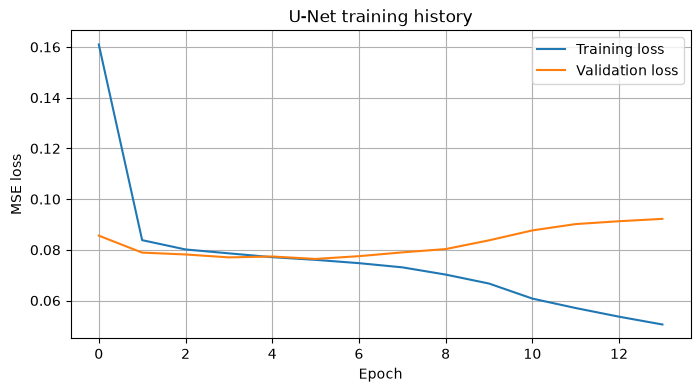

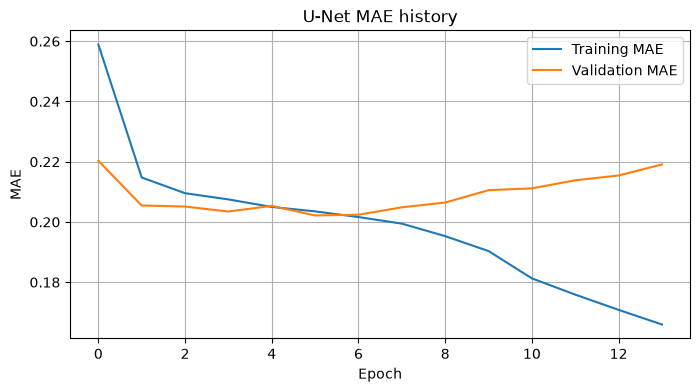

In [18]:
# =========================================================
# Plot training history
# =========================================================

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("U-Net training history")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("U-Net MAE history")
plt.legend()
plt.grid(True)
plt.show()


# 12. Save the Trained Model and Metadata

Same pattern as Stage 1: we save the model, the normalization statistics (already
saved in Stage 2, but copied alongside the model for convenience/traceability), and
a metadata file describing the experiment.


In [19]:
# =========================================================
# Save trained U-Net model and training metadata
# =========================================================

model_dir = MODELS_DIR
model_dir.mkdir(exist_ok=True)

model_name = "unet_u_temporal_evolution"

model_file = model_dir / f"{model_name}.keras"
run_metadata_file = model_dir / f"{model_name}_metadata.json"
run_normalization_file = model_dir / f"{model_name}_normalization.npz"

unet_model.save(model_file)
print("Model saved to:", model_file)

np.savez_compressed(
    run_normalization_file,
    channel_mean=channel_mean,
    channel_std=channel_std
)
print("Normalization statistics saved to:", run_normalization_file)

run_metadata = {
    "model_name": model_name,
    "model_file": str(model_file),

    "task": "u velocity field temporal evolution",
    "input": "u(y, x, t)",
    "output": "u(y, x, t + dt)",
    "snapshot_stride": dataset_metadata["snapshot_stride"],

    "input_shape": list(input_shape),

    "n_train_pairs": n_train_pairs,
    "n_val_pairs": n_val_pairs,
    "batch_size": batch_size,

    "baseline_mse": baseline_mse,
    "baseline_mae": baseline_mae,

    "final_training_loss": float(history.history["loss"][-1]),
    "final_validation_loss": float(history.history["val_loss"][-1]),
    "final_training_mae": float(history.history["mae"][-1]),
    "final_validation_mae": float(history.history["val_mae"][-1]),
}

with open(run_metadata_file, "w") as f:
    json.dump(run_metadata, f, indent=4)

print("\nRun metadata saved to:", run_metadata_file)


Model saved to: ../models/03_unet_temporal_evolution/unet_u_temporal_evolution.keras
Normalization statistics saved to: ../models/03_unet_temporal_evolution/unet_u_temporal_evolution_normalization.npz

Run metadata saved to: ../models/03_unet_temporal_evolution/unet_u_temporal_evolution_metadata.json


# 13. Load a Trained Model (Optional)

Reload the model and its normalization statistics without repeating training, useful
for coming back to evaluation (Sections 14-16) in a later session.


In [20]:
# =========================================================
# Load trained U-Net model
# =========================================================

model_file = model_dir / "unet_u_temporal_evolution.keras"
run_normalization_file = model_dir / "unet_u_temporal_evolution_normalization.npz"

loaded_unet = tf.keras.models.load_model(model_file)
print("Model loaded:", loaded_unet.name)

norm_data = np.load(run_normalization_file)
channel_mean = float(norm_data["channel_mean"])
channel_std = float(norm_data["channel_std"])

print("channel_mean:", channel_mean)
print("channel_std: ", channel_std)


Model loaded: UNet_Turbulent_Field_TemporalEvolution
channel_mean: 0.7847065935393341
channel_std:  0.34105365636854196


# 14. Evaluate on the Validation Set

We compare the U-Net against the persistence baseline computed in Section 8, using the
same `validation_steps` so both are evaluated on the same amount of data.


In [21]:
# =========================================================
# Evaluate U-Net on the validation set
# =========================================================

val_loss, val_mae = unet_model.evaluate(val_ds, steps=validation_steps)

print("U-Net validation loss (MSE):", val_loss)
print("U-Net validation MAE:       ", val_mae)

print("\nPersistence baseline MSE:", baseline_mse)
print("Persistence baseline MAE:", baseline_mae)

if val_mae < baseline_mae:
    print("\nThe U-Net improves on the persistence baseline.")
else:
    print("\nThe U-Net does not improve on the persistence baseline yet.")


  1/107 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 0.0880 - mae: 0.2139

  2/107 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0885 - mae: 0.2145

  6/107 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0879 - mae: 0.2140

  7/107 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0877 - mae: 0.2138

 11/107 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0868 - mae: 0.2130

 12/107 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0866 - mae: 0.2128

 16/107 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0859 - mae: 0.2122

 17/107 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0858 - mae: 0.2121

 21/107 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0852 - mae: 0.2116

 22/107 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0851 - mae: 0.2115

 26/107 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0846 - mae: 0.2111

 30/107 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0842 - mae: 0.2107

 34/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0839 - mae: 0.2104

 35/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0838 - mae: 0.2103

 39/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0835 - mae: 0.2100

 40/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0834 - mae: 0.2099

 44/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0831 - mae: 0.2096

 49/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0826 - mae: 0.2091

 53/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0823 - mae: 0.2087

 57/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0820 - mae: 0.2084

 61/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0817 - mae: 0.2081

 65/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0814 - mae: 0.2077

 69/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0811 - mae: 0.2074

 73/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0809 - mae: 0.2072

 77/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0807 - mae: 0.2069

 78/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0806 - mae: 0.2069

 82/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0805 - mae: 0.2067

 86/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0803 - mae: 0.2065

 87/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0803 - mae: 0.2064

 91/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0801 - mae: 0.2063

 92/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0801 - mae: 0.2062

 96/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0799 - mae: 0.2061

 97/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0799 - mae: 0.2060

101/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0798 - mae: 0.2059

105/107 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0797 - mae: 0.2057

107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0796 - mae: 0.2056


U-Net validation loss (MSE): 0.07641606777906418
U-Net validation MAE:        0.20215412974357605

Persistence baseline MSE: 0.16119435957344835
Persistence baseline MAE: 0.2895675136292835

The U-Net improves on the persistence baseline.


# 15. Predict One Validation Pair and Visualize

We predict one validation sample, convert back to physical units, and compare the
U-Net prediction against both the true target and the persistence baseline.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step


U-Net MAE on this sample:        0.06608531
Persistence MAE on this sample:  0.088592276


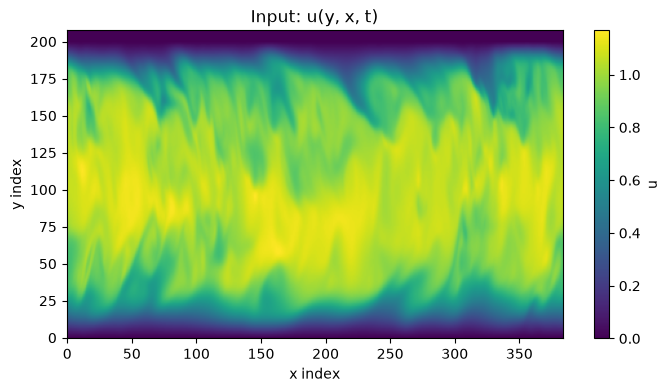

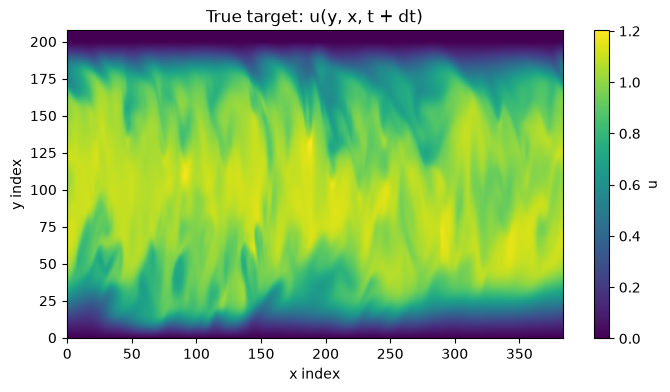

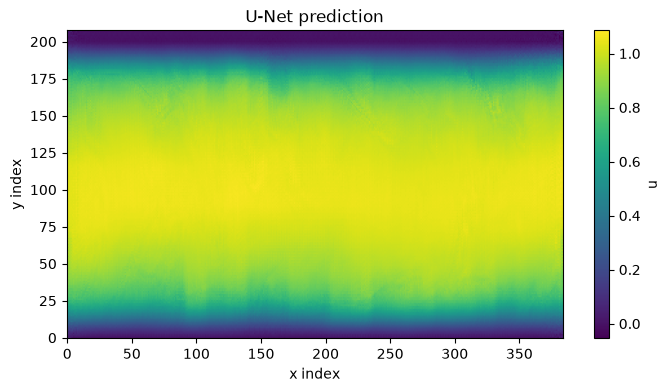

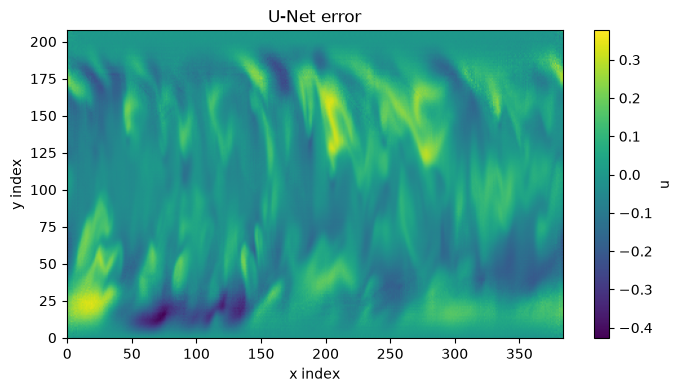

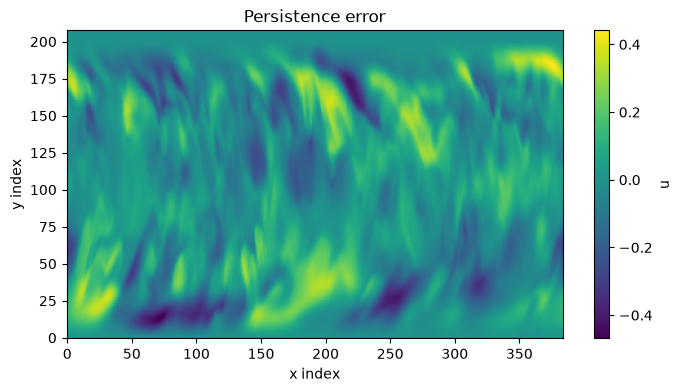

In [22]:
# =========================================================
# Predict one validation pair
# =========================================================

for batch_x, batch_y in val_ds.take(1):
    x_input_norm = batch_x[0:1]
    y_true_norm = batch_y[0:1]
    break

y_pred_norm = unet_model.predict(x_input_norm)

x_input = (x_input_norm.numpy() * channel_std + channel_mean)[0, :, :, 0]
y_true = (y_true_norm.numpy() * channel_std + channel_mean)[0, :, :, 0]
y_pred = y_pred_norm[0, :, :, 0] * channel_std + channel_mean

unet_error = y_pred - y_true
persistence_error = x_input - y_true

unet_mae_sample = np.mean(np.abs(unet_error))
persistence_mae_sample = np.mean(np.abs(persistence_error))

print("U-Net MAE on this sample:       ", unet_mae_sample)
print("Persistence MAE on this sample: ", persistence_mae_sample)

plots = [
    (x_input, "Input: u(y, x, t)"),
    (y_true, "True target: u(y, x, t + dt)"),
    (y_pred, "U-Net prediction"),
    (unet_error, "U-Net error"),
    (persistence_error, "Persistence error")
]

for field, title in plots:
    plt.figure(figsize=(8, 4))
    plt.imshow(field, origin="lower", aspect="auto")
    plt.colorbar(label="u")
    plt.xlabel("x index")
    plt.ylabel("y index")
    plt.title(title)
    plt.show()


# 16. Optional: Multi-Step Rollout

So far we only advanced the field **one step** (`t -> t + dt`). We can chain
predictions to advance it **several steps** into the future, by feeding each
prediction back in as the next input:

```text
u(t) -> U-Net -> u_hat(t + dt) -> U-Net -> u_hat(t + 2 dt) -> ...
```

This is the practical way this model would be used to "advance the turbulent field",
as opposed to just predicting a single step ahead. Errors typically accumulate with
each step, since the model is now consuming its own (imperfect) predictions instead of
ground-truth fields. We compare each rolled-out step against the true field, read
directly from the original HDF5 planes, whenever it is available on disk.

This section reads directly from the HDF5 planes (like Stage 2), not from the
TFRecords, since we need access to specific, individually addressable snapshots.


In [23]:
# =========================================================
# Utility functions needed to read raw HDF5 planes for the rollout
# (same as Stage 2, Sections 4-5)
# =========================================================

import h5py
import re


def read_velocity_plane_from_h5(h5_file, dtype=np.float32, add_channel=True):
    h5_file = Path(h5_file)
    with h5py.File(h5_file, "r") as f:
        u = f["u"][:].astype(dtype)
    field = u[..., np.newaxis] if add_channel else u
    return field.astype(np.float32)


def next_multiple(value, multiple):
    return int(np.ceil(value / multiple) * multiple)


def pad_field_to_multiple(field, multiple=16):
    n_y, n_x = field.shape[:2]
    n_y_padded = next_multiple(n_y, multiple)
    n_x_padded = next_multiple(n_x, multiple)
    pad_y = n_y_padded - n_y
    pad_x = n_x_padded - n_x
    padded = np.pad(field, pad_width=((0, pad_y), (0, pad_x), (0, 0)), mode="edge")
    return padded.astype(np.float32)


def crop_field_to_original_size(field, original_shape):
    n_y, n_x = original_shape
    return field[:n_y, :n_x, :]


In [24]:
# =========================================================
# Multi-step rollout: advance a field N steps into the future
# =========================================================

def rollout_temporal_prediction(
    unet_model,
    initial_field,
    channel_mean,
    channel_std,
    n_steps,
    padding_multiple=16
):
    """
    Repeatedly apply the U-Net to advance a field forward in time.

    Parameters
    ----------
    initial_field:
        High-resolution u field at the starting time, shape (n_y, n_x) or (n_y, n_x, 1).
    n_steps:
        Number of times to apply the model (each application advances one
        snapshot_stride in time).

    Returns
    -------
    predicted_fields:
        List of length n_steps, containing the predicted field after each
        step, cropped back to the original (unpadded) size.
    """

    initial_field = np.asarray(initial_field, dtype=np.float32)
    if initial_field.ndim == 2:
        initial_field = initial_field[..., np.newaxis]

    original_shape = initial_field.shape[:2]
    current_field = pad_field_to_multiple(initial_field, multiple=padding_multiple)

    predicted_fields = []

    for step in range(n_steps):

        current_norm = (current_field[np.newaxis, ...] - channel_mean) / channel_std
        next_norm = unet_model.predict(current_norm, verbose=0)
        next_field = next_norm[0] * channel_std + channel_mean

        predicted_fields.append(
            crop_field_to_original_size(next_field, original_shape)
        )

        # Feed the (padded) prediction back in as the next input.
        current_field = next_field

    return predicted_fields


# ---------------------------------------------------------
# Try it on one z-plane from the validation split
# ---------------------------------------------------------

pattern = re.compile(rf"^{re.escape(dataset_metadata['base_name'])}\.(\d+)\.(\d{{3}})\.h5$")
plane_files_all = []
for file_path in Path(tfrecords_dir).parent.glob("u_yx_planes_h5/*.h5"):
    match = pattern.match(file_path.name)
    if match:
        plane_files_all.append(
            {"snapshot_number": int(match.group(1)), "z_label": match.group(2), "file_path": file_path}
        )

z_label_to_use = plane_files_all[0]["z_label"]
same_z = sorted(
    [p for p in plane_files_all if p["z_label"] == z_label_to_use],
    key=lambda p: p["snapshot_number"]
)

n_steps = min(5, len(same_z) - 1)
start_item = same_z[0]

initial_field = read_velocity_plane_from_h5(start_item["file_path"], add_channel=True)

predicted_fields = rollout_temporal_prediction(
    unet_model,
    initial_field,
    channel_mean=channel_mean,
    channel_std=channel_std,
    n_steps=n_steps,
    padding_multiple=dataset_metadata["padding_multiple"]
)

print(f"Rolled out {n_steps} steps starting from snapshot {start_item['snapshot_number']}, z = {z_label_to_use}")


Rolled out 5 steps starting from snapshot 30000, z = 027


Step 1: predicted snapshot 30001, MAE = 0.065755
Step 2: predicted snapshot 30002, MAE = 0.081525
Step 3: predicted snapshot 30003, MAE = 0.087979
Step 4: predicted snapshot 30004, MAE = 0.094593
Step 5: predicted snapshot 30005, MAE = 0.091374


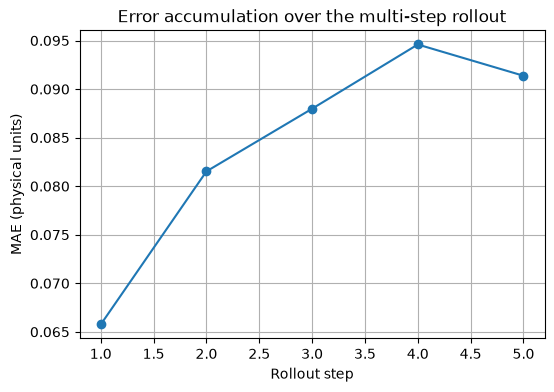

In [25]:
# =========================================================
# Compare each rollout step against the true field (error growth)
# =========================================================

step_maes = []

for step in range(n_steps):

    true_item = same_z[step + 1]
    true_field = read_velocity_plane_from_h5(true_item["file_path"], add_channel=True)

    pred_field = predicted_fields[step]

    step_mae = float(np.mean(np.abs(pred_field - true_field)))
    step_maes.append(step_mae)

    print(
        f"Step {step + 1}: predicted snapshot {true_item['snapshot_number']}, "
        f"MAE = {step_mae:.6f}"
    )

plt.figure(figsize=(6, 4))
plt.plot(range(1, n_steps + 1), step_maes, marker="o")
plt.xlabel("Rollout step")
plt.ylabel("MAE (physical units)")
plt.title("Error accumulation over the multi-step rollout")
plt.grid(True)
plt.show()


# 17. Experiments

## Experiment 1 — Change the snapshot stride

Try:

```python
snapshot_stride = 1   # (Stage 2)
snapshot_stride = 2
snapshot_stride = 5
```

Rebuild the TFRecords in Stage 2 for each value and retrain. How does a larger
`dt` affect the persistence baseline and the U-Net's advantage over it?

---

## Experiment 2 — Change the U-Net size

Try:

```python
base_filters = 8
base_filters = 16
base_filters = 32
```

Compare validation loss and validation MAE against the persistence baseline.

---

## Experiment 3 — Residual (delta) learning

The persistence baseline is already a decent predictor for small `dt`. A natural
improvement is to train the U-Net to predict only the **change** in the field:

```text
U-Net(u(t)) ≈ u(t + dt) - u(t)
```

and reconstruct the final prediction as:

```text
prediction = u(t) + predicted_delta
```

Modify `normalize_pair()` (or add a step after it) so the target becomes
`target_field - input_field`, and adjust Section 15/16 accordingly to add the
prediction back to the input. Compare against direct prediction.

---

## Experiment 4 — Rollout stability

Increase `n_steps` in Section 16 and plot the error growth curve for more steps.
Does the error grow smoothly, or does it blow up after a certain number of steps?
Try Experiment 3 (residual learning) and see whether it makes the rollout more stable.

---

## Experiment 5 — Shard count and shuffle buffer

In Stage 2, try a different `train_num_shards`, and in this notebook try a
different `shuffle_buffer` in `build_temporal_dataset()`. How do these choices affect
training speed and how "shuffled" the batches actually look?


# Experiment solutions
I solve the five experiments of Section 17 with this notebook's own pipeline (`build_temporal_dataset`, `make_parse_fn`, `normalize_pair`), model builder (`create_unet_temporal_model`), training settings (Adam 1e-4 with clipnorm 1, MSE, batch 8, early stopping patience 8, learning-rate halving patience 4) and rollout helpers (`read_velocity_plane_from_h5`, `pad_field_to_multiple`, `rollout_temporal_prediction`, `same_z`). Errors are validation MAE in normalised units unless stated.

**Reduced budget (once for all experiments).** One full training takes about a quarter of an hour, so every experiment model gets at most 5 epochs of 300 steps (2,400 pairs per epoch) on the Stage 2 TFRecords and is compared with a direct-prediction U-Net trained with the **same** reduced budget (`base_filters=16`), not with the fully trained main model. Experiment 1 needs pairs at other time strides, which the TFRecords do not hold, so it builds pairs in memory from the planes of every sixth z-plane.

In [26]:
import time, re, gc
import pandas as pd
from collections import defaultdict
ex_dir = EXERCISES_DIR; ex_dir.mkdir(exist_ok=True)
EX_EPOCHS, EX_STEPS = 5, 300
EX_VAL_STEPS = min(validation_steps, 100)
def ex_cbs():
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6)]
def ex_fit(model, tr, va, seed=0):
    tf.random.set_seed(seed); np.random.seed(seed); t0 = time.time()
    h = model.fit(tr, steps_per_epoch=EX_STEPS, validation_data=va, validation_steps=EX_VAL_STEPS, epochs=EX_EPOCHS, callbacks=ex_cbs(), verbose=0)
    return h, time.time() - t0
def ex_val_mae(model, va, residual=False):
    tot, n = 0.0, 0
    for bx, by in va.take(EX_VAL_STEPS):
        p = model(bx, training=False)
        if residual: p = bx + p
        tot += float(tf.reduce_sum(tf.abs(p - by))); n += int(tf.size(by))
    return tot / n
def ex_persistence_mae(va):
    tot, n = 0.0, 0
    for bx, by in va.take(EX_VAL_STEPS):
        tot += float(tf.reduce_sum(tf.abs(by - bx))); n += int(tf.size(by))
    return tot / n
ex_pers = ex_persistence_mae(val_ds)
ex_ref = create_unet_temporal_model(input_shape=input_shape, output_channels=channels, base_filters=16, dropout_rate=0.0, learning_rate=1e-4)
_, ex_ref_t = ex_fit(ex_ref, train_ds, val_ds); ex_ref_mae = ex_val_mae(ex_ref, val_ds)
print(f"reduced-budget direct U-Net (16 filters): validation MAE {ex_ref_mae:.4f} in {ex_ref_t:.0f} s; persistence {ex_pers:.4f}")

2026-10-13 05:14:07.945906: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


reduced-budget direct U-Net (16 filters): validation MAE 0.2032 in 174 s; persistence 0.2901


## Experiment 1 — solution
Instead of rebuilding the 3.62 GB of TFRecords three times I build an equivalent in-memory dataset on a subset: the planes of every sixth z-plane (10 of 60), padded and normalised exactly as in Stage 2, paired at snapshot strides 1, 2 and 5 within each z-plane, with an 85/15 split by pair. For each stride I train a 16-filter U-Net with the reduced budget and compare it with persistence on the same pairs.

In [27]:
ex_planes_dir = Path(tfrecords_dir).parent / "u_yx_planes_h5"
ex_by_z = defaultdict(dict)
for fp in ex_planes_dir.glob("*.h5"):
    mt = re.match(rf"^{re.escape(dataset_metadata['base_name'])}\.(\d+)\.(\d{{3}})\.h5$", fp.name)
    if mt: ex_by_z[int(mt.group(2))][int(mt.group(1))] = fp
ex_zs = sorted(ex_by_z)[::6]
ex_fields = {z: {s: pad_field_to_multiple(read_velocity_plane_from_h5(f), 16) for s, f in sorted(ex_by_z[z].items())} for z in ex_zs}
ex1_rows = []
for stride in (1, 2, 5):
    X, Y = [], []
    for z, snaps_ in ex_fields.items():
        keys = sorted(snaps_)
        for s0 in keys:
            if s0 + stride in snaps_: X.append(snaps_[s0]); Y.append(snaps_[s0 + stride])
    X = (np.stack(X) - channel_mean) / channel_std; Y = (np.stack(Y) - channel_mean) / channel_std
    rng = np.random.default_rng(0); idx = rng.permutation(len(X)); ntr = int(0.85 * len(X))
    tr = tf.data.Dataset.from_tensor_slices((X[idx[:ntr]], Y[idx[:ntr]])).cache().shuffle(200, seed=0).repeat().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    va = tf.data.Dataset.from_tensor_slices((X[idx[ntr:]], Y[idx[ntr:]])).cache().repeat().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    m = create_unet_temporal_model(input_shape=input_shape, output_channels=channels, base_filters=16, dropout_rate=0.0, learning_rate=1e-4)
    _, t = ex_fit(m, tr, va)
    ex1_rows.append(dict(stride=stride, n_pairs=len(X), persistence_mae=ex_persistence_mae(va), unet_mae=ex_val_mae(m, va), train_s=round(t)))
    del X, Y, tr, va, m; gc.collect()
ex1 = pd.DataFrame(ex1_rows); ex1["unet_over_persistence"] = ex1.unet_mae / ex1.persistence_mae
ex1.to_csv(ex_dir / "ex1_stride.csv", index=False); print(ex1)
print("Result (Exercise 1): validation MAE U-Net / persistence (normalised): " + "; ".join(f"stride {r.stride}: {r.unet_mae:.3f} / {r.persistence_mae:.3f} (ratio {r.unet_over_persistence:.2f})" for r in ex1.itertuples()) + " — 10 of 60 z-planes, reduced budget")

2026-10-13 05:22:59.125874: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


   stride  n_pairs  persistence_mae  unet_mae  train_s  unet_over_persistence
0       1      990         0.287064  0.206903      174               0.720758
1       2      976         0.288548  0.213937      173               0.741425
2       5      935         0.292178  0.213146      173               0.729507
Result (Exercise 1): validation MAE U-Net / persistence (normalised): stride 1: 0.207 / 0.287 (ratio 0.72); stride 2: 0.214 / 0.289 (ratio 0.74); stride 5: 0.213 / 0.292 (ratio 0.73) — 10 of 60 z-planes, reduced budget


## Experiment 2 — solution
U-Nets with 8 and 32 base filters (16 is the reference trained above), on the Stage 2 TFRecords, reduced budget.

In [28]:
ex2_rows = [dict(base_filters=16, params=ex_ref.count_params(), val_mae=ex_ref_mae, train_s=round(ex_ref_t))]
for bf in (8, 32):
    m = create_unet_temporal_model(input_shape=input_shape, output_channels=channels, base_filters=bf, dropout_rate=0.0, learning_rate=1e-4)
    _, t = ex_fit(m, train_ds, val_ds); ex2_rows.append(dict(base_filters=bf, params=m.count_params(), val_mae=ex_val_mae(m, val_ds), train_s=round(t)))
    del m; gc.collect()
ex2 = pd.DataFrame(ex2_rows).sort_values("base_filters"); ex2["persistence_mae"] = ex_pers; ex2.to_csv(ex_dir / "ex2_unet_size.csv", index=False); print(ex2)
print("Result (Exercise 2): validation MAE " + "; ".join(f"{r.base_filters} filters ({r.params:,} params, {r.train_s} s): {r.val_mae:.4f}" for r in ex2.itertuples()) + f"; persistence {ex_pers:.4f} — reduced budget")

   base_filters   params   val_mae  train_s  persistence_mae
1             8   485673  0.211108      161         0.290053
0            16  1940817  0.203171      174         0.290053
2            32  7759521  0.207769      232         0.290053
Result (Exercise 2): validation MAE 8 filters (485,673 params, 161 s): 0.2111; 16 filters (1,940,817 params, 174 s): 0.2032; 32 filters (7,759,521 params, 232 s): 0.2078; persistence 0.2901 — reduced budget


## Experiment 3 — solution
Residual learning: an extra `map` after `normalize_pair` turns the target into `target - input`, and the prediction is reconstructed as `input + predicted delta`. Same 16-filter U-Net and reduced budget as the direct reference.

In [29]:
def ex_residual(ds): return ds.map(lambda x, y: (x, y - x), num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
ex_res = create_unet_temporal_model(input_shape=input_shape, output_channels=channels, base_filters=16, dropout_rate=0.0, learning_rate=1e-4)
_, ex_res_t = ex_fit(ex_res, ex_residual(train_ds), ex_residual(val_ds))
ex_res_mae = ex_val_mae(ex_res, val_ds, residual=True)
pd.DataFrame([dict(model="direct", val_mae=ex_ref_mae), dict(model="residual (input + delta)", val_mae=ex_res_mae), dict(model="persistence", val_mae=ex_pers)]).to_csv(ex_dir / "ex3_residual.csv", index=False)
print(f"Result (Exercise 3): validation MAE direct {ex_ref_mae:.4f} vs residual {ex_res_mae:.4f} vs persistence {ex_pers:.4f} — same reduced budget")

Result (Exercise 3): validation MAE direct 0.2032 vs residual 0.2058 vs persistence 0.2901 — same reduced budget


## Experiment 4 — solution
Rollouts of 30 steps from the start of the z-plane used in Section 16, for the fully trained main model (`unet_model`), the reduced-budget direct and residual models, and persistence, with the MAE (physical units) against the true planes at every step.

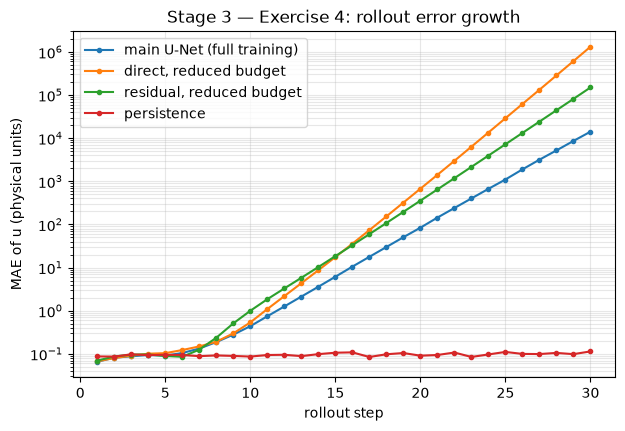

Result (Exercise 4): MAE after 1 / 10 / 30 steps: main U-Net (full training): 0.066 / 0.439 / 14141.783; direct, reduced budget: 0.067 / 0.537 / 1316857.250; residual, reduced budget: 0.070 / 0.999 / 149739.531; persistence: 0.087 / 0.087 / 0.114


In [30]:
ex4_steps = min(30, len(same_z) - 1)
ex4_init = read_velocity_plane_from_h5(same_z[0]["file_path"], add_channel=True)
ex4_truth = [read_velocity_plane_from_h5(same_z[k + 1]["file_path"], add_channel=True) for k in range(ex4_steps)]
class ExResidualWrap:
    def __init__(self, m): self.m = m
    def predict(self, x, verbose=0): return x + self.m.predict(x, verbose=0)
ex4 = {"main U-Net (full training)": unet_model, "direct, reduced budget": ex_ref, "residual, reduced budget": ExResidualWrap(ex_res)}
ex4_curves = {k: [float(np.mean(np.abs(p - t))) for p, t in zip(rollout_temporal_prediction(m, ex4_init, channel_mean, channel_std, ex4_steps), ex4_truth)] for k, m in ex4.items()}
ex4_curves["persistence"] = [float(np.mean(np.abs(ex4_init - t))) for t in ex4_truth]
ex4_df = pd.DataFrame(ex4_curves); ex4_df.index = np.arange(1, ex4_steps + 1); ex4_df.to_csv(ex_dir / "ex4_rollout.csv", index_label="step")
ex4_df.plot(marker="o", ms=3, figsize=(7, 4.5), logy=True); plt.xlabel("rollout step"); plt.ylabel("MAE of u (physical units)"); plt.grid(alpha=0.3, which="both")
plt.title("Stage 3 — Exercise 4: rollout error growth"); plt.savefig(ex_dir / "ex4_rollout.png", dpi=110); plt.show()
print("Result (Exercise 4): MAE after 1 / 10 / " + str(ex4_steps) + " steps: " + "; ".join(f"{k}: {v[0]:.3f} / {v[min(9, ex4_steps-1)]:.3f} / {v[-1]:.3f}" for k, v in ex4_curves.items()))

## Experiment 5 — solution
Two measurements without retraining. (a) **Shuffle quality:** for shuffle buffers of 0 (none), 200 (the notebook's) and 2,000 records (three configurations), the training pipeline is read with the pair metadata (`snapshot_t`, `z_label`) and the mean absolute difference of `snapshot_t` between consecutive records is reported (large = well mixed), together with the number of distinct z-planes per batch of 8. (b) **Shard count:** a fixed set of 1,600 training records is rewritten into 2 and into 16 shards in a scratch folder and read back with the notebook's interleave pattern; the read throughput (records per second) is reported.

In [31]:
ex5_desc = {"snapshot_t": tf.io.FixedLenFeature([], tf.int64), "z_label": tf.io.FixedLenFeature([], tf.string)}
def ex_meta_stream(buffer):
    files = tf.data.Dataset.list_files(train_file_pattern, shuffle=True, seed=0)
    ds = files.interleave(tf.data.TFRecordDataset, cycle_length=tf.data.AUTOTUNE, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda r: tf.io.parse_single_example(r, ex5_desc), num_parallel_calls=tf.data.AUTOTUNE)
    if buffer: ds = ds.shuffle(buffer, seed=0)
    return ds.take(2400).batch(batch_size).prefetch(tf.data.AUTOTUNE)
ex5a = []
for buf in (0, 200, 2000):
    t0 = time.time(); snaps_, zs_ = [], []
    for b in ex_meta_stream(buf):
        snaps_.extend(b["snapshot_t"].numpy().tolist()); zs_.append(len(set(b["z_label"].numpy().tolist())))
    ex5a.append(dict(shuffle_buffer=buf, mean_abs_dsnapshot=float(np.mean(np.abs(np.diff(snaps_)))), distinct_z_per_batch=float(np.mean(zs_)), read_s=round(time.time() - t0, 1)))
ex5a = pd.DataFrame(ex5a); ex5a.to_csv(ex_dir / "ex5a_shuffle_buffer.csv", index=False); print(ex5a)
ex5_scratch = DATA_DIR / "ex5_shards"; ex5_scratch.mkdir(exist_ok=True)
ex5_records = [r.numpy() for r in tf.data.TFRecordDataset(tf.io.gfile.glob(train_file_pattern)[:2]).take(1600)]
ex5b = []
for n_sh in (2, 16):
    for f in ex5_scratch.glob("*.tfrecord"): f.unlink()
    writers = [tf.io.TFRecordWriter(str(ex5_scratch / f"s{n_sh}-{k:02d}.tfrecord")) for k in range(n_sh)]
    for i, r in enumerate(ex5_records): writers[i % n_sh].write(r)
    for w in writers: w.close()
    ds = tf.data.Dataset.list_files(str(ex5_scratch / f"s{n_sh}-*.tfrecord"), shuffle=True, seed=0).interleave(tf.data.TFRecordDataset, cycle_length=tf.data.AUTOTUNE, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(make_parse_fn(padded_height, padded_width, channels), num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    t0 = time.time(); n = sum(int(bx.shape[0]) for bx, _ in ds); t = time.time() - t0
    ex5b.append(dict(shards=n_sh, records=n, read_s=round(t, 2), records_per_s=round(n / t)))
for f in ex5_scratch.glob("*.tfrecord"): f.unlink()
ex5b = pd.DataFrame(ex5b); ex5b.to_csv(ex_dir / "ex5b_shard_count.csv", index=False); print(ex5b)
print("Result (Exercise 5): mean |Δ snapshot| between consecutive records for shuffle buffer 0 / 200 / 2000: " + " / ".join(f"{v:.1f}" for v in ex5a.mean_abs_dsnapshot)
      + "; read throughput 2 vs 16 shards: " + " vs ".join(f"{v} records/s" for v in ex5b.records_per_s))

2026-10-13 05:35:41.694631: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


   shuffle_buffer  mean_abs_dsnapshot  distinct_z_per_batch  read_s
0               0            7.738224              1.140000     0.1
1             200           31.214673              4.923333     0.1
2            2000           30.002918              7.473333     0.2


   shards  records  read_s  records_per_s
0       2     1203    0.15           7879
1      16     1203    0.08          14316
Result (Exercise 5): mean |Δ snapshot| between consecutive records for shuffle buffer 0 / 200 / 2000: 7.7 / 31.2 / 30.0; read throughput 2 vs 16 shards: 7879 records/s vs 14316 records/s


## Summary of the experiment solutions
The numbers are those printed in the `Result` lines above (all experiment models with the reduced budget stated at the top); the tables and figures are in the experiments results folder.

# Animation — the U-Net learning to advance the field
The snapshots come from the main training itself (the hook before the training cell; no second run): after every epoch the prediction for one fixed validation pair and the training and validation losses. The dashboard video and its last frame go to the animations folder (`03_training_dashboard.mp4`, `03_final_frame.png`).

In [32]:
import pickle
from matplotlib.animation import FuncAnimation, FFMpegWriter
import imageio_ffmpeg
plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
anim_dir = ANIM_DIR; anim_dir.mkdir(exist_ok=True)
anim_cb = ANIM_CB
pickle.dump(anim_cb.snaps, open(anim_dir / f"{ANIM_PREFIX}snapshots.pkl", "wb"))
print(f"Main training: {len(anim_cb.snaps)-1} epochs, best validation loss {min(anim_cb.val):.4f}; persistence MSE {baseline_mse:.4f}")

Main training: 14 epochs, best validation loss 0.0764; persistence MSE 0.1612


In [33]:
snaps = anim_cb.snaps; xin = anim_x.numpy()[0, :, :, 0]; yt = anim_y[0, :, :, 0]; vmin, vmax = np.percentile(yt, [1, 99])
allv = snaps[-1]["loss"] + snaps[-1]["val"]
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
def anim_draw(k):
    s_ = snaps[k]
    for a in axes.ravel(): a.clear()
    axes[0, 0].imshow(yt, origin="lower", cmap="RdBu_r", vmin=vmin, vmax=vmax, aspect="auto"); axes[0, 0].set_title("True u(y, x, t + dt) (normalised)")
    axes[0, 1].imshow(s_["pred"], origin="lower", cmap="RdBu_r", vmin=vmin, vmax=vmax, aspect="auto"); axes[0, 1].set_title(f"U-Net prediction, epoch {s_['epoch']}")
    e_u = np.abs(s_["pred"] - yt); e_p = np.abs(xin - yt)
    axes[1, 0].imshow(e_u, origin="lower", cmap="magma", vmin=0, vmax=np.percentile(e_p, 99), aspect="auto")
    axes[1, 0].set_title(f"|U-Net error| (mean {e_u.mean():.3f}; persistence {e_p.mean():.3f})")
    e = np.arange(1, len(s_["loss"]) + 1)
    axes[1, 1].plot(e, s_["loss"], "o-", label="training MSE"); axes[1, 1].plot(e, s_["val"], "o-", label="validation MSE"); axes[1, 1].axhline(baseline_mse, color="k", ls=":", label="persistence")
    axes[1, 1].set_xlim(0, max(12, snaps[-1]["epoch"])); axes[1, 1].set_ylim(0, max(allv + [baseline_mse]) * 1.1); axes[1, 1].set_xlabel("epoch"); axes[1, 1].legend(); axes[1, 1].grid(alpha=0.3)
    fig.suptitle("Stage 3 — U-Net advancing the channel-flow field by one snapshot: main training"); fig.tight_layout()
anim_draw(len(snaps) - 1); fig.savefig(anim_dir / f"{ANIM_PREFIX}final_frame.png", dpi=100)
FuncAnimation(fig, anim_draw, frames=len(snaps)).save(anim_dir / f"{ANIM_PREFIX}training_dashboard.mp4", writer=FFMpegWriter(fps=2, bitrate=2000), dpi=90)
plt.close(fig); print(f"Animation: {len(snaps)} frames written")

Animation: 15 frames written


**What the animation shows.** Top: the true next field of one validation pair and the U-Net's prediction after each epoch. Bottom left: the absolute error of the prediction, on the same colour scale as the persistence error so the two can be compared. Bottom right: training and validation loss against the persistence baseline (dotted).

# Three-seed repeats
I repeat every training with the seeds 1 and 2; seed 0 is the run above. For the main training of Section 11 the seed sets TensorFlow's global seed before the model is built (the notebook sets seed 0 in its import cell) and the shuffle of the training stream (`build_temporal_dataset_s` is `build_temporal_dataset` with the seed as an argument; the notebook's own builder shuffles with seed 0). I evaluate the seed models as in Sections 14 and 16 and save them next to the main model. The experiment trainings are repeated the same way with their reduced budget; the data, the split and the budget stay the same. Each row is one training; the summary gives the mean and the standard deviation over the three seeds. The `seeds_*.csv` tables and `seeds_summary.png` go to the experiments results folder.

In [34]:
import time, gc
import pandas as pd
SEEDS = (0, 1, 2)
def build_temporal_dataset_s(file_pattern, height, width, channels, channel_mean, channel_std, batch_size=8, shuffle=False, shuffle_buffer=200, seed=0):
    file_paths = tf.data.Dataset.list_files(file_pattern, shuffle=shuffle, seed=seed)
    dataset = file_paths.interleave(tf.data.TFRecordDataset, cycle_length=tf.data.AUTOTUNE, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.map(make_parse_fn(height=height, width=width, channels=channels), num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.map(lambda x, y: normalize_pair(x, y, channel_mean, channel_std), num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        dataset = dataset.shuffle(buffer_size=shuffle_buffer, seed=seed)
    return dataset.repeat().batch(batch_size).prefetch(tf.data.AUTOTUNE)

def rollout_maes(model, n=5):
    preds = rollout_temporal_prediction(model, initial_field, channel_mean=channel_mean, channel_std=channel_std, n_steps=n,
                                        padding_multiple=dataset_metadata["padding_multiple"])
    return [float(np.mean(np.abs(preds[k] - read_velocity_plane_from_h5(same_z[k + 1]["file_path"], add_channel=True)))) for k in range(n)]

main_rows = []
l0, a0 = unet_model.evaluate(val_ds, steps=validation_steps, verbose=0)
main_rows.append(dict(seed=0, epochs=len(history.history["loss"]), best_epoch=int(np.argmin(history.history["val_loss"])) + 1,
                      val_mse=l0, val_mae=a0, minutes=np.nan, **{f"rollout_mae_{k+1}": v for k, v in enumerate(rollout_maes(unet_model))}))
def run_seed(seed):
    tf.random.set_seed(seed); np.random.seed(seed)
    tr_s = build_temporal_dataset_s(train_file_pattern, padded_height, padded_width, channels, channel_mean, channel_std,
                                    batch_size=batch_size, shuffle=True, shuffle_buffer=200, seed=seed)
    m_s = create_unet_temporal_model(input_shape=input_shape, output_channels=channels, base_filters=16, dropout_rate=0.0, learning_rate=1e-4)
    cb_s = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6)]
    t0 = time.time()
    h_s = m_s.fit(tr_s, steps_per_epoch=steps_per_epoch, validation_data=val_ds, validation_steps=validation_steps, epochs=50, callbacks=cb_s, verbose=0)
    dt = time.time() - t0
    l_s, a_s = m_s.evaluate(val_ds, steps=validation_steps, verbose=0)
    m_s.save(MODELS_DIR / f"unet_u_temporal_evolution_seed{seed}.keras")
    main_rows.append(dict(seed=seed, epochs=len(h_s.history["loss"]), best_epoch=int(np.argmin(h_s.history["val_loss"])) + 1,
                          val_mse=l_s, val_mae=a_s, minutes=round(dt / 60, 1), **{f"rollout_mae_{k+1}": v for k, v in enumerate(rollout_maes(m_s))}))
    print(main_rows[-1], flush=True)
    del m_s, tr_s; gc.collect()


In [35]:
run_seed(1)   # main training with seed 1

{'seed': 1, 'epochs': 13, 'best_epoch': 5, 'val_mse': 0.07593948394060135, 'val_mae': 0.20402266085147858, 'minutes': 14.9, 'rollout_mae_1': 0.06802237033843994, 'rollout_mae_2': 0.08812786638736725, 'rollout_mae_3': 0.09902077168226242, 'rollout_mae_4': 0.10768908262252808, 'rollout_mae_5': 0.10672684013843536}


In [36]:
run_seed(2)   # main training with seed 2
seeds_main = pd.DataFrame(main_rows); seeds_main.to_csv(ex_dir / "seeds_main_runs.csv", index=False)
print(seeds_main.round(5).to_string())
print(f"Persistence on the same validation stream: MSE {baseline_mse:.4f}, MAE {baseline_mae:.4f}")

{'seed': 2, 'epochs': 16, 'best_epoch': 8, 'val_mse': 0.07613343745470047, 'val_mae': 0.20152561366558075, 'minutes': 18.2, 'rollout_mae_1': 0.0638357475399971, 'rollout_mae_2': 0.07728549093008041, 'rollout_mae_3': 0.08540338277816772, 'rollout_mae_4': 0.08988698571920395, 'rollout_mae_5': 0.08578044921159744}


   seed  epochs  best_epoch  val_mse  val_mae  minutes  rollout_mae_1  rollout_mae_2  rollout_mae_3  rollout_mae_4  rollout_mae_5
0     0      14           6  0.07642  0.20215      NaN        0.06575        0.08152        0.08798        0.09459        0.09137
1     1      13           5  0.07594  0.20402     14.9        0.06802        0.08813        0.09902        0.10769        0.10673
2     2      16           8  0.07613  0.20153     18.2        0.06384        0.07729        0.08540        0.08989        0.08578
Persistence on the same validation stream: MSE 0.1612, MAE 0.2896


In [37]:
# Exercise trainings with seeds 1 and 2 (seed 0 = the exercise cells above)
def ex_fit_s(model_fn, tr, va, seed):
    tf.random.set_seed(seed); np.random.seed(seed)
    m = model_fn(); t0 = time.time()
    m.fit(tr, steps_per_epoch=EX_STEPS, validation_data=va, validation_steps=EX_VAL_STEPS, epochs=EX_EPOCHS, callbacks=ex_cbs(), verbose=0)
    return m, time.time() - t0
mk = lambda bf=16: (lambda: create_unet_temporal_model(input_shape=input_shape, output_channels=channels, base_filters=bf, dropout_rate=0.0, learning_rate=1e-4))
ex_rows = [dict(variant="direct, 16 filters", seed=0, val_mae=ex_ref_mae, persistence_mae=ex_pers, train_s=round(ex_ref_t)),
           dict(variant="residual, 16 filters", seed=0, val_mae=ex_res_mae, persistence_mae=ex_pers, train_s=round(ex_res_t))]
for r in ex2.itertuples():
    if r.base_filters != 16: ex_rows.append(dict(variant=f"direct, {r.base_filters} filters", seed=0, val_mae=r.val_mae, persistence_mae=ex_pers, train_s=r.train_s))
for r in ex1.itertuples():
    ex_rows.append(dict(variant=f"stride {r.stride}", seed=0, val_mae=r.unet_mae, persistence_mae=r.persistence_mae, train_s=r.train_s))
ex_seed_models = {0: {"direct": ex_ref, "residual": ex_res}}
def run_seed(seed):
    tr_s = build_temporal_dataset_s(train_file_pattern, padded_height, padded_width, channels, channel_mean, channel_std,
                                    batch_size=batch_size, shuffle=True, shuffle_buffer=200, seed=seed)
    m, t = ex_fit_s(mk(16), tr_s, val_ds, seed)
    ex_rows.append(dict(variant="direct, 16 filters", seed=seed, val_mae=ex_val_mae(m, val_ds), persistence_mae=ex_pers, train_s=round(t)))
    mr, t = ex_fit_s(mk(16), ex_residual(tr_s), ex_residual(val_ds), seed)
    ex_rows.append(dict(variant="residual, 16 filters", seed=seed, val_mae=ex_val_mae(mr, val_ds, residual=True), persistence_mae=ex_pers, train_s=round(t)))
    ex_seed_models[seed] = {"direct": m, "residual": mr}
    for bf in (8, 32):
        mb, t = ex_fit_s(mk(bf), tr_s, val_ds, seed)
        ex_rows.append(dict(variant=f"direct, {bf} filters", seed=seed, val_mae=ex_val_mae(mb, val_ds), persistence_mae=ex_pers, train_s=round(t)))
        del mb; gc.collect()
    for stride in (1, 2, 5):
        X, Y = [], []
        for z, snaps_ in ex_fields.items():
            for s0 in sorted(snaps_):
                if s0 + stride in snaps_: X.append(snaps_[s0]); Y.append(snaps_[s0 + stride])
        X = (np.stack(X) - channel_mean) / channel_std; Y = (np.stack(Y) - channel_mean) / channel_std
        rng = np.random.default_rng(0); idx = rng.permutation(len(X)); ntr = int(0.85 * len(X))   # same split as the exercise cell
        tr = tf.data.Dataset.from_tensor_slices((X[idx[:ntr]], Y[idx[:ntr]])).cache().shuffle(200, seed=seed).repeat().batch(batch_size).prefetch(tf.data.AUTOTUNE)
        va = tf.data.Dataset.from_tensor_slices((X[idx[ntr:]], Y[idx[ntr:]])).cache().repeat().batch(batch_size).prefetch(tf.data.AUTOTUNE)
        ms, t = ex_fit_s(mk(16), tr, va, seed)
        ex_rows.append(dict(variant=f"stride {stride}", seed=seed, val_mae=ex_val_mae(ms, va), persistence_mae=ex_persistence_mae(va), train_s=round(t)))
        del X, Y, tr, va, ms; gc.collect()
    pd.DataFrame(ex_rows).to_csv(ex_dir / "seeds_exercise_runs.csv", index=False)
    print(f"seed {seed}: exercise trainings done", flush=True)


In [38]:
run_seed(1)   # seven exercise trainings with seed 1

seed 1: exercise trainings done


In [39]:
run_seed(2)   # seven exercise trainings with seed 2
seeds_ex = pd.DataFrame(ex_rows); seeds_ex["unet_over_persistence"] = seeds_ex.val_mae / seeds_ex.persistence_mae
seeds_ex.to_csv(ex_dir / "seeds_exercise_runs.csv", index=False); print(seeds_ex.round(4).to_string())

2026-10-13 06:37:17.468744: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


seed 2: exercise trainings done


                 variant  seed  val_mae  persistence_mae  train_s  unet_over_persistence
0     direct, 16 filters     0   0.2032           0.2901      174                 0.7005
1   residual, 16 filters     0   0.2058           0.2901      177                 0.7095
2      direct, 8 filters     0   0.2111           0.2901      161                 0.7278
3     direct, 32 filters     0   0.2078           0.2901      232                 0.7163
4               stride 1     0   0.2069           0.2871      174                 0.7208
5               stride 2     0   0.2139           0.2885      173                 0.7414
6               stride 5     0   0.2131           0.2922      173                 0.7295
7     direct, 16 filters     1   0.2026           0.2901      194                 0.6985
8   residual, 16 filters     1   0.2046           0.2901      192                 0.7055
9      direct, 8 filters     1   0.2136           0.2901      166                 0.7363
10    direct, 32 filt

In [40]:
# Rollouts of Exercise 4 with every seed model (main models and reduced-budget direct and residual models)
ex4_seed_curves = []
for seed in SEEDS:
    main_m = unet_model if seed == 0 else tf.keras.models.load_model(MODELS_DIR / f"unet_u_temporal_evolution_seed{seed}.keras")
    for name, m in (("main training", main_m), ("direct, reduced budget", ex_seed_models[seed]["direct"]),
                    ("residual, reduced budget", ExResidualWrap(ex_seed_models[seed]["residual"]))):
        maes = [float(np.mean(np.abs(p - t))) for p, t in zip(rollout_temporal_prediction(m, ex4_init, channel_mean, channel_std, ex4_steps), ex4_truth)]
        ex4_seed_curves += [dict(model=name, seed=seed, step=k + 1, mae=v) for k, v in enumerate(maes)]
ex4_seed_curves += [dict(model="persistence", seed=s, step=k + 1, mae=v) for s in SEEDS for k, v in enumerate(ex4_curves["persistence"])]
ex4_seeds = pd.DataFrame(ex4_seed_curves); ex4_seeds.to_csv(ex_dir / "seeds_ex4_rollout.csv", index=False)
ex4_first_loss = {}
for (name, seed), g in ex4_seeds[ex4_seeds.model != "persistence"].groupby(["model", "seed"]):
    worse = g.set_index("step").mae > np.array(ex4_curves["persistence"])
    ex4_first_loss[(name, seed)] = int(worse.idxmax()) if worse.any() else None
print("First rollout step at which the U-Net's MAE exceeds persistence:", ex4_first_loss)

First rollout step at which the U-Net's MAE exceeds persistence: {('direct, reduced budget', 0): 4, ('direct, reduced budget', 1): 4, ('direct, reduced budget', 2): 4, ('main training', 0): 4, ('main training', 1): 2, ('main training', 2): 7, ('residual, reduced budget', 0): 2, ('residual, reduced budget', 1): 3, ('residual, reduced budget', 2): 5}


                   mean      std
val_mse         0.07616  0.00024
val_mae         0.20257  0.00130
epochs         14.33333  1.52753
best_epoch      6.33333  1.52753
rollout_mae_1   0.06587  0.00210
rollout_mae_2   0.08231  0.00546
rollout_mae_3   0.09080  0.00723
rollout_mae_4   0.09739  0.00922
rollout_mae_5   0.09463  0.01085
                      val_mae_mean  val_mae_std  persistence_mae_mean  persistence_mae_std  unet_over_persistence_mean  unet_over_persistence_std  train_s_mean  train_s_std
variant                                                                                                                                                                     
direct, 16 filters          0.2037       0.0014                0.2901                  0.0                      0.7023                     0.0049      182.6667      10.2632
residual, 16 filters        0.2048       0.0009                0.2901                  0.0                      0.7062                     0.0030      

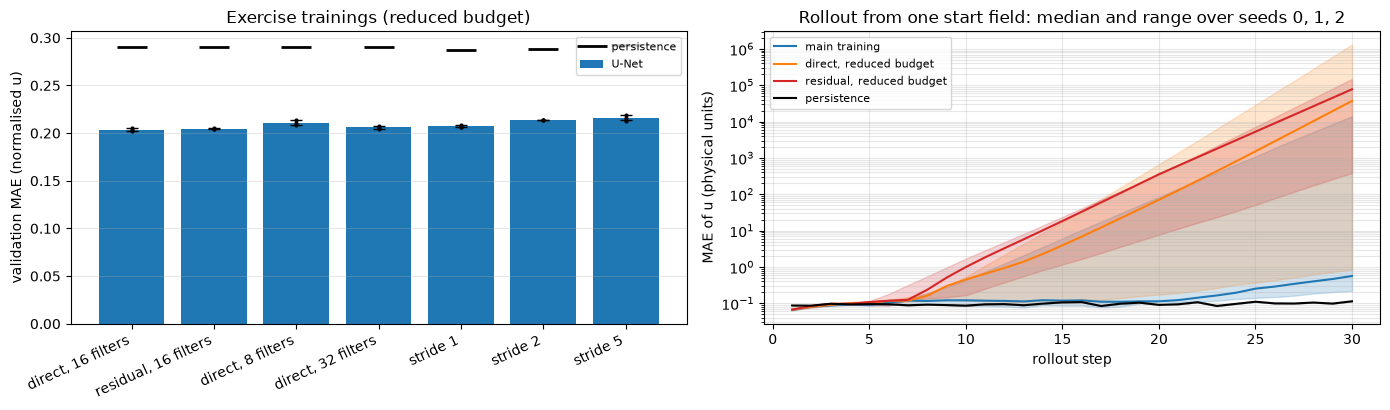

Result (three seeds): main training validation MSE 0.0762 ± 0.0002, MAE 0.2026 ± 0.0013; direct, 16 filters: 0.2037 ± 0.0014 (persistence 0.2901); residual, 16 filters: 0.2048 ± 0.0009 (persistence 0.2901); direct, 8 filters: 0.2110 ± 0.0025 (persistence 0.2901); direct, 32 filters: 0.2059 ± 0.0019 (persistence 0.2901); stride 1: 0.2073 ± 0.0008 (persistence 0.2871); stride 2: 0.2137 ± 0.0002 (persistence 0.2885); stride 5: 0.2161 ± 0.0028 (persistence 0.2922)


In [41]:
seeds_ex_summ = seeds_ex.groupby("variant", sort=False)[["val_mae", "persistence_mae", "unet_over_persistence", "train_s"]].agg(["mean", "std"])
seeds_ex_summ.columns = [f"{a}_{b}" for a, b in seeds_ex_summ.columns]
seeds_main_summ = seeds_main[["val_mse", "val_mae", "epochs", "best_epoch"] + [f"rollout_mae_{k}" for k in range(1, 6)]].agg(["mean", "std"]).T
seeds_ex_summ.to_csv(ex_dir / "seeds_exercise_summary.csv"); seeds_main_summ.to_csv(ex_dir / "seeds_main_summary.csv")
print(seeds_main_summ.round(5).to_string()); print(seeds_ex_summ.round(4).to_string())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
order = list(seeds_ex_summ.index); x = np.arange(len(order))
axes[0].bar(x, seeds_ex_summ["val_mae_mean"], yerr=seeds_ex_summ["val_mae_std"], capsize=4, color="tab:blue", label="U-Net")
axes[0].plot(x, seeds_ex_summ["persistence_mae_mean"], "k_", ms=22, mew=2, label="persistence")
for s in SEEDS:
    axes[0].plot(x, seeds_ex[seeds_ex.seed == s].set_index("variant").loc[order, "val_mae"], "k.", ms=4)
axes[0].set_xticks(x, order, rotation=25, ha="right"); axes[0].set_ylabel("validation MAE (normalised u)"); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3, axis="y")
axes[0].set_title("Exercise trainings (reduced budget)")
for name, c in (("main training", "tab:blue"), ("direct, reduced budget", "tab:orange"), ("residual, reduced budget", "tab:red"), ("persistence", "k")):
    g = ex4_seeds[ex4_seeds.model == name].groupby("step").mae
    axes[1].plot(g.median().index, g.median(), color=c, label=name); axes[1].fill_between(g.min().index, g.min(), g.max(), color=c, alpha=0.2)
axes[1].set_yscale("log"); axes[1].set_xlabel("rollout step"); axes[1].set_ylabel("MAE of u (physical units)"); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3, which="both")
axes[1].set_title("Rollout from one start field: median and range over seeds 0, 1, 2")
fig.tight_layout(); fig.savefig(ex_dir / "seeds_summary.png", dpi=110); plt.show()
print("Result (three seeds): main training validation MSE " + f"{seeds_main.val_mse.mean():.4f} ± {seeds_main.val_mse.std():.4f}, MAE {seeds_main.val_mae.mean():.4f} ± {seeds_main.val_mae.std():.4f}; "
      + "; ".join(f"{v}: {r.val_mae_mean:.4f} ± {r.val_mae_std:.4f} (persistence {r.persistence_mae_mean:.4f})" for v, r in seeds_ex_summ.iterrows()))